[*] BƯỚC 0: DỌN DẸP THƯ MỤC CẮT LỖI...

[*] BẮT ĐẦU CẮT ẢNH EMIDEC (GIỮ NGUYÊN NỀN, LỌC NHÃN MYO & MI)...


Đang xử lý dữ liệu: 100%|██████████| 100/100 [00:10<00:00,  9.54it/s]


[*] THÀNH CÔNG! 100 ca đã được cắt (Giữ nguyên nền, lọc nhãn Myo & MI).

[*] Đang hiển thị kết quả màu sắc của ca cuối cùng...


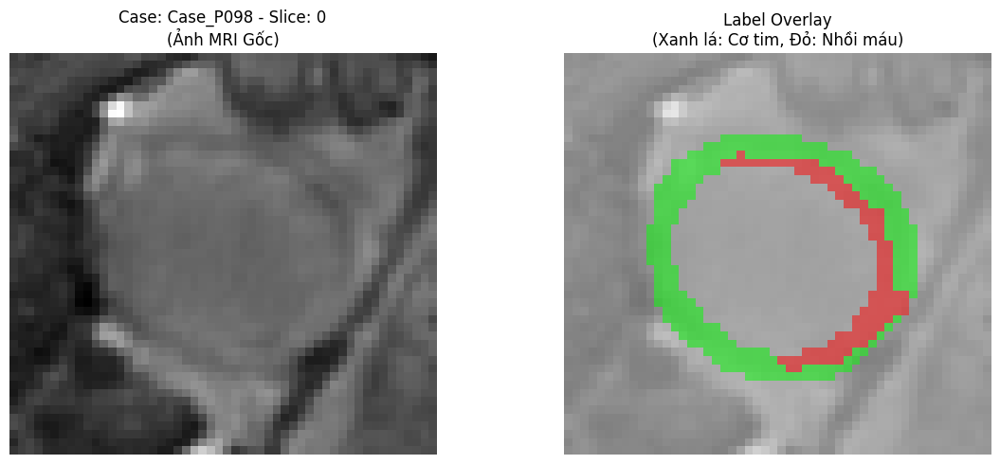

In [8]:
import os
import glob
import numpy as np
import nibabel as nib
import re
import shutil
import matplotlib.pyplot as plt
from tqdm import tqdm
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, ScaleIntensityd,
    Spacingd, CropForegroundd, ResizeWithPadOrCropd
)

print("[*] BƯỚC 0: DỌN DẸP THƯ MỤC CẮT LỖI...")
OUTPUT_DIR = "/kaggle/working/EMIDEC_Cropped_Colors/"
if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("\n[*] BẮT ĐẦU CẮT ẢNH EMIDEC (GIỮ NGUYÊN NỀN, LỌC NHÃN MYO & MI)...")
print("=" * 60)

# 1. HÀM QUÉT DỮ LIỆU
def get_emidec_datalist(emidec_dir):
    data_list = []
    cases = glob.glob(os.path.join(emidec_dir, "Case_*"))
    for case_folder in cases:
        case_name = os.path.basename(case_folder)
        img_search = glob.glob(os.path.join(case_folder, f"Images/**/{case_name}*"), recursive=True)
        lbl_search = glob.glob(os.path.join(case_folder, f"Contours/**/{case_name}*"), recursive=True)
        img_paths = [p for p in img_search if os.path.isfile(p) and p.endswith('.nii')]
        lbl_paths = [p for p in lbl_search if os.path.isfile(p) and p.endswith('.nii')]
        if img_paths and lbl_paths:
            img_path, lbl_path = img_paths[0], lbl_paths[0]
            if os.path.getsize(img_path) > 0 and os.path.getsize(lbl_path) > 0:
                data_list.append({"image": img_path, "label": lbl_path})
    return data_list

EMIDEC_DIR = "/kaggle/input/datasets/ngdutrong/emicdec-2020-dataset/emidec-dataset-1.0.1/"
emidec_files = get_emidec_datalist(EMIDEC_DIR)

# 2. PIPELINE CẮT TỰ ĐỘNG BẰNG MONAI
crop_transforms = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image", "label"]),
    Spacingd(keys=["image", "label"], pixdim=(1.5, 1.5, 5.0), mode=("bilinear", "nearest")),
    ScaleIntensityd(keys=["image"]),
    CropForegroundd(keys=["image", "label"], source_key="label", margin=10),
    ResizeWithPadOrCropd(keys=["image", "label"], spatial_size=(128, 128, 16), mode="constant")
])

# 3. TIẾN HÀNH CẮT VÀ LƯU
success_count = 0

for item in tqdm(emidec_files, desc="Đang xử lý dữ liệu"):
    match = re.search(r'(Case_[A-Za-z0-9]+)', item["image"])
    if not match: continue
    case_name = match.group(1)
    
    data = crop_transforms(item)
    
    cropped_img = data["image"][0].numpy()
    cropped_lbl = data["label"][0].numpy()
    
    target_mask = ((cropped_lbl == 2) | (cropped_lbl == 3) | (cropped_lbl == 4)).astype(np.float32)
    filtered_lbl = cropped_lbl * target_mask 
    
    affine = data["image"].meta.get("affine", np.eye(4))
    
    case_out_dir = os.path.join(OUTPUT_DIR, case_name)
    os.makedirs(case_out_dir, exist_ok=True)
    
    nib.save(nib.Nifti1Image(cropped_img, affine), os.path.join(case_out_dir, "image.nii.gz"))
    nib.save(nib.Nifti1Image(filtered_lbl, affine), os.path.join(case_out_dir, "label.nii.gz"))
    success_count += 1

print("=" * 60)
print(f"[*] THÀNH CÔNG! {success_count} ca đã được cắt (Giữ nguyên nền, lọc nhãn Myo & MI).")

# =================================================================
# 4. HIỂN THỊ 2 ẢNH CẠNH NHAU (TRẮNG ĐEN GỐC vs CÓ MÀU)
# =================================================================
print("\n[*] Đang hiển thị kết quả màu sắc của ca cuối cùng...")

mi_slices = np.any(filtered_lbl == 3, axis=(0, 1))
if np.any(mi_slices):
    best_slice = np.where(mi_slices)[0][0]
else:
    heart_slices = np.any((filtered_lbl == 2) | (filtered_lbl == 3) | (filtered_lbl == 4), axis=(0, 1))
    if np.any(heart_slices):
        best_slice = np.where(heart_slices)[0][heart_slices.sum() // 2]
    else:
        best_slice = filtered_lbl.shape[2] // 2

image_slice = cropped_img[:, :, best_slice]
label_slice = filtered_lbl[:, :, best_slice]

# Zoom sát vào tim cho dễ nhìn
rows, cols = np.where((label_slice == 2) | (label_slice == 3) | (label_slice == 4))
if len(rows) > 0:
    rmin, rmax = rows.min(), rows.max()
    cmin, cmax = cols.min(), cols.max()
    margin = 10
    rmin = max(0, rmin - margin)
    rmax = min(image_slice.shape[0], rmax + margin)
    cmin = max(0, cmin - margin)
    cmax = min(image_slice.shape[1], cmax + margin)
    image_slice = image_slice[rmin:rmax, cmin:cmax]
    label_slice = label_slice[rmin:rmax, cmin:cmax]

# --- Xử lý màu sắc ---
image_slice_rgb = plt.cm.gray(image_slice)[:, :, :3]

color_label = np.zeros((*label_slice.shape, 3), dtype=np.uint8)
color_label[label_slice == 2] = [0, 255, 0]   # Xanh lá: Myo
color_label[label_slice == 3] = [255, 0, 0]   # Đỏ: MI
color_label[label_slice == 4] = [255, 255, 0] # Vàng: MVO

alpha_mask = ((label_slice == 2) | (label_slice == 3) | (label_slice == 4)).astype(float)
alpha_mask = np.expand_dims(alpha_mask, axis=-1)

final_alpha = 0.5 
blended_image = (1 - final_alpha * alpha_mask) * image_slice_rgb + (final_alpha * alpha_mask) * (color_label / 255.0)

# --- VẼ 2 ẢNH CẠNH NHAU ---
plt.figure(figsize=(12, 5)) # Kích thước khung ngang

# Hình 1: Ảnh gốc trắng đen
plt.subplot(1, 2, 1)
plt.imshow(image_slice, cmap='gray')
plt.title(f'Case: {case_name} - Slice: {best_slice}\n(Ảnh MRI Gốc)')
plt.axis('off')

# Hình 2: Ảnh Overlay có màu
plt.subplot(1, 2, 2)
plt.imshow(blended_image)
plt.title('Label Overlay\n(Xanh lá: Cơ tim, Đỏ: Nhồi máu)')
plt.axis('off')

plt.tight_layout()
plt.show()

In [2]:
!pip install medpy monai

# gt SEGRESNET

In [2]:
# =========================================================
# EMIDEC 2020
# MULTI-CLASS ANATOMY-GUIDED SEGRESNET
# GT CROP + GT PRIOR
# OUTPUT:
# 0 background
# 1 cavity
# 2 myocardium
# 3 MI = infarction + no-reflow
# =========================================================

import os
import glob
import time
import random
import csv
import warnings
import numpy as np
import nibabel as nib
import torch

warnings.filterwarnings("ignore")

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

from monai.utils import set_determinism
from monai.data import Dataset, DataLoader
from monai.networks.nets import SegResNet
from monai.losses import DiceFocalLoss
from monai.metrics import DiceMetric, MeanIoU, HausdorffDistanceMetric
from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Spacingd,
    ScaleIntensityRangePercentilesd,
    NormalizeIntensityd,
    Lambdad,
    ResizeWithPadOrCropd,
    CropForegroundd,
    ConcatItemsd,
    RandFlipd,
    RandAffined,
    ToTensord,
    AsDiscrete,
)

from torch.optim.lr_scheduler import CosineAnnealingLR


# =========================================================
# CONFIG
# =========================================================

SEED = 43
set_determinism(seed=SEED)
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

EMIDEC_RAW_DIR = "/kaggle/input/datasets/ngdutrong/emicdec-2020-dataset/emidec-dataset-1.0.1/"
GT_CROPPED_DIR = "/kaggle/working/EMIDEC_GT_Cropped_SegResNet_MultiClass/"

os.makedirs(GT_CROPPED_DIR, exist_ok=True)

NUM_CLASSES = 4


# =========================================================
# LABEL FUNCTIONS
# =========================================================

def make_gt_heart_prior(x):
    """
    GT anatomical prior:
    1 = heart region = label > 0
    """
    return (x > 0).to(torch.float32)


def remap_emidec_multiclass(x):
    """
    EMIDEC original assumed:
    0 = background
    1 = cavity
    2 = myocardium
    3 = infarction
    4 = no-reflow

    New:
    0 = background
    1 = cavity
    2 = myocardium
    3 = MI = infarction + no-reflow
    """
    y = torch.zeros_like(x).long()
    y[x == 1] = 1
    y[x == 2] = 2
    y[x >= 3] = 3
    return y


def safe_metric(metric, idx=0):
    try:
        val = metric.aggregate()

        if hasattr(val, "shape") and len(val.shape) > 0:
            val = val[idx]

        val = val.item()

        if np.isnan(val) or np.isinf(val):
            return 0.0

        return val

    except Exception:
        return 0.0


# =========================================================
# RAW DATA LIST
# =========================================================

def get_raw_emidec_datalist(emidec_dir):
    data_list = []

    cases = glob.glob(os.path.join(emidec_dir, "Case_*"))

    for case_folder in cases:
        case_name = os.path.basename(case_folder)

        img_paths = [
            p for p in glob.glob(
                os.path.join(case_folder, f"Images/**/{case_name}.nii*"),
                recursive=True,
            )
            if os.path.isfile(p)
        ]

        lbl_paths = [
            p for p in glob.glob(
                os.path.join(case_folder, f"Contours/**/{case_name}.nii*"),
                recursive=True,
            )
            if os.path.isfile(p)
        ]

        if img_paths and lbl_paths:
            if os.path.getsize(img_paths[0]) > 0 and os.path.getsize(lbl_paths[0]) > 0:
                data_list.append(
                    {
                        "image": img_paths[0],
                        "label": lbl_paths[0],
                        "case_name": case_name,
                    }
                )

    return sorted(data_list, key=lambda x: x["case_name"])


all_raw_files = get_raw_emidec_datalist(EMIDEC_RAW_DIR)

if len(all_raw_files) == 0:
    raise ValueError("Không tìm thấy dữ liệu EMIDEC.")

print(f"Total raw cases: {len(all_raw_files)}")


# =========================================================
# GT CROP ALL CASES
# =========================================================

print("=" * 80)
print("GT CROP ALL CASES")
print("=" * 80)

SPATIAL_SIZE_RAW = (128, 128, 24)
SPATIAL_SIZE_CROP = (112, 112, 32)

prep_transforms = Compose(
    [
        LoadImaged(keys=["image", "label"]),
        EnsureChannelFirstd(keys=["image", "label"]),

        Spacingd(
            keys=["image", "label"],
            pixdim=(1.5, 1.5, 5.0),
            mode=("bilinear", "nearest"),
        ),

        ScaleIntensityRangePercentilesd(
            keys=["image"],
            lower=1,
            upper=99,
            b_min=0.0,
            b_max=1.0,
            clip=True,
        ),

        NormalizeIntensityd(
            keys=["image"],
            nonzero=True,
            channel_wise=True,
        ),

        ResizeWithPadOrCropd(
            keys=["image", "label"],
            spatial_size=SPATIAL_SIZE_RAW,
            mode="constant",
        ),
    ]
)

crop_by_gt = Compose(
    [
        CropForegroundd(
            keys=["image", "label", "mask_prior"],
            source_key="mask_prior",
            margin=25,
        ),

        ResizeWithPadOrCropd(
            keys=["image", "label", "mask_prior"],
            spatial_size=SPATIAL_SIZE_CROP,
            mode="constant",
        ),
    ]
)


def crop_and_save_all_cases(raw_files):
    cropped_files = []

    for item in tqdm(raw_files, desc="Cropping by GT mask"):
        data = prep_transforms(
            {
                "image": item["image"],
                "label": item["label"],
            }
        )

        gt_prior = make_gt_heart_prior(data["label"])
        data["mask_prior"] = gt_prior

        if torch.sum(gt_prior) == 0:
            continue

        cropped = crop_by_gt(data)

        case_out_dir = os.path.join(GT_CROPPED_DIR, item["case_name"])
        os.makedirs(case_out_dir, exist_ok=True)

        affine = data["image"].meta.get("affine", np.eye(4))

        image_path = os.path.join(case_out_dir, "image.nii.gz")
        label_path = os.path.join(case_out_dir, "label.nii.gz")
        prior_path = os.path.join(case_out_dir, "mask_prior.nii.gz")

        nib.save(
            nib.Nifti1Image(cropped["image"][0].numpy(), affine),
            image_path,
        )

        nib.save(
            nib.Nifti1Image(cropped["label"][0].numpy(), affine),
            label_path,
        )

        nib.save(
            nib.Nifti1Image(cropped["mask_prior"][0].numpy(), affine),
            prior_path,
        )

        cropped_files.append(
            {
                "image": image_path,
                "label": label_path,
                "mask_prior": prior_path,
                "case_name": item["case_name"],
            }
        )

    return sorted(cropped_files, key=lambda x: x["case_name"])


all_cropped_files = crop_and_save_all_cases(all_raw_files)

print(f"Cropped cases: {len(all_cropped_files)}")


# =========================================================
# HARD SPLIT AFTER CROP
# =========================================================

print("=" * 80)
print("HARD SPLIT AFTER CROP")
print("=" * 80)

train_val_files, test_files = train_test_split(
    all_cropped_files,
    test_size=0.15,
    random_state=42,
    shuffle=True,
)

train_files, val_files = train_test_split(
    train_val_files,
    test_size=(15 / 85),
    random_state=42,
    shuffle=True,
)

print(f"Train: {len(train_files)}")
print(f"Val  : {len(val_files)}")
print(f"Test : {len(test_files)}")


# =========================================================
# TRANSFORMS
# =========================================================

train_transforms = Compose(
    [
        LoadImaged(keys=["image", "label", "mask_prior"]),
        EnsureChannelFirstd(keys=["image", "label", "mask_prior"]),

        ScaleIntensityRangePercentilesd(
            keys=["image"],
            lower=1,
            upper=99,
            b_min=0.0,
            b_max=1.0,
            clip=True,
        ),

        NormalizeIntensityd(
            keys=["image"],
            nonzero=True,
            channel_wise=True,
        ),

        Lambdad(
            keys=["label"],
            func=remap_emidec_multiclass,
        ),

        ConcatItemsd(
            keys=["image", "mask_prior"],
            name="segresnet_input",
            dim=0,
        ),

        RandAffined(
            keys=["segresnet_input", "label"],
            prob=0.4,
            rotate_range=(0.15, 0.15, 0.15),
            scale_range=(0.08, 0.08, 0.08),
            mode=("bilinear", "nearest"),
        ),

        RandFlipd(
            keys=["segresnet_input", "label"],
            spatial_axis=[0, 1],
            prob=0.5,
        ),

        ToTensord(keys=["segresnet_input", "label"]),
    ]
)

val_transforms = Compose(
    [
        LoadImaged(keys=["image", "label", "mask_prior"]),
        EnsureChannelFirstd(keys=["image", "label", "mask_prior"]),

        ScaleIntensityRangePercentilesd(
            keys=["image"],
            lower=1,
            upper=99,
            b_min=0.0,
            b_max=1.0,
            clip=True,
        ),

        NormalizeIntensityd(
            keys=["image"],
            nonzero=True,
            channel_wise=True,
        ),

        Lambdad(
            keys=["label"],
            func=remap_emidec_multiclass,
        ),

        ConcatItemsd(
            keys=["image", "mask_prior"],
            name="segresnet_input",
            dim=0,
        ),

        ToTensord(keys=["segresnet_input", "label"]),
    ]
)


# =========================================================
# DATALOADERS
# =========================================================

train_loader = DataLoader(
    Dataset(train_files, transform=train_transforms),
    batch_size=2,
    shuffle=True,
)

val_loader = DataLoader(
    Dataset(val_files, transform=val_transforms),
    batch_size=1,
    shuffle=False,
)

test_loader = DataLoader(
    Dataset(test_files, transform=val_transforms),
    batch_size=1,
    shuffle=False,
)


# =========================================================
# MODEL: SEGRESNET MULTI-CLASS
# =========================================================

model = SegResNet(
    spatial_dims=3,
    in_channels=2,
    out_channels=NUM_CLASSES,
    init_filters=16,
    blocks_down=(1, 2, 2, 4),
    blocks_up=(1, 1, 1),
    dropout_prob=0.2,
).to(device)


class_weights = torch.tensor(
    [0.05, 0.15, 0.25, 0.55],
    dtype=torch.float32,
).to(device)

loss_fn = DiceFocalLoss(
    to_onehot_y=True,
    softmax=True,
    gamma=2.0,
    weight=class_weights,
    squared_pred=True,
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=8e-4,
    weight_decay=1e-4,
)

MAX_EPOCHS = 100

scheduler = CosineAnnealingLR(
    optimizer,
    T_max=MAX_EPOCHS,
    eta_min=1e-6,
)

post_pred = AsDiscrete(argmax=True, to_onehot=NUM_CLASSES)
post_label = AsDiscrete(to_onehot=NUM_CLASSES)

best_val_mi_dice = -1.0

csv_path = "segresnet_emidec_multiclass_gt_prior_log.csv"

with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(
        [
            "Epoch",
            "Time_s",
            "Train_Loss",
            "Val_Loss",
            "Train_Dice_Cavity",
            "Val_Dice_Cavity",
            "Train_Dice_Myo",
            "Val_Dice_Myo",
            "Train_Dice_MI",
            "Val_Dice_MI",
            "Val_IoU_MI",
            "Val_HD95_MI",
        ]
    )


# =========================================================
# TRAINING LOOP
# =========================================================

for epoch in range(MAX_EPOCHS):
    start_time = time.time()

    model.train()

    train_loss = 0.0
    step = 0

    train_dice_metric = DiceMetric(
        include_background=False,
        reduction="mean_batch",
    )

    for batch in tqdm(train_loader, desc=f"SegResNet EP {epoch + 1:03d}/{MAX_EPOCHS} [Train]"):
        step += 1

        inputs = batch["segresnet_input"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        preds = [post_pred(i) for i in outputs.detach()]
        gts = [post_label(i) for i in labels]

        train_dice_metric(y_pred=preds, y=gts)

    train_loss /= max(step, 1)

    # include_background=False:
    # idx 0 = cavity
    # idx 1 = myocardium
    # idx 2 = MI
    train_dice_cavity = safe_metric(train_dice_metric, 0)
    train_dice_myo = safe_metric(train_dice_metric, 1)
    train_dice_mi = safe_metric(train_dice_metric, 2)

    scheduler.step()

    model.eval()

    val_loss = 0.0
    val_step = 0

    val_dice_metric = DiceMetric(
        include_background=False,
        reduction="mean_batch",
    )

    val_iou_metric = MeanIoU(
        include_background=False,
        reduction="mean_batch",
    )

    val_hd95_metric = HausdorffDistanceMetric(
        include_background=False,
        percentile=95,
        reduction="mean_batch",
    )

    with torch.no_grad():
        for batch in val_loader:
            val_step += 1

            inputs = batch["segresnet_input"].to(device)
            labels = batch["label"].to(device)

            outputs = model(inputs)

            val_loss += loss_fn(outputs, labels).item()

            preds = [post_pred(i) for i in outputs]
            gts = [post_label(i) for i in labels]

            val_dice_metric(y_pred=preds, y=gts)
            val_iou_metric(y_pred=preds, y=gts)
            val_hd95_metric(y_pred=preds, y=gts)

    val_loss /= max(val_step, 1)

    val_dice_cavity = safe_metric(val_dice_metric, 0)
    val_dice_myo = safe_metric(val_dice_metric, 1)
    val_dice_mi = safe_metric(val_dice_metric, 2)

    val_iou_mi = safe_metric(val_iou_metric, 2)
    val_hd95_mi = safe_metric(val_hd95_metric, 2)

    epoch_time = time.time() - start_time

    with open(csv_path, "a", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(
            [
                epoch + 1,
                f"{epoch_time:.1f}",
                train_loss,
                val_loss,
                train_dice_cavity,
                val_dice_cavity,
                train_dice_myo,
                val_dice_myo,
                train_dice_mi,
                val_dice_mi,
                val_iou_mi,
                val_hd95_mi,
            ]
        )

    print(
        f"EP {epoch + 1:03d} | "
        f"T.Loss {train_loss:.4f} | V.Loss {val_loss:.4f} | "
        f"T.Cav {train_dice_cavity * 100:.2f}% | V.Cav {val_dice_cavity * 100:.2f}% | "
        f"T.Myo {train_dice_myo * 100:.2f}% | V.Myo {val_dice_myo * 100:.2f}% | "
        f"T.MI {train_dice_mi * 100:.2f}% | V.MI {val_dice_mi * 100:.2f}% | "
        f"MI IoU {val_iou_mi * 100:.2f}% | HD95 {val_hd95_mi:.4f}"
    )

    if val_dice_mi > best_val_mi_dice:
        best_val_mi_dice = val_dice_mi
        torch.save(model.state_dict(), "best_segresnet_emidec_multiclass_gt_prior.pth")

print(f"[DONE] Best Val MI Dice: {best_val_mi_dice * 100:.2f}%")


# =========================================================
# FINAL TEST
# =========================================================

print("=" * 80)
print("FINAL TEST - SEGRESNET MULTI-CLASS")
print("=" * 80)

model.load_state_dict(
    torch.load(
        "best_segresnet_emidec_multiclass_gt_prior.pth",
        map_location=device,
    )
)

model.eval()

test_dice_metric = DiceMetric(
    include_background=False,
    reduction="mean_batch",
)

test_iou_metric = MeanIoU(
    include_background=False,
    reduction="mean_batch",
)

test_hd95_metric = HausdorffDistanceMetric(
    include_background=False,
    percentile=95,
    reduction="mean_batch",
)

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Testing SegResNet"):
        inputs = batch["segresnet_input"].to(device)
        labels = batch["label"].to(device)

        outputs = model(inputs)

        preds = [post_pred(i) for i in outputs]
        gts = [post_label(i) for i in labels]

        test_dice_metric(y_pred=preds, y=gts)
        test_iou_metric(y_pred=preds, y=gts)
        test_hd95_metric(y_pred=preds, y=gts)

test_dice_cavity = safe_metric(test_dice_metric, 0)
test_dice_myo = safe_metric(test_dice_metric, 1)
test_dice_mi = safe_metric(test_dice_metric, 2)

test_iou_mi = safe_metric(test_iou_metric, 2)
test_hd95_mi = safe_metric(test_hd95_metric, 2)

print(f"FINAL TEST CAVITY DICE: {test_dice_cavity * 100:.2f}%")
print(f"FINAL TEST MYO DICE   : {test_dice_myo * 100:.2f}%")
print(f"FINAL TEST MI DICE    : {test_dice_mi * 100:.2f}%")
print(f"FINAL TEST MI IOU     : {test_iou_mi * 100:.2f}%")
print(f"FINAL TEST MI HD95    : {test_hd95_mi:.4f}")

2026-05-27 17:29:07.577918: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1779902947.743989      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1779902947.792439      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1779902948.182933      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779902948.182976      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779902948.182979      57 computation_placer.cc:177] computation placer alr

Total raw cases: 100
GT CROP ALL CASES


Cropping by GT mask:   0%|          | 0/100 [00:00<?, ?it/s]

Cropped cases: 100
HARD SPLIT AFTER CROP
Train: 69
Val  : 16
Test : 15


SegResNet EP 001/100 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

EP 001 | T.Loss 0.2428 | V.Loss 0.2233 | T.Cav 21.83% | V.Cav 50.88% | T.Myo 25.37% | V.Myo 54.59% | T.MI 4.01% | V.MI 1.03% | MI IoU 0.53% | HD95 17.3807


... (196 outputs left out)

SegResNet EP 100/100 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

EP 100 | T.Loss 0.0657 | V.Loss 0.0919 | T.Cav 94.32% | V.Cav 92.94% | T.Myo 90.41% | V.Myo 90.97% | T.MI 76.29% | V.MI 72.15% | MI IoU 57.17% | HD95 2.5461
[DONE] Best Val MI Dice: 72.35%
FINAL TEST - SEGRESNET MULTI-CLASS


Testing SegResNet:   0%|          | 0/15 [00:00<?, ?it/s]

FINAL TEST CAVITY DICE: 92.23%
FINAL TEST MYO DICE   : 87.20%
FINAL TEST MI DICE    : 65.07%
FINAL TEST MI IOU     : 49.47%
FINAL TEST MI HD95    : 5.1685


   Epoch  Time_s  Train_Loss  Val_Loss  Train_Dice_Cavity  Val_Dice_Cavity  \
0      1    22.3    0.232682  0.221411           0.169684         0.307015   
1      2    19.0    0.211302  0.201364           0.381492         0.572458   
2      3    18.9    0.187085  0.179125           0.626503         0.702086   
3      4    19.5    0.170007  0.160561           0.707403         0.738725   
4      5    19.6    0.155895  0.156672           0.763576         0.773274   

   Train_Dice_Myo  Val_Dice_Myo  Train_Dice_MI  Val_Dice_MI  Val_IoU_MI  \
0        0.005572      0.423558       0.000094     0.000000    0.000000   
1        0.292718      0.415439       0.000000     0.000000    0.000000   
2        0.443506      0.540564       0.004563     0.000000    0.000000   
3        0.499307      0.633469       0.036101     0.031647    0.016839   
4        0.569515      0.621277       0.052459     0.060367    0.031868   

   Val_HD95_MI  
0     0.000000  
1     0.000000  
2     0.000000  
3    15.6656

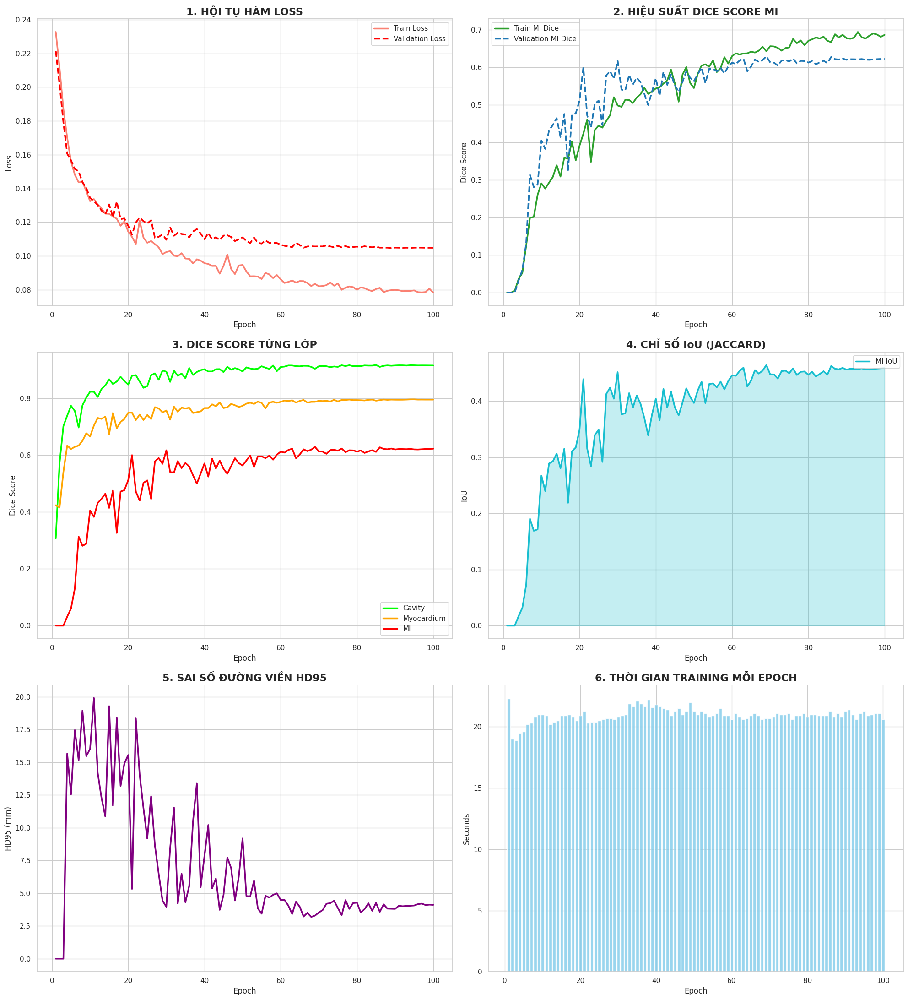


             BÁO CÁO KẾT QUẢ SEGRESNET EMIDEC MULTI-CLASS             
🏆 BEST EPOCH: 69
  > Train Loss                          :       0.0834
  > Validation Loss                     :       0.1056
  > Validation MI Dice                  :       0.6286
  > Validation Myocardium Dice          :       0.7872
  > Validation Cavity Dice              :       0.9036
  > Validation MI IoU                   :       0.4648
  > Validation MI HD95                  :      3.29 mm
  > Training Time                       :     20.7 sec


In [50]:
# =========================================================
# FULL DASHBOARD REPORT
# SEGRESNET EMIDEC MULTI-CLASS MRI ONLY
# STYLE GIỐNG CODE ACDC CỦA BẠN
# =========================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# =========================================================
# PATH
# =========================================================

CSV_PATH = Path("/kaggle/working/segresnet_emidec_multiclass_mri_only_log.csv")
SAVE_DIR = Path("/kaggle/working/emidec_dashboard")

SAVE_DIR.mkdir(exist_ok=True)


# =========================================================
# DASHBOARD
# =========================================================

def plot_dashboard_emidec(log_path):

    if not log_path.exists():
        print(f"❌ Không tìm thấy file: {log_path}")
        return

    df = pd.read_csv(log_path)

    print(df.head())
    print(df.columns)

    sns.set_theme(style="whitegrid")

    fig, axes = plt.subplots(
        3,
        2,
        figsize=(20, 22)
    )

    plt.subplots_adjust(
        hspace=0.35,
        wspace=0.20
    )

    # =====================================================
    # 1. LOSS
    # =====================================================

    sns.lineplot(
        ax=axes[0, 0],
        data=df,
        x='Epoch',
        y='Train_Loss',
        label='Train Loss',
        color='salmon',
        linewidth=2.5
    )

    sns.lineplot(
        ax=axes[0, 0],
        data=df,
        x='Epoch',
        y='Val_Loss',
        label='Validation Loss',
        color='red',
        linewidth=2.5,
        linestyle='--'
    )

    axes[0, 0].set_title(
        '1. HỘI TỤ HÀM LOSS',
        fontsize=16,
        fontweight='bold'
    )

    axes[0, 0].set_xlabel("Epoch")
    axes[0, 0].set_ylabel("Loss")


    # =====================================================
    # 2. MI DICE
    # =====================================================

    sns.lineplot(
        ax=axes[0, 1],
        data=df,
        x='Epoch',
        y='Train_Dice_MI',
        label='Train MI Dice',
        color='#2ca02c',
        linewidth=2.5
    )

    sns.lineplot(
        ax=axes[0, 1],
        data=df,
        x='Epoch',
        y='Val_Dice_MI',
        label='Validation MI Dice',
        color='#1f77b4',
        linewidth=2.5,
        linestyle='--'
    )

    axes[0, 1].set_title(
        '2. HIỆU SUẤT DICE SCORE MI',
        fontsize=16,
        fontweight='bold'
    )

    axes[0, 1].set_xlabel("Epoch")
    axes[0, 1].set_ylabel("Dice Score")


    # =====================================================
    # 3. MULTI-CLASS DICE
    # =====================================================

    sns.lineplot(
        ax=axes[1, 0],
        data=df,
        x='Epoch',
        y='Val_Dice_Cavity',
        label='Cavity',
        color='lime',
        linewidth=2.5
    )

    sns.lineplot(
        ax=axes[1, 0],
        data=df,
        x='Epoch',
        y='Val_Dice_Myo',
        label='Myocardium',
        color='orange',
        linewidth=2.5
    )

    sns.lineplot(
        ax=axes[1, 0],
        data=df,
        x='Epoch',
        y='Val_Dice_MI',
        label='MI',
        color='red',
        linewidth=2.5
    )

    axes[1, 0].set_title(
        '3. DICE SCORE TỪNG LỚP',
        fontsize=16,
        fontweight='bold'
    )

    axes[1, 0].set_xlabel("Epoch")
    axes[1, 0].set_ylabel("Dice Score")


    # =====================================================
    # 4. IOU
    # =====================================================

    axes[1, 1].fill_between(
        df['Epoch'],
        df['Val_IoU_MI'],
        color='#17becf',
        alpha=0.25
    )

    axes[1, 1].plot(
        df['Epoch'],
        df['Val_IoU_MI'],
        color='#17becf',
        linewidth=2.5,
        label='MI IoU'
    )

    axes[1, 1].set_title(
        '4. CHỈ SỐ IoU (JACCARD)',
        fontsize=16,
        fontweight='bold'
    )

    axes[1, 1].set_xlabel("Epoch")
    axes[1, 1].set_ylabel("IoU")

    axes[1, 1].legend()


    # =====================================================
    # 5. HD95
    # =====================================================

    sns.lineplot(
        ax=axes[2, 0],
        data=df,
        x='Epoch',
        y='Val_HD95_MI',
        color='purple',
        linewidth=2.5
    )

    axes[2, 0].set_title(
        '5. SAI SỐ ĐƯỜNG VIỀN HD95',
        fontsize=16,
        fontweight='bold'
    )

    axes[2, 0].set_xlabel("Epoch")
    axes[2, 0].set_ylabel("HD95 (mm)")


    # =====================================================
    # 6. THỜI GIAN TRAINING
    # =====================================================

    if "Time_s" in df.columns:

        axes[2, 1].bar(
            df['Epoch'],
            df['Time_s'],
            color='skyblue',
            alpha=0.85
        )

        axes[2, 1].set_title(
            '6. THỜI GIAN TRAINING MỖI EPOCH',
            fontsize=16,
            fontweight='bold'
        )

        axes[2, 1].set_xlabel("Epoch")
        axes[2, 1].set_ylabel("Seconds")

    else:

        axes[2, 1].axis("off")


    # =====================================================
    # SAVE
    # =====================================================

    plt.tight_layout()

    save_path = SAVE_DIR / "segresnet_emidec_dashboard.png"

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches='tight'
    )

    print(f"\n✅ Đã lưu dashboard tại:")
    print(save_path)

    plt.show()


# =========================================================
# FINAL REPORT
# =========================================================

def print_report_emidec(log_path):

    if not log_path.exists():
        return

    df = pd.read_csv(log_path)

    best_row = df.iloc[
        df['Val_Dice_MI'].idxmax()
    ]

    print("\n" + "=" * 70)

    print(
        f"{'BÁO CÁO KẾT QUẢ SEGRESNET EMIDEC MULTI-CLASS':^70}"
    )

    print("=" * 70)

    print(f"🏆 BEST EPOCH: {int(best_row['Epoch'])}")

    metrics = [
        ["Train Loss", f"{best_row['Train_Loss']:.4f}"],
        ["Validation Loss", f"{best_row['Val_Loss']:.4f}"],
        ["Validation MI Dice", f"{best_row['Val_Dice_MI']:.4f}"],
        ["Validation Myocardium Dice", f"{best_row['Val_Dice_Myo']:.4f}"],
        ["Validation Cavity Dice", f"{best_row['Val_Dice_Cavity']:.4f}"],
        ["Validation MI IoU", f"{best_row['Val_IoU_MI']:.4f}"],
        ["Validation MI HD95", f"{best_row['Val_HD95_MI']:.2f} mm"],
    ]

    if "Time_s" in df.columns:
        metrics.append(
            ["Training Time", f"{best_row['Time_s']:.1f} sec"]
        )

    for label, value in metrics:

        print(
            f"  > {label:<35} : {value:>12}"
        )

    print("=" * 70)


# =========================================================
# RUN
# =========================================================

plot_dashboard_emidec(CSV_PATH)

print_report_emidec(CSV_PATH)

In [59]:
# =========================================================
# FINAL TEST EVALUATION
# SEGRESNET EMIDEC MULTI-CLASS + GT PRIOR
# =========================================================

import torch
import pandas as pd
from tqdm.auto import tqdm
from monai.metrics import DiceMetric, MeanIoU, HausdorffDistanceMetric
from monai.data import Dataset, DataLoader
from monai.networks.nets import SegResNet
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd,
    ScaleIntensityRangePercentilesd, NormalizeIntensityd,
    Lambdad, ConcatItemsd, ToTensord, AsDiscrete
)

print("=" * 80)
print("FINAL TEST - SEGRESNET EMIDEC MULTI-CLASS + GT PRIOR")
print("=" * 80)

gt_prior_val_transforms = Compose([
    LoadImaged(keys=["image", "label", "mask_prior"]),
    EnsureChannelFirstd(keys=["image", "label", "mask_prior"]),
    ScaleIntensityRangePercentilesd(
        keys=["image"], lower=1, upper=99,
        b_min=0.0, b_max=1.0, clip=True
    ),
    NormalizeIntensityd(keys=["image"], nonzero=True, channel_wise=True),
    Lambdad(keys=["label"], func=remap_emidec_multiclass),
    ConcatItemsd(keys=["image", "mask_prior"], name="segresnet_input", dim=0),
    ToTensord(keys=["segresnet_input", "label"]),
])

test_loader = DataLoader(
    Dataset(test_files, transform=gt_prior_val_transforms),
    batch_size=1,
    shuffle=False
)

model = SegResNet(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,
    init_filters=16,
    blocks_down=(1, 2, 2, 4),
    blocks_up=(1, 1, 1),
    dropout_prob=0.2,
).to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_segresnet_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)
model.eval()

post_pred = AsDiscrete(argmax=True, to_onehot=4)
post_label = AsDiscrete(to_onehot=4)

test_dice_metric = DiceMetric(include_background=False, reduction="mean_batch")
test_iou_metric = MeanIoU(include_background=False, reduction="mean_batch")
test_hd95_metric = HausdorffDistanceMetric(
    include_background=False,
    percentile=95,
    reduction="mean_batch"
)

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Testing SegResNet + GT Prior"):
        inputs = batch["segresnet_input"].to(device)
        labels = batch["label"].to(device)

        outputs = model(inputs)
        if isinstance(outputs, (list, tuple)):
            outputs = outputs[0]

        preds = [post_pred(i) for i in outputs]
        gts = [post_label(i) for i in labels]

        test_dice_metric(y_pred=preds, y=gts)
        test_iou_metric(y_pred=preds, y=gts)
        test_hd95_metric(y_pred=preds, y=gts)

test_dice_cavity = safe_metric(test_dice_metric, 0)
test_dice_myo = safe_metric(test_dice_metric, 1)
test_dice_mi = safe_metric(test_dice_metric, 2)

test_iou_cavity = safe_metric(test_iou_metric, 0)
test_iou_myo = safe_metric(test_iou_metric, 1)
test_iou_mi = safe_metric(test_iou_metric, 2)

test_hd95_cavity = safe_metric(test_hd95_metric, 0)
test_hd95_myo = safe_metric(test_hd95_metric, 1)
test_hd95_mi = safe_metric(test_hd95_metric, 2)

print("\n" + "★" * 70)
print(f"{'KẾT QUẢ CHÍNH THỨC TRÊN TẬP TEST':^70}")
print("★" * 70)
print(f"\n🫀 CAVITY:\n   Dice : {test_dice_cavity*100:.2f}%\n   IoU  : {test_iou_cavity*100:.2f}%\n   HD95 : {test_hd95_cavity:.4f}")
print(f"\n🫀 MYOCARDIUM:\n   Dice : {test_dice_myo*100:.2f}%\n   IoU  : {test_iou_myo*100:.2f}%\n   HD95 : {test_hd95_myo:.4f}")
print(f"\n🩸 MI:\n   Dice : {test_dice_mi*100:.2f}%\n   IoU  : {test_iou_mi*100:.2f}%\n   HD95 : {test_hd95_mi:.4f}")
print("★" * 70)

test_summary = pd.DataFrame([{
    "Model": "SegResNet_GT_Prior",
    "Test_Dice_Cavity": test_dice_cavity,
    "Test_IoU_Cavity": test_iou_cavity,
    "Test_HD95_Cavity": test_hd95_cavity,
    "Test_Dice_Myo": test_dice_myo,
    "Test_IoU_Myo": test_iou_myo,
    "Test_HD95_Myo": test_hd95_myo,
    "Test_Dice_MI": test_dice_mi,
    "Test_IoU_MI": test_iou_mi,
    "Test_HD95_MI": test_hd95_mi,
}])

save_test_csv = "/kaggle/working/segresnet_emidec_multiclass_gt_prior_test_results.csv"
test_summary.to_csv(save_test_csv, index=False)

print(f"\n✅ Đã lưu test results tại: {save_test_csv}")

FINAL TEST - SEGRESNET EMIDEC MULTI-CLASS + GT PRIOR


Testing SegResNet + GT Prior:   0%|          | 0/15 [00:00<?, ?it/s]


★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
                   KẾT QUẢ CHÍNH THỨC TRÊN TẬP TEST                   
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★

🫀 CAVITY:
   Dice : 91.76%
   IoU  : 84.86%
   HD95 : 2.0094

🫀 MYOCARDIUM:
   Dice : 86.36%
   IoU  : 76.53%
   HD95 : 2.4159

🩸 MI:
   Dice : 63.17%
   IoU  : 46.87%
   HD95 : 4.9785
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★

✅ Đã lưu test results tại: /kaggle/working/segresnet_emidec_multiclass_gt_prior_test_results.csv


Grad-CAM Whole Heart:   0%|          | 0/15 [00:00<?, ?it/s]

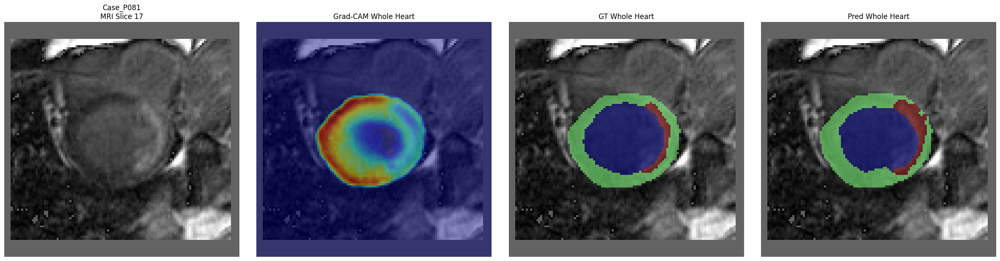

Saved: /kaggle/working/GradCAM_Whole_Heart/Case_P081_gradcam_whole_heart.png


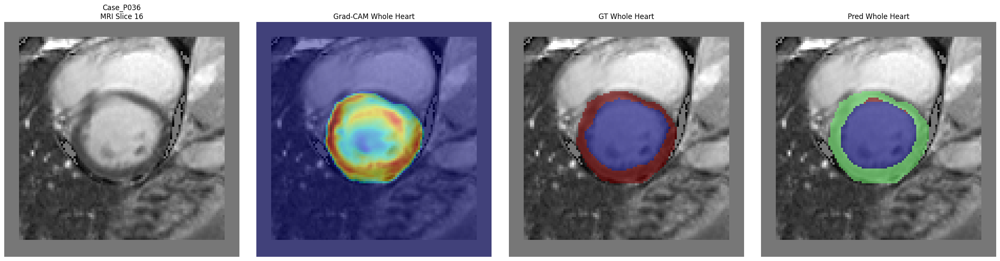

Saved: /kaggle/working/GradCAM_Whole_Heart/Case_P036_gradcam_whole_heart.png


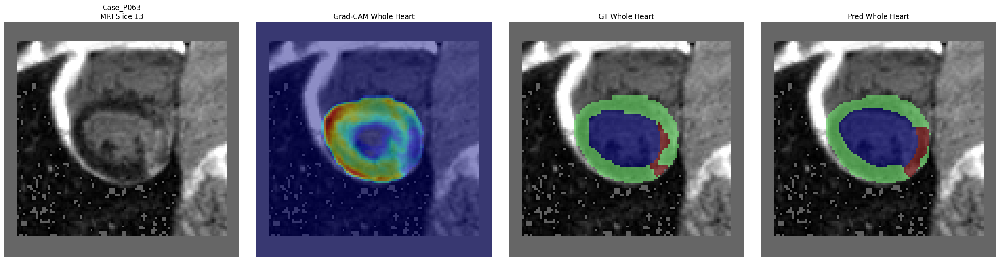

Saved: /kaggle/working/GradCAM_Whole_Heart/Case_P063_gradcam_whole_heart.png


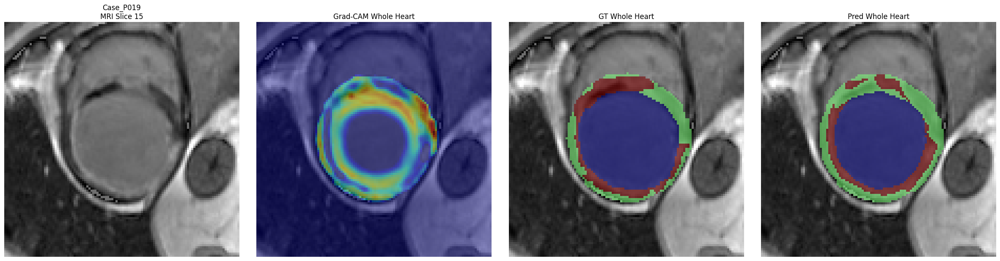

Saved: /kaggle/working/GradCAM_Whole_Heart/Case_P019_gradcam_whole_heart.png


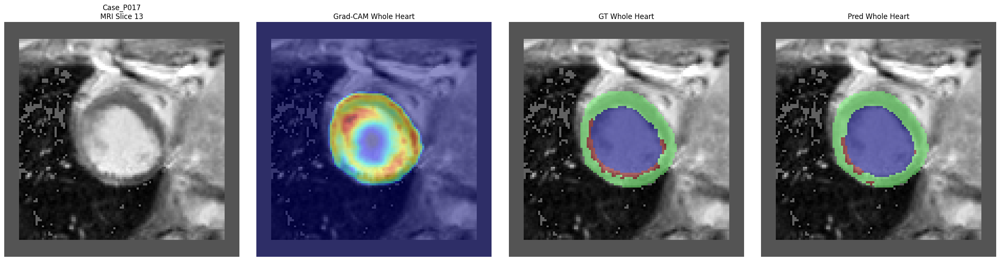

Saved: /kaggle/working/GradCAM_Whole_Heart/Case_P017_gradcam_whole_heart.png


In [4]:
# =========================================================
# 3D GRAD-CAM TOÀN BỘ TIM: CAVITY + MYOCARDIUM + MI
# For SegResNet EMIDEC
# =========================================================

import os
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SAVE_DIR = "/kaggle/working/GradCAM_Whole_Heart"
os.makedirs(SAVE_DIR, exist_ok=True)

# =========================================================
# FIND TARGET LAYER
# =========================================================
# Với SegResNet, chọn layer sâu ở decoder/encoder.
# Nếu lỗi, in model.named_modules() rồi đổi layer.

target_layer = model.up_layers[-1]

# =========================================================
# GRAD-CAM CLASS
# =========================================================

class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None

        self.f_hook = target_layer.register_forward_hook(self.save_activation)
        self.b_hook = target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, inp, out):
        self.activations = out.detach()

    def save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def remove_hooks(self):
        self.f_hook.remove()
        self.b_hook.remove()

    def __call__(self, x):
        self.model.zero_grad()

        output = self.model(x)
        probs = torch.softmax(output, dim=1)

        # Whole heart target = class 1 + 2 + 3
        score = probs[:, 1:4].mean()

        score.backward(retain_graph=True)

        gradients = self.gradients
        activations = self.activations

        weights = gradients.mean(dim=(2, 3, 4), keepdim=True)

        cam = (weights * activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)

        cam = F.interpolate(
            cam,
            size=x.shape[2:],
            mode="trilinear",
            align_corners=False,
        )

        cam = cam[0, 0].detach().cpu().numpy()
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        return cam, output.detach()

# =========================================================
# RUN GRAD-CAM WHOLE HEART
# =========================================================

model.eval()

for idx, batch in enumerate(tqdm(test_loader, desc="Grad-CAM Whole Heart")):
    inputs = batch["segresnet_input"].to(device)
    labels = batch["label"].to(device)

    image_np = inputs[0, 0].detach().cpu().numpy()

    if labels.ndim == 5:
        label_np = labels[0, 0].detach().cpu().numpy()
    else:
        label_np = labels[0].detach().cpu().numpy()

    gradcam = GradCAM3D(model, target_layer)
    cam, output = gradcam(inputs)
    gradcam.remove_hooks()

    pred = torch.argmax(torch.softmax(output, dim=1), dim=1)
    pred_np = pred[0].detach().cpu().numpy()

    case_name = batch["case_name"][0] if "case_name" in batch else f"case_{idx:03d}"

    # Chọn slice có vùng tim lớn nhất theo GT, nếu không có thì theo prediction
    gt_heart_per_slice = np.sum(label_np > 0, axis=(0, 1))
    pred_heart_per_slice = np.sum(pred_np > 0, axis=(0, 1))

    if gt_heart_per_slice.max() > 0:
        slice_idx = int(np.argmax(gt_heart_per_slice))
    elif pred_heart_per_slice.max() > 0:
        slice_idx = int(np.argmax(pred_heart_per_slice))
    else:
        slice_idx = image_np.shape[2] // 2

    heart_gt_overlay = np.ma.masked_where(
        label_np[:, :, slice_idx] == 0,
        label_np[:, :, slice_idx],
    )

    heart_pred_overlay = np.ma.masked_where(
        pred_np[:, :, slice_idx] == 0,
        pred_np[:, :, slice_idx],
    )

    plt.figure(figsize=(24, 6))

    plt.subplot(1, 4, 1)
    plt.imshow(image_np[:, :, slice_idx], cmap="gray")
    plt.title(f"{case_name}\nMRI Slice {slice_idx}")
    plt.axis("off")

    plt.subplot(1, 4, 2)
    plt.imshow(image_np[:, :, slice_idx], cmap="gray")
    plt.imshow(cam[:, :, slice_idx], cmap="jet", alpha=0.45)
    plt.title("Grad-CAM Whole Heart")
    plt.axis("off")

    plt.subplot(1, 4, 3)
    plt.imshow(image_np[:, :, slice_idx], cmap="gray")
    plt.imshow(heart_gt_overlay, cmap="jet", alpha=0.55)
    plt.title("GT Whole Heart")
    plt.axis("off")

    plt.subplot(1, 4, 4)
    plt.imshow(image_np[:, :, slice_idx], cmap="gray")
    plt.imshow(heart_pred_overlay, cmap="jet", alpha=0.55)
    plt.title("Pred Whole Heart")
    plt.axis("off")

    plt.tight_layout()

    save_path = os.path.join(SAVE_DIR, f"{case_name}_gradcam_whole_heart.png")
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", save_path)

    # Xem 5 case đầu thôi, muốn visualize toàn bộ thì xóa 3 dòng dưới
    if idx >= 4:
        break

VISUALIZE + CUSTOM GRAD-CAM | SEGRESNET + GT PRIOR
Selected case: Case_P081
Grad-CAM target layer: Conv3d(16, 4, kernel_size=(1, 1, 1), stride=(1, 1, 1))


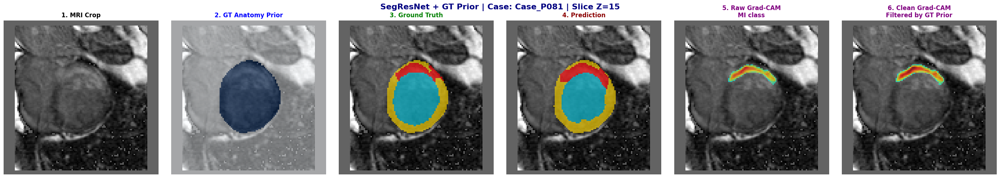

In [25]:
# =========================================================
# VISUALIZE + CUSTOM GRAD-CAM
# EMIDEC SEGRESNET MULTI-CLASS + GT PRIOR
# class:
# 0 background | 1 cavity | 2 myocardium | 3 MI
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import torch
import torch.nn.functional as F
import random
from scipy.ndimage import zoom

print("=" * 80)
print("VISUALIZE + CUSTOM GRAD-CAM | SEGRESNET + GT PRIOR")
print("=" * 80)

model.load_state_dict(
    torch.load("best_segresnet_emidec_multiclass_gt_prior.pth", map_location=device)
)
model.eval()


class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.fh = target_layer.register_forward_hook(self.save_activation)
        self.bh = target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, inp, out):
        self.activations = out

    def save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0]

    def remove_hooks(self):
        self.fh.remove()
        self.bh.remove()

    def generate(self, x, class_idx=3):
        self.model.zero_grad()

        out = self.model(x)
        if isinstance(out, (list, tuple)):
            out = out[0]

        score = out[0, class_idx].sum()
        score.backward()

        weights = torch.mean(self.gradients, dim=(2, 3, 4), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        cam = F.relu(cam).detach().cpu().numpy()

        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam


# =========================================================
# RANDOM CASE CÓ MI TRONG TEST
# =========================================================

mi_cases = []

for info in test_files:
    data = val_transforms(info)
    if data["label"].max() == 3:
        mi_cases.append(info)

sample_info = random.choice(mi_cases) if len(mi_cases) > 0 else random.choice(test_files)
sample_data = val_transforms(sample_info)
case_name = sample_info["case_name"]

print(f"Selected case: {case_name}")

inputs = torch.as_tensor(sample_data["segresnet_input"]).unsqueeze(0).float().to(device)
labels = torch.as_tensor(sample_data["label"]).unsqueeze(0).long().to(device)

# input channel 0 = MRI, channel 1 = GT prior
mri = inputs[0, 0].detach().cpu().numpy()
prior = inputs[0, 1].detach().cpu().numpy()
gt = labels[0, 0].detach().cpu().numpy()

z_scores = np.sum(gt == 3, axis=(0, 1))
z = int(np.argmax(z_scores)) if z_scores.max() > 0 else gt.shape[2] // 2

mri_slice = mri[:, :, z]
prior_slice = prior[:, :, z]
gt_slice = gt[:, :, z]


# =========================================================
# PREDICTION
# =========================================================

with torch.no_grad():
    out = model(inputs)
    if isinstance(out, (list, tuple)):
        out = out[0]
    pred = torch.argmax(out, dim=1).cpu().numpy()[0]

pred_slice = pred[:, :, z]


# =========================================================
# CUSTOM GRAD-CAM
# =========================================================

conv_layers = [m for m in model.modules() if isinstance(m, torch.nn.Conv3d)]
target_layer = conv_layers[-1]

print("Grad-CAM target layer:", target_layer)

cam_engine = GradCAM3D(model, target_layer)

inputs_grad = inputs.clone().detach().requires_grad_(True)
heat_small = cam_engine.generate(inputs_grad, class_idx=3)
cam_engine.remove_hooks()

zoom_factor = (
    gt.shape[0] / heat_small.shape[0],
    gt.shape[1] / heat_small.shape[1],
    gt.shape[2] / heat_small.shape[2],
)

heat = zoom(heat_small, zoom_factor, order=1)

if heat.max() > 0:
    heat = heat / heat.max()

heat_slice = heat[:, :, z]

# Clean CAM bằng GT prior, không dùng GT MI
heat_clean = heat_slice * (prior_slice > 0.5)

if heat_clean.max() > 0:
    heat_clean = heat_clean / heat_clean.max()

heat_raw_masked = np.ma.masked_where(heat_slice < 0.35, heat_slice)
heat_clean_masked = np.ma.masked_where(heat_clean < 0.35, heat_clean)


# =========================================================
# VISUALIZE
# =========================================================

fig, axes = plt.subplots(1, 6, figsize=(28, 5))

fig.suptitle(
    f"SegResNet + GT Prior | Case: {case_name} | Slice Z={z}",
    fontsize=16,
    fontweight="bold",
    color="navy"
)

cmap_custom = mcolors.ListedColormap([
    "none",
    "#00bcd4",   # cavity
    "#ffd600",   # myocardium
    "#ff0000"    # MI
])

# 1. MRI
axes[0].imshow(np.rot90(mri_slice), cmap="gray")
axes[0].set_title("1. MRI Crop", fontweight="bold")
axes[0].axis("off")

# 2. GT prior
axes[1].imshow(np.rot90(mri_slice), cmap="gray")
axes[1].imshow(np.rot90(prior_slice), cmap="Blues", alpha=0.45)
axes[1].set_title("2. GT Anatomy Prior", fontweight="bold", color="blue")
axes[1].axis("off")

# 3. Ground truth
axes[2].imshow(np.rot90(mri_slice), cmap="gray")
gt_masked = np.ma.masked_where(gt_slice == 0, gt_slice)
axes[2].imshow(np.rot90(gt_masked), cmap=cmap_custom, alpha=0.65, vmin=0, vmax=3)
axes[2].set_title("3. Ground Truth", fontweight="bold", color="green")
axes[2].axis("off")

# 4. Prediction
axes[3].imshow(np.rot90(mri_slice), cmap="gray")
pred_masked = np.ma.masked_where(pred_slice == 0, pred_slice)
axes[3].imshow(np.rot90(pred_masked), cmap=cmap_custom, alpha=0.65, vmin=0, vmax=3)
axes[3].set_title("4. Prediction", fontweight="bold", color="darkred")
axes[3].axis("off")

# 5. Raw Grad-CAM
axes[4].imshow(np.rot90(mri_slice), cmap="gray")
axes[4].imshow(np.rot90(heat_raw_masked), cmap="jet", alpha=0.65, vmin=0, vmax=1)
axes[4].set_title("5. Raw Grad-CAM\nMI class", fontweight="bold", color="purple")
axes[4].axis("off")

# 6. Clean Grad-CAM
axes[5].imshow(np.rot90(mri_slice), cmap="gray")
axes[5].imshow(np.rot90(heat_clean_masked), cmap="jet", alpha=0.70, vmin=0, vmax=1)
axes[5].set_title("6. Clean Grad-CAM\nFiltered by GT Prior", fontweight="bold", color="purple")
axes[5].axis("off")

plt.tight_layout()
plt.show()


🌟 TRỰC QUAN HÓA SỰ TIẾN HÓA ATTENTION - SEGRESNET + GT PRIOR
[*] Selected case: Case_P081
Tổng số Conv3D layers: 32


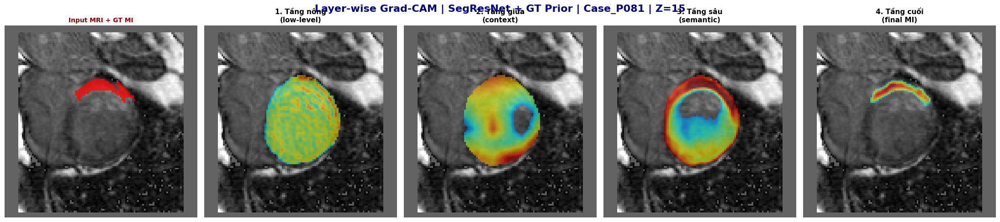

In [35]:
# ==============================================================================
# LAYER-WISE EVOLUTION
# SEGRESNET MULTI-CLASS + GT PRIOR
# EMIDEC classes:
# 0 background | 1 cavity | 2 myocardium | 3 MI
# ==============================================================================

print("\n" + "=" * 80)
print("🌟 TRỰC QUAN HÓA SỰ TIẾN HÓA ATTENTION - SEGRESNET + GT PRIOR")
print("=" * 80)

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.ndimage import zoom


# =========================================================
# LOAD MODEL
# =========================================================

model.load_state_dict(
    torch.load(
        "best_segresnet_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)
model.eval()


# =========================================================
# CUSTOM GRADCAM 3D
# =========================================================

class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.handles = []
        self.handles.append(
            self.target_layer.register_forward_hook(self.save_activation)
        )
        self.handles.append(
            self.target_layer.register_full_backward_hook(self.save_gradient)
        )

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def remove_hooks(self):
        for handle in self.handles:
            handle.remove()

    def generate_heatmap(self, input_tensor, class_idx=3):
        self.model.zero_grad()

        output = self.model(input_tensor)

        if isinstance(output, (list, tuple)):
            output = output[0]

        # class_idx=3 là MI
        score = output[0, class_idx].sum()

        score.backward()

        weights = torch.mean(
            self.gradients,
            dim=(2, 3, 4),
            keepdim=True
        )

        cam = torch.sum(
            weights * self.activations,
            dim=1
        ).squeeze(0)

        cam = F.relu(cam).detach().cpu().numpy()

        if cam.max() - cam.min() > 0:
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam


# =========================================================
# RANDOM MI CASE FROM TEST
# =========================================================

mi_cases = []

for sample_info in test_files:
    data = val_transforms(sample_info)

    if data["label"].max() == 3:
        mi_cases.append(sample_info)

if len(mi_cases) > 0:
    sample_info = random.choice(mi_cases)
else:
    sample_info = random.choice(test_files)

sample_data = val_transforms(sample_info)
case_name = sample_info["case_name"]

print(f"[*] Selected case: {case_name}")


# =========================================================
# PREPARE INPUT
# =========================================================

inputs = torch.as_tensor(
    sample_data["segresnet_input"]
).unsqueeze(0).float().to(device)

labels = torch.as_tensor(
    sample_data["label"]
).unsqueeze(0).long().to(device)

# input channel 0 = MRI, channel 1 = GT prior
mri_vol = inputs[0, 0].detach().cpu().numpy()
prior_vol = inputs[0, 1].detach().cpu().numpy()
gt_array = labels[0, 0].detach().cpu().numpy()

z_scores = np.sum(gt_array == 3, axis=(0, 1))

if z_scores.max() > 0:
    z_slice = int(np.argmax(z_scores))
else:
    z_slice = gt_array.shape[2] // 2

mri_slice = mri_vol[:, :, z_slice]
prior_slice = prior_vol[:, :, z_slice]
gt_slice = gt_array[:, :, z_slice]


# =========================================================
# PREDICTION
# =========================================================

with torch.no_grad():
    outputs = model(inputs)

    if isinstance(outputs, (list, tuple)):
        outputs = outputs[0]

    pred = torch.argmax(outputs, dim=1).detach().cpu().numpy()[0]

pred_slice = pred[:, :, z_slice]


# =========================================================
# TARGET LAYERS
# =========================================================

conv_layers = [
    m for m in model.modules()
    if isinstance(m, torch.nn.Conv3d)
]

print(f"Tổng số Conv3D layers: {len(conv_layers)}")

step = max(1, len(conv_layers) // 4)

target_layers = {
    "1. Tầng nông\n(low-level)": conv_layers[min(1, len(conv_layers)-1)],
    "2. Tầng giữa\n(context)": conv_layers[len(conv_layers)//2],
    "3. Tầng sâu\n(semantic)": conv_layers[-6] if len(conv_layers) >= 6 else conv_layers[-2],
    "4. Tầng cuối\n(final MI)": conv_layers[-1],
}


# =========================================================
# PLOT
# =========================================================

fig, axes = plt.subplots(
    1,
    len(target_layers) + 1,
    figsize=(22, 5)
)

fig.suptitle(
    f"Layer-wise Grad-CAM | SegResNet + GT Prior | {case_name} | Z={z_slice}",
    fontsize=16,
    fontweight="bold",
    color="navy"
)

# Column 0: input + GT MI
axes[0].imshow(np.rot90(mri_slice), cmap="gray")

gt_mi = np.ma.masked_where(
    gt_slice != 3,
    gt_slice
)

axes[0].imshow(
    np.rot90(gt_mi),
    cmap="autumn",
    alpha=0.75
)

axes[0].set_title(
    "Input MRI + GT MI",
    fontweight="bold",
    color="darkred",
    fontsize=10
)

axes[0].axis("off")


# =========================================================
# CAM PER LAYER
# =========================================================

for idx, (layer_title, layer_module) in enumerate(target_layers.items()):

    try:
        cam_engine = GradCAM3D(
            model=model,
            target_layer=layer_module
        )

        inputs_grad = inputs.clone().detach().requires_grad_(True)

        heat_small = cam_engine.generate_heatmap(
            inputs_grad,
            class_idx=3
        )

        cam_engine.remove_hooks()

        zoom_factor = (
            gt_array.shape[0] / heat_small.shape[0],
            gt_array.shape[1] / heat_small.shape[1],
            gt_array.shape[2] / heat_small.shape[2],
        )

        heat = zoom(
            heat_small,
            zoom_factor,
            order=1
        )

        if heat.max() > 0:
            heat = heat / heat.max()

        heat_slice = heat[:, :, z_slice]

        # Giống code cũ: gọt CAM bằng GT prior tim, không gọt bằng GT MI
        heat_slice = heat_slice * (prior_slice > 0.5)

        if heat_slice.max() > 0:
            heat_slice = heat_slice / heat_slice.max()

        # Logic đảo màu giống code cũ:
        # nếu vùng ngoài MI trong prior sáng hơn MI thì đảo lại
        if (gt_slice == 3).any():
            mi_intensity = heat_slice[gt_slice == 3].mean()

            bg_mask = (prior_slice > 0.5) & (gt_slice != 3)
            bg_intensity = heat_slice[bg_mask].mean() if bg_mask.any() else 0

            if bg_intensity > mi_intensity:
                heat_slice = (1.0 - heat_slice) * (prior_slice > 0.5)

                if heat_slice.max() > 0:
                    heat_slice = heat_slice / heat_slice.max()

        heat_masked = np.ma.masked_where(
            heat_slice < 0.25,
            heat_slice
        )

        ax = axes[idx + 1]

        ax.imshow(np.rot90(mri_slice), cmap="gray")

        ax.imshow(
            np.rot90(heat_masked),
            cmap="jet",
            alpha=0.6,
            vmin=0,
            vmax=1
        )

        ax.set_title(
            layer_title,
            fontweight="bold",
            fontsize=11
        )

        ax.axis("off")

    except Exception as e:
        ax = axes[idx + 1]
        ax.imshow(np.rot90(mri_slice), cmap="gray")
        ax.set_title(
            f"{layer_title}\nLỗi CAM",
            color="red",
            fontweight="bold"
        )
        ax.axis("off")
        print(f"Lỗi ở layer {layer_title}: {e}")


plt.tight_layout()
plt.show()


🚀 TRỰC QUAN HÓA ATTENTION CHO 3 BỆNH NHÂN - SEGRESNET + GT PRIOR
Tổng số Conv3D layers: 32

[*] Đang phân tích bệnh nhân #1: Case_P091


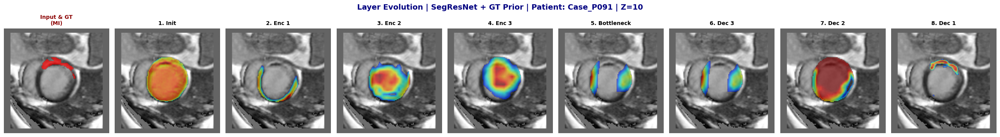


[*] Đang phân tích bệnh nhân #2: Case_P063


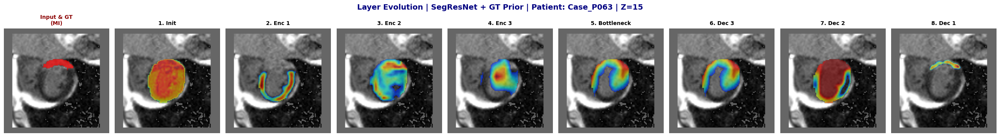


[*] Đang phân tích bệnh nhân #3: Case_P077


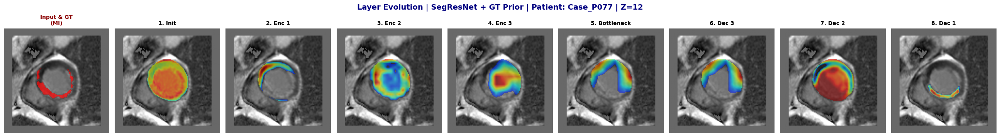

In [44]:
# ==============================================================================
# LAYER-WISE EVOLUTION
# SEGRESNET MULTI-CLASS + GT PRIOR
# Dựa trên code cũ của bạn, nhưng sửa cho pipeline hiện tại
# ==============================================================================

import numpy as np
import random
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from scipy.ndimage import zoom

print("\n" + "=" * 80)
print("🚀 TRỰC QUAN HÓA ATTENTION CHO 3 BỆNH NHÂN - SEGRESNET + GT PRIOR")
print("=" * 80)


class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.handle = self.target_layer.register_forward_hook(self.save_activation)

    def save_activation(self, module, input, output):
        self.activations = output.clone()

        if self.activations.requires_grad:
            self.activations.register_hook(self.save_gradient)

        return self.activations

    def save_gradient(self, grad):
        self.gradients = grad.clone()

    def remove_hooks(self):
        self.handle.remove()

    def generate_heatmap(self, input_tensor, class_idx=3):
        self.model.zero_grad(set_to_none=True)
        self.gradients = None
        self.activations = None

        output = self.model(input_tensor)

        if isinstance(output, (list, tuple)):
            output = output[0]

        score = output[:, class_idx].sum()
        score.backward()

        if self.gradients is None or self.activations is None:
            raise RuntimeError("Layer này không lấy được gradient, bỏ qua.")

        weights = torch.mean(
            self.gradients,
            dim=(2, 3, 4),
            keepdim=True
        )

        cam = torch.sum(
            weights * self.activations,
            dim=1
        ).squeeze(0)

        cam = F.relu(cam).detach().cpu().numpy()

        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam


def run_3_patients_evolution(model, test_files, device, transform):

    model.load_state_dict(
        torch.load(
            "best_segresnet_emidec_multiclass_gt_prior.pth",
            map_location=device
        )
    )

    model.eval()

    conv_layers = [
        m for m in model.modules()
        if isinstance(m, torch.nn.Conv3d)
    ]

    print(f"Tổng số Conv3D layers: {len(conv_layers)}")

    step = max(1, len(conv_layers) // 8)

    target_layers = {
        "1. Init": conv_layers[0],
        "2. Enc 1": conv_layers[min(step * 1, len(conv_layers) - 1)],
        "3. Enc 2": conv_layers[min(step * 2, len(conv_layers) - 1)],
        "4. Enc 3": conv_layers[min(step * 3 + 1, len(conv_layers) - 1)],
        "5. Bottleneck": conv_layers[min(step * 4, len(conv_layers) - 1)],
        "6. Dec 3": conv_layers[-min(step * 4, len(conv_layers))],
        "7. Dec 2": conv_layers[-min(step * 2, len(conv_layers))],
        "8. Dec 1": conv_layers[-1],
    }

    mi_patients = []

    for info in test_files:
        data = transform(info)

        if data["label"].max() == 3:
            mi_patients.append((info, data))

    if not mi_patients:
        print("[!] Không có bệnh nhân nào có MI trong tập test.")
        return

    selected_patients = random.sample(
        mi_patients,
        min(3, len(mi_patients))
    )

    for p_idx, (info, data) in enumerate(selected_patients):

        print(f"\n[*] Đang phân tích bệnh nhân #{p_idx + 1}: {info['case_name']}")

        inputs = torch.as_tensor(
            data["segresnet_input"]
        ).unsqueeze(0).float().to(device)

        labels = torch.as_tensor(
            data["label"]
        ).unsqueeze(0).long().to(device)

        # Channel 0 = MRI, Channel 1 = GT prior
        img_vol = inputs[0, 0].detach().cpu().numpy()
        prior_vol = inputs[0, 1].detach().cpu().numpy()
        gt_array = labels[0, 0].detach().cpu().numpy()

        z_scores = np.sum(gt_array == 3, axis=(0, 1))

        if z_scores.max() > 0:
            z_slice = int(np.argmax(z_scores))
        else:
            z_slice = gt_array.shape[2] // 2

        img_slice = img_vol[:, :, z_slice]
        prior_slice = prior_vol[:, :, z_slice]
        gt_slice = gt_array[:, :, z_slice]

        fig, axes = plt.subplots(
            1,
            len(target_layers) + 1,
            figsize=(26, 3.8)
        )

        fig.suptitle(
            f"Layer Evolution | SegResNet + GT Prior | Patient: {info['case_name']} | Z={z_slice}",
            fontsize=14,
            fontweight="bold",
            color="navy"
        )

        # Cột 1: Input + GT MI
        axes[0].imshow(np.rot90(img_slice), cmap="gray")

        gt_mask = np.ma.masked_where(
            gt_slice != 3,
            gt_slice
        )

        axes[0].imshow(
            np.rot90(gt_mask),
            cmap="autumn",
            alpha=0.7
        )

        axes[0].set_title(
            "Input & GT\n(MI)",
            fontweight="bold",
            color="darkred",
            fontsize=10
        )

        axes[0].axis("off")

        for i, (layer_name, layer_module) in enumerate(target_layers.items()):

            ax = axes[i + 1]
            cam_extractor = None

            try:
                cam_extractor = GradCAM3D(
                    model=model,
                    target_layer=layer_module
                )

                img_grad = inputs.clone().detach().requires_grad_(True)

                heat_small = cam_extractor.generate_heatmap(
                    img_grad,
                    class_idx=3
                )

                cam_extractor.remove_hooks()

                zoom_factor = (
                    gt_array.shape[0] / heat_small.shape[0],
                    gt_array.shape[1] / heat_small.shape[1],
                    gt_array.shape[2] / heat_small.shape[2],
                )

                heat = zoom(
                    heat_small,
                    zoom_factor,
                    order=1
                )

                if heat.max() > 0:
                    heat = heat / heat.max()

                heat_slice = heat[:, :, z_slice]

                # Gọt sạch nhiễu bằng GT prior tim
                # Không dùng GT MI để gọt
                heat_slice = heat_slice * (prior_slice > 0.5)

                if heat_slice.max() > 0:
                    heat_slice = heat_slice / heat_slice.max()

                # Logic đảo màu như code cũ
                if i >= 6 and (gt_slice == 3).any():
                    scar_int = heat_slice[gt_slice == 3].mean()

                    bg_mask = (prior_slice > 0.5) & (gt_slice != 3)
                    bg_int = heat_slice[bg_mask].mean() if bg_mask.any() else 0

                    if bg_int > scar_int:
                        heat_slice = (1.0 - heat_slice) * (prior_slice > 0.5)

                        if heat_slice.max() > 0:
                            heat_slice = heat_slice / heat_slice.max()

                heat_slice_masked = np.ma.masked_where(
                    heat_slice < 0.15,
                    heat_slice
                )

                ax.imshow(np.rot90(img_slice), cmap="gray")

                ax.imshow(
                    np.rot90(heat_slice_masked),
                    cmap="jet",
                    alpha=0.6,
                    vmin=0,
                    vmax=1
                )

                ax.set_title(
                    layer_name,
                    fontsize=10,
                    fontweight="bold"
                )

            except Exception as e:
                if cam_extractor is not None:
                    try:
                        cam_extractor.remove_hooks()
                    except:
                        pass

                ax.imshow(np.rot90(img_slice), cmap="gray")
                ax.set_title(
                    f"{layer_name}\n[Bỏ qua]",
                    color="gray",
                    fontsize=9
                )

                print(f"Lỗi layer {layer_name}: {e}")

            ax.axis("off")

        plt.tight_layout()
        plt.show()


run_3_patients_evolution(
    model=model,
    test_files=test_files,
    device=device,
    transform=val_transforms
)


🧠 UNCERTAINTY MAP - SEGRESNET + GT PRIOR
[*] Đang chạy MC Dropout (T=15) cho 3 bệnh nhân...

[*] Đang phân tích: Case_P036


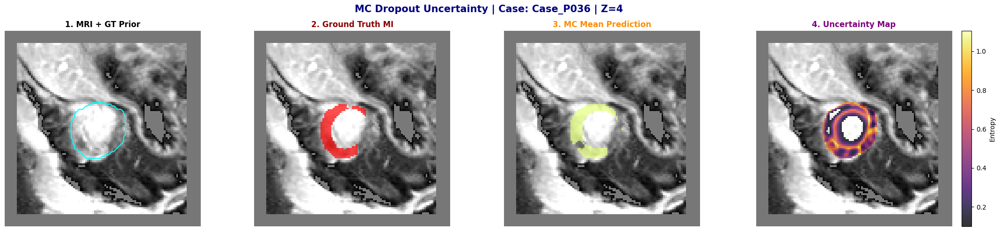


[*] Đang phân tích: Case_P081


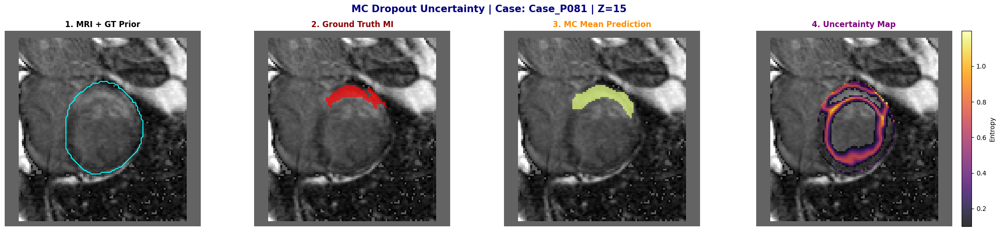


[*] Đang phân tích: Case_P001


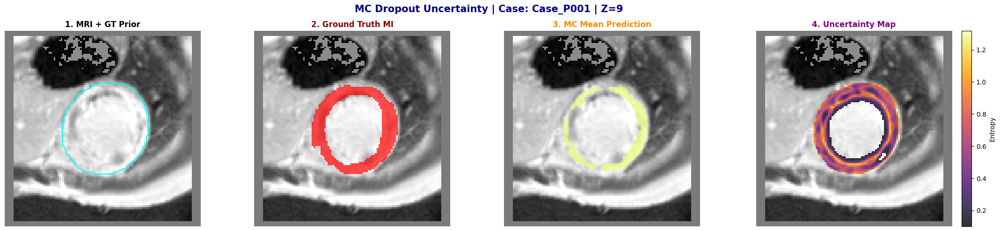

In [45]:
# ==============================================================================
# 🧠 MC DROPOUT UNCERTAINTY MAP
# SEGRESNET MULTI-CLASS + GT PRIOR
#
# Classes:
# 0 background
# 1 cavity
# 2 myocardium
# 3 MI
# ==============================================================================

import numpy as np
import random
import matplotlib.pyplot as plt
import torch

print("\n" + "=" * 80)
print("🧠 UNCERTAINTY MAP - SEGRESNET + GT PRIOR")
print("=" * 80)


# =========================================================
# LOAD MODEL
# =========================================================

model.load_state_dict(
    torch.load(
        "best_segresnet_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


# =========================================================
# ENABLE DROPOUT ONLY
# =========================================================

def enable_dropout_only(m):
    """
    Chỉ bật Dropout, giữ BatchNorm ở eval mode
    """
    if isinstance(
        m,
        (
            torch.nn.Dropout,
            torch.nn.Dropout2d,
            torch.nn.Dropout3d
        )
    ):
        m.train()


# =========================================================
# MC DROPOUT
# =========================================================

def compute_uncertainty_mc_dropout(
    model,
    segresnet_input,
    T=15
):
    """
    Monte Carlo Dropout Uncertainty
    """

    model.eval()
    model.apply(enable_dropout_only)

    outputs = []

    with torch.no_grad():

        for _ in range(T):

            logits = model(segresnet_input)

            if isinstance(logits, (list, tuple)):
                logits = logits[0]

            probs = torch.softmax(logits, dim=1)

            outputs.append(probs)

    outputs = torch.stack(outputs)

    # Mean probability
    mean_prob = torch.mean(outputs, dim=0)

    # Predictive entropy
    epsilon = 1e-6

    uncertainty_map = -torch.sum(
        mean_prob * torch.log(mean_prob + epsilon),
        dim=1
    )

    # =====================================================
    # GỌT NHIỄU NGOÀI TIM BẰNG GT PRIOR
    # Channel 1 = anatomy prior
    # =====================================================

    mask_tim = segresnet_input[:, 1, ...]

    uncertainty_map = uncertainty_map * mask_tim

    model.eval()

    return mean_prob, uncertainty_map


# =========================================================
# VISUALIZE
# =========================================================

def visualize_uncertainty_xai(
    model,
    test_files,
    device,
    transform,
    num_samples=3
):

    print(
        f"[*] Đang chạy MC Dropout (T=15) cho {num_samples} bệnh nhân..."
    )

    mi_patients = []

    for info in test_files:

        data = transform(info)

        # class 3 = MI
        if data["label"].max() == 3:
            mi_patients.append((info, data))

    if not mi_patients:
        print("[!] Không có bệnh nhân MI trong tập test.")
        return

    selected_patients = random.sample(
        mi_patients,
        min(num_samples, len(mi_patients))
    )

    for p_idx, (info, data) in enumerate(selected_patients):

        print(f"\n[*] Đang phân tích: {info['case_name']}")

        # =================================================
        # INPUT
        # =================================================

        inputs = torch.as_tensor(
            data["segresnet_input"]
        ).unsqueeze(0).float().to(device)

        labels = torch.as_tensor(
            data["label"]
        ).unsqueeze(0).long().to(device)

        # =================================================
        # MC DROPOUT
        # =================================================

        mean_prob, unc_map = compute_uncertainty_mc_dropout(
            model,
            inputs,
            T=15
        )

        pred_mask = torch.argmax(
            mean_prob,
            dim=1
        ).cpu().numpy()[0]

        unc_map_np = unc_map.cpu().numpy()[0]

        # =================================================
        # FIND BEST MI SLICE
        # =================================================

        gt_array = labels[0, 0].cpu().numpy()

        z_scores = np.sum(gt_array == 3, axis=(0, 1))

        if z_scores.max() > 0:
            z_slice = int(np.argmax(z_scores))
        else:
            z_slice = gt_array.shape[2] // 2

        # =================================================
        # EXTRACT SLICE
        # =================================================

        img_slice = inputs[0, 0, :, :, z_slice].cpu().numpy()

        # channel 1 = GT prior
        mask_tim_slice = inputs[0, 1, :, :, z_slice].cpu().numpy()

        gt_slice = gt_array[:, :, z_slice]

        pred_slice = pred_mask[:, :, z_slice]

        unc_slice = unc_map_np[:, :, z_slice]

        # =================================================
        # CLEAN UNCERTAINTY
        # =================================================

        unc_slice_masked = np.ma.masked_where(
            unc_slice < 0.10,
            unc_slice
        )

        # =================================================
        # PLOT
        # =================================================

        fig, axes = plt.subplots(
            1,
            4,
            figsize=(22, 5)
        )

        fig.suptitle(
            f"MC Dropout Uncertainty | Case: {info['case_name']} | Z={z_slice}",
            fontsize=15,
            fontweight='bold',
            color='navy'
        )

        # -------------------------------------------------
        # 1. MRI + PRIOR
        # -------------------------------------------------

        axes[0].imshow(
            np.rot90(img_slice),
            cmap='gray'
        )

        axes[0].contour(
            np.rot90(mask_tim_slice),
            colors='cyan',
            levels=[0.5],
            linewidths=1.5
        )

        axes[0].set_title(
            "1. MRI + GT Prior",
            fontweight='bold'
        )

        axes[0].axis('off')

        # -------------------------------------------------
        # 2. GT MI
        # -------------------------------------------------

        axes[1].imshow(
            np.rot90(img_slice),
            cmap='gray'
        )

        gt_masked = np.ma.masked_where(
            gt_slice != 3,
            gt_slice
        )

        axes[1].imshow(
            np.rot90(gt_masked),
            cmap='autumn',
            alpha=0.7
        )

        axes[1].set_title(
            "2. Ground Truth MI",
            fontweight='bold',
            color='darkred'
        )

        axes[1].axis('off')

        # -------------------------------------------------
        # 3. MC Mean Prediction
        # -------------------------------------------------

        axes[2].imshow(
            np.rot90(img_slice),
            cmap='gray'
        )

        pred_masked = np.ma.masked_where(
            pred_slice != 3,
            pred_slice
        )

        axes[2].imshow(
            np.rot90(pred_masked),
            cmap='Wistia',
            alpha=0.7
        )

        axes[2].set_title(
            "3. MC Mean Prediction",
            fontweight='bold',
            color='darkorange'
        )

        axes[2].axis('off')

        # -------------------------------------------------
        # 4. UNCERTAINTY MAP
        # -------------------------------------------------

        axes[3].imshow(
            np.rot90(img_slice),
            cmap='gray'
        )

        im_unc = axes[3].imshow(
            np.rot90(unc_slice_masked),
            cmap='inferno',
            alpha=0.8
        )

        axes[3].set_title(
            "4. Uncertainty Map",
            fontweight='bold',
            color='purple'
        )

        axes[3].axis('off')

        plt.colorbar(
            im_unc,
            ax=axes[3],
            fraction=0.046,
            pad=0.04,
            label='Entropy'
        )

        plt.tight_layout()
        plt.show()


# =========================================================
# RUN
# =========================================================

visualize_uncertainty_xai(
    model=model,
    test_files=test_files,
    device=device,
    transform=val_transforms,
    num_samples=3
)


🔬 TRỰC QUAN HÓA GRAD-CAM & PREDICTION - SEGRESNET + GT PRIOR
[*] Selected case: Case_P063
[*] Grad-CAM target layer: Conv3d(16, 4, kernel_size=(1, 1, 1), stride=(1, 1, 1))


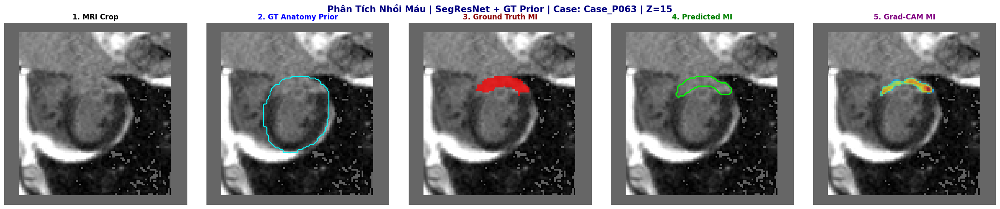

In [46]:
# ==============================================================================
# VISUALIZE PREDICTION + GRAD-CAM
# SEGRESNET MULTI-CLASS + GT PRIOR
#
# Classes:
# 0 background
# 1 cavity
# 2 myocardium
# 3 MI = infarction + no-reflow
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from scipy.ndimage import zoom
import random

print("\n" + "=" * 80)
print("🔬 TRỰC QUAN HÓA GRAD-CAM & PREDICTION - SEGRESNET + GT PRIOR")
print("=" * 80)


# =========================================================
# LOAD MODEL
# =========================================================

model.load_state_dict(
    torch.load(
        "best_segresnet_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


# =========================================================
# CUSTOM GRADCAM 3D
# =========================================================

class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.handle = self.target_layer.register_forward_hook(
            self.save_activation
        )

    def save_activation(self, module, inp, out):
        self.activations = out.clone()

        def save_grad(grad):
            self.gradients = grad.clone()

        self.activations.register_hook(save_grad)

        return self.activations

    def remove_hooks(self):
        self.handle.remove()

    def generate_heatmap(self, x, class_idx=3):
        self.model.zero_grad(set_to_none=True)

        out = self.model(x)

        if isinstance(out, (list, tuple)):
            out = out[0]

        score = out[0, class_idx].sum()
        score.backward()

        if self.gradients is None or self.activations is None:
            raise RuntimeError("Không lấy được gradient ở layer này.")

        weights = torch.mean(
            self.gradients,
            dim=(2, 3, 4),
            keepdim=True
        )

        cam = torch.sum(
            weights * self.activations,
            dim=1
        ).squeeze(0)

        cam = F.relu(cam).detach().cpu().numpy()

        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam


# =========================================================
# FIND RANDOM MI CASE
# =========================================================

mi_cases = []

for info in test_files:
    data = val_transforms(info)

    if data["label"].max() == 3:
        mi_cases.append(info)

sample_info = random.choice(mi_cases) if len(mi_cases) > 0 else random.choice(test_files)

sample_data = val_transforms(sample_info)
case_name = sample_info["case_name"]

print(f"[*] Selected case: {case_name}")


# =========================================================
# PREPARE INPUT
# =========================================================

inputs = torch.as_tensor(
    sample_data["segresnet_input"]
).unsqueeze(0).float().to(device)

labels = torch.as_tensor(
    sample_data["label"]
).unsqueeze(0).long().to(device)

# Channel 0 = MRI, channel 1 = GT prior
img_vol = inputs[0, 0].detach().cpu().numpy()
prior_vol = inputs[0, 1].detach().cpu().numpy()
gt_array = labels[0, 0].detach().cpu().numpy()

z_scores = np.sum(gt_array == 3, axis=(0, 1))

if z_scores.max() > 0:
    z_slice = int(np.argmax(z_scores))
else:
    z_slice = gt_array.shape[2] // 2

img_slice = img_vol[:, :, z_slice]
prior_slice = prior_vol[:, :, z_slice]
gt_slice = gt_array[:, :, z_slice]


# =========================================================
# PREDICTION
# =========================================================

with torch.no_grad():
    outputs = model(inputs)

    if isinstance(outputs, (list, tuple)):
        outputs = outputs[0]

    preds = torch.argmax(
        outputs,
        dim=1
    ).detach().cpu().numpy()[0]

pred_slice = preds[:, :, z_slice]


# =========================================================
# GRAD-CAM
# =========================================================

conv_layers = [
    m for m in model.modules()
    if isinstance(m, torch.nn.Conv3d)
]

# Với SegResNet, final conv ổn nhất
target_layer = model.conv_final[2].conv

print(f"[*] Grad-CAM target layer: {target_layer}")

cam_engine = GradCAM3D(
    model=model,
    target_layer=target_layer
)

inputs_grad = inputs.clone().detach().requires_grad_(True)

heat_small = cam_engine.generate_heatmap(
    inputs_grad,
    class_idx=3
)

cam_engine.remove_hooks()

zoom_factor = (
    gt_array.shape[0] / heat_small.shape[0],
    gt_array.shape[1] / heat_small.shape[1],
    gt_array.shape[2] / heat_small.shape[2],
)

heat = zoom(
    heat_small,
    zoom_factor,
    order=1
)

if heat.max() > 0:
    heat = heat / heat.max()

heat_slice = heat[:, :, z_slice]

# Gọt nhiễu bằng GT prior tim, không dùng GT MI
heat_slice = heat_slice * (prior_slice > 0.5)

if heat_slice.max() > 0:
    heat_slice = heat_slice / heat_slice.max()

# Logic đảo màu giống code cũ:
# nếu vùng trong tim ngoài MI sáng hơn vùng MI thì đảo để xem hotspot MI rõ hơn
if (gt_slice == 3).any():
    mi_intensity = heat_slice[gt_slice == 3].mean()

    bg_mask = (prior_slice > 0.5) & (gt_slice != 3)
    bg_intensity = heat_slice[bg_mask].mean() if bg_mask.any() else 0

    if bg_intensity > mi_intensity:
        heat_slice = (1.0 - heat_slice) * (prior_slice > 0.5)

        if heat_slice.max() > 0:
            heat_slice = heat_slice / heat_slice.max()

heat_slice_masked = np.ma.masked_where(
    heat_slice < 0.25,
    heat_slice
)


# =========================================================
# VISUALIZATION
# =========================================================

fig, axes = plt.subplots(
    1,
    5,
    figsize=(24, 5)
)

fig.suptitle(
    f"Phân Tích Nhồi Máu | SegResNet + GT Prior | Case: {case_name} | Z={z_slice}",
    fontsize=15,
    fontweight="bold",
    color="navy"
)

# 1. MRI
axes[0].imshow(
    np.rot90(img_slice),
    cmap="gray"
)

axes[0].set_title(
    "1. MRI Crop",
    fontweight="bold"
)

axes[0].axis("off")


# 2. GT Prior
axes[1].imshow(
    np.rot90(img_slice),
    cmap="gray"
)

axes[1].contour(
    np.rot90(prior_slice),
    colors="cyan",
    levels=[0.5],
    linewidths=1.5
)

axes[1].set_title(
    "2. GT Anatomy Prior",
    fontweight="bold",
    color="blue"
)

axes[1].axis("off")


# 3. GT MI
axes[2].imshow(
    np.rot90(img_slice),
    cmap="gray"
)

gt_mi_mask = np.ma.masked_where(
    gt_slice != 3,
    gt_slice
)

axes[2].imshow(
    np.rot90(gt_mi_mask),
    cmap="autumn",
    alpha=0.75
)

axes[2].set_title(
    "3. Ground Truth MI",
    fontweight="bold",
    color="darkred"
)

axes[2].axis("off")


# 4. Prediction MI contour
axes[3].imshow(
    np.rot90(img_slice),
    cmap="gray"
)

pred_mi_only = (pred_slice == 3).astype(np.uint8)

if pred_mi_only.max() > 0:
    axes[3].contour(
        np.rot90(pred_mi_only),
        colors="lime",
        levels=[0.5],
        linewidths=2
    )

axes[3].set_title(
    "4. Predicted MI",
    fontweight="bold",
    color="green"
)

axes[3].axis("off")


# 5. Grad-CAM
axes[4].imshow(
    np.rot90(img_slice),
    cmap="gray"
)

axes[4].imshow(
    np.rot90(heat_slice_masked),
    cmap="jet",
    alpha=0.65,
    vmin=0,
    vmax=1
)

axes[4].set_title(
    "5. Grad-CAM MI",
    fontweight="bold",
    color="purple"
)

axes[4].axis("off")

plt.tight_layout()
plt.show()

Loaded best model: best_segresnet_emidec_multiclass_gt_prior.pth


Testing MI detection:   0%|          | 0/15 [00:00<?, ?it/s]

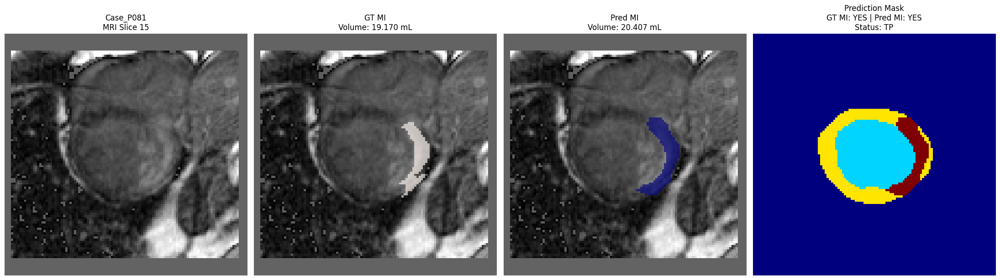

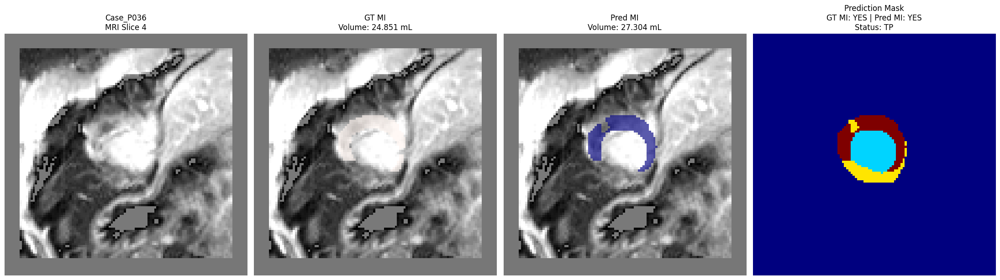

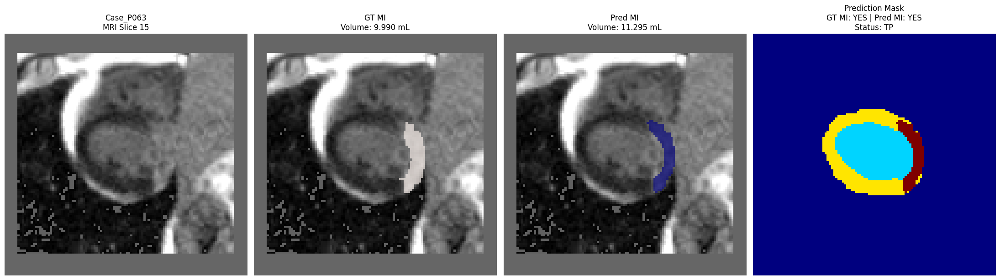

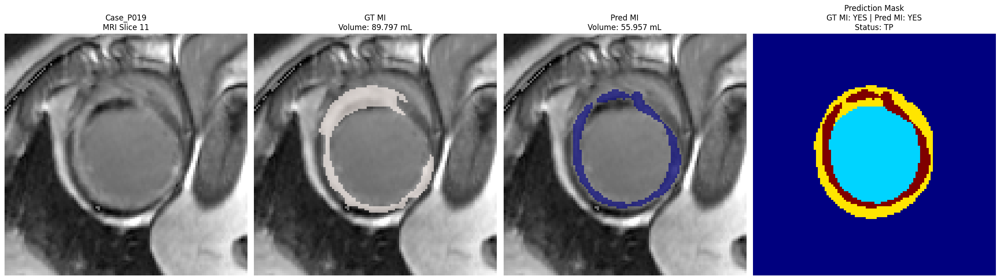

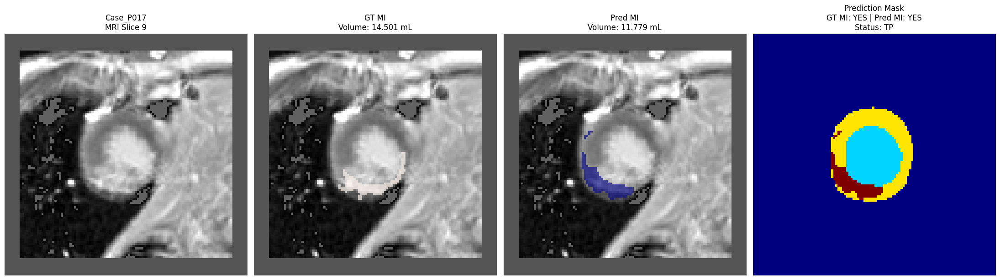

...

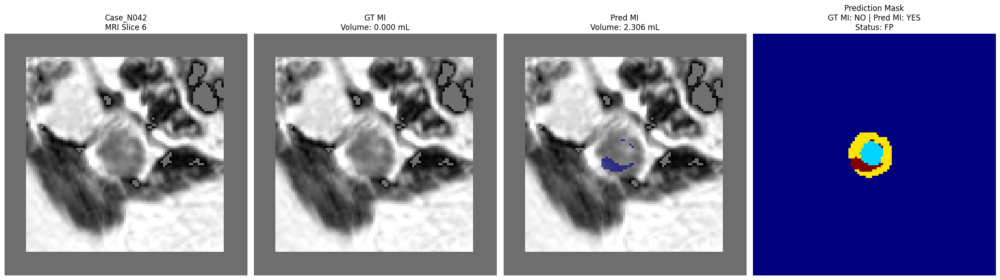

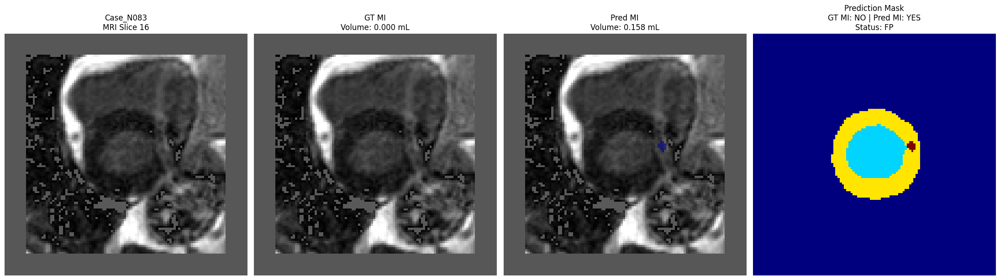

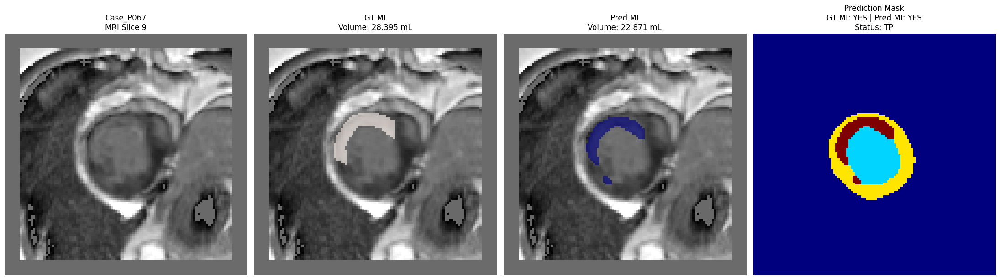

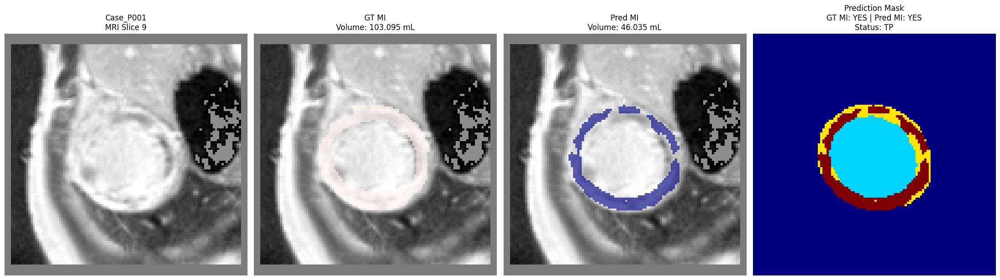

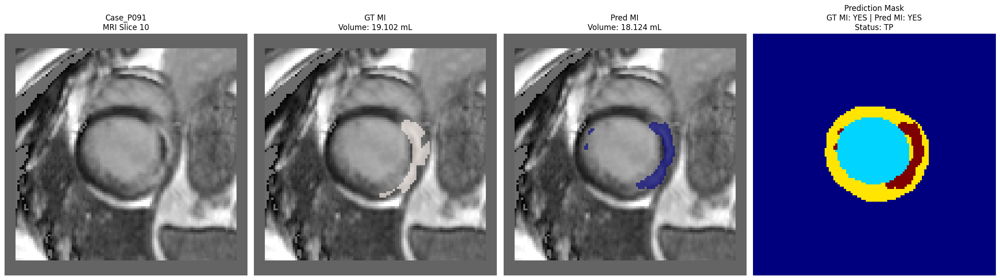

MI DETECTION SUMMARY
TP: 10
TN: 0
FP: 5
FN: 0
Accuracy   : 0.6667
Sensitivity: 1.0000
Specificity: 0.0000
Saved CSV: /kaggle/working/mi_detection_volume_results.csv
Saved visualizations: /kaggle/working/MI_Test_Visualization


In [3]:
# =========================================================
# FINAL TEST: MI YES/NO + MI VOLUME + VISUALIZATION
# FOR SEGRESNET EMIDEC MULTI-CLASS MODEL
# =========================================================

import os
import csv
import numpy as np
import torch
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from monai.networks.nets import SegResNet

# =========================================================
# CONFIG
# =========================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NUM_CLASSES = 4
BEST_MODEL_PATH = "best_segresnet_emidec_multiclass_gt_prior.pth"

SAVE_DIR = "/kaggle/working/MI_Test_Visualization"
os.makedirs(SAVE_DIR, exist_ok=True)

CSV_PATH = "/kaggle/working/mi_detection_volume_results.csv"

# Spacing bạn dùng khi train:
# pixdim=(1.5, 1.5, 5.0)
VOXEL_VOLUME_MM3 = 1.5 * 1.5 * 5.0
VOXEL_VOLUME_ML = VOXEL_VOLUME_MM3 / 1000.0

# Ngưỡng tối thiểu để kết luận có MI
# Có thể chỉnh 5 / 10 / 20 tùy kết quả
MI_MIN_VOXELS = 10

# =========================================================
# LOAD BEST MODEL
# =========================================================

model = SegResNet(
    spatial_dims=3,
    in_channels=2,
    out_channels=NUM_CLASSES,
    init_filters=16,
    blocks_down=(1, 2, 2, 4),
    blocks_up=(1, 1, 1),
    dropout_prob=0.2,
).to(device)

model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
model.eval()

print("Loaded best model:", BEST_MODEL_PATH)

# =========================================================
# HELPER FUNCTIONS
# =========================================================

def calculate_mi_volume(mask, mi_class=3):
    mi_voxels = np.sum(mask == mi_class)
    volume_ml = mi_voxels * VOXEL_VOLUME_ML
    return int(mi_voxels), float(volume_ml)

def has_mi(mask, mi_class=3, min_voxels=10):
    return np.sum(mask == mi_class) >= min_voxels

def get_best_slice(gt_mask, pred_mask, mi_class=3):
    gt_per_slice = np.sum(gt_mask == mi_class, axis=(0, 1))
    pred_per_slice = np.sum(pred_mask == mi_class, axis=(0, 1))

    if gt_per_slice.max() > 0:
        return int(np.argmax(gt_per_slice))
    elif pred_per_slice.max() > 0:
        return int(np.argmax(pred_per_slice))
    else:
        return gt_mask.shape[2] // 2

# =========================================================
# TEST + VISUALIZE
# =========================================================

results = []

with torch.no_grad():
    for idx, batch in enumerate(tqdm(test_loader, desc="Testing MI detection")):
        inputs = batch["segresnet_input"].to(device)
        labels = batch["label"].to(device)

        outputs = model(inputs)
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(probs, dim=1)

        image_np = inputs[0, 0].detach().cpu().numpy()

        if labels.ndim == 5:
            label_np = labels[0, 0].detach().cpu().numpy()
        else:
            label_np = labels[0].detach().cpu().numpy()

        pred_np = preds[0].detach().cpu().numpy()

        # Case name
        if "case_name" in batch:
            case_name = batch["case_name"][0]
        else:
            case_name = f"case_{idx:03d}"

        # Volume
        gt_mi_voxels, gt_mi_volume_ml = calculate_mi_volume(label_np, mi_class=3)
        pred_mi_voxels, pred_mi_volume_ml = calculate_mi_volume(pred_np, mi_class=3)

        # Yes / No detection
        gt_has_mi = has_mi(label_np, mi_class=3, min_voxels=MI_MIN_VOXELS)
        pred_has_mi = has_mi(pred_np, mi_class=3, min_voxels=MI_MIN_VOXELS)

        # Classification result
        if gt_has_mi and pred_has_mi:
            status = "TP"
        elif (not gt_has_mi) and (not pred_has_mi):
            status = "TN"
        elif (not gt_has_mi) and pred_has_mi:
            status = "FP"
        else:
            status = "FN"

        results.append([
            case_name,
            int(gt_has_mi),
            int(pred_has_mi),
            status,
            gt_mi_voxels,
            pred_mi_voxels,
            gt_mi_volume_ml,
            pred_mi_volume_ml,
        ])

        # Select best slice
        slice_idx = get_best_slice(label_np, pred_np, mi_class=3)

        gt_mi_overlay = np.ma.masked_where(label_np[:, :, slice_idx] != 3, label_np[:, :, slice_idx])
        pred_mi_overlay = np.ma.masked_where(pred_np[:, :, slice_idx] != 3, pred_np[:, :, slice_idx])

        # Visualization
        plt.figure(figsize=(22, 6))

        plt.subplot(1, 4, 1)
        plt.imshow(image_np[:, :, slice_idx], cmap="gray")
        plt.title(f"{case_name}\nMRI Slice {slice_idx}")
        plt.axis("off")

        plt.subplot(1, 4, 2)
        plt.imshow(image_np[:, :, slice_idx], cmap="gray")
        plt.imshow(gt_mi_overlay, cmap="Reds", alpha=0.65)
        plt.title(f"GT MI\nVolume: {gt_mi_volume_ml:.3f} mL")
        plt.axis("off")

        plt.subplot(1, 4, 3)
        plt.imshow(image_np[:, :, slice_idx], cmap="gray")
        plt.imshow(pred_mi_overlay, cmap="jet", alpha=0.65)
        plt.title(f"Pred MI\nVolume: {pred_mi_volume_ml:.3f} mL")
        plt.axis("off")

        plt.subplot(1, 4, 4)
        plt.imshow(pred_np[:, :, slice_idx], cmap="jet")
        plt.title(
            f"Prediction Mask\n"
            f"GT MI: {'YES' if gt_has_mi else 'NO'} | "
            f"Pred MI: {'YES' if pred_has_mi else 'NO'}\n"
            f"Status: {status}"
        )
        plt.axis("off")

        plt.tight_layout()

        save_path = os.path.join(SAVE_DIR, f"{case_name}_MI_detection_volume.png")
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        plt.show()

# =========================================================
# SAVE CSV
# =========================================================

with open(CSV_PATH, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "Case",
        "GT_MI_YesNo",
        "Pred_MI_YesNo",
        "Status",
        "GT_MI_Voxels",
        "Pred_MI_Voxels",
        "GT_MI_Volume_mL",
        "Pred_MI_Volume_mL",
    ])
    writer.writerows(results)

# =========================================================
# SUMMARY
# =========================================================

results_np = np.array(results, dtype=object)

statuses = [r[3] for r in results]

TP = statuses.count("TP")
TN = statuses.count("TN")
FP = statuses.count("FP")
FN = statuses.count("FN")

accuracy = (TP + TN) / max((TP + TN + FP + FN), 1)
sensitivity = TP / max((TP + FN), 1)
specificity = TN / max((TN + FP), 1)

print("=" * 80)
print("MI DETECTION SUMMARY")
print("=" * 80)
print(f"TP: {TP}")
print(f"TN: {TN}")
print(f"FP: {FP}")
print(f"FN: {FN}")
print(f"Accuracy   : {accuracy:.4f}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print("=" * 80)
print("Saved CSV:", CSV_PATH)
print("Saved visualizations:", SAVE_DIR)

Predict MI only:   0%|          | 0/15 [00:00<?, ?it/s]

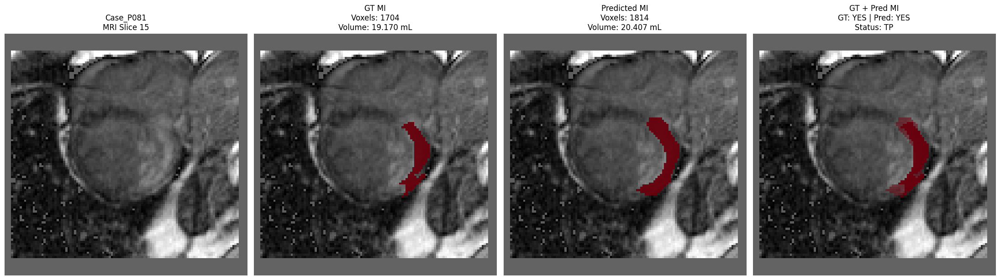

Case_P081
GT MI      : YES
Pred MI    : YES
Status     : TP
GT volume  : 19.170 mL
Pred volume: 20.407 mL
Saved fig  : /kaggle/working/MI_Only_Prediction_Red/Case_P081_MI_red_overlay.png
Saved mask : /kaggle/working/MI_Only_Prediction_Red/Case_P081_pred_MI_mask.nii.gz


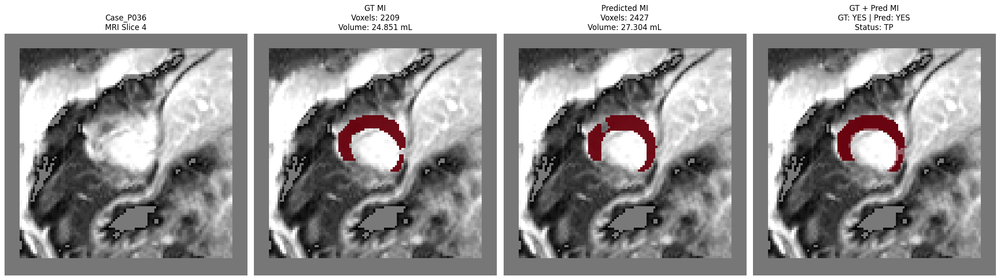

Case_P036
GT MI      : YES
Pred MI    : YES
Status     : TP
GT volume  : 24.851 mL
Pred volume: 27.304 mL
Saved fig  : /kaggle/working/MI_Only_Prediction_Red/Case_P036_MI_red_overlay.png
Saved mask : /kaggle/working/MI_Only_Prediction_Red/Case_P036_pred_MI_mask.nii.gz


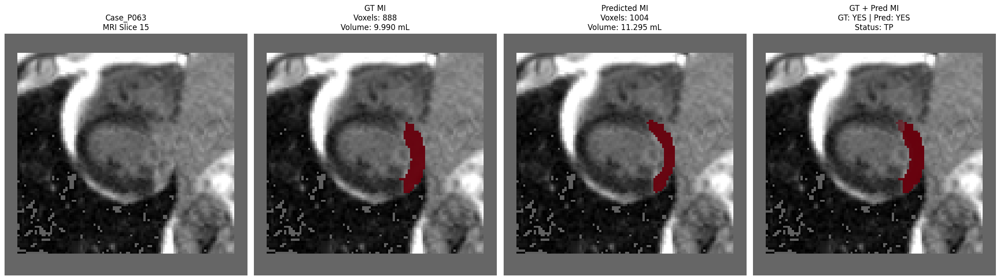

Case_P063
GT MI      : YES
Pred MI    : YES
Status     : TP
GT volume  : 9.990 mL
Pred volume: 11.295 mL
Saved fig  : /kaggle/working/MI_Only_Prediction_Red/Case_P063_MI_red_overlay.png
Saved mask : /kaggle/working/MI_Only_Prediction_Red/Case_P063_pred_MI_mask.nii.gz


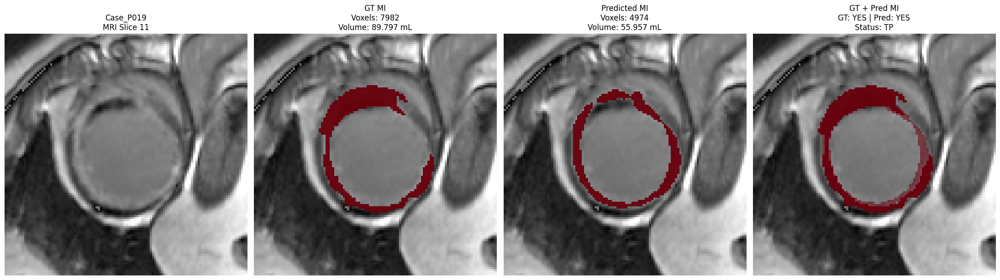

Case_P019
GT MI      : YES
Pred MI    : YES
Status     : TP
GT volume  : 89.797 mL
Pred volume: 55.957 mL
Saved fig  : /kaggle/working/MI_Only_Prediction_Red/Case_P019_MI_red_overlay.png
Saved mask : /kaggle/working/MI_Only_Prediction_Red/Case_P019_pred_MI_mask.nii.gz


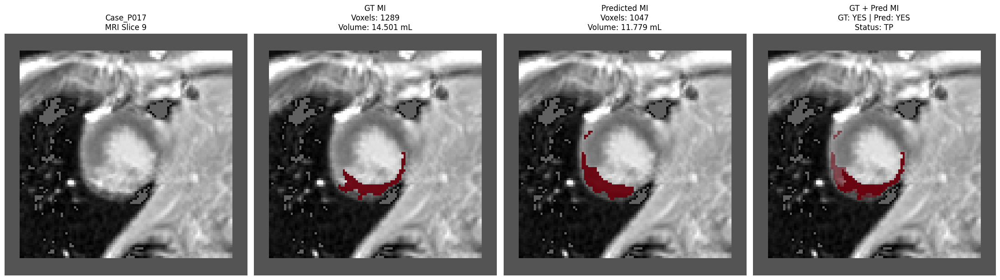

Case_P017
GT MI      : YES
Pred MI    : YES
Status     : TP
GT volume  : 14.501 mL
Pred volume: 11.779 mL
Saved fig  : /kaggle/working/MI_Only_Prediction_Red/Case_P017_MI_red_overlay.png
Saved mask : /kaggle/working/MI_Only_Prediction_Red/Case_P017_pred_MI_mask.nii.gz


In [9]:
# =========================================================
# PREDICT RIÊNG VÙNG MI (CLASS 3) + RED OVERLAY + SAVE MASK
# Run after you already have: model, test_loader, device
# =========================================================

import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import nibabel as nib
from tqdm.auto import tqdm

SAVE_DIR = "/kaggle/working/MI_Only_Prediction_Red"
os.makedirs(SAVE_DIR, exist_ok=True)

MI_CLASS = 3
MI_MIN_VOXELS = 10

VOXEL_VOLUME_ML = (1.5 * 1.5 * 5.0) / 1000.0

model.eval()

with torch.no_grad():
    for idx, batch in enumerate(tqdm(test_loader, desc="Predict MI only")):
        inputs = batch["segresnet_input"].to(device)
        labels = batch["label"].to(device)

        outputs = model(inputs)
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(probs, dim=1)

        image_np = inputs[0, 0].cpu().numpy()

        if labels.ndim == 5:
            label_np = labels[0, 0].cpu().numpy()
        else:
            label_np = labels[0].cpu().numpy()

        pred_np = preds[0].cpu().numpy()

        pred_mi_mask = (pred_np == MI_CLASS).astype(np.uint8)
        gt_mi_mask = (label_np == MI_CLASS).astype(np.uint8)

        pred_mi_voxels = int(pred_mi_mask.sum())
        gt_mi_voxels = int(gt_mi_mask.sum())

        pred_mi_volume_ml = pred_mi_voxels * VOXEL_VOLUME_ML
        gt_mi_volume_ml = gt_mi_voxels * VOXEL_VOLUME_ML

        pred_has_mi = pred_mi_voxels >= MI_MIN_VOXELS
        gt_has_mi = gt_mi_voxels >= MI_MIN_VOXELS

        if gt_has_mi and pred_has_mi:
            status = "TP"
        elif (not gt_has_mi) and (not pred_has_mi):
            status = "TN"
        elif (not gt_has_mi) and pred_has_mi:
            status = "FP"
        else:
            status = "FN"

        case_name = batch["case_name"][0] if "case_name" in batch else f"case_{idx:03d}"

        gt_per_slice = np.sum(gt_mi_mask, axis=(0, 1))
        pred_per_slice = np.sum(pred_mi_mask, axis=(0, 1))

        if gt_per_slice.max() > 0:
            slice_idx = int(np.argmax(gt_per_slice))
        elif pred_per_slice.max() > 0:
            slice_idx = int(np.argmax(pred_per_slice))
        else:
            slice_idx = image_np.shape[2] // 2

        # =================================================
        # RED OVERLAY FIX: dùng 1.0 thay vì 255
        # =================================================
        gt_overlay = np.zeros_like(gt_mi_mask[:, :, slice_idx], dtype=np.float32)
        pred_overlay = np.zeros_like(pred_mi_mask[:, :, slice_idx], dtype=np.float32)

        gt_overlay[gt_mi_mask[:, :, slice_idx] == 1] = 1.0
        pred_overlay[pred_mi_mask[:, :, slice_idx] == 1] = 1.0

        gt_overlay = np.ma.masked_where(gt_overlay == 0, gt_overlay)
        pred_overlay = np.ma.masked_where(pred_overlay == 0, pred_overlay)

        # =================================================
        # VISUALIZE
        # =================================================
        plt.figure(figsize=(22, 6))

        plt.subplot(1, 4, 1)
        plt.imshow(image_np[:, :, slice_idx], cmap="gray")
        plt.title(f"{case_name}\nMRI Slice {slice_idx}")
        plt.axis("off")

        plt.subplot(1, 4, 2)
        plt.imshow(image_np[:, :, slice_idx], cmap="gray")
        plt.imshow(gt_overlay, cmap="Reds", alpha=0.95, vmin=0, vmax=1)
        plt.title(
            f"GT MI\n"
            f"Voxels: {gt_mi_voxels}\n"
            f"Volume: {gt_mi_volume_ml:.3f} mL"
        )
        plt.axis("off")

        plt.subplot(1, 4, 3)
        plt.imshow(image_np[:, :, slice_idx], cmap="gray")
        plt.imshow(pred_overlay, cmap="Reds", alpha=0.95, vmin=0, vmax=1)
        plt.title(
            f"Predicted MI\n"
            f"Voxels: {pred_mi_voxels}\n"
            f"Volume: {pred_mi_volume_ml:.3f} mL"
        )
        plt.axis("off")

        plt.subplot(1, 4, 4)
        plt.imshow(image_np[:, :, slice_idx], cmap="gray")
        plt.imshow(gt_overlay, cmap="Reds", alpha=0.95, vmin=0, vmax=1)
        plt.imshow(pred_overlay, cmap="Reds", alpha=0.55, vmin=0, vmax=1)
        plt.title(
            f"GT + Pred MI\n"
            f"GT: {'YES' if gt_has_mi else 'NO'} | "
            f"Pred: {'YES' if pred_has_mi else 'NO'}\n"
            f"Status: {status}"
        )
        plt.axis("off")

        plt.tight_layout()

        fig_path = os.path.join(SAVE_DIR, f"{case_name}_MI_red_overlay.png")
        plt.savefig(fig_path, dpi=300, bbox_inches="tight")
        plt.show()

        mask_path = os.path.join(SAVE_DIR, f"{case_name}_pred_MI_mask.nii.gz")
        nib.save(
            nib.Nifti1Image(pred_mi_mask.astype(np.uint8), affine=np.eye(4)),
            mask_path,
        )

        print("=" * 70)
        print(case_name)
        print("GT MI      :", "YES" if gt_has_mi else "NO")
        print("Pred MI    :", "YES" if pred_has_mi else "NO")
        print("Status     :", status)
        print("GT volume  :", f"{gt_mi_volume_ml:.3f} mL")
        print("Pred volume:", f"{pred_mi_volume_ml:.3f} mL")
        print("Saved fig  :", fig_path)
        print("Saved mask :", mask_path)

        if idx >= 4:
            break

# GT ATTENTION UNET

In [5]:
# =========================================================
# EMIDEC 2020
# MULTI-CLASS ATTENTION U-NET
# GT CROP + GT PRIOR
#
# OUTPUT:
# 0 background
# 1 cavity
# 2 myocardium
# 3 MI = infarction + no-reflow
# =========================================================

import os
import glob
import time
import random
import csv
import warnings
import numpy as np
import nibabel as nib
import torch

warnings.filterwarnings("ignore")

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

from monai.utils import set_determinism
from monai.data import Dataset, DataLoader
from monai.networks.nets import AttentionUnet
from monai.losses import DiceFocalLoss
from monai.metrics import DiceMetric, MeanIoU, HausdorffDistanceMetric
from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Spacingd,
    ScaleIntensityRangePercentilesd,
    NormalizeIntensityd,
    Lambdad,
    ResizeWithPadOrCropd,
    CropForegroundd,
    ConcatItemsd,
    RandFlipd,
    RandAffined,
    ToTensord,
    AsDiscrete,
)

from torch.optim.lr_scheduler import CosineAnnealingLR


# =========================================================
# CONFIG
# =========================================================

SEED = 43
set_determinism(seed=SEED)
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

EMIDEC_RAW_DIR = "/kaggle/input/datasets/ngdutrong/emicdec-2020-dataset/emidec-dataset-1.0.1/"
GT_CROPPED_DIR = "/kaggle/working/EMIDEC_GT_Cropped_AttUNet_MultiClass/"

os.makedirs(GT_CROPPED_DIR, exist_ok=True)

NUM_CLASSES = 4
MAX_EPOCHS = 100

SPATIAL_SIZE_RAW = (128, 128, 24)
SPATIAL_SIZE_CROP = (112, 112, 32)

csv_path = "/kaggle/working/attunet_emidec_multiclass_gt_prior_log.csv"
best_model_path = "/kaggle/working/best_attunet_emidec_multiclass_gt_prior.pth"


# =========================================================
# LABEL FUNCTIONS
# =========================================================

def make_gt_heart_prior(x):
    return (x > 0).to(torch.float32)


def remap_emidec_multiclass(x):
    y = torch.zeros_like(x).long()
    y[x == 1] = 1
    y[x == 2] = 2
    y[x >= 3] = 3
    return y


def safe_metric(metric, idx=0):
    try:
        val = metric.aggregate()

        if hasattr(val, "shape") and len(val.shape) > 0:
            val = val[idx]

        val = val.item()

        if np.isnan(val) or np.isinf(val):
            return 0.0

        return val

    except Exception:
        return 0.0


# =========================================================
# RAW DATA LIST
# =========================================================

def get_raw_emidec_datalist(emidec_dir):
    data_list = []

    cases = glob.glob(os.path.join(emidec_dir, "Case_*"))

    for case_folder in cases:
        case_name = os.path.basename(case_folder)

        img_paths = [
            p for p in glob.glob(
                os.path.join(case_folder, f"Images/**/{case_name}.nii*"),
                recursive=True,
            )
            if os.path.isfile(p)
        ]

        lbl_paths = [
            p for p in glob.glob(
                os.path.join(case_folder, f"Contours/**/{case_name}.nii*"),
                recursive=True,
            )
            if os.path.isfile(p)
        ]

        if img_paths and lbl_paths:
            if os.path.getsize(img_paths[0]) > 0 and os.path.getsize(lbl_paths[0]) > 0:
                data_list.append(
                    {
                        "image": img_paths[0],
                        "label": lbl_paths[0],
                        "case_name": case_name,
                    }
                )

    return sorted(data_list, key=lambda x: x["case_name"])


all_raw_files = get_raw_emidec_datalist(EMIDEC_RAW_DIR)

if len(all_raw_files) == 0:
    raise ValueError("Không tìm thấy dữ liệu EMIDEC.")

print(f"Total raw cases: {len(all_raw_files)}")


# =========================================================
# GT CROP ALL CASES
# =========================================================

print("=" * 80)
print("GT CROP ALL CASES")
print("=" * 80)

prep_transforms = Compose(
    [
        LoadImaged(keys=["image", "label"]),
        EnsureChannelFirstd(keys=["image", "label"]),

        Spacingd(
            keys=["image", "label"],
            pixdim=(1.5, 1.5, 5.0),
            mode=("bilinear", "nearest"),
        ),

        ScaleIntensityRangePercentilesd(
            keys=["image"],
            lower=1,
            upper=99,
            b_min=0.0,
            b_max=1.0,
            clip=True,
        ),

        NormalizeIntensityd(
            keys=["image"],
            nonzero=True,
            channel_wise=True,
        ),

        ResizeWithPadOrCropd(
            keys=["image", "label"],
            spatial_size=SPATIAL_SIZE_RAW,
            mode="constant",
        ),
    ]
)

crop_by_gt = Compose(
    [
        CropForegroundd(
            keys=["image", "label", "mask_prior"],
            source_key="mask_prior",
            margin=25,
        ),

        ResizeWithPadOrCropd(
            keys=["image", "label", "mask_prior"],
            spatial_size=SPATIAL_SIZE_CROP,
            mode="constant",
        ),
    ]
)


def crop_and_save_all_cases(raw_files):
    cropped_files = []

    for item in tqdm(raw_files, desc="Cropping by GT mask"):
        data = prep_transforms(
            {
                "image": item["image"],
                "label": item["label"],
            }
        )

        gt_prior = make_gt_heart_prior(data["label"])
        data["mask_prior"] = gt_prior

        if torch.sum(gt_prior) == 0:
            continue

        cropped = crop_by_gt(data)

        case_out_dir = os.path.join(GT_CROPPED_DIR, item["case_name"])
        os.makedirs(case_out_dir, exist_ok=True)

        affine = data["image"].meta.get("affine", np.eye(4))

        image_path = os.path.join(case_out_dir, "image.nii.gz")
        label_path = os.path.join(case_out_dir, "label.nii.gz")
        prior_path = os.path.join(case_out_dir, "mask_prior.nii.gz")

        nib.save(
            nib.Nifti1Image(cropped["image"][0].numpy(), affine),
            image_path,
        )

        nib.save(
            nib.Nifti1Image(cropped["label"][0].numpy(), affine),
            label_path,
        )

        nib.save(
            nib.Nifti1Image(cropped["mask_prior"][0].numpy(), affine),
            prior_path,
        )

        cropped_files.append(
            {
                "image": image_path,
                "label": label_path,
                "mask_prior": prior_path,
                "case_name": item["case_name"],
            }
        )

    return sorted(cropped_files, key=lambda x: x["case_name"])


all_cropped_files = crop_and_save_all_cases(all_raw_files)

print(f"Cropped cases: {len(all_cropped_files)}")


# =========================================================
# HARD SPLIT AFTER CROP
# =========================================================

print("=" * 80)
print("HARD SPLIT AFTER CROP")
print("=" * 80)

train_val_files, test_files = train_test_split(
    all_cropped_files,
    test_size=0.15,
    random_state=42,
    shuffle=True,
)

train_files, val_files = train_test_split(
    train_val_files,
    test_size=(15 / 85),
    random_state=42,
    shuffle=True,
)

print(f"Train: {len(train_files)}")
print(f"Val  : {len(val_files)}")
print(f"Test : {len(test_files)}")


# =========================================================
# TRANSFORMS
# =========================================================

train_transforms = Compose(
    [
        LoadImaged(keys=["image", "label", "mask_prior"]),
        EnsureChannelFirstd(keys=["image", "label", "mask_prior"]),

        ScaleIntensityRangePercentilesd(
            keys=["image"],
            lower=1,
            upper=99,
            b_min=0.0,
            b_max=1.0,
            clip=True,
        ),

        NormalizeIntensityd(
            keys=["image"],
            nonzero=True,
            channel_wise=True,
        ),

        Lambdad(
            keys=["label"],
            func=remap_emidec_multiclass,
        ),

        ConcatItemsd(
            keys=["image", "mask_prior"],
            name="attunet_input",
            dim=0,
        ),

        RandAffined(
            keys=["attunet_input", "label"],
            prob=0.4,
            rotate_range=(0.15, 0.15, 0.15),
            scale_range=(0.08, 0.08, 0.08),
            mode=("bilinear", "nearest"),
        ),

        RandFlipd(
            keys=["attunet_input", "label"],
            spatial_axis=[0, 1],
            prob=0.5,
        ),

        ToTensord(keys=["attunet_input", "label"]),
    ]
)

val_transforms = Compose(
    [
        LoadImaged(keys=["image", "label", "mask_prior"]),
        EnsureChannelFirstd(keys=["image", "label", "mask_prior"]),

        ScaleIntensityRangePercentilesd(
            keys=["image"],
            lower=1,
            upper=99,
            b_min=0.0,
            b_max=1.0,
            clip=True,
        ),

        NormalizeIntensityd(
            keys=["image"],
            nonzero=True,
            channel_wise=True,
        ),

        Lambdad(
            keys=["label"],
            func=remap_emidec_multiclass,
        ),

        ConcatItemsd(
            keys=["image", "mask_prior"],
            name="attunet_input",
            dim=0,
        ),

        ToTensord(keys=["attunet_input", "label"]),
    ]
)


# =========================================================
# DATALOADERS
# =========================================================

train_loader = DataLoader(
    Dataset(train_files, transform=train_transforms),
    batch_size=2,
    shuffle=True,
)

val_loader = DataLoader(
    Dataset(val_files, transform=val_transforms),
    batch_size=1,
    shuffle=False,
)

test_loader = DataLoader(
    Dataset(test_files, transform=val_transforms),
    batch_size=1,
    shuffle=False,
)


# =========================================================
# MODEL: ATTENTION U-NET
# =========================================================

model = AttentionUnet(
    spatial_dims=3,
    in_channels=2,
    out_channels=NUM_CLASSES,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    dropout=0.2,
).to(device)


class_weights = torch.tensor(
    [0.05, 0.15, 0.25, 0.55],
    dtype=torch.float32,
).to(device)

loss_fn = DiceFocalLoss(
    to_onehot_y=True,
    softmax=True,
    gamma=2.0,
    weight=class_weights,
    squared_pred=True,
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=8e-4,
    weight_decay=1e-4,
)

scheduler = CosineAnnealingLR(
    optimizer,
    T_max=MAX_EPOCHS,
    eta_min=1e-6,
)

post_pred = AsDiscrete(
    argmax=True,
    to_onehot=NUM_CLASSES,
)

post_label = AsDiscrete(
    to_onehot=NUM_CLASSES,
)

best_val_mi_dice = -1.0


# =========================================================
# INIT CSV - CHỈ GHI HEADER 1 LẦN TRƯỚC TRAINING LOOP
# =========================================================

with open(csv_path, mode="w", newline="") as f:
    writer = csv.writer(f)

    writer.writerow(
        [
            "Epoch",
            "Train_Loss",
            "Val_Loss",

            "Train_Dice_Cavity",
            "Train_Dice_Myo",
            "Train_Dice_MI",

            "Val_Dice_Cavity",
            "Val_Dice_Myo",
            "Val_Dice_MI",

            "Val_IoU_MI",
            "Val_HD95_MI",

            "Time_s",
        ]
    )


# =========================================================
# TRAINING LOOP
# =========================================================

for epoch in range(MAX_EPOCHS):
    start_time = time.time()

    model.train()

    train_loss = 0.0
    step = 0

    train_dice_metric = DiceMetric(
        include_background=False,
        reduction="mean_batch",
    )

    for batch in tqdm(
        train_loader,
        desc=f"AttUNet EP {epoch + 1:03d}/{MAX_EPOCHS} [Train]",
    ):
        step += 1

        inputs = batch["attunet_input"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad()

        outputs = model(inputs)

        if isinstance(outputs, (list, tuple)):
            outputs = outputs[0]

        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        preds = [post_pred(i) for i in outputs.detach()]
        gts = [post_label(i) for i in labels]

        train_dice_metric(y_pred=preds, y=gts)

    train_loss /= max(step, 1)

    train_dice_cavity = safe_metric(train_dice_metric, 0)
    train_dice_myo = safe_metric(train_dice_metric, 1)
    train_dice_mi = safe_metric(train_dice_metric, 2)

    scheduler.step()

    model.eval()

    val_loss = 0.0
    val_step = 0

    val_dice_metric = DiceMetric(
        include_background=False,
        reduction="mean_batch",
    )

    val_iou_metric = MeanIoU(
        include_background=False,
        reduction="mean_batch",
    )

    val_hd95_metric = HausdorffDistanceMetric(
        include_background=False,
        percentile=95,
        reduction="mean_batch",
    )

    with torch.no_grad():
        for batch in val_loader:
            val_step += 1

            inputs = batch["attunet_input"].to(device)
            labels = batch["label"].to(device)

            outputs = model(inputs)

            if isinstance(outputs, (list, tuple)):
                outputs = outputs[0]

            val_loss += loss_fn(outputs, labels).item()

            preds = [post_pred(i) for i in outputs]
            gts = [post_label(i) for i in labels]

            val_dice_metric(y_pred=preds, y=gts)
            val_iou_metric(y_pred=preds, y=gts)
            val_hd95_metric(y_pred=preds, y=gts)

    val_loss /= max(val_step, 1)

    val_dice_cavity = safe_metric(val_dice_metric, 0)
    val_dice_myo = safe_metric(val_dice_metric, 1)
    val_dice_mi = safe_metric(val_dice_metric, 2)

    val_iou_mi = safe_metric(val_iou_metric, 2)
    val_hd95_mi = safe_metric(val_hd95_metric, 2)

    epoch_time = time.time() - start_time

    print(
        f"EP {epoch + 1:03d} | "
        f"T.Loss {train_loss:.4f} | "
        f"V.Loss {val_loss:.4f} | "
        f"T.Cav {train_dice_cavity * 100:.2f}% | "
        f"V.Cav {val_dice_cavity * 100:.2f}% | "
        f"T.Myo {train_dice_myo * 100:.2f}% | "
        f"V.Myo {val_dice_myo * 100:.2f}% | "
        f"T.MI {train_dice_mi * 100:.2f}% | "
        f"V.MI {val_dice_mi * 100:.2f}% | "
        f"MI IoU {val_iou_mi * 100:.2f}% | "
        f"HD95 {val_hd95_mi:.4f}"
    )

    # =====================================================
    # APPEND CSV - GHI DỮ LIỆU MỖI EPOCH
    # =====================================================

    with open(csv_path, mode="a", newline="") as f:
        writer = csv.writer(f)

        writer.writerow(
            [
                epoch + 1,
                train_loss,
                val_loss,

                train_dice_cavity,
                train_dice_myo,
                train_dice_mi,

                val_dice_cavity,
                val_dice_myo,
                val_dice_mi,

                val_iou_mi,
                val_hd95_mi,

                epoch_time,
            ]
        )

    if val_dice_mi > best_val_mi_dice:
        best_val_mi_dice = val_dice_mi

        torch.save(
            model.state_dict(),
            best_model_path,
        )

print(f"[DONE] Best Val MI Dice: {best_val_mi_dice * 100:.2f}%")
print(f"[DONE] Best model saved to: {best_model_path}")
print(f"[DONE] Training log saved to: {csv_path}")

Total raw cases: 100
GT CROP ALL CASES


Cropping by GT mask:   0%|          | 0/100 [00:00<?, ?it/s]

Cropped cases: 100
HARD SPLIT AFTER CROP
Train: 69
Val  : 16
Test : 15


AttUNet EP 001/100 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

EP 001 | T.Loss 0.2535 | V.Loss 0.2337 | T.Cav 61.34% | V.Cav 77.53% | T.Myo 9.21% | V.Myo 9.46% | T.MI 2.59% | V.MI 21.86% | MI IoU 13.20% | HD95 46.0303


AttUNet EP 002/100 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

... (193 outputs left out)

AttUNet EP 099/100 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

EP 099 | T.Loss 0.0777 | V.Loss 0.0922 | T.Cav 90.56% | V.Cav 92.60% | T.Myo 86.95% | V.Myo 90.77% | T.MI 69.36% | V.MI 71.82% | MI IoU 56.76% | HD95 2.4757


AttUNet EP 100/100 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

EP 100 | T.Loss 0.0761 | V.Loss 0.0921 | T.Cav 90.65% | V.Cav 92.57% | T.Myo 87.31% | V.Myo 90.82% | T.MI 69.00% | V.MI 71.83% | MI IoU 56.77% | HD95 2.4671
[DONE] Best Val MI Dice: 72.40%
[DONE] Best model saved to: /kaggle/working/best_attunet_emidec_multiclass_gt_prior.pth
[DONE] Training log saved to: /kaggle/working/attunet_emidec_multiclass_gt_prior_log.csv


   Epoch  Train_Loss  Val_Loss  Train_Dice_Cavity  Train_Dice_Myo  \
0      1    0.253475  0.233713           0.613397        0.092073   
1      2    0.228168  0.218322           0.791046        0.098021   
2      3    0.213997  0.203241           0.819690        0.164345   
3      4    0.198478  0.185802           0.839922        0.522153   
4      5    0.180223  0.163819           0.856788        0.689086   

   Train_Dice_MI  Val_Dice_Cavity  Val_Dice_Myo  Val_Dice_MI  Val_IoU_MI  \
0       0.025944         0.775293      0.094581     0.218616    0.132029   
1       0.088236         0.772577      0.098333     0.289960    0.185624   
2       0.093651         0.832929      0.586807     0.457894    0.304686   
3       0.262733         0.871494      0.731619     0.467098    0.327173   
4       0.402548         0.884363      0.794029     0.580173    0.422058   

   Val_HD95_MI     Time_s  
0    46.030281  26.376697  
1    44.833305  25.975197  
2    18.117002  25.130716  
3     9.257980  

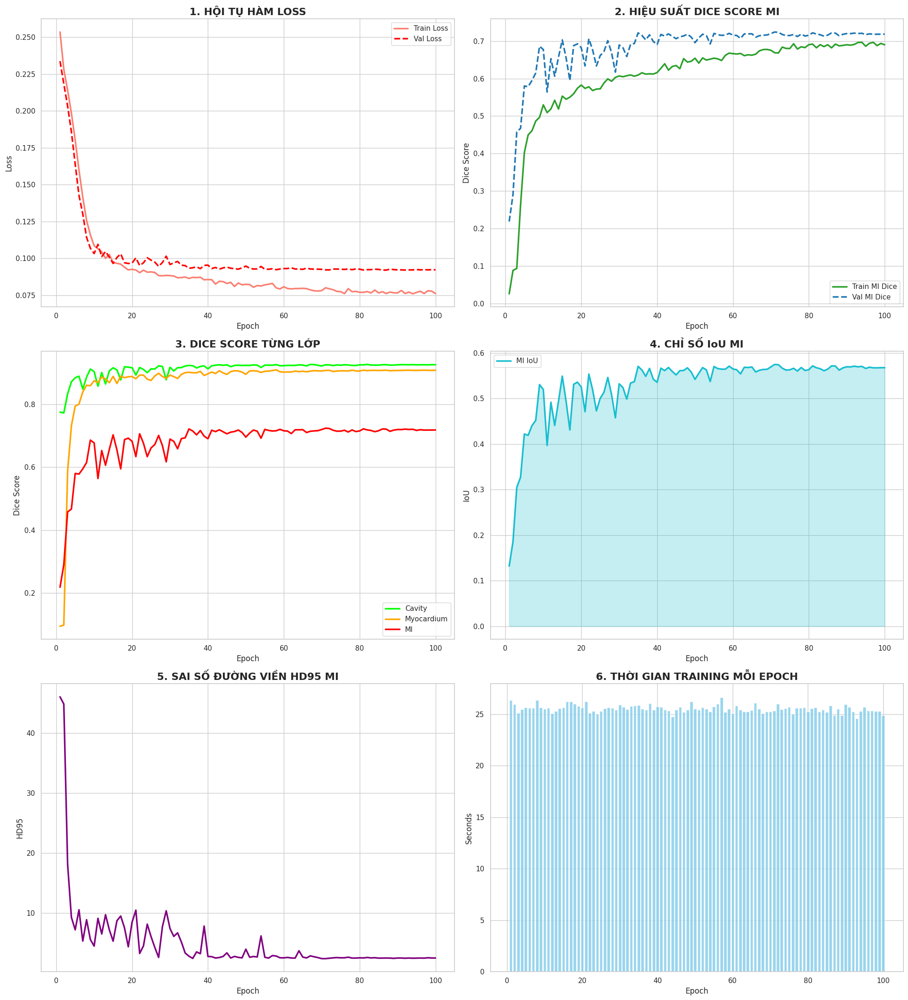


                BÁO CÁO KẾT QUẢ ATTENTION U-NET EMIDEC                
🏆 BEST EPOCH: 71
  > Train Loss                          :       0.0800
  > Validation Loss                     :       0.0921
  > Validation Cavity Dice              :       0.9254
  > Validation Myocardium Dice          :       0.9074
  > Validation MI Dice                  :       0.7240
  > Validation MI IoU                   :       0.5748
  > Validation MI HD95                  :         2.37
  > Training Time                       :     25.3 sec


In [6]:
# =========================================================
# FULL DASHBOARD REPORT
# ATTENTION U-NET EMIDEC MULTI-CLASS + GT PRIOR
# CSV: /kaggle/working/attunet_emidec_multiclass_gt_prior_log.csv
# =========================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

CSV_PATH = Path("/kaggle/working/attunet_emidec_multiclass_gt_prior_log.csv")
SAVE_DIR = Path("/kaggle/working/attunet_emidec_dashboard")

SAVE_DIR.mkdir(exist_ok=True)


def plot_dashboard_attunet_emidec(log_path):

    if not log_path.exists():
        print(f"❌ Không tìm thấy file log tại: {log_path}")
        return

    df = pd.read_csv(log_path)

    print(df.head())
    print(df.columns)

    sns.set_theme(style="whitegrid")

    fig, axes = plt.subplots(3, 2, figsize=(20, 22))
    plt.subplots_adjust(hspace=0.35, wspace=0.20)

    sns.lineplot(ax=axes[0, 0], data=df, x="Epoch", y="Train_Loss", label="Train Loss", color="salmon", linewidth=2.5)
    sns.lineplot(ax=axes[0, 0], data=df, x="Epoch", y="Val_Loss", label="Val Loss", color="red", linewidth=2.5, linestyle="--")
    axes[0, 0].set_title("1. HỘI TỤ HÀM LOSS", fontsize=16, fontweight="bold")
    axes[0, 0].set_xlabel("Epoch")
    axes[0, 0].set_ylabel("Loss")

    sns.lineplot(ax=axes[0, 1], data=df, x="Epoch", y="Train_Dice_MI", label="Train MI Dice", color="#2ca02c", linewidth=2.5)
    sns.lineplot(ax=axes[0, 1], data=df, x="Epoch", y="Val_Dice_MI", label="Val MI Dice", color="#1f77b4", linewidth=2.5, linestyle="--")
    axes[0, 1].set_title("2. HIỆU SUẤT DICE SCORE MI", fontsize=16, fontweight="bold")
    axes[0, 1].set_xlabel("Epoch")
    axes[0, 1].set_ylabel("Dice Score")

    sns.lineplot(ax=axes[1, 0], data=df, x="Epoch", y="Val_Dice_Cavity", label="Cavity", color="lime", linewidth=2.5)
    sns.lineplot(ax=axes[1, 0], data=df, x="Epoch", y="Val_Dice_Myo", label="Myocardium", color="orange", linewidth=2.5)
    sns.lineplot(ax=axes[1, 0], data=df, x="Epoch", y="Val_Dice_MI", label="MI", color="red", linewidth=2.5)
    axes[1, 0].set_title("3. DICE SCORE TỪNG LỚP", fontsize=16, fontweight="bold")
    axes[1, 0].set_xlabel("Epoch")
    axes[1, 0].set_ylabel("Dice Score")

    axes[1, 1].fill_between(df["Epoch"], df["Val_IoU_MI"], color="#17becf", alpha=0.25)
    axes[1, 1].plot(df["Epoch"], df["Val_IoU_MI"], color="#17becf", linewidth=2.5, label="MI IoU")
    axes[1, 1].set_title("4. CHỈ SỐ IoU MI", fontsize=16, fontweight="bold")
    axes[1, 1].set_xlabel("Epoch")
    axes[1, 1].set_ylabel("IoU")
    axes[1, 1].legend()

    sns.lineplot(ax=axes[2, 0], data=df, x="Epoch", y="Val_HD95_MI", color="purple", linewidth=2.5)
    axes[2, 0].set_title("5. SAI SỐ ĐƯỜNG VIỀN HD95 MI", fontsize=16, fontweight="bold")
    axes[2, 0].set_xlabel("Epoch")
    axes[2, 0].set_ylabel("HD95")

    axes[2, 1].bar(df["Epoch"], df["Time_s"], color="skyblue", alpha=0.85)
    axes[2, 1].set_title("6. THỜI GIAN TRAINING MỖI EPOCH", fontsize=16, fontweight="bold")
    axes[2, 1].set_xlabel("Epoch")
    axes[2, 1].set_ylabel("Seconds")

    plt.tight_layout()

    save_path = SAVE_DIR / "attunet_emidec_dashboard.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")

    print(f"\n✅ Đã lưu dashboard tại: {save_path}")

    plt.show()


def print_report_attunet_emidec(log_path):

    if not log_path.exists():
        print(f"❌ Không tìm thấy file log tại: {log_path}")
        return

    df = pd.read_csv(log_path)

    best_row = df.iloc[df["Val_Dice_MI"].idxmax()]

    print("\n" + "=" * 70)
    print(f"{'BÁO CÁO KẾT QUẢ ATTENTION U-NET EMIDEC':^70}")
    print("=" * 70)

    print(f"🏆 BEST EPOCH: {int(best_row['Epoch'])}")

    metrics = [
        ["Train Loss", f"{best_row['Train_Loss']:.4f}"],
        ["Validation Loss", f"{best_row['Val_Loss']:.4f}"],
        ["Validation Cavity Dice", f"{best_row['Val_Dice_Cavity']:.4f}"],
        ["Validation Myocardium Dice", f"{best_row['Val_Dice_Myo']:.4f}"],
        ["Validation MI Dice", f"{best_row['Val_Dice_MI']:.4f}"],
        ["Validation MI IoU", f"{best_row['Val_IoU_MI']:.4f}"],
        ["Validation MI HD95", f"{best_row['Val_HD95_MI']:.2f}"],
        ["Training Time", f"{best_row['Time_s']:.1f} sec"],
    ]

    for label, value in metrics:
        print(f"  > {label:<35} : {value:>12}")

    print("=" * 70)


plot_dashboard_attunet_emidec(CSV_PATH)
print_report_attunet_emidec(CSV_PATH)

In [7]:
# =========================================================
# FINAL TEST EVALUATION
# ATTENTION U-NET EMIDEC MULTI-CLASS + GT PRIOR
#
# Classes:
# 0 background
# 1 cavity
# 2 myocardium
# 3 MI
# =========================================================

import torch
import pandas as pd
from tqdm.auto import tqdm

from monai.metrics import (
    DiceMetric,
    MeanIoU,
    HausdorffDistanceMetric
)

from monai.data import Dataset, DataLoader

print("=" * 80)
print("FINAL TEST - ATTENTION U-NET EMIDEC MULTI-CLASS + GT PRIOR")
print("=" * 80)


# =========================================================
# TEST LOADER
# =========================================================

test_loader = DataLoader(
    Dataset(
        test_files,
        transform=val_transforms
    ),
    batch_size=1,
    shuffle=False
)


# =========================================================
# LOAD BEST MODEL
# =========================================================

from monai.networks.nets import AttentionUnet

model = AttentionUnet(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    dropout=0.2,
).to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_attunet_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


# =========================================================
# POST PROCESS
# =========================================================

post_pred = AsDiscrete(
    argmax=True,
    to_onehot=4
)

post_label = AsDiscrete(
    to_onehot=4
)


# =========================================================
# METRICS
# include_background=False:
# idx 0 = cavity
# idx 1 = myocardium
# idx 2 = MI
# =========================================================

test_dice_metric = DiceMetric(
    include_background=False,
    reduction="mean_batch"
)

test_iou_metric = MeanIoU(
    include_background=False,
    reduction="mean_batch"
)

test_hd95_metric = HausdorffDistanceMetric(
    include_background=False,
    percentile=95,
    reduction="mean_batch"
)


# =========================================================
# TEST LOOP
# =========================================================

with torch.no_grad():

    for batch in tqdm(
        test_loader,
        desc="Testing Attention U-Net"
    ):

        inputs = batch["attunet_input"].to(device)
        labels = batch["label"].to(device)

        outputs = model(inputs)

        if isinstance(outputs, (list, tuple)):
            outputs = outputs[0]

        preds = [post_pred(i) for i in outputs]
        gts = [post_label(i) for i in labels]

        test_dice_metric(y_pred=preds, y=gts)
        test_iou_metric(y_pred=preds, y=gts)
        test_hd95_metric(y_pred=preds, y=gts)


# =========================================================
# AGGREGATE RESULTS
# =========================================================

test_dice_cavity = safe_metric(test_dice_metric, 0)
test_dice_myo = safe_metric(test_dice_metric, 1)
test_dice_mi = safe_metric(test_dice_metric, 2)

test_iou_cavity = safe_metric(test_iou_metric, 0)
test_iou_myo = safe_metric(test_iou_metric, 1)
test_iou_mi = safe_metric(test_iou_metric, 2)

test_hd95_cavity = safe_metric(test_hd95_metric, 0)
test_hd95_myo = safe_metric(test_hd95_metric, 1)
test_hd95_mi = safe_metric(test_hd95_metric, 2)


# =========================================================
# PRINT FINAL REPORT
# =========================================================

print("\n" + "★" * 70)
print(f"{'KẾT QUẢ CHÍNH THỨC TRÊN TẬP TEST':^70}")
print("★" * 70)

print(f"\n🫀 CAVITY:")
print(f"   Dice : {test_dice_cavity * 100:.2f}%")
print(f"   IoU  : {test_iou_cavity * 100:.2f}%")
print(f"   HD95 : {test_hd95_cavity:.4f}")

print(f"\n🫀 MYOCARDIUM:")
print(f"   Dice : {test_dice_myo * 100:.2f}%")
print(f"   IoU  : {test_iou_myo * 100:.2f}%")
print(f"   HD95 : {test_hd95_myo:.4f}")

print(f"\n🩸 MI:")
print(f"   Dice : {test_dice_mi * 100:.2f}%")
print(f"   IoU  : {test_iou_mi * 100:.2f}%")
print(f"   HD95 : {test_hd95_mi:.4f}")

print("★" * 70)


# =========================================================
# SAVE TEST CSV
# =========================================================

test_summary = pd.DataFrame([
    {
        "Model": "AttentionUNet_GT_Prior",

        "Test_Dice_Cavity": test_dice_cavity,
        "Test_IoU_Cavity": test_iou_cavity,
        "Test_HD95_Cavity": test_hd95_cavity,

        "Test_Dice_Myo": test_dice_myo,
        "Test_IoU_Myo": test_iou_myo,
        "Test_HD95_Myo": test_hd95_myo,

        "Test_Dice_MI": test_dice_mi,
        "Test_IoU_MI": test_iou_mi,
        "Test_HD95_MI": test_hd95_mi,
    }
])

save_test_csv = "/kaggle/working/attunet_emidec_multiclass_gt_prior_test_results.csv"

test_summary.to_csv(
    save_test_csv,
    index=False
)

print(f"\n✅ Đã lưu test results tại:")
print(save_test_csv)

FINAL TEST - ATTENTION U-NET EMIDEC MULTI-CLASS + GT PRIOR


Testing Attention U-Net:   0%|          | 0/15 [00:00<?, ?it/s]


★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
                   KẾT QUẢ CHÍNH THỨC TRÊN TẬP TEST                   
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★

🫀 CAVITY:
   Dice : 91.77%
   IoU  : 84.83%
   HD95 : 1.9714

🫀 MYOCARDIUM:
   Dice : 87.30%
   IoU  : 78.09%
   HD95 : 2.4967

🩸 MI:
   Dice : 66.34%
   IoU  : 49.96%
   HD95 : 7.3268
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★

✅ Đã lưu test results tại:
/kaggle/working/attunet_emidec_multiclass_gt_prior_test_results.csv



🌟 TRỰC QUAN HÓA SỰ TIẾN HÓA ATTENTION - ATTENTION U-NET + GT PRIOR
[*] Selected case: Case_P067
Tổng số Conv3D layers: 27


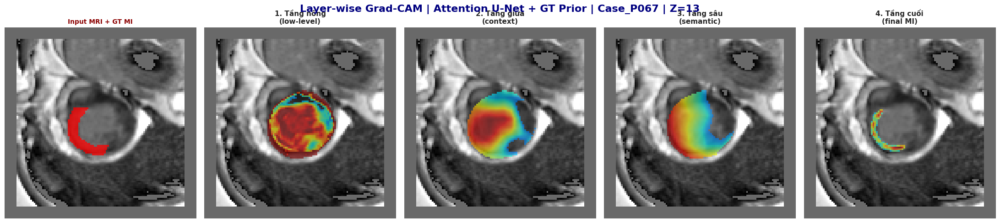

In [67]:
# ==============================================================================
# LAYER-WISE EVOLUTION
# ATTENTION U-NET MULTI-CLASS + GT PRIOR
# EMIDEC classes:
# 0 background | 1 cavity | 2 myocardium | 3 MI
# ==============================================================================

print("\n" + "=" * 80)
print("🌟 TRỰC QUAN HÓA SỰ TIẾN HÓA ATTENTION - ATTENTION U-NET + GT PRIOR")
print("=" * 80)

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.ndimage import zoom
from monai.networks.nets import AttentionUnet


# =========================================================
# LOAD MODEL
# =========================================================

model = AttentionUnet(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    dropout=0.2,
).to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_attunet_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


# =========================================================
# CUSTOM GRADCAM 3D
# =========================================================

class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.handle = self.target_layer.register_forward_hook(
            self.save_activation
        )

    def save_activation(self, module, input, output):
        self.activations = output.clone()

        if self.activations.requires_grad:
            self.activations.register_hook(self.save_gradient)

        return self.activations

    def save_gradient(self, grad):
        self.gradients = grad.clone()

    def remove_hooks(self):
        self.handle.remove()

    def generate_heatmap(self, input_tensor, class_idx=3):
        self.model.zero_grad(set_to_none=True)
        self.gradients = None
        self.activations = None

        output = self.model(input_tensor)

        if isinstance(output, (list, tuple)):
            output = output[0]

        score = output[:, class_idx].sum()
        score.backward()

        if self.gradients is None or self.activations is None:
            raise RuntimeError("Layer này không lấy được gradient, bỏ qua.")

        weights = torch.mean(
            self.gradients,
            dim=(2, 3, 4),
            keepdim=True
        )

        cam = torch.sum(
            weights * self.activations,
            dim=1
        ).squeeze(0)

        cam = F.relu(cam).detach().cpu().numpy()

        if cam.max() - cam.min() > 0:
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam


# =========================================================
# RANDOM MI CASE FROM TEST
# =========================================================

mi_cases = []

for sample_info in test_files:
    data = val_transforms(sample_info)

    if data["label"].max() == 3:
        mi_cases.append(sample_info)

if len(mi_cases) > 0:
    sample_info = random.choice(mi_cases)
else:
    sample_info = random.choice(test_files)

sample_data = val_transforms(sample_info)
case_name = sample_info["case_name"]

print(f"[*] Selected case: {case_name}")


# =========================================================
# PREPARE INPUT
# =========================================================

inputs = torch.as_tensor(
    sample_data["attunet_input"]
).unsqueeze(0).float().to(device)

labels = torch.as_tensor(
    sample_data["label"]
).unsqueeze(0).long().to(device)

# input channel 0 = MRI, channel 1 = GT prior
mri_vol = inputs[0, 0].detach().cpu().numpy()
prior_vol = inputs[0, 1].detach().cpu().numpy()
gt_array = labels[0, 0].detach().cpu().numpy()

z_scores = np.sum(gt_array == 3, axis=(0, 1))

if z_scores.max() > 0:
    z_slice = int(np.argmax(z_scores))
else:
    z_slice = gt_array.shape[2] // 2

mri_slice = mri_vol[:, :, z_slice]
prior_slice = prior_vol[:, :, z_slice]
gt_slice = gt_array[:, :, z_slice]


# =========================================================
# PREDICTION
# =========================================================

with torch.no_grad():
    outputs = model(inputs)

    if isinstance(outputs, (list, tuple)):
        outputs = outputs[0]

    pred = torch.argmax(
        outputs,
        dim=1
    ).detach().cpu().numpy()[0]

pred_slice = pred[:, :, z_slice]


# =========================================================
# TARGET LAYERS
# =========================================================

conv_layers = [
    m for m in model.modules()
    if isinstance(m, torch.nn.Conv3d)
]

print(f"Tổng số Conv3D layers: {len(conv_layers)}")

step = max(1, len(conv_layers) // 4)

target_layers = {
    "1. Tầng nông\n(low-level)": conv_layers[min(1, len(conv_layers) - 1)],
    "2. Tầng giữa\n(context)": conv_layers[len(conv_layers) // 2],
    "3. Tầng sâu\n(semantic)": conv_layers[-6] if len(conv_layers) >= 6 else conv_layers[-2],
    "4. Tầng cuối\n(final MI)": conv_layers[-1],
}


# =========================================================
# PLOT
# =========================================================

fig, axes = plt.subplots(
    1,
    len(target_layers) + 1,
    figsize=(22, 5)
)

fig.suptitle(
    f"Layer-wise Grad-CAM | Attention U-Net + GT Prior | {case_name} | Z={z_slice}",
    fontsize=16,
    fontweight="bold",
    color="navy"
)

# Column 0: input + GT MI
axes[0].imshow(
    np.rot90(mri_slice),
    cmap="gray"
)

gt_mi = np.ma.masked_where(
    gt_slice != 3,
    gt_slice
)

axes[0].imshow(
    np.rot90(gt_mi),
    cmap="autumn",
    alpha=0.75
)

axes[0].set_title(
    "Input MRI + GT MI",
    fontweight="bold",
    color="darkred",
    fontsize=10
)

axes[0].axis("off")


# =========================================================
# CAM PER LAYER
# =========================================================

for idx, (layer_title, layer_module) in enumerate(target_layers.items()):

    try:
        cam_engine = GradCAM3D(
            model=model,
            target_layer=layer_module
        )

        inputs_grad = inputs.clone().detach().requires_grad_(True)

        heat_small = cam_engine.generate_heatmap(
            inputs_grad,
            class_idx=3
        )

        cam_engine.remove_hooks()

        zoom_factor = (
            gt_array.shape[0] / heat_small.shape[0],
            gt_array.shape[1] / heat_small.shape[1],
            gt_array.shape[2] / heat_small.shape[2],
        )

        heat = zoom(
            heat_small,
            zoom_factor,
            order=1
        )

        if heat.max() > 0:
            heat = heat / heat.max()

        heat_slice = heat[:, :, z_slice]

        # Giữ đúng logic cũ:
        # gọt CAM bằng GT prior tim, không gọt bằng GT MI
        heat_slice = heat_slice * (prior_slice > 0.5)

        if heat_slice.max() > 0:
            heat_slice = heat_slice / heat_slice.max()

        # Giữ đúng logic cũ:
        # nếu vùng ngoài MI trong prior sáng hơn MI thì đảo lại
        if (gt_slice == 3).any():
            mi_intensity = heat_slice[gt_slice == 3].mean()

            bg_mask = (prior_slice > 0.5) & (gt_slice != 3)
            bg_intensity = heat_slice[bg_mask].mean() if bg_mask.any() else 0

            if bg_intensity > mi_intensity:
                heat_slice = (1.0 - heat_slice) * (prior_slice > 0.5)

                if heat_slice.max() > 0:
                    heat_slice = heat_slice / heat_slice.max()

        heat_masked = np.ma.masked_where(
            heat_slice < 0.25,
            heat_slice
        )

        ax = axes[idx + 1]

        ax.imshow(
            np.rot90(mri_slice),
            cmap="gray"
        )

        ax.imshow(
            np.rot90(heat_masked),
            cmap="jet",
            alpha=0.6,
            vmin=0,
            vmax=1
        )

        ax.set_title(
            layer_title,
            fontweight="bold",
            fontsize=11
        )

        ax.axis("off")

    except Exception as e:
        ax = axes[idx + 1]
        ax.imshow(
            np.rot90(mri_slice),
            cmap="gray"
        )
        ax.set_title(
            f"{layer_title}\nLỗi CAM",
            color="red",
            fontweight="bold"
        )
        ax.axis("off")

        print(f"Lỗi ở layer {layer_title}: {e}")


plt.tight_layout()
plt.show()

VISUALIZE + GRAD-CAM | ATTENTION U-NET + GT PRIOR
Selected case: Case_P017
Grad-CAM target layer: model.model.2.conv


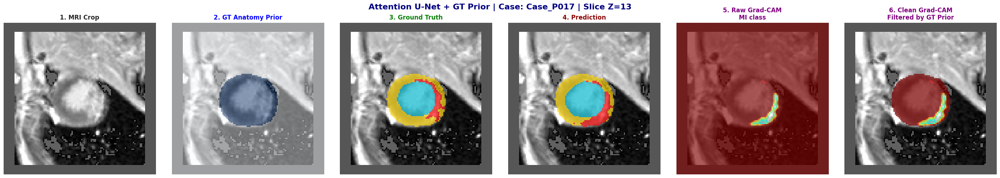

In [64]:
# =========================================================
# VISUALIZE + GRAD-CAM
# EMIDEC ATTENTION U-NET MULTI-CLASS + GT PRIOR
# class:
# 0 background | 1 cavity | 2 myocardium | 3 MI
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import torch
import torch.nn as nn
import random
from monai.visualize import GradCAM
from monai.networks.nets import AttentionUnet

print("=" * 80)
print("VISUALIZE + GRAD-CAM | ATTENTION U-NET + GT PRIOR")
print("=" * 80)

# =========================================================
# LOAD MODEL
# =========================================================

model = AttentionUnet(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    dropout=0.2,
).to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_attunet_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


# =========================================================
# WRAPPER
# =========================================================

class GradCAMWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        out = self.model(x)
        if isinstance(out, (list, tuple)):
            out = out[0]
        return out


wrapped_model = GradCAMWrapper(model).to(device)
wrapped_model.eval()


# =========================================================
# RANDOM CASE CÓ MI TRONG TEST
# =========================================================

mi_cases = []

for info in test_files:
    data = val_transforms(info)

    if data["label"].max() == 3:
        mi_cases.append(info)

sample_info = random.choice(mi_cases) if len(mi_cases) > 0 else random.choice(test_files)

sample_data = val_transforms(sample_info)
case_name = sample_info["case_name"]

print(f"Selected case: {case_name}")


# =========================================================
# INPUT
# =========================================================

inputs = torch.as_tensor(
    sample_data["attunet_input"]
).unsqueeze(0).float().to(device)

labels = torch.as_tensor(
    sample_data["label"]
).unsqueeze(0).long().to(device)

inputs.requires_grad_(True)

# channel 0 = MRI, channel 1 = GT prior
mri = inputs[0, 0].detach().cpu().numpy()
prior = inputs[0, 1].detach().cpu().numpy()
gt = labels[0, 0].detach().cpu().numpy()

z_scores = np.sum(gt == 3, axis=(0, 1))

if z_scores.max() > 0:
    z = int(np.argmax(z_scores))
else:
    z = gt.shape[2] // 2

mri_slice = mri[:, :, z]
prior_slice = prior[:, :, z]
gt_slice = gt[:, :, z]


# =========================================================
# PREDICTION
# =========================================================

with torch.no_grad():
    out = model(inputs)

    if isinstance(out, (list, tuple)):
        out = out[0]

    pred = torch.argmax(out, dim=1).cpu().numpy()[0]

pred_slice = pred[:, :, z]


# =========================================================
# GRAD-CAM
# =========================================================

conv_layer_names = [
    name for name, module in wrapped_model.named_modules()
    if isinstance(module, torch.nn.Conv3d)
]

target_layer = conv_layer_names[-1]

print("Grad-CAM target layer:", target_layer)

cam = GradCAM(
    nn_module=wrapped_model,
    target_layers=target_layer
)

# class_idx=3 vì class 3 = MI
heatmap = cam(
    x=inputs,
    class_idx=3
)

heat_slice = heatmap[0, 0, :, :, z].detach().cpu().numpy()

heat_slice = np.maximum(heat_slice, 0)

if heat_slice.max() > 0:
    heat_slice = heat_slice / heat_slice.max()

# Clean CAM bằng GT prior, không dùng GT MI
heat_clean = heat_slice * (prior_slice > 0.5)

if heat_clean.max() > 0:
    heat_clean = heat_clean / heat_clean.max()

heat_raw_masked = np.ma.masked_where(
    heat_slice < 0.35,
    heat_slice
)

heat_clean_masked = np.ma.masked_where(
    heat_clean < 0.35,
    heat_clean
)


# =========================================================
# VISUALIZE
# =========================================================

fig, axes = plt.subplots(1, 6, figsize=(28, 5))

fig.suptitle(
    f"Attention U-Net + GT Prior | Case: {case_name} | Slice Z={z}",
    fontsize=16,
    fontweight="bold",
    color="navy"
)

cmap_custom = mcolors.ListedColormap([
    "none",
    "#00bcd4",   # cavity
    "#ffd600",   # myocardium
    "#ff0000"    # MI
])

# 1. MRI
axes[0].imshow(np.rot90(mri_slice), cmap="gray")
axes[0].set_title("1. MRI Crop", fontweight="bold")
axes[0].axis("off")

# 2. GT prior
axes[1].imshow(np.rot90(mri_slice), cmap="gray")
axes[1].imshow(np.rot90(prior_slice), cmap="Blues", alpha=0.45)
axes[1].set_title("2. GT Anatomy Prior", fontweight="bold", color="blue")
axes[1].axis("off")

# 3. Ground truth
axes[2].imshow(np.rot90(mri_slice), cmap="gray")

gt_masked = np.ma.masked_where(
    gt_slice == 0,
    gt_slice
)

axes[2].imshow(
    np.rot90(gt_masked),
    cmap=cmap_custom,
    alpha=0.65,
    vmin=0,
    vmax=3
)

axes[2].set_title("3. Ground Truth", fontweight="bold", color="green")
axes[2].axis("off")

# 4. Prediction
axes[3].imshow(np.rot90(mri_slice), cmap="gray")

pred_masked = np.ma.masked_where(
    pred_slice == 0,
    pred_slice
)

axes[3].imshow(
    np.rot90(pred_masked),
    cmap=cmap_custom,
    alpha=0.65,
    vmin=0,
    vmax=3
)

axes[3].set_title("4. Prediction", fontweight="bold", color="darkred")
axes[3].axis("off")

# 5. Raw Grad-CAM
axes[4].imshow(np.rot90(mri_slice), cmap="gray")

axes[4].imshow(
    np.rot90(heat_raw_masked),
    cmap="jet",
    alpha=0.65,
    vmin=0,
    vmax=1
)

axes[4].set_title(
    "5. Raw Grad-CAM\nMI class",
    fontweight="bold",
    color="purple"
)

axes[4].axis("off")

# 6. Clean Grad-CAM
axes[5].imshow(np.rot90(mri_slice), cmap="gray")

axes[5].imshow(
    np.rot90(heat_clean_masked),
    cmap="jet",
    alpha=0.70,
    vmin=0,
    vmax=1
)

axes[5].set_title(
    "6. Clean Grad-CAM\nFiltered by GT Prior",
    fontweight="bold",
    color="purple"
)

axes[5].axis("off")

plt.tight_layout()
plt.show()


🚀 TRỰC QUAN HÓA ATTENTION CHO 3 BỆNH NHÂN - ATTENTION U-NET + GT PRIOR
Tổng số Conv3D layers: 27

[*] Đang phân tích bệnh nhân #1: Case_P063


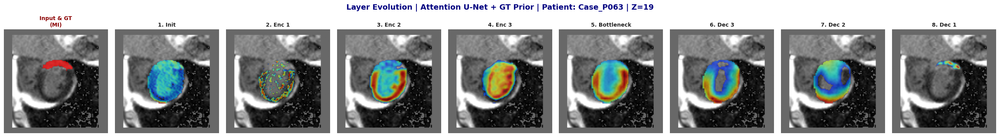


[*] Đang phân tích bệnh nhân #2: Case_P067


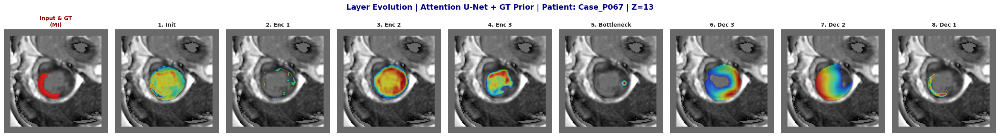


[*] Đang phân tích bệnh nhân #3: Case_P008


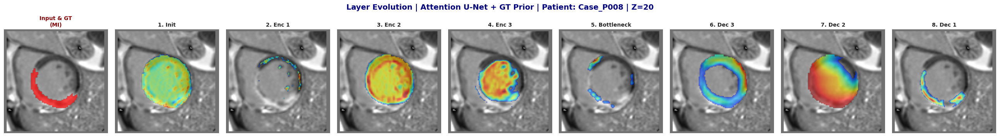

In [65]:
# ==============================================================================
# LAYER-WISE EVOLUTION
# ATTENTION U-NET MULTI-CLASS + GT PRIOR
# Dựa trên code SegResNet cũ, chỉ đổi model + input key + checkpoint
# ==============================================================================

import numpy as np
import random
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from scipy.ndimage import zoom
from monai.networks.nets import AttentionUnet

print("\n" + "=" * 80)
print("🚀 TRỰC QUAN HÓA ATTENTION CHO 3 BỆNH NHÂN - ATTENTION U-NET + GT PRIOR")
print("=" * 80)


class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.handle = self.target_layer.register_forward_hook(self.save_activation)

    def save_activation(self, module, input, output):
        self.activations = output.clone()

        if self.activations.requires_grad:
            self.activations.register_hook(self.save_gradient)

        return self.activations

    def save_gradient(self, grad):
        self.gradients = grad.clone()

    def remove_hooks(self):
        self.handle.remove()

    def generate_heatmap(self, input_tensor, class_idx=3):
        self.model.zero_grad(set_to_none=True)
        self.gradients = None
        self.activations = None

        output = self.model(input_tensor)

        if isinstance(output, (list, tuple)):
            output = output[0]

        score = output[:, class_idx].sum()
        score.backward()

        if self.gradients is None or self.activations is None:
            raise RuntimeError("Layer này không lấy được gradient, bỏ qua.")

        weights = torch.mean(
            self.gradients,
            dim=(2, 3, 4),
            keepdim=True
        )

        cam = torch.sum(
            weights * self.activations,
            dim=1
        ).squeeze(0)

        cam = F.relu(cam).detach().cpu().numpy()

        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam


def run_3_patients_evolution(model, test_files, device, transform):

    model.load_state_dict(
        torch.load(
            "/kaggle/working/best_attunet_emidec_multiclass_gt_prior.pth",
            map_location=device
        )
    )

    model.eval()

    conv_layers = [
        m for m in model.modules()
        if isinstance(m, torch.nn.Conv3d)
    ]

    print(f"Tổng số Conv3D layers: {len(conv_layers)}")

    step = max(1, len(conv_layers) // 8)

    target_layers = {
        "1. Init": conv_layers[0],
        "2. Enc 1": conv_layers[min(step * 1, len(conv_layers) - 1)],
        "3. Enc 2": conv_layers[min(step * 2, len(conv_layers) - 1)],
        "4. Enc 3": conv_layers[min(step * 3, len(conv_layers) - 1)],
        "5. Bottleneck": conv_layers[min(step * 4, len(conv_layers) - 1)],
        "6. Dec 3": conv_layers[-min(step * 4, len(conv_layers))],
        "7. Dec 2": conv_layers[-min(step * 2, len(conv_layers))],
        "8. Dec 1": conv_layers[-1],
    }

    mi_patients = []

    for info in test_files:
        data = transform(info)

        if data["label"].max() == 3:
            mi_patients.append((info, data))

    if not mi_patients:
        print("[!] Không có bệnh nhân nào có MI trong tập test.")
        return

    selected_patients = random.sample(
        mi_patients,
        min(3, len(mi_patients))
    )

    for p_idx, (info, data) in enumerate(selected_patients):

        print(f"\n[*] Đang phân tích bệnh nhân #{p_idx + 1}: {info['case_name']}")

        inputs = torch.as_tensor(
            data["attunet_input"]
        ).unsqueeze(0).float().to(device)

        labels = torch.as_tensor(
            data["label"]
        ).unsqueeze(0).long().to(device)

        # Channel 0 = MRI, Channel 1 = GT prior
        img_vol = inputs[0, 0].detach().cpu().numpy()
        prior_vol = inputs[0, 1].detach().cpu().numpy()
        gt_array = labels[0, 0].detach().cpu().numpy()

        z_scores = np.sum(gt_array == 3, axis=(0, 1))

        if z_scores.max() > 0:
            z_slice = int(np.argmax(z_scores))
        else:
            z_slice = gt_array.shape[2] // 2

        img_slice = img_vol[:, :, z_slice]
        prior_slice = prior_vol[:, :, z_slice]
        gt_slice = gt_array[:, :, z_slice]

        fig, axes = plt.subplots(
            1,
            len(target_layers) + 1,
            figsize=(26, 3.8)
        )

        fig.suptitle(
            f"Layer Evolution | Attention U-Net + GT Prior | Patient: {info['case_name']} | Z={z_slice}",
            fontsize=14,
            fontweight="bold",
            color="navy"
        )

        axes[0].imshow(np.rot90(img_slice), cmap="gray")

        gt_mask = np.ma.masked_where(
            gt_slice != 3,
            gt_slice
        )

        axes[0].imshow(
            np.rot90(gt_mask),
            cmap="autumn",
            alpha=0.7
        )

        axes[0].set_title(
            "Input & GT\n(MI)",
            fontweight="bold",
            color="darkred",
            fontsize=10
        )

        axes[0].axis("off")

        for i, (layer_name, layer_module) in enumerate(target_layers.items()):

            ax = axes[i + 1]
            cam_extractor = None

            try:
                cam_extractor = GradCAM3D(
                    model=model,
                    target_layer=layer_module
                )

                img_grad = inputs.clone().detach().requires_grad_(True)

                heat_small = cam_extractor.generate_heatmap(
                    img_grad,
                    class_idx=3
                )

                cam_extractor.remove_hooks()

                zoom_factor = (
                    gt_array.shape[0] / heat_small.shape[0],
                    gt_array.shape[1] / heat_small.shape[1],
                    gt_array.shape[2] / heat_small.shape[2],
                )

                heat = zoom(
                    heat_small,
                    zoom_factor,
                    order=1
                )

                if heat.max() > 0:
                    heat = heat / heat.max()

                heat_slice = heat[:, :, z_slice]

                # Gọt sạch nhiễu bằng GT prior tim, không dùng GT MI
                heat_slice = heat_slice * (prior_slice > 0.5)

                if heat_slice.max() > 0:
                    heat_slice = heat_slice / heat_slice.max()

                # Logic đảo màu như code cũ
                if i >= 6 and (gt_slice == 3).any():
                    scar_int = heat_slice[gt_slice == 3].mean()

                    bg_mask = (prior_slice > 0.5) & (gt_slice != 3)
                    bg_int = heat_slice[bg_mask].mean() if bg_mask.any() else 0

                    if bg_int > scar_int:
                        heat_slice = (1.0 - heat_slice) * (prior_slice > 0.5)

                        if heat_slice.max() > 0:
                            heat_slice = heat_slice / heat_slice.max()

                heat_slice_masked = np.ma.masked_where(
                    heat_slice < 0.15,
                    heat_slice
                )

                ax.imshow(np.rot90(img_slice), cmap="gray")

                ax.imshow(
                    np.rot90(heat_slice_masked),
                    cmap="jet",
                    alpha=0.6,
                    vmin=0,
                    vmax=1
                )

                ax.set_title(
                    layer_name,
                    fontsize=10,
                    fontweight="bold"
                )

            except Exception as e:
                if cam_extractor is not None:
                    try:
                        cam_extractor.remove_hooks()
                    except:
                        pass

                ax.imshow(np.rot90(img_slice), cmap="gray")
                ax.set_title(
                    f"{layer_name}\n[Bỏ qua]",
                    color="gray",
                    fontsize=9
                )

                print(f"Lỗi layer {layer_name}: {e}")

            ax.axis("off")

        plt.tight_layout()
        plt.show()


model = AttentionUnet(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    dropout=0.2,
).to(device)


run_3_patients_evolution(
    model=model,
    test_files=test_files,
    device=device,
    transform=val_transforms
)


🧠 UNCERTAINTY MAP - ATTENTION U-NET + GT PRIOR
[*] Đang chạy MC Dropout (T=15) cho 3 bệnh nhân...

[*] Đang phân tích: Case_P091


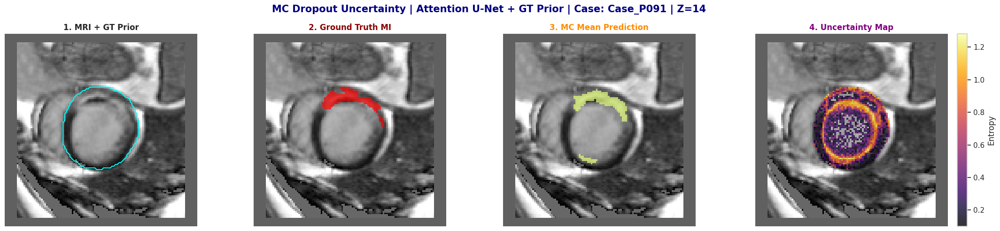


[*] Đang phân tích: Case_P067


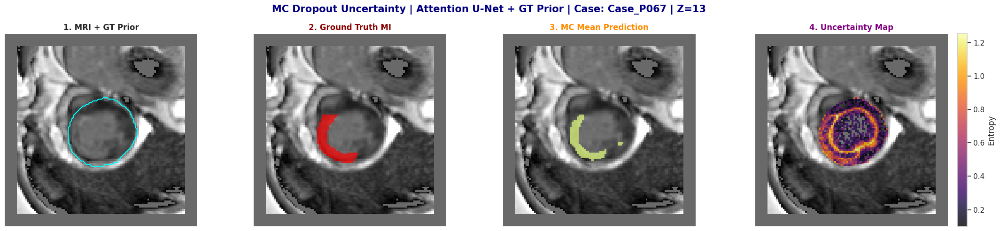


[*] Đang phân tích: Case_P081


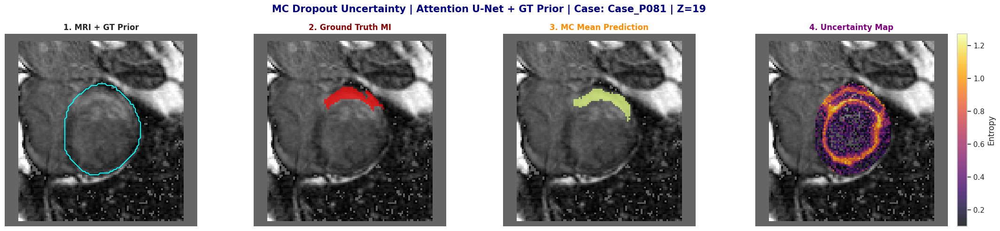

In [68]:
# ==============================================================================
# 🧠 MC DROPOUT UNCERTAINTY MAP
# ATTENTION U-NET MULTI-CLASS + GT PRIOR
#
# Classes:
# 0 background
# 1 cavity
# 2 myocardium
# 3 MI
# ==============================================================================

import numpy as np
import random
import matplotlib.pyplot as plt
import torch

from monai.networks.nets import AttentionUnet

print("\n" + "=" * 80)
print("🧠 UNCERTAINTY MAP - ATTENTION U-NET + GT PRIOR")
print("=" * 80)


# =========================================================
# LOAD MODEL
# =========================================================

model = AttentionUnet(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    dropout=0.2,
).to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_attunet_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


# =========================================================
# ENABLE DROPOUT ONLY
# =========================================================

def enable_dropout_only(m):
    if isinstance(
        m,
        (
            torch.nn.Dropout,
            torch.nn.Dropout2d,
            torch.nn.Dropout3d
        )
    ):
        m.train()


# =========================================================
# MC DROPOUT
# =========================================================

def compute_uncertainty_mc_dropout(
    model,
    attunet_input,
    T=15
):
    model.eval()
    model.apply(enable_dropout_only)

    outputs = []

    with torch.no_grad():
        for _ in range(T):

            logits = model(attunet_input)

            if isinstance(logits, (list, tuple)):
                logits = logits[0]

            probs = torch.softmax(logits, dim=1)
            outputs.append(probs)

    outputs = torch.stack(outputs)

    mean_prob = torch.mean(outputs, dim=0)

    epsilon = 1e-6

    uncertainty_map = -torch.sum(
        mean_prob * torch.log(mean_prob + epsilon),
        dim=1
    )

    # Channel 1 = GT anatomy prior
    mask_tim = attunet_input[:, 1, ...]

    uncertainty_map = uncertainty_map * mask_tim

    model.eval()

    return mean_prob, uncertainty_map


# =========================================================
# VISUALIZE
# =========================================================

def visualize_uncertainty_xai(
    model,
    test_files,
    device,
    transform,
    num_samples=3
):

    print(f"[*] Đang chạy MC Dropout (T=15) cho {num_samples} bệnh nhân...")

    mi_patients = []

    for info in test_files:
        data = transform(info)

        if data["label"].max() == 3:
            mi_patients.append((info, data))

    if not mi_patients:
        print("[!] Không có bệnh nhân MI trong tập test.")
        return

    selected_patients = random.sample(
        mi_patients,
        min(num_samples, len(mi_patients))
    )

    for p_idx, (info, data) in enumerate(selected_patients):

        print(f"\n[*] Đang phân tích: {info['case_name']}")

        inputs = torch.as_tensor(
            data["attunet_input"]
        ).unsqueeze(0).float().to(device)

        labels = torch.as_tensor(
            data["label"]
        ).unsqueeze(0).long().to(device)

        mean_prob, unc_map = compute_uncertainty_mc_dropout(
            model,
            inputs,
            T=15
        )

        pred_mask = torch.argmax(
            mean_prob,
            dim=1
        ).cpu().numpy()[0]

        unc_map_np = unc_map.cpu().numpy()[0]

        gt_array = labels[0, 0].cpu().numpy()

        z_scores = np.sum(gt_array == 3, axis=(0, 1))

        if z_scores.max() > 0:
            z_slice = int(np.argmax(z_scores))
        else:
            z_slice = gt_array.shape[2] // 2

        img_slice = inputs[0, 0, :, :, z_slice].cpu().numpy()
        mask_tim_slice = inputs[0, 1, :, :, z_slice].cpu().numpy()

        gt_slice = gt_array[:, :, z_slice]
        pred_slice = pred_mask[:, :, z_slice]
        unc_slice = unc_map_np[:, :, z_slice]

        unc_slice_masked = np.ma.masked_where(
            unc_slice < 0.10,
            unc_slice
        )

        fig, axes = plt.subplots(
            1,
            4,
            figsize=(22, 5)
        )

        fig.suptitle(
            f"MC Dropout Uncertainty | Attention U-Net + GT Prior | Case: {info['case_name']} | Z={z_slice}",
            fontsize=15,
            fontweight="bold",
            color="navy"
        )

        axes[0].imshow(np.rot90(img_slice), cmap="gray")
        axes[0].contour(
            np.rot90(mask_tim_slice),
            colors="cyan",
            levels=[0.5],
            linewidths=1.5
        )
        axes[0].set_title("1. MRI + GT Prior", fontweight="bold")
        axes[0].axis("off")

        axes[1].imshow(np.rot90(img_slice), cmap="gray")
        gt_masked = np.ma.masked_where(gt_slice != 3, gt_slice)
        axes[1].imshow(
            np.rot90(gt_masked),
            cmap="autumn",
            alpha=0.7
        )
        axes[1].set_title(
            "2. Ground Truth MI",
            fontweight="bold",
            color="darkred"
        )
        axes[1].axis("off")

        axes[2].imshow(np.rot90(img_slice), cmap="gray")
        pred_masked = np.ma.masked_where(pred_slice != 3, pred_slice)
        axes[2].imshow(
            np.rot90(pred_masked),
            cmap="Wistia",
            alpha=0.7
        )
        axes[2].set_title(
            "3. MC Mean Prediction",
            fontweight="bold",
            color="darkorange"
        )
        axes[2].axis("off")

        axes[3].imshow(np.rot90(img_slice), cmap="gray")
        im_unc = axes[3].imshow(
            np.rot90(unc_slice_masked),
            cmap="inferno",
            alpha=0.8
        )
        axes[3].set_title(
            "4. Uncertainty Map",
            fontweight="bold",
            color="purple"
        )
        axes[3].axis("off")

        plt.colorbar(
            im_unc,
            ax=axes[3],
            fraction=0.046,
            pad=0.04,
            label="Entropy"
        )

        plt.tight_layout()
        plt.show()


visualize_uncertainty_xai(
    model=model,
    test_files=test_files,
    device=device,
    transform=val_transforms,
    num_samples=3
)


🔬 TRỰC QUAN HÓA GRAD-CAM & PREDICTION - ATTENTION U-NET + GT PRIOR
[*] Selected case: Case_P001
[*] Grad-CAM target layer: model.model.2.conv


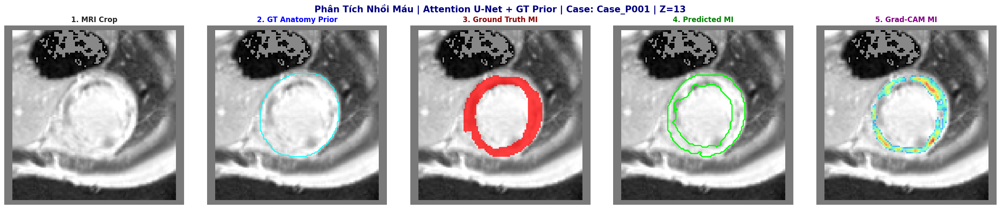

In [69]:
# =========================================================
# VISUALIZE PREDICTION + GRAD-CAM
# ATTENTION U-NET MULTI-CLASS + GT PRIOR
# 0 background | 1 cavity | 2 myocardium | 3 MI
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import random
from monai.visualize import GradCAM
from monai.networks.nets import AttentionUnet

print("\n" + "=" * 80)
print("🔬 TRỰC QUAN HÓA GRAD-CAM & PREDICTION - ATTENTION U-NET + GT PRIOR")
print("=" * 80)

# =========================================================
# LOAD MODEL
# =========================================================

model = AttentionUnet(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    dropout=0.2,
).to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_attunet_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


# =========================================================
# WRAPPER CHO MONAI GRADCAM
# =========================================================

class GradCAMWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        out = self.model(x)
        if isinstance(out, (list, tuple)):
            out = out[0]
        return out


wrapped_model = GradCAMWrapper(model).to(device)
wrapped_model.eval()


# =========================================================
# FIND RANDOM MI CASE
# =========================================================

mi_cases = []

for info in test_files:
    data = val_transforms(info)

    if data["label"].max() == 3:
        mi_cases.append(info)

sample_info = random.choice(mi_cases) if len(mi_cases) > 0 else random.choice(test_files)

sample_data = val_transforms(sample_info)
case_name = sample_info["case_name"]

print(f"[*] Selected case: {case_name}")


# =========================================================
# PREPARE INPUT
# =========================================================

inputs = torch.as_tensor(
    sample_data["attunet_input"]
).unsqueeze(0).float().to(device)

labels = torch.as_tensor(
    sample_data["label"]
).unsqueeze(0).long().to(device)

inputs.requires_grad_(True)

# Channel 0 = MRI, channel 1 = GT prior
img_vol = inputs[0, 0].detach().cpu().numpy()
prior_vol = inputs[0, 1].detach().cpu().numpy()
gt_array = labels[0, 0].detach().cpu().numpy()

z_scores = np.sum(gt_array == 3, axis=(0, 1))

if z_scores.max() > 0:
    z_slice = int(np.argmax(z_scores))
else:
    z_slice = gt_array.shape[2] // 2

img_slice = img_vol[:, :, z_slice]
prior_slice = prior_vol[:, :, z_slice]
gt_slice = gt_array[:, :, z_slice]


# =========================================================
# PREDICTION
# =========================================================

with torch.no_grad():
    outputs = model(inputs)

    if isinstance(outputs, (list, tuple)):
        outputs = outputs[0]

    preds = torch.argmax(outputs, dim=1).detach().cpu().numpy()[0]

pred_slice = preds[:, :, z_slice]


# =========================================================
# GRAD-CAM
# =========================================================

conv_layer_names = [
    name for name, module in wrapped_model.named_modules()
    if isinstance(module, torch.nn.Conv3d)
]

target_layer = conv_layer_names[-1]

print(f"[*] Grad-CAM target layer: {target_layer}")

cam = GradCAM(
    nn_module=wrapped_model,
    target_layers=target_layer
)

heatmap = cam(
    x=inputs,
    class_idx=3
)

heat_slice = heatmap[0, 0, :, :, z_slice].detach().cpu().numpy()

heat_slice = np.maximum(heat_slice, 0)

if heat_slice.max() > 0:
    heat_slice = heat_slice / heat_slice.max()

# Gọt nhiễu bằng GT prior tim, không dùng GT MI
heat_slice = heat_slice * (prior_slice > 0.5)

if heat_slice.max() > 0:
    heat_slice = heat_slice / heat_slice.max()

# Logic đảo màu giống code cũ
if (gt_slice == 3).any():
    mi_intensity = heat_slice[gt_slice == 3].mean()

    bg_mask = (prior_slice > 0.5) & (gt_slice != 3)
    bg_intensity = heat_slice[bg_mask].mean() if bg_mask.any() else 0

    if bg_intensity > mi_intensity:
        heat_slice = (1.0 - heat_slice) * (prior_slice > 0.5)

        if heat_slice.max() > 0:
            heat_slice = heat_slice / heat_slice.max()

heat_slice_masked = np.ma.masked_where(
    heat_slice < 0.25,
    heat_slice
)


# =========================================================
# VISUALIZATION
# =========================================================

fig, axes = plt.subplots(1, 5, figsize=(24, 5))

fig.suptitle(
    f"Phân Tích Nhồi Máu | Attention U-Net + GT Prior | Case: {case_name} | Z={z_slice}",
    fontsize=15,
    fontweight="bold",
    color="navy"
)

axes[0].imshow(np.rot90(img_slice), cmap="gray")
axes[0].set_title("1. MRI Crop", fontweight="bold")
axes[0].axis("off")

axes[1].imshow(np.rot90(img_slice), cmap="gray")
axes[1].contour(
    np.rot90(prior_slice),
    colors="cyan",
    levels=[0.5],
    linewidths=1.5
)
axes[1].set_title("2. GT Anatomy Prior", fontweight="bold", color="blue")
axes[1].axis("off")

axes[2].imshow(np.rot90(img_slice), cmap="gray")
gt_mi_mask = np.ma.masked_where(gt_slice != 3, gt_slice)
axes[2].imshow(np.rot90(gt_mi_mask), cmap="autumn", alpha=0.75)
axes[2].set_title("3. Ground Truth MI", fontweight="bold", color="darkred")
axes[2].axis("off")

axes[3].imshow(np.rot90(img_slice), cmap="gray")
pred_mi_only = (pred_slice == 3).astype(np.uint8)
if pred_mi_only.max() > 0:
    axes[3].contour(
        np.rot90(pred_mi_only),
        colors="lime",
        levels=[0.5],
        linewidths=2
    )
axes[3].set_title("4. Predicted MI", fontweight="bold", color="green")
axes[3].axis("off")

axes[4].imshow(np.rot90(img_slice), cmap="gray")
axes[4].imshow(
    np.rot90(heat_slice_masked),
    cmap="jet",
    alpha=0.65,
    vmin=0,
    vmax=1
)
axes[4].set_title("5. Grad-CAM MI", fontweight="bold", color="purple")
axes[4].axis("off")

plt.tight_layout()
plt.show()

# GT UNET ++

In [8]:
# =========================================================
# EMIDEC 2020
# MULTI-CLASS UNET++ / BASICUNETPLUSPLUS
# GT CROP + GT PRIOR
# =========================================================

import os, glob, time, random, csv, warnings
import numpy as np
import nibabel as nib
import torch

warnings.filterwarnings("ignore")

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

from monai.utils import set_determinism
from monai.data import Dataset, DataLoader
from monai.networks.nets import BasicUNetPlusPlus
from monai.losses import DiceFocalLoss
from monai.metrics import DiceMetric, MeanIoU, HausdorffDistanceMetric
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, Spacingd,
    ScaleIntensityRangePercentilesd, NormalizeIntensityd,
    Lambdad, ResizeWithPadOrCropd, CropForegroundd,
    ConcatItemsd, RandFlipd, RandAffined, ToTensord, AsDiscrete
)
from torch.optim.lr_scheduler import CosineAnnealingLR


# =========================================================
# CONFIG
# =========================================================

SEED = 43
set_determinism(seed=SEED)
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

EMIDEC_RAW_DIR = "/kaggle/input/datasets/ngdutrong/emicdec-2020-dataset/emidec-dataset-1.0.1/"
GT_CROPPED_DIR = "/kaggle/working/EMIDEC_GT_Cropped_UNetPP_MultiClass/"

os.makedirs(GT_CROPPED_DIR, exist_ok=True)

NUM_CLASSES = 4
MAX_EPOCHS = 100

SPATIAL_SIZE_RAW = (128, 128, 24)
SPATIAL_SIZE_CROP = (112, 112, 32)

csv_path = "/kaggle/working/unetpp_emidec_multiclass_gt_prior_log.csv"
best_model_path = "/kaggle/working/best_unetpp_emidec_multiclass_gt_prior.pth"


# =========================================================
# LABEL FUNCTIONS
# =========================================================

def make_gt_heart_prior(x):
    return (x > 0).to(torch.float32)


def remap_emidec_multiclass(x):
    y = torch.zeros_like(x).long()
    y[x == 1] = 1
    y[x == 2] = 2
    y[x >= 3] = 3
    return y


def safe_metric(metric, idx=0):
    try:
        val = metric.aggregate()
        if hasattr(val, "shape") and len(val.shape) > 0:
            val = val[idx]
        val = val.item()
        if np.isnan(val) or np.isinf(val):
            return 0.0
        return val
    except Exception:
        return 0.0


# =========================================================
# RAW DATA LIST
# =========================================================

def get_raw_emidec_datalist(emidec_dir):
    data_list = []
    cases = glob.glob(os.path.join(emidec_dir, "Case_*"))

    for case_folder in cases:
        case_name = os.path.basename(case_folder)

        img_paths = [
            p for p in glob.glob(
                os.path.join(case_folder, f"Images/**/{case_name}.nii*"),
                recursive=True,
            )
            if os.path.isfile(p)
        ]

        lbl_paths = [
            p for p in glob.glob(
                os.path.join(case_folder, f"Contours/**/{case_name}.nii*"),
                recursive=True,
            )
            if os.path.isfile(p)
        ]

        if img_paths and lbl_paths:
            if os.path.getsize(img_paths[0]) > 0 and os.path.getsize(lbl_paths[0]) > 0:
                data_list.append({
                    "image": img_paths[0],
                    "label": lbl_paths[0],
                    "case_name": case_name,
                })

    return sorted(data_list, key=lambda x: x["case_name"])


all_raw_files = get_raw_emidec_datalist(EMIDEC_RAW_DIR)

if len(all_raw_files) == 0:
    raise ValueError("Không tìm thấy dữ liệu EMIDEC.")

print(f"Total raw cases: {len(all_raw_files)}")


# =========================================================
# GT CROP ALL CASES
# =========================================================

print("=" * 80)
print("GT CROP ALL CASES")
print("=" * 80)

prep_transforms = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image", "label"]),

    Spacingd(
        keys=["image", "label"],
        pixdim=(1.5, 1.5, 5.0),
        mode=("bilinear", "nearest"),
    ),

    ScaleIntensityRangePercentilesd(
        keys=["image"],
        lower=1,
        upper=99,
        b_min=0.0,
        b_max=1.0,
        clip=True,
    ),

    NormalizeIntensityd(
        keys=["image"],
        nonzero=True,
        channel_wise=True,
    ),

    ResizeWithPadOrCropd(
        keys=["image", "label"],
        spatial_size=SPATIAL_SIZE_RAW,
        mode="constant",
    ),
])

crop_by_gt = Compose([
    CropForegroundd(
        keys=["image", "label", "mask_prior"],
        source_key="mask_prior",
        margin=25,
    ),

    ResizeWithPadOrCropd(
        keys=["image", "label", "mask_prior"],
        spatial_size=SPATIAL_SIZE_CROP,
        mode="constant",
    ),
])


def crop_and_save_all_cases(raw_files):
    cropped_files = []

    for item in tqdm(raw_files, desc="Cropping by GT mask"):
        data = prep_transforms({
            "image": item["image"],
            "label": item["label"],
        })

        gt_prior = make_gt_heart_prior(data["label"])
        data["mask_prior"] = gt_prior

        if torch.sum(gt_prior) == 0:
            continue

        cropped = crop_by_gt(data)

        case_out_dir = os.path.join(GT_CROPPED_DIR, item["case_name"])
        os.makedirs(case_out_dir, exist_ok=True)

        affine = data["image"].meta.get("affine", np.eye(4))

        image_path = os.path.join(case_out_dir, "image.nii.gz")
        label_path = os.path.join(case_out_dir, "label.nii.gz")
        prior_path = os.path.join(case_out_dir, "mask_prior.nii.gz")

        nib.save(nib.Nifti1Image(cropped["image"][0].numpy(), affine), image_path)
        nib.save(nib.Nifti1Image(cropped["label"][0].numpy(), affine), label_path)
        nib.save(nib.Nifti1Image(cropped["mask_prior"][0].numpy(), affine), prior_path)

        cropped_files.append({
            "image": image_path,
            "label": label_path,
            "mask_prior": prior_path,
            "case_name": item["case_name"],
        })

    return sorted(cropped_files, key=lambda x: x["case_name"])


all_cropped_files = crop_and_save_all_cases(all_raw_files)
print(f"Cropped cases: {len(all_cropped_files)}")


# =========================================================
# HARD SPLIT AFTER CROP
# =========================================================

print("=" * 80)
print("HARD SPLIT AFTER CROP")
print("=" * 80)

train_val_files, test_files = train_test_split(
    all_cropped_files,
    test_size=0.15,
    random_state=42,
    shuffle=True,
)

train_files, val_files = train_test_split(
    train_val_files,
    test_size=(15 / 85),
    random_state=42,
    shuffle=True,
)

print(f"Train: {len(train_files)}")
print(f"Val  : {len(val_files)}")
print(f"Test : {len(test_files)}")


# =========================================================
# TRANSFORMS
# =========================================================

train_transforms = Compose([
    LoadImaged(keys=["image", "label", "mask_prior"]),
    EnsureChannelFirstd(keys=["image", "label", "mask_prior"]),

    ScaleIntensityRangePercentilesd(
        keys=["image"],
        lower=1,
        upper=99,
        b_min=0.0,
        b_max=1.0,
        clip=True,
    ),

    NormalizeIntensityd(
        keys=["image"],
        nonzero=True,
        channel_wise=True,
    ),

    Lambdad(
        keys=["label"],
        func=remap_emidec_multiclass,
    ),

    ConcatItemsd(
        keys=["image", "mask_prior"],
        name="unetpp_input",
        dim=0,
    ),

    RandAffined(
        keys=["unetpp_input", "label"],
        prob=0.4,
        rotate_range=(0.15, 0.15, 0.15),
        scale_range=(0.08, 0.08, 0.08),
        mode=("bilinear", "nearest"),
    ),

    RandFlipd(
        keys=["unetpp_input", "label"],
        spatial_axis=[0, 1],
        prob=0.5,
    ),

    ToTensord(keys=["unetpp_input", "label"]),
])

val_transforms = Compose([
    LoadImaged(keys=["image", "label", "mask_prior"]),
    EnsureChannelFirstd(keys=["image", "label", "mask_prior"]),

    ScaleIntensityRangePercentilesd(
        keys=["image"],
        lower=1,
        upper=99,
        b_min=0.0,
        b_max=1.0,
        clip=True,
    ),

    NormalizeIntensityd(
        keys=["image"],
        nonzero=True,
        channel_wise=True,
    ),

    Lambdad(
        keys=["label"],
        func=remap_emidec_multiclass,
    ),

    ConcatItemsd(
        keys=["image", "mask_prior"],
        name="unetpp_input",
        dim=0,
    ),

    ToTensord(keys=["unetpp_input", "label"]),
])


# =========================================================
# DATALOADERS
# =========================================================

train_loader = DataLoader(
    Dataset(train_files, transform=train_transforms),
    batch_size=2,
    shuffle=True,
)

val_loader = DataLoader(
    Dataset(val_files, transform=val_transforms),
    batch_size=1,
    shuffle=False,
)

test_loader = DataLoader(
    Dataset(test_files, transform=val_transforms),
    batch_size=1,
    shuffle=False,
)


# =========================================================
# MODEL: UNET++
# =========================================================

model = BasicUNetPlusPlus(
    spatial_dims=3,
    in_channels=2,
    out_channels=NUM_CLASSES,
    features=(16, 32, 64, 128, 256, 16),
    dropout=0.2,
    deep_supervision=False,
).to(device)


class_weights = torch.tensor(
    [0.05, 0.15, 0.25, 0.55],
    dtype=torch.float32,
).to(device)

loss_fn = DiceFocalLoss(
    to_onehot_y=True,
    softmax=True,
    gamma=2.0,
    weight=class_weights,
    squared_pred=True,
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=8e-4,
    weight_decay=1e-4,
)

scheduler = CosineAnnealingLR(
    optimizer,
    T_max=MAX_EPOCHS,
    eta_min=1e-6,
)

post_pred = AsDiscrete(
    argmax=True,
    to_onehot=NUM_CLASSES,
)

post_label = AsDiscrete(
    to_onehot=NUM_CLASSES,
)

best_val_mi_dice = -1.0


# =========================================================
# INIT CSV
# =========================================================

with open(csv_path, mode="w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "Epoch",
        "Train_Loss",
        "Val_Loss",

        "Train_Dice_Cavity",
        "Train_Dice_Myo",
        "Train_Dice_MI",

        "Val_Dice_Cavity",
        "Val_Dice_Myo",
        "Val_Dice_MI",

        "Val_IoU_MI",
        "Val_HD95_MI",

        "Time_s",
    ])


# =========================================================
# TRAINING LOOP
# =========================================================

for epoch in range(MAX_EPOCHS):
    start_time = time.time()

    model.train()

    train_loss = 0.0
    step = 0

    train_dice_metric = DiceMetric(
        include_background=False,
        reduction="mean_batch",
    )

    for batch in tqdm(
        train_loader,
        desc=f"UNet++ EP {epoch + 1:03d}/{MAX_EPOCHS} [Train]",
    ):
        step += 1

        inputs = batch["unetpp_input"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad()

        outputs = model(inputs)

        if isinstance(outputs, (list, tuple)):
            outputs = outputs[0]

        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        preds = [post_pred(i) for i in outputs.detach()]
        gts = [post_label(i) for i in labels]

        train_dice_metric(y_pred=preds, y=gts)

    train_loss /= max(step, 1)

    train_dice_cavity = safe_metric(train_dice_metric, 0)
    train_dice_myo = safe_metric(train_dice_metric, 1)
    train_dice_mi = safe_metric(train_dice_metric, 2)

    scheduler.step()

    model.eval()

    val_loss = 0.0
    val_step = 0

    val_dice_metric = DiceMetric(
        include_background=False,
        reduction="mean_batch",
    )

    val_iou_metric = MeanIoU(
        include_background=False,
        reduction="mean_batch",
    )

    val_hd95_metric = HausdorffDistanceMetric(
        include_background=False,
        percentile=95,
        reduction="mean_batch",
    )

    with torch.no_grad():
        for batch in val_loader:
            val_step += 1

            inputs = batch["unetpp_input"].to(device)
            labels = batch["label"].to(device)

            outputs = model(inputs)

            if isinstance(outputs, (list, tuple)):
                outputs = outputs[0]

            val_loss += loss_fn(outputs, labels).item()

            preds = [post_pred(i) for i in outputs]
            gts = [post_label(i) for i in labels]

            val_dice_metric(y_pred=preds, y=gts)
            val_iou_metric(y_pred=preds, y=gts)
            val_hd95_metric(y_pred=preds, y=gts)

    val_loss /= max(val_step, 1)

    val_dice_cavity = safe_metric(val_dice_metric, 0)
    val_dice_myo = safe_metric(val_dice_metric, 1)
    val_dice_mi = safe_metric(val_dice_metric, 2)

    val_iou_mi = safe_metric(val_iou_metric, 2)
    val_hd95_mi = safe_metric(val_hd95_metric, 2)

    epoch_time = time.time() - start_time

    print(
        f"EP {epoch + 1:03d} | "
        f"T.Loss {train_loss:.4f} | "
        f"V.Loss {val_loss:.4f} | "
        f"T.Cav {train_dice_cavity * 100:.2f}% | "
        f"V.Cav {val_dice_cavity * 100:.2f}% | "
        f"T.Myo {train_dice_myo * 100:.2f}% | "
        f"V.Myo {val_dice_myo * 100:.2f}% | "
        f"T.MI {train_dice_mi * 100:.2f}% | "
        f"V.MI {val_dice_mi * 100:.2f}% | "
        f"MI IoU {val_iou_mi * 100:.2f}% | "
        f"HD95 {val_hd95_mi:.4f}"
    )

    with open(csv_path, mode="a", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            epoch + 1,
            train_loss,
            val_loss,

            train_dice_cavity,
            train_dice_myo,
            train_dice_mi,

            val_dice_cavity,
            val_dice_myo,
            val_dice_mi,

            val_iou_mi,
            val_hd95_mi,

            epoch_time,
        ])

    if val_dice_mi > best_val_mi_dice:
        best_val_mi_dice = val_dice_mi

        torch.save(
            model.state_dict(),
            best_model_path,
        )

print(f"[DONE] Best Val MI Dice: {best_val_mi_dice * 100:.2f}%")
print(f"[DONE] Best model saved to: {best_model_path}")
print(f"[DONE] Training log saved to: {csv_path}")

Total raw cases: 100
GT CROP ALL CASES


Cropping by GT mask:   0%|          | 0/100 [00:00<?, ?it/s]

Cropped cases: 100
HARD SPLIT AFTER CROP
Train: 69
Val  : 16
Test : 15
BasicUNetPlusPlus features: (16, 32, 64, 128, 256, 16).


UNet++ EP 001/100 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

EP 001 | T.Loss 0.2461 | V.Loss 0.2227 | T.Cav 42.66% | V.Cav 65.97% | T.Myo 14.89% | V.Myo 57.56% | T.MI 2.01% | V.MI 0.35% | MI IoU 0.17% | HD95 51.4586


UNet++ EP 002/100 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

... (193 outputs left out)

UNet++ EP 099/100 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

EP 099 | T.Loss 0.0715 | V.Loss 0.0917 | T.Cav 93.29% | V.Cav 92.81% | T.Myo 88.81% | V.Myo 90.97% | T.MI 71.75% | V.MI 71.95% | MI IoU 56.84% | HD95 2.4128


UNet++ EP 100/100 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

EP 100 | T.Loss 0.0713 | V.Loss 0.0917 | T.Cav 93.40% | V.Cav 92.80% | T.Myo 89.13% | V.Myo 90.96% | T.MI 71.94% | V.MI 71.95% | MI IoU 56.84% | HD95 2.4150
[DONE] Best Val MI Dice: 73.39%
[DONE] Best model saved to: /kaggle/working/best_unetpp_emidec_multiclass_gt_prior.pth
[DONE] Training log saved to: /kaggle/working/unetpp_emidec_multiclass_gt_prior_log.csv


   Epoch  Train_Loss  Val_Loss  Train_Dice_Cavity  Train_Dice_Myo  \
0      1    0.246130  0.222708           0.426637        0.148853   
1      2    0.211744  0.190146           0.716564        0.548029   
2      3    0.182088  0.159916           0.780381        0.677954   
3      4    0.154495  0.132222           0.831587        0.734489   
4      5    0.131929  0.120618           0.874109        0.775563   

   Train_Dice_MI  Val_Dice_Cavity  Val_Dice_Myo  Val_Dice_MI  Val_IoU_MI  \
0       0.020090         0.659679      0.575604     0.003451    0.001734   
1       0.137472         0.816713      0.710850     0.440616    0.294261   
2       0.323959         0.845810      0.752658     0.499289    0.348029   
3       0.414605         0.895680      0.795623     0.586295    0.422049   
4       0.479016         0.873377      0.829156     0.561159    0.401557   

   Val_HD95_MI     Time_s  
0    51.458576  52.422066  
1    15.312202  50.175859  
2    16.959469  49.667567  
3     8.388165  

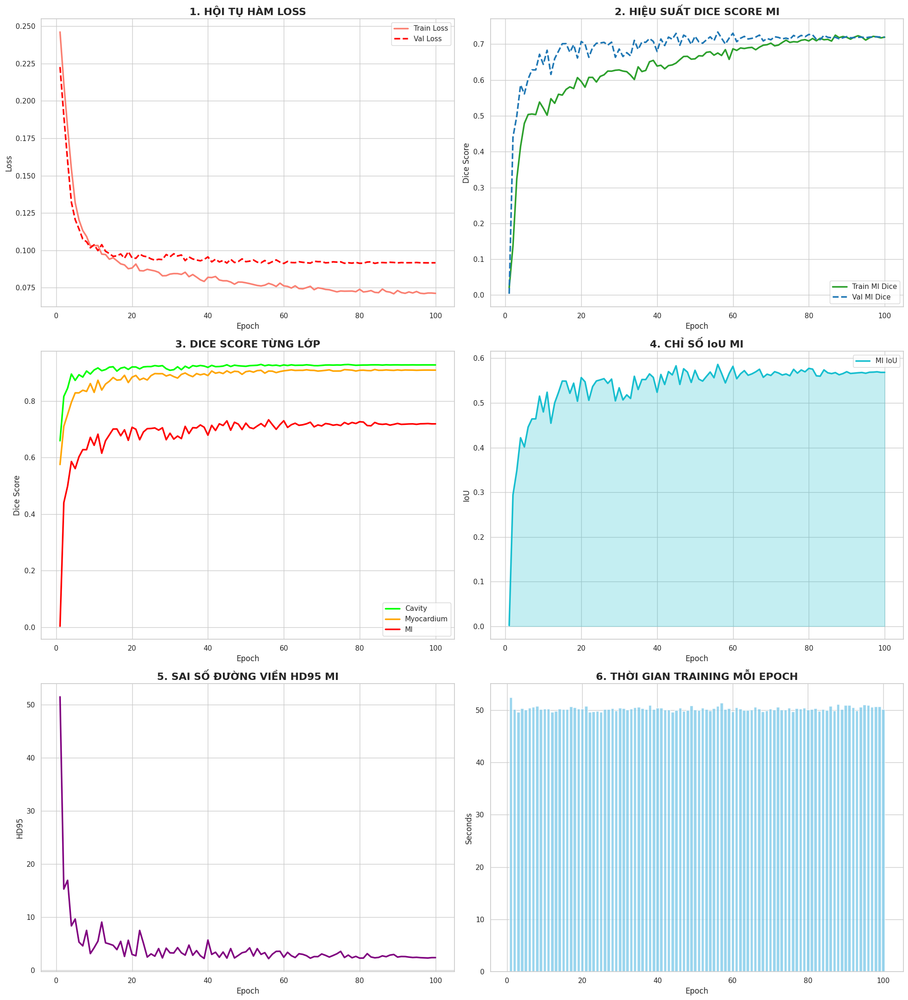


                BÁO CÁO KẾT QUẢ ATTENTION U-NET EMIDEC                
🏆 BEST EPOCH: 56
  > Train Loss                          :       0.0779
  > Validation Loss                     :       0.0912
  > Validation Cavity Dice              :       0.9280
  > Validation Myocardium Dice          :       0.9064
  > Validation MI Dice                  :       0.7339
  > Validation MI IoU                   :       0.5862
  > Validation MI HD95                  :         2.22
  > Training Time                       :     50.7 sec


In [9]:
# =========================================================
# FULL DASHBOARD REPORT
# ATTENTION U-NET EMIDEC MULTI-CLASS + GT PRIOR
# CSV: /kaggle/working/attunet_emidec_multiclass_gt_prior_log.csv
# =========================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

CSV_PATH = Path("/kaggle/working/unetpp_emidec_multiclass_gt_prior_log.csv")
SAVE_DIR = Path("/kaggle/working/unetpp_emidec_dashboard")

SAVE_DIR.mkdir(exist_ok=True)


def plot_dashboard_attunet_emidec(log_path):

    if not log_path.exists():
        print(f"❌ Không tìm thấy file log tại: {log_path}")
        return

    df = pd.read_csv(log_path)

    print(df.head())
    print(df.columns)

    sns.set_theme(style="whitegrid")

    fig, axes = plt.subplots(3, 2, figsize=(20, 22))
    plt.subplots_adjust(hspace=0.35, wspace=0.20)

    sns.lineplot(ax=axes[0, 0], data=df, x="Epoch", y="Train_Loss", label="Train Loss", color="salmon", linewidth=2.5)
    sns.lineplot(ax=axes[0, 0], data=df, x="Epoch", y="Val_Loss", label="Val Loss", color="red", linewidth=2.5, linestyle="--")
    axes[0, 0].set_title("1. HỘI TỤ HÀM LOSS", fontsize=16, fontweight="bold")
    axes[0, 0].set_xlabel("Epoch")
    axes[0, 0].set_ylabel("Loss")

    sns.lineplot(ax=axes[0, 1], data=df, x="Epoch", y="Train_Dice_MI", label="Train MI Dice", color="#2ca02c", linewidth=2.5)
    sns.lineplot(ax=axes[0, 1], data=df, x="Epoch", y="Val_Dice_MI", label="Val MI Dice", color="#1f77b4", linewidth=2.5, linestyle="--")
    axes[0, 1].set_title("2. HIỆU SUẤT DICE SCORE MI", fontsize=16, fontweight="bold")
    axes[0, 1].set_xlabel("Epoch")
    axes[0, 1].set_ylabel("Dice Score")

    sns.lineplot(ax=axes[1, 0], data=df, x="Epoch", y="Val_Dice_Cavity", label="Cavity", color="lime", linewidth=2.5)
    sns.lineplot(ax=axes[1, 0], data=df, x="Epoch", y="Val_Dice_Myo", label="Myocardium", color="orange", linewidth=2.5)
    sns.lineplot(ax=axes[1, 0], data=df, x="Epoch", y="Val_Dice_MI", label="MI", color="red", linewidth=2.5)
    axes[1, 0].set_title("3. DICE SCORE TỪNG LỚP", fontsize=16, fontweight="bold")
    axes[1, 0].set_xlabel("Epoch")
    axes[1, 0].set_ylabel("Dice Score")

    axes[1, 1].fill_between(df["Epoch"], df["Val_IoU_MI"], color="#17becf", alpha=0.25)
    axes[1, 1].plot(df["Epoch"], df["Val_IoU_MI"], color="#17becf", linewidth=2.5, label="MI IoU")
    axes[1, 1].set_title("4. CHỈ SỐ IoU MI", fontsize=16, fontweight="bold")
    axes[1, 1].set_xlabel("Epoch")
    axes[1, 1].set_ylabel("IoU")
    axes[1, 1].legend()

    sns.lineplot(ax=axes[2, 0], data=df, x="Epoch", y="Val_HD95_MI", color="purple", linewidth=2.5)
    axes[2, 0].set_title("5. SAI SỐ ĐƯỜNG VIỀN HD95 MI", fontsize=16, fontweight="bold")
    axes[2, 0].set_xlabel("Epoch")
    axes[2, 0].set_ylabel("HD95")

    axes[2, 1].bar(df["Epoch"], df["Time_s"], color="skyblue", alpha=0.85)
    axes[2, 1].set_title("6. THỜI GIAN TRAINING MỖI EPOCH", fontsize=16, fontweight="bold")
    axes[2, 1].set_xlabel("Epoch")
    axes[2, 1].set_ylabel("Seconds")

    plt.tight_layout()

    save_path = SAVE_DIR / "attunet_emidec_dashboard.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")

    print(f"\n✅ Đã lưu dashboard tại: {save_path}")

    plt.show()


def print_report_attunet_emidec(log_path):

    if not log_path.exists():
        print(f"❌ Không tìm thấy file log tại: {log_path}")
        return

    df = pd.read_csv(log_path)

    best_row = df.iloc[df["Val_Dice_MI"].idxmax()]

    print("\n" + "=" * 70)
    print(f"{'BÁO CÁO KẾT QUẢ ATTENTION U-NET EMIDEC':^70}")
    print("=" * 70)

    print(f"🏆 BEST EPOCH: {int(best_row['Epoch'])}")

    metrics = [
        ["Train Loss", f"{best_row['Train_Loss']:.4f}"],
        ["Validation Loss", f"{best_row['Val_Loss']:.4f}"],
        ["Validation Cavity Dice", f"{best_row['Val_Dice_Cavity']:.4f}"],
        ["Validation Myocardium Dice", f"{best_row['Val_Dice_Myo']:.4f}"],
        ["Validation MI Dice", f"{best_row['Val_Dice_MI']:.4f}"],
        ["Validation MI IoU", f"{best_row['Val_IoU_MI']:.4f}"],
        ["Validation MI HD95", f"{best_row['Val_HD95_MI']:.2f}"],
        ["Training Time", f"{best_row['Time_s']:.1f} sec"],
    ]

    for label, value in metrics:
        print(f"  > {label:<35} : {value:>12}")

    print("=" * 70)


plot_dashboard_attunet_emidec(CSV_PATH)
print_report_attunet_emidec(CSV_PATH)

In [11]:
# =========================================================
# FINAL TEST EVALUATION
# UNET++ EMIDEC MULTI-CLASS + GT PRIOR
#
# Classes:
# 0 background
# 1 cavity
# 2 myocardium
# 3 MI
# =========================================================

import torch
import pandas as pd
from tqdm.auto import tqdm

from monai.metrics import DiceMetric, MeanIoU, HausdorffDistanceMetric
from monai.data import Dataset, DataLoader
from monai.networks.nets import BasicUNetPlusPlus
from monai.transforms import AsDiscrete

print("=" * 80)
print("FINAL TEST - UNET++ EMIDEC MULTI-CLASS + GT PRIOR")
print("=" * 80)


# =========================================================
# TEST LOADER
# =========================================================

test_loader = DataLoader(
    Dataset(
        test_files,
        transform=val_transforms
    ),
    batch_size=1,
    shuffle=False
)


# =========================================================
# LOAD BEST MODEL
# =========================================================

model = BasicUNetPlusPlus(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,
    features=(16, 32, 64, 128, 256, 16),
    dropout=0.2,
    deep_supervision=False,
).to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_unetpp_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


# =========================================================
# POST PROCESS
# =========================================================

post_pred = AsDiscrete(
    argmax=True,
    to_onehot=4
)

post_label = AsDiscrete(
    to_onehot=4
)


# =========================================================
# METRICS
# include_background=False:
# idx 0 = cavity
# idx 1 = myocardium
# idx 2 = MI
# =========================================================

test_dice_metric = DiceMetric(
    include_background=False,
    reduction="mean_batch"
)

test_iou_metric = MeanIoU(
    include_background=False,
    reduction="mean_batch"
)

test_hd95_metric = HausdorffDistanceMetric(
    include_background=False,
    percentile=95,
    reduction="mean_batch"
)


# =========================================================
# TEST LOOP
# =========================================================

with torch.no_grad():

    for batch in tqdm(
        test_loader,
        desc="Testing UNet++"
    ):

        inputs = batch["unetpp_input"].to(device)
        labels = batch["label"].to(device)

        outputs = model(inputs)

        if isinstance(outputs, (list, tuple)):
            outputs = outputs[0]

        preds = [post_pred(i) for i in outputs]
        gts = [post_label(i) for i in labels]

        test_dice_metric(y_pred=preds, y=gts)
        test_iou_metric(y_pred=preds, y=gts)
        test_hd95_metric(y_pred=preds, y=gts)


# =========================================================
# AGGREGATE RESULTS
# =========================================================

test_dice_cavity = safe_metric(test_dice_metric, 0)
test_dice_myo = safe_metric(test_dice_metric, 1)
test_dice_mi = safe_metric(test_dice_metric, 2)

test_iou_cavity = safe_metric(test_iou_metric, 0)
test_iou_myo = safe_metric(test_iou_metric, 1)
test_iou_mi = safe_metric(test_iou_metric, 2)

test_hd95_cavity = safe_metric(test_hd95_metric, 0)
test_hd95_myo = safe_metric(test_hd95_metric, 1)
test_hd95_mi = safe_metric(test_hd95_metric, 2)


# =========================================================
# PRINT FINAL REPORT
# =========================================================

print("\n" + "★" * 70)
print(f"{'KẾT QUẢ CHÍNH THỨC TRÊN TẬP TEST':^70}")
print("★" * 70)

print(f"\n🫀 CAVITY:")
print(f"   Dice : {test_dice_cavity * 100:.2f}%")
print(f"   IoU  : {test_iou_cavity * 100:.2f}%")
print(f"   HD95 : {test_hd95_cavity:.4f}")

print(f"\n🫀 MYOCARDIUM:")
print(f"   Dice : {test_dice_myo * 100:.2f}%")
print(f"   IoU  : {test_iou_myo * 100:.2f}%")
print(f"   HD95 : {test_hd95_myo:.4f}")

print(f"\n🩸 MI:")
print(f"   Dice : {test_dice_mi * 100:.2f}%")
print(f"   IoU  : {test_iou_mi * 100:.2f}%")
print(f"   HD95 : {test_hd95_mi:.4f}")

print("★" * 70)


# =========================================================
# SAVE TEST CSV
# =========================================================

test_summary = pd.DataFrame([
    {
        "Model": "UNetPlusPlus_GT_Prior",

        "Test_Dice_Cavity": test_dice_cavity,
        "Test_IoU_Cavity": test_iou_cavity,
        "Test_HD95_Cavity": test_hd95_cavity,

        "Test_Dice_Myo": test_dice_myo,
        "Test_IoU_Myo": test_iou_myo,
        "Test_HD95_Myo": test_hd95_myo,

        "Test_Dice_MI": test_dice_mi,
        "Test_IoU_MI": test_iou_mi,
        "Test_HD95_MI": test_hd95_mi,
    }
])

save_test_csv = "/kaggle/working/unetpp_emidec_multiclass_gt_prior_test_results.csv"

test_summary.to_csv(
    save_test_csv,
    index=False
)

print(f"\n✅ Đã lưu test results tại:")
print(save_test_csv)

FINAL TEST - UNET++ EMIDEC MULTI-CLASS + GT PRIOR
BasicUNetPlusPlus features: (16, 32, 64, 128, 256, 16).


Testing UNet++:   0%|          | 0/15 [00:00<?, ?it/s]


★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
                   KẾT QUẢ CHÍNH THỨC TRÊN TẬP TEST                   
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★

🫀 CAVITY:
   Dice : 92.22%
   IoU  : 85.61%
   HD95 : 1.7926

🫀 MYOCARDIUM:
   Dice : 87.22%
   IoU  : 77.97%
   HD95 : 2.7323

🩸 MI:
   Dice : 66.36%
   IoU  : 50.37%
   HD95 : 5.0618
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★

✅ Đã lưu test results tại:
/kaggle/working/unetpp_emidec_multiclass_gt_prior_test_results.csv



🌟 TRỰC QUAN HÓA SỰ TIẾN HÓA ATTENTION - UNET++ + GT PRIOR
BasicUNetPlusPlus features: (16, 32, 64, 128, 256, 16).
[*] Selected case: Case_P081
Tổng số Conv3D layers: 34


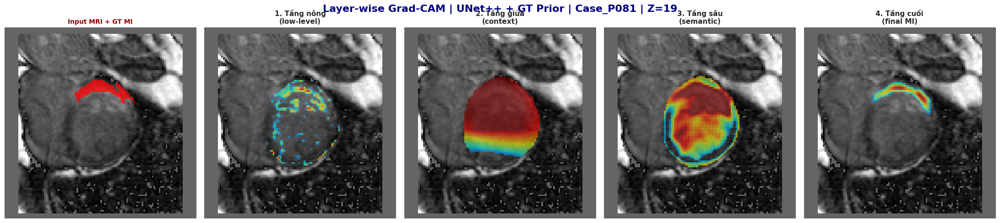

In [12]:
# ==============================================================================
# LAYER-WISE EVOLUTION
# UNET++ MULTI-CLASS + GT PRIOR
# EMIDEC classes:
# 0 background | 1 cavity | 2 myocardium | 3 MI
# ==============================================================================

print("\n" + "=" * 80)
print("🌟 TRỰC QUAN HÓA SỰ TIẾN HÓA ATTENTION - UNET++ + GT PRIOR")
print("=" * 80)

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.ndimage import zoom
from monai.networks.nets import BasicUNetPlusPlus


# =========================================================
# LOAD MODEL
# =========================================================

model = BasicUNetPlusPlus(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,
    features=(16, 32, 64, 128, 256, 16),
    dropout=0.2,
    deep_supervision=False,
).to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_unetpp_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


# =========================================================
# CUSTOM GRADCAM 3D
# =========================================================

class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.handle = self.target_layer.register_forward_hook(
            self.save_activation
        )

    def save_activation(self, module, input, output):
        self.activations = output.clone()

        if self.activations.requires_grad:
            self.activations.register_hook(self.save_gradient)

        return self.activations

    def save_gradient(self, grad):
        self.gradients = grad.clone()

    def remove_hooks(self):
        self.handle.remove()

    def generate_heatmap(self, input_tensor, class_idx=3):
        self.model.zero_grad(set_to_none=True)
        self.gradients = None
        self.activations = None

        output = self.model(input_tensor)

        if isinstance(output, (list, tuple)):
            output = output[0]

        score = output[:, class_idx].sum()
        score.backward()

        if self.gradients is None or self.activations is None:
            raise RuntimeError("Layer này không lấy được gradient, bỏ qua.")

        weights = torch.mean(
            self.gradients,
            dim=(2, 3, 4),
            keepdim=True
        )

        cam = torch.sum(
            weights * self.activations,
            dim=1
        ).squeeze(0)

        cam = F.relu(cam).detach().cpu().numpy()

        if cam.max() - cam.min() > 0:
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam


# =========================================================
# RANDOM MI CASE FROM TEST
# =========================================================

mi_cases = []

for sample_info in test_files:
    data = val_transforms(sample_info)

    if data["label"].max() == 3:
        mi_cases.append(sample_info)

if len(mi_cases) > 0:
    sample_info = random.choice(mi_cases)
else:
    sample_info = random.choice(test_files)

sample_data = val_transforms(sample_info)
case_name = sample_info["case_name"]

print(f"[*] Selected case: {case_name}")


# =========================================================
# PREPARE INPUT
# =========================================================

inputs = torch.as_tensor(
    sample_data["unetpp_input"]
).unsqueeze(0).float().to(device)

labels = torch.as_tensor(
    sample_data["label"]
).unsqueeze(0).long().to(device)

mri_vol = inputs[0, 0].detach().cpu().numpy()
prior_vol = inputs[0, 1].detach().cpu().numpy()
gt_array = labels[0, 0].detach().cpu().numpy()

z_scores = np.sum(gt_array == 3, axis=(0, 1))

if z_scores.max() > 0:
    z_slice = int(np.argmax(z_scores))
else:
    z_slice = gt_array.shape[2] // 2

mri_slice = mri_vol[:, :, z_slice]
prior_slice = prior_vol[:, :, z_slice]
gt_slice = gt_array[:, :, z_slice]


# =========================================================
# PREDICTION
# =========================================================

with torch.no_grad():
    outputs = model(inputs)

    if isinstance(outputs, (list, tuple)):
        outputs = outputs[0]

    pred = torch.argmax(outputs, dim=1).detach().cpu().numpy()[0]

pred_slice = pred[:, :, z_slice]


# =========================================================
# TARGET LAYERS
# =========================================================

conv_layers = [
    m for m in model.modules()
    if isinstance(m, torch.nn.Conv3d)
]

print(f"Tổng số Conv3D layers: {len(conv_layers)}")

step = max(1, len(conv_layers) // 4)

target_layers = {
    "1. Tầng nông\n(low-level)": conv_layers[min(1, len(conv_layers) - 1)],
    "2. Tầng giữa\n(context)": conv_layers[len(conv_layers) // 2],
    "3. Tầng sâu\n(semantic)": conv_layers[-6] if len(conv_layers) >= 6 else conv_layers[-2],
    "4. Tầng cuối\n(final MI)": conv_layers[-1],
}


# =========================================================
# PLOT
# =========================================================

fig, axes = plt.subplots(
    1,
    len(target_layers) + 1,
    figsize=(22, 5)
)

fig.suptitle(
    f"Layer-wise Grad-CAM | UNet++ + GT Prior | {case_name} | Z={z_slice}",
    fontsize=16,
    fontweight="bold",
    color="navy"
)

axes[0].imshow(np.rot90(mri_slice), cmap="gray")

gt_mi = np.ma.masked_where(
    gt_slice != 3,
    gt_slice
)

axes[0].imshow(
    np.rot90(gt_mi),
    cmap="autumn",
    alpha=0.75
)

axes[0].set_title(
    "Input MRI + GT MI",
    fontweight="bold",
    color="darkred",
    fontsize=10
)

axes[0].axis("off")


# =========================================================
# CAM PER LAYER
# =========================================================

for idx, (layer_title, layer_module) in enumerate(target_layers.items()):

    cam_engine = None

    try:
        cam_engine = GradCAM3D(
            model=model,
            target_layer=layer_module
        )

        inputs_grad = inputs.clone().detach().requires_grad_(True)

        heat_small = cam_engine.generate_heatmap(
            inputs_grad,
            class_idx=3
        )

        cam_engine.remove_hooks()

        zoom_factor = (
            gt_array.shape[0] / heat_small.shape[0],
            gt_array.shape[1] / heat_small.shape[1],
            gt_array.shape[2] / heat_small.shape[2],
        )

        heat = zoom(
            heat_small,
            zoom_factor,
            order=1
        )

        if heat.max() > 0:
            heat = heat / heat.max()

        heat_slice = heat[:, :, z_slice]

        # Gọt CAM bằng GT prior tim, không gọt bằng GT MI
        heat_slice = heat_slice * (prior_slice > 0.5)

        if heat_slice.max() > 0:
            heat_slice = heat_slice / heat_slice.max()

        # Nếu vùng ngoài MI sáng hơn MI thì đảo lại
        if (gt_slice == 3).any():
            mi_intensity = heat_slice[gt_slice == 3].mean()

            bg_mask = (prior_slice > 0.5) & (gt_slice != 3)
            bg_intensity = heat_slice[bg_mask].mean() if bg_mask.any() else 0

            if bg_intensity > mi_intensity:
                heat_slice = (1.0 - heat_slice) * (prior_slice > 0.5)

                if heat_slice.max() > 0:
                    heat_slice = heat_slice / heat_slice.max()

        heat_masked = np.ma.masked_where(
            heat_slice < 0.25,
            heat_slice
        )

        ax = axes[idx + 1]

        ax.imshow(np.rot90(mri_slice), cmap="gray")

        ax.imshow(
            np.rot90(heat_masked),
            cmap="jet",
            alpha=0.6,
            vmin=0,
            vmax=1
        )

        ax.set_title(
            layer_title,
            fontweight="bold",
            fontsize=11
        )

        ax.axis("off")

    except Exception as e:
        if cam_engine is not None:
            try:
                cam_engine.remove_hooks()
            except:
                pass

        ax = axes[idx + 1]
        ax.imshow(np.rot90(mri_slice), cmap="gray")
        ax.set_title(
            f"{layer_title}\nLỗi CAM",
            color="red",
            fontweight="bold"
        )
        ax.axis("off")

        print(f"Lỗi ở layer {layer_title}: {e}")


plt.tight_layout()
plt.show()


🔬 TRỰC QUAN HÓA GRAD-CAM & PREDICTION - UNET++ + GT PRIOR
BasicUNetPlusPlus features: (16, 32, 64, 128, 256, 16).
[*] Selected case: Case_P001
Keys: dict_keys(['image', 'label', 'mask_prior', 'case_name', 'unetpp_input'])
Tổng số Conv3D layers: 34
Số candidate layers: 30
[*] Grad-CAM target layer: Conv3d(16, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))


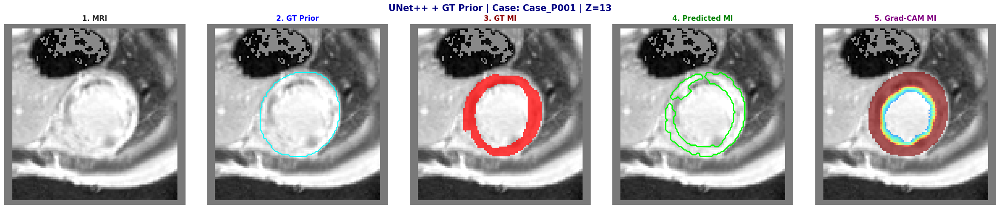

In [31]:
# =========================================================
# VISUALIZE PREDICTION + GRAD-CAM
# UNET++ MULTI-CLASS + GT PRIOR
# 0 background | 1 cavity | 2 myocardium | 3 MI
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import random
from scipy.ndimage import zoom

from monai.networks.nets import BasicUNetPlusPlus
from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    ScaleIntensityRangePercentilesd,
    NormalizeIntensityd,
    Lambdad,
    ConcatItemsd,
    ToTensord,
)

print("\n" + "=" * 80)
print("🔬 TRỰC QUAN HÓA GRAD-CAM & PREDICTION - UNET++ + GT PRIOR")
print("=" * 80)


# =========================================================
# UNET++ VAL TRANSFORM RIÊNG
# =========================================================

unetpp_val_transforms = Compose([
    LoadImaged(keys=["image", "label", "mask_prior"]),
    EnsureChannelFirstd(keys=["image", "label", "mask_prior"]),

    ScaleIntensityRangePercentilesd(
        keys=["image"],
        lower=1,
        upper=99,
        b_min=0.0,
        b_max=1.0,
        clip=True,
    ),

    NormalizeIntensityd(
        keys=["image"],
        nonzero=True,
        channel_wise=True,
    ),

    Lambdad(
        keys=["label"],
        func=remap_emidec_multiclass,
    ),

    ConcatItemsd(
        keys=["image", "mask_prior"],
        name="unetpp_input",
        dim=0,
    ),

    ToTensord(keys=["unetpp_input", "label"]),
])


# =========================================================
# LOAD MODEL
# =========================================================

model = BasicUNetPlusPlus(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,
    features=(16, 32, 64, 128, 256, 16),
    dropout=0.2,
    deep_supervision=False,
).to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_unetpp_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


# =========================================================
# CUSTOM GRADCAM 3D - GIỐNG DYNUNET
# =========================================================

class GradCAM3D:

    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer

        self.gradients = None
        self.activations = None

        self.handles = []

        self.handles.append(
            self.target_layer.register_forward_hook(
                self.save_activation
            )
        )

        self.handles.append(
            self.target_layer.register_full_backward_hook(
                self.save_gradient
            )
        )

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def remove_hooks(self):
        for handle in self.handles:
            handle.remove()

    def generate_heatmap(self, input_tensor, class_idx=3):
        self.model.zero_grad(set_to_none=True)

        output = self.model(input_tensor)

        if isinstance(output, (list, tuple)):
            output = output[0]

        score = output[0, class_idx].sum()
        score.backward()

        if self.gradients is None or self.activations is None:
            raise RuntimeError("Không lấy được gradient ở layer này.")

        weights = torch.mean(
            self.gradients,
            dim=(2, 3, 4),
            keepdim=True
        )

        cam = torch.sum(
            weights * self.activations,
            dim=1
        ).squeeze(0)

        cam = F.relu(cam).detach().cpu().numpy()

        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam


# =========================================================
# RANDOM CASE CÓ MI
# =========================================================

mi_cases = []

for info in test_files:
    data = unetpp_val_transforms(info)

    if data["label"].max() == 3:
        mi_cases.append(info)

sample_info = random.choice(mi_cases) if len(mi_cases) > 0 else random.choice(test_files)

sample_data = unetpp_val_transforms(sample_info)
case_name = sample_info["case_name"]

print(f"[*] Selected case: {case_name}")
print("Keys:", sample_data.keys())


# =========================================================
# INPUT
# =========================================================

inputs = torch.as_tensor(
    sample_data["unetpp_input"]
).unsqueeze(0).float().to(device)

labels = torch.as_tensor(
    sample_data["label"]
).unsqueeze(0).long().to(device)

mri = inputs[0, 0].detach().cpu().numpy()
prior = inputs[0, 1].detach().cpu().numpy()
gt = labels[0, 0].detach().cpu().numpy()


# =========================================================
# BEST SLICE
# =========================================================

z_scores = np.sum(gt == 3, axis=(0, 1))

if z_scores.max() > 0:
    z = int(np.argmax(z_scores))
else:
    z = gt.shape[2] // 2

mri_slice = mri[:, :, z]
prior_slice = prior[:, :, z]
gt_slice = gt[:, :, z]


# =========================================================
# PREDICTION
# =========================================================

with torch.no_grad():

    out = model(inputs)

    if isinstance(out, (list, tuple)):
        out = out[0]

    pred = torch.argmax(
        out,
        dim=1
    ).detach().cpu().numpy()[0]

pred_slice = pred[:, :, z]


# =========================================================
# GRAD-CAM
# =========================================================

conv_layers = [
    m for m in model.modules()
    if isinstance(m, torch.nn.Conv3d)
]

print(f"Tổng số Conv3D layers: {len(conv_layers)}")

# Bỏ conv output 1x1 cuối
candidate_layers = [
    m for m in conv_layers
    if not (
        m.out_channels == 4 or
        m.kernel_size == (1, 1, 1)
    )
]

print(f"Số candidate layers: {len(candidate_layers)}")

# Lấy layer sâu nhất còn semantic, giống cách DynUNet dùng layer cuối
target_layer = candidate_layers[-1]

print(f"[*] Grad-CAM target layer: {target_layer}")

cam_engine = GradCAM3D(
    model=model,
    target_layer=target_layer
)

inputs_grad = inputs.clone().detach().requires_grad_(True)

heat_small = cam_engine.generate_heatmap(
    inputs_grad,
    class_idx=3
)

cam_engine.remove_hooks()


# =========================================================
# UPSAMPLE HEATMAP
# =========================================================

zoom_factor = (
    gt.shape[0] / heat_small.shape[0],
    gt.shape[1] / heat_small.shape[1],
    gt.shape[2] / heat_small.shape[2],
)

heat = zoom(
    heat_small,
    zoom_factor,
    order=1
)

if heat.max() > 0:
    heat = heat / heat.max()

heat_slice = heat[:, :, z]


# =========================================================
# FILTER BY GT PRIOR
# =========================================================

heat_slice = heat_slice * (prior_slice > 0.5)

if heat_slice.max() > 0:
    heat_slice = heat_slice / heat_slice.max()


# =========================================================
# AUTO INVERT GIỐNG CODE CŨ
# =========================================================

if (gt_slice == 3).any():

    mi_intensity = heat_slice[gt_slice == 3].mean()

    bg_mask = (prior_slice > 0.5) & (gt_slice != 3)

    bg_intensity = heat_slice[bg_mask].mean() if bg_mask.any() else 0

    if bg_intensity > mi_intensity:

        heat_slice = (1.0 - heat_slice) * (prior_slice > 0.5)

        if heat_slice.max() > 0:
            heat_slice = heat_slice / heat_slice.max()


heat_masked = np.ma.masked_where(
    heat_slice < 0.25,
    heat_slice
)


# =========================================================
# VISUALIZE
# =========================================================

fig, axes = plt.subplots(1, 5, figsize=(24, 5))

fig.suptitle(
    f"UNet++ + GT Prior | Case: {case_name} | Z={z}",
    fontsize=15,
    fontweight="bold",
    color="navy"
)

axes[0].imshow(np.rot90(mri_slice), cmap="gray")
axes[0].set_title("1. MRI", fontweight="bold")
axes[0].axis("off")

axes[1].imshow(np.rot90(mri_slice), cmap="gray")
axes[1].contour(
    np.rot90(prior_slice),
    colors="cyan",
    levels=[0.5],
    linewidths=1.5
)
axes[1].set_title("2. GT Prior", fontweight="bold", color="blue")
axes[1].axis("off")

axes[2].imshow(np.rot90(mri_slice), cmap="gray")
gt_mi = np.ma.masked_where(gt_slice != 3, gt_slice)
axes[2].imshow(np.rot90(gt_mi), cmap="autumn", alpha=0.75)
axes[2].set_title("3. GT MI", fontweight="bold", color="darkred")
axes[2].axis("off")

axes[3].imshow(np.rot90(mri_slice), cmap="gray")
pred_mi = (pred_slice == 3).astype(np.uint8)

if pred_mi.max() > 0:
    axes[3].contour(
        np.rot90(pred_mi),
        colors="lime",
        levels=[0.5],
        linewidths=2
    )

axes[3].set_title("4. Predicted MI", fontweight="bold", color="green")
axes[3].axis("off")

axes[4].imshow(np.rot90(mri_slice), cmap="gray")
axes[4].imshow(
    np.rot90(heat_masked),
    cmap="jet",
    alpha=0.65,
    vmin=0,
    vmax=1
)
axes[4].set_title("5. Grad-CAM MI", fontweight="bold", color="purple")
axes[4].axis("off")

plt.tight_layout()
plt.show()


🚀 TRỰC QUAN HÓA ATTENTION CHO 3 BỆNH NHÂN - UNET++ + GT PRIOR
BasicUNetPlusPlus features: (16, 32, 64, 128, 256, 16).
Tổng số Conv3D layers: 34

[*] Đang phân tích bệnh nhân #1: Case_P063


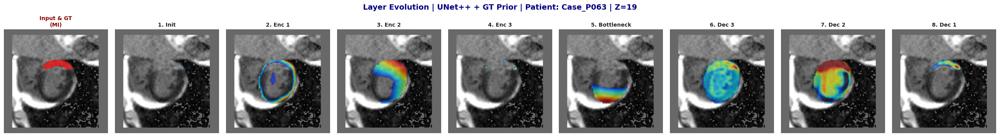


[*] Đang phân tích bệnh nhân #2: Case_P067


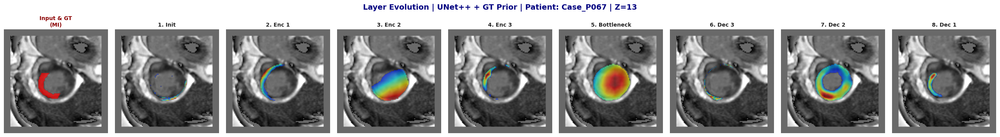


[*] Đang phân tích bệnh nhân #3: Case_P008


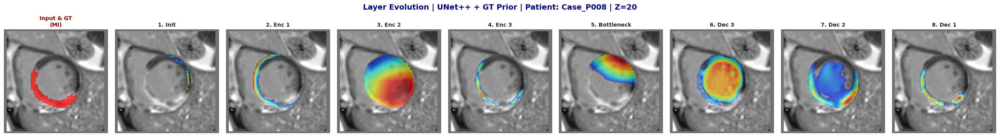

In [14]:
# ==============================================================================
# LAYER-WISE EVOLUTION
# UNET++ MULTI-CLASS + GT PRIOR
# ==============================================================================

import numpy as np
import random
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from scipy.ndimage import zoom
from monai.networks.nets import BasicUNetPlusPlus

print("\n" + "=" * 80)
print("🚀 TRỰC QUAN HÓA ATTENTION CHO 3 BỆNH NHÂN - UNET++ + GT PRIOR")
print("=" * 80)


class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.handle = self.target_layer.register_forward_hook(self.save_activation)

    def save_activation(self, module, input, output):
        self.activations = output.clone()
        if self.activations.requires_grad:
            self.activations.register_hook(self.save_gradient)
        return self.activations

    def save_gradient(self, grad):
        self.gradients = grad.clone()

    def remove_hooks(self):
        self.handle.remove()

    def generate_heatmap(self, input_tensor, class_idx=3):
        self.model.zero_grad(set_to_none=True)
        self.gradients = None
        self.activations = None

        output = self.model(input_tensor)

        if isinstance(output, (list, tuple)):
            output = output[0]

        score = output[:, class_idx].sum()
        score.backward()

        if self.gradients is None or self.activations is None:
            raise RuntimeError("Layer này không lấy được gradient, bỏ qua.")

        weights = torch.mean(self.gradients, dim=(2, 3, 4), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        cam = F.relu(cam).detach().cpu().numpy()

        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam


def run_3_patients_evolution(model, test_files, device, transform):

    model.load_state_dict(
        torch.load(
            "/kaggle/working/best_unetpp_emidec_multiclass_gt_prior.pth",
            map_location=device
        )
    )
    model.eval()

    conv_layers = [
        m for m in model.modules()
        if isinstance(m, torch.nn.Conv3d)
    ]

    print(f"Tổng số Conv3D layers: {len(conv_layers)}")

    step = max(1, len(conv_layers) // 8)

    target_layers = {
        "1. Init": conv_layers[0],
        "2. Enc 1": conv_layers[min(step * 1, len(conv_layers) - 1)],
        "3. Enc 2": conv_layers[min(step * 2, len(conv_layers) - 1)],
        "4. Enc 3": conv_layers[min(step * 3, len(conv_layers) - 1)],
        "5. Bottleneck": conv_layers[min(step * 4, len(conv_layers) - 1)],
        "6. Dec 3": conv_layers[-min(step * 4, len(conv_layers))],
        "7. Dec 2": conv_layers[-min(step * 2, len(conv_layers))],
        "8. Dec 1": conv_layers[-1],
    }

    mi_patients = []

    for info in test_files:
        data = transform(info)
        if data["label"].max() == 3:
            mi_patients.append((info, data))

    if not mi_patients:
        print("[!] Không có bệnh nhân nào có MI trong tập test.")
        return

    selected_patients = random.sample(
        mi_patients,
        min(3, len(mi_patients))
    )

    for p_idx, (info, data) in enumerate(selected_patients):

        print(f"\n[*] Đang phân tích bệnh nhân #{p_idx + 1}: {info['case_name']}")

        inputs = torch.as_tensor(
            data["unetpp_input"]
        ).unsqueeze(0).float().to(device)

        labels = torch.as_tensor(
            data["label"]
        ).unsqueeze(0).long().to(device)

        img_vol = inputs[0, 0].detach().cpu().numpy()
        prior_vol = inputs[0, 1].detach().cpu().numpy()
        gt_array = labels[0, 0].detach().cpu().numpy()

        z_scores = np.sum(gt_array == 3, axis=(0, 1))

        if z_scores.max() > 0:
            z_slice = int(np.argmax(z_scores))
        else:
            z_slice = gt_array.shape[2] // 2

        img_slice = img_vol[:, :, z_slice]
        prior_slice = prior_vol[:, :, z_slice]
        gt_slice = gt_array[:, :, z_slice]

        fig, axes = plt.subplots(
            1,
            len(target_layers) + 1,
            figsize=(26, 3.8)
        )

        fig.suptitle(
            f"Layer Evolution | UNet++ + GT Prior | Patient: {info['case_name']} | Z={z_slice}",
            fontsize=14,
            fontweight="bold",
            color="navy"
        )

        axes[0].imshow(np.rot90(img_slice), cmap="gray")

        gt_mask = np.ma.masked_where(gt_slice != 3, gt_slice)

        axes[0].imshow(
            np.rot90(gt_mask),
            cmap="autumn",
            alpha=0.7
        )

        axes[0].set_title(
            "Input & GT\n(MI)",
            fontweight="bold",
            color="darkred",
            fontsize=10
        )

        axes[0].axis("off")

        for i, (layer_name, layer_module) in enumerate(target_layers.items()):

            ax = axes[i + 1]
            cam_extractor = None

            try:
                cam_extractor = GradCAM3D(
                    model=model,
                    target_layer=layer_module
                )

                img_grad = inputs.clone().detach().requires_grad_(True)

                heat_small = cam_extractor.generate_heatmap(
                    img_grad,
                    class_idx=3
                )

                cam_extractor.remove_hooks()

                zoom_factor = (
                    gt_array.shape[0] / heat_small.shape[0],
                    gt_array.shape[1] / heat_small.shape[1],
                    gt_array.shape[2] / heat_small.shape[2],
                )

                heat = zoom(
                    heat_small,
                    zoom_factor,
                    order=1
                )

                if heat.max() > 0:
                    heat = heat / heat.max()

                heat_slice = heat[:, :, z_slice]

                heat_slice = heat_slice * (prior_slice > 0.5)

                if heat_slice.max() > 0:
                    heat_slice = heat_slice / heat_slice.max()

                if i >= 6 and (gt_slice == 3).any():
                    scar_int = heat_slice[gt_slice == 3].mean()

                    bg_mask = (prior_slice > 0.5) & (gt_slice != 3)
                    bg_int = heat_slice[bg_mask].mean() if bg_mask.any() else 0

                    if bg_int > scar_int:
                        heat_slice = (1.0 - heat_slice) * (prior_slice > 0.5)

                        if heat_slice.max() > 0:
                            heat_slice = heat_slice / heat_slice.max()

                heat_slice_masked = np.ma.masked_where(
                    heat_slice < 0.15,
                    heat_slice
                )

                ax.imshow(np.rot90(img_slice), cmap="gray")
                ax.imshow(
                    np.rot90(heat_slice_masked),
                    cmap="jet",
                    alpha=0.6,
                    vmin=0,
                    vmax=1
                )

                ax.set_title(
                    layer_name,
                    fontsize=10,
                    fontweight="bold"
                )

            except Exception as e:
                if cam_extractor is not None:
                    try:
                        cam_extractor.remove_hooks()
                    except:
                        pass

                ax.imshow(np.rot90(img_slice), cmap="gray")
                ax.set_title(
                    f"{layer_name}\n[Bỏ qua]",
                    color="gray",
                    fontsize=9
                )

                print(f"Lỗi layer {layer_name}: {e}")

            ax.axis("off")

        plt.tight_layout()
        plt.show()


model = BasicUNetPlusPlus(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,
    features=(16, 32, 64, 128, 256, 16),
    dropout=0.2,
    deep_supervision=False,
).to(device)


run_3_patients_evolution(
    model=model,
    test_files=test_files,
    device=device,
    transform=val_transforms
)


🧠 UNCERTAINTY MAP - UNET++ + GT PRIOR
BasicUNetPlusPlus features: (16, 32, 64, 128, 256, 16).
[*] Đang chạy MC Dropout (T=15) cho 3 bệnh nhân...

[*] Đang phân tích: Case_P036


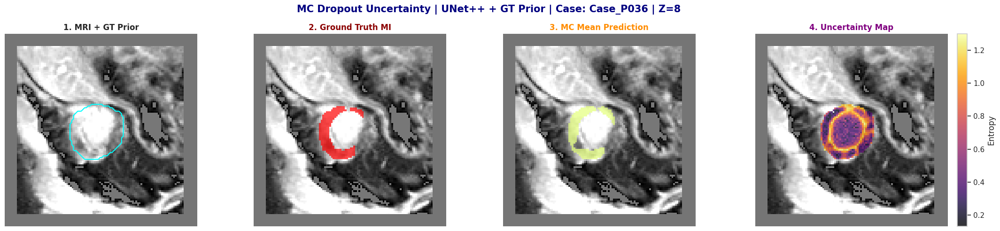


[*] Đang phân tích: Case_P067


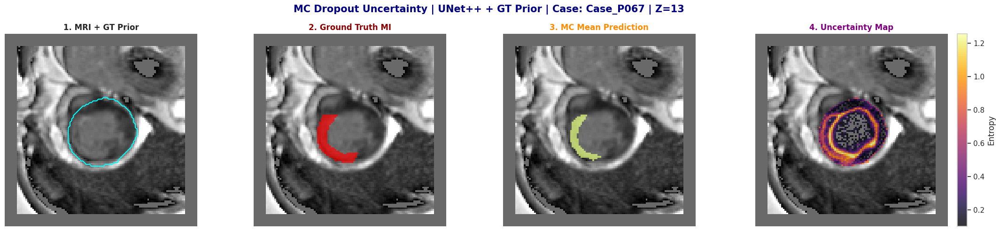


[*] Đang phân tích: Case_P001


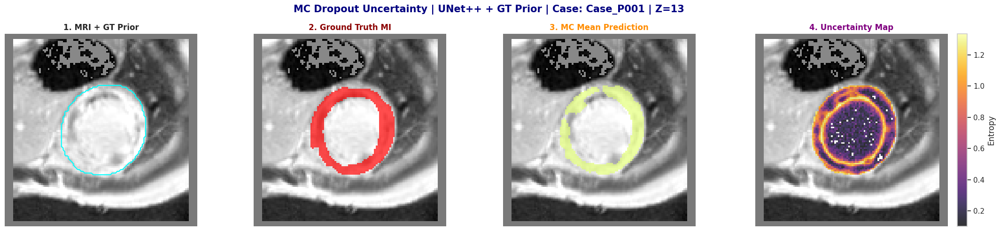

In [15]:
# ==============================================================================
# 🧠 MC DROPOUT UNCERTAINTY MAP
# UNET++ MULTI-CLASS + GT PRIOR
#
# Classes:
# 0 background
# 1 cavity
# 2 myocardium
# 3 MI
# ==============================================================================

import numpy as np
import random
import matplotlib.pyplot as plt
import torch

from monai.networks.nets import BasicUNetPlusPlus

print("\n" + "=" * 80)
print("🧠 UNCERTAINTY MAP - UNET++ + GT PRIOR")
print("=" * 80)


# =========================================================
# LOAD MODEL
# =========================================================

model = BasicUNetPlusPlus(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,
    features=(16, 32, 64, 128, 256, 16),
    dropout=0.2,
    deep_supervision=False,
).to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_unetpp_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


# =========================================================
# ENABLE DROPOUT ONLY
# =========================================================

def enable_dropout_only(m):
    if isinstance(
        m,
        (
            torch.nn.Dropout,
            torch.nn.Dropout2d,
            torch.nn.Dropout3d
        )
    ):
        m.train()


# =========================================================
# MC DROPOUT
# =========================================================

def compute_uncertainty_mc_dropout(
    model,
    unetpp_input,
    T=15
):
    model.eval()
    model.apply(enable_dropout_only)

    outputs = []

    with torch.no_grad():
        for _ in range(T):

            logits = model(unetpp_input)

            if isinstance(logits, (list, tuple)):
                logits = logits[0]

            probs = torch.softmax(logits, dim=1)
            outputs.append(probs)

    outputs = torch.stack(outputs)

    mean_prob = torch.mean(outputs, dim=0)

    epsilon = 1e-6

    uncertainty_map = -torch.sum(
        mean_prob * torch.log(mean_prob + epsilon),
        dim=1
    )

    # Channel 1 = GT anatomy prior
    mask_tim = unetpp_input[:, 1, ...]

    uncertainty_map = uncertainty_map * mask_tim

    model.eval()

    return mean_prob, uncertainty_map


# =========================================================
# VISUALIZE
# =========================================================

def visualize_uncertainty_xai(
    model,
    test_files,
    device,
    transform,
    num_samples=3
):

    print(f"[*] Đang chạy MC Dropout (T=15) cho {num_samples} bệnh nhân...")

    mi_patients = []

    for info in test_files:
        data = transform(info)

        if data["label"].max() == 3:
            mi_patients.append((info, data))

    if not mi_patients:
        print("[!] Không có bệnh nhân MI trong tập test.")
        return

    selected_patients = random.sample(
        mi_patients,
        min(num_samples, len(mi_patients))
    )

    for p_idx, (info, data) in enumerate(selected_patients):

        print(f"\n[*] Đang phân tích: {info['case_name']}")

        inputs = torch.as_tensor(
            data["unetpp_input"]
        ).unsqueeze(0).float().to(device)

        labels = torch.as_tensor(
            data["label"]
        ).unsqueeze(0).long().to(device)

        mean_prob, unc_map = compute_uncertainty_mc_dropout(
            model,
            inputs,
            T=15
        )

        pred_mask = torch.argmax(
            mean_prob,
            dim=1
        ).cpu().numpy()[0]

        unc_map_np = unc_map.cpu().numpy()[0]

        gt_array = labels[0, 0].cpu().numpy()

        z_scores = np.sum(gt_array == 3, axis=(0, 1))

        if z_scores.max() > 0:
            z_slice = int(np.argmax(z_scores))
        else:
            z_slice = gt_array.shape[2] // 2

        img_slice = inputs[0, 0, :, :, z_slice].cpu().numpy()
        mask_tim_slice = inputs[0, 1, :, :, z_slice].cpu().numpy()

        gt_slice = gt_array[:, :, z_slice]
        pred_slice = pred_mask[:, :, z_slice]
        unc_slice = unc_map_np[:, :, z_slice]

        unc_slice_masked = np.ma.masked_where(
            unc_slice < 0.10,
            unc_slice
        )

        fig, axes = plt.subplots(1, 4, figsize=(22, 5))

        fig.suptitle(
            f"MC Dropout Uncertainty | UNet++ + GT Prior | Case: {info['case_name']} | Z={z_slice}",
            fontsize=15,
            fontweight="bold",
            color="navy"
        )

        axes[0].imshow(np.rot90(img_slice), cmap="gray")
        axes[0].contour(
            np.rot90(mask_tim_slice),
            colors="cyan",
            levels=[0.5],
            linewidths=1.5
        )
        axes[0].set_title("1. MRI + GT Prior", fontweight="bold")
        axes[0].axis("off")

        axes[1].imshow(np.rot90(img_slice), cmap="gray")
        gt_masked = np.ma.masked_where(gt_slice != 3, gt_slice)
        axes[1].imshow(np.rot90(gt_masked), cmap="autumn", alpha=0.7)
        axes[1].set_title(
            "2. Ground Truth MI",
            fontweight="bold",
            color="darkred"
        )
        axes[1].axis("off")

        axes[2].imshow(np.rot90(img_slice), cmap="gray")
        pred_masked = np.ma.masked_where(pred_slice != 3, pred_slice)
        axes[2].imshow(np.rot90(pred_masked), cmap="Wistia", alpha=0.7)
        axes[2].set_title(
            "3. MC Mean Prediction",
            fontweight="bold",
            color="darkorange"
        )
        axes[2].axis("off")

        axes[3].imshow(np.rot90(img_slice), cmap="gray")
        im_unc = axes[3].imshow(
            np.rot90(unc_slice_masked),
            cmap="inferno",
            alpha=0.8
        )
        axes[3].set_title(
            "4. Uncertainty Map",
            fontweight="bold",
            color="purple"
        )
        axes[3].axis("off")

        plt.colorbar(
            im_unc,
            ax=axes[3],
            fraction=0.046,
            pad=0.04,
            label="Entropy"
        )

        plt.tight_layout()
        plt.show()


visualize_uncertainty_xai(
    model=model,
    test_files=test_files,
    device=device,
    transform=val_transforms,
    num_samples=3
)


🔬 TRỰC QUAN HÓA GRAD-CAM & PREDICTION - UNET++ + GT PRIOR
BasicUNetPlusPlus features: (16, 32, 64, 128, 256, 16).
[*] Selected case: Case_P091
[*] Grad-CAM target layer: model.final_conv_0_4


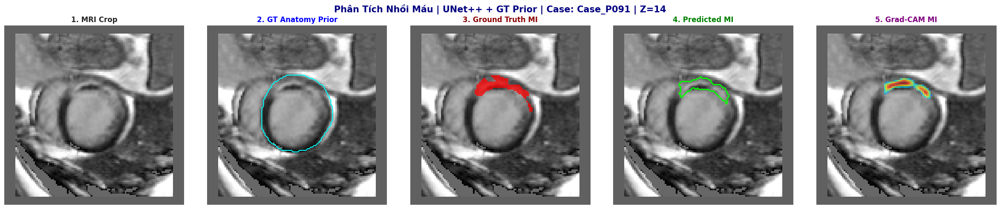

In [16]:
# =========================================================
# VISUALIZE PREDICTION + GRAD-CAM
# UNET++ MULTI-CLASS + GT PRIOR
# 0 background | 1 cavity | 2 myocardium | 3 MI
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import random
from monai.visualize import GradCAM
from monai.networks.nets import BasicUNetPlusPlus

print("\n" + "=" * 80)
print("🔬 TRỰC QUAN HÓA GRAD-CAM & PREDICTION - UNET++ + GT PRIOR")
print("=" * 80)


# =========================================================
# LOAD MODEL
# =========================================================

model = BasicUNetPlusPlus(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,
    features=(16, 32, 64, 128, 256, 16),
    dropout=0.2,
    deep_supervision=False,
).to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_unetpp_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


# =========================================================
# WRAPPER CHO MONAI GRADCAM
# =========================================================

class GradCAMWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        out = self.model(x)

        if isinstance(out, (list, tuple)):
            out = out[0]

        return out


wrapped_model = GradCAMWrapper(model).to(device)
wrapped_model.eval()


# =========================================================
# FIND RANDOM MI CASE
# =========================================================

mi_cases = []

for info in test_files:
    data = val_transforms(info)

    if data["label"].max() == 3:
        mi_cases.append(info)

sample_info = random.choice(mi_cases) if len(mi_cases) > 0 else random.choice(test_files)

sample_data = val_transforms(sample_info)
case_name = sample_info["case_name"]

print(f"[*] Selected case: {case_name}")


# =========================================================
# PREPARE INPUT
# =========================================================

inputs = torch.as_tensor(
    sample_data["unetpp_input"]
).unsqueeze(0).float().to(device)

labels = torch.as_tensor(
    sample_data["label"]
).unsqueeze(0).long().to(device)

inputs.requires_grad_(True)

# Channel 0 = MRI, channel 1 = GT prior
img_vol = inputs[0, 0].detach().cpu().numpy()
prior_vol = inputs[0, 1].detach().cpu().numpy()
gt_array = labels[0, 0].detach().cpu().numpy()

z_scores = np.sum(gt_array == 3, axis=(0, 1))

if z_scores.max() > 0:
    z_slice = int(np.argmax(z_scores))
else:
    z_slice = gt_array.shape[2] // 2

img_slice = img_vol[:, :, z_slice]
prior_slice = prior_vol[:, :, z_slice]
gt_slice = gt_array[:, :, z_slice]


# =========================================================
# PREDICTION
# =========================================================

with torch.no_grad():
    outputs = model(inputs)

    if isinstance(outputs, (list, tuple)):
        outputs = outputs[0]

    preds = torch.argmax(outputs, dim=1).detach().cpu().numpy()[0]

pred_slice = preds[:, :, z_slice]


# =========================================================
# GRAD-CAM
# =========================================================

conv_layer_names = [
    name for name, module in wrapped_model.named_modules()
    if isinstance(module, torch.nn.Conv3d)
]

target_layer = conv_layer_names[-1]

print(f"[*] Grad-CAM target layer: {target_layer}")

cam = GradCAM(
    nn_module=wrapped_model,
    target_layers=target_layer
)

heatmap = cam(
    x=inputs,
    class_idx=3
)

heat_slice = heatmap[0, 0, :, :, z_slice].detach().cpu().numpy()

heat_slice = np.maximum(heat_slice, 0)

if heat_slice.max() > 0:
    heat_slice = heat_slice / heat_slice.max()

# Gọt nhiễu bằng GT prior tim, không dùng GT MI
heat_slice = heat_slice * (prior_slice > 0.5)

if heat_slice.max() > 0:
    heat_slice = heat_slice / heat_slice.max()

# Logic đảo màu giống code cũ
if (gt_slice == 3).any():
    mi_intensity = heat_slice[gt_slice == 3].mean()

    bg_mask = (prior_slice > 0.5) & (gt_slice != 3)
    bg_intensity = heat_slice[bg_mask].mean() if bg_mask.any() else 0

    if bg_intensity > mi_intensity:
        heat_slice = (1.0 - heat_slice) * (prior_slice > 0.5)

        if heat_slice.max() > 0:
            heat_slice = heat_slice / heat_slice.max()

heat_slice_masked = np.ma.masked_where(
    heat_slice < 0.25,
    heat_slice
)


# =========================================================
# VISUALIZATION
# =========================================================

fig, axes = plt.subplots(1, 5, figsize=(24, 5))

fig.suptitle(
    f"Phân Tích Nhồi Máu | UNet++ + GT Prior | Case: {case_name} | Z={z_slice}",
    fontsize=15,
    fontweight="bold",
    color="navy"
)

axes[0].imshow(np.rot90(img_slice), cmap="gray")
axes[0].set_title("1. MRI Crop", fontweight="bold")
axes[0].axis("off")

axes[1].imshow(np.rot90(img_slice), cmap="gray")
axes[1].contour(
    np.rot90(prior_slice),
    colors="cyan",
    levels=[0.5],
    linewidths=1.5
)
axes[1].set_title("2. GT Anatomy Prior", fontweight="bold", color="blue")
axes[1].axis("off")

axes[2].imshow(np.rot90(img_slice), cmap="gray")
gt_mi_mask = np.ma.masked_where(gt_slice != 3, gt_slice)
axes[2].imshow(np.rot90(gt_mi_mask), cmap="autumn", alpha=0.75)
axes[2].set_title("3. Ground Truth MI", fontweight="bold", color="darkred")
axes[2].axis("off")

axes[3].imshow(np.rot90(img_slice), cmap="gray")
pred_mi_only = (pred_slice == 3).astype(np.uint8)

if pred_mi_only.max() > 0:
    axes[3].contour(
        np.rot90(pred_mi_only),
        colors="lime",
        levels=[0.5],
        linewidths=2
    )

axes[3].set_title("4. Predicted MI", fontweight="bold", color="green")
axes[3].axis("off")

axes[4].imshow(np.rot90(img_slice), cmap="gray")
axes[4].imshow(
    np.rot90(heat_slice_masked),
    cmap="jet",
    alpha=0.65,
    vmin=0,
    vmax=1
)
axes[4].set_title("5. Grad-CAM MI", fontweight="bold", color="purple")
axes[4].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# =========================================================
# FINAL TEST: MI YES/NO + MI VOLUME + VISUALIZATION
# FOR BASICUNETPLUSPLUS EMIDEC MULTI-CLASS MODEL
# =========================================================

import os
import csv
import numpy as np
import torch
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
# Đổi từ SegResNet sang BasicUNetPlusPlus
from monai.networks.nets import BasicUNetPlusPlus

# =========================================================
# CONFIG
# =========================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NUM_CLASSES = 4
# Cập nhật đường dẫn weight của UNet++
BEST_MODEL_PATH = "/kaggle/working/best_unetpp_emidec_multiclass_gt_prior.pth"

SAVE_DIR = "/kaggle/working/MI_Test_Visualization"
os.makedirs(SAVE_DIR, exist_ok=True)

CSV_PATH = "/kaggle/working/mi_detection_volume_results.csv"

# Spacing đồng bộ với Spacingd(pixdim=(1.5, 1.5, 5.0)) lúc train
VOXEL_VOLUME_MM3 = 1.5 * 1.5 * 5.0
VOXEL_VOLUME_ML = VOXEL_VOLUME_MM3 / 1000.0

# Ngưỡng tối thiểu để kết luận có MI
MI_MIN_VOXELS = 10

# =========================================================
# LOAD BEST MODEL (UNet++)
# =========================================================

# Khởi tạo đúng kiến trúc và thông số mạng UNet++ bạn đã train
model = BasicUNetPlusPlus(
    spatial_dims=3,
    in_channels=2,
    out_channels=NUM_CLASSES,
    features=(16, 32, 64, 128, 256, 16),
    dropout=0.2,
    deep_supervision=False,
).to(device)

model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
model.eval()

print("Loaded best UNet++ model:", BEST_MODEL_PATH)

# =========================================================
# HELPER FUNCTIONS
# =========================================================

def calculate_mi_volume(mask, mi_class=3):
    mi_voxels = np.sum(mask == mi_class)
    volume_ml = mi_voxels * VOXEL_VOLUME_ML
    return int(mi_voxels), float(volume_ml)

def has_mi(mask, mi_class=3, min_voxels=10):
    return np.sum(mask == mi_class) >= min_voxels

def get_best_slice(gt_mask, pred_mask, mi_class=3):
    gt_per_slice = np.sum(gt_mask == mi_class, axis=(0, 1))
    pred_per_slice = np.sum(pred_mask == mi_class, axis=(0, 1))

    if gt_per_slice.max() > 0:
        return int(np.argmax(gt_per_slice))
    elif pred_per_slice.max() > 0:
        return int(np.argmax(pred_per_slice))
    else:
        return gt_mask.shape[2] // 2

# =========================================================
# TEST + VISUALIZE
# =========================================================

results = []

with torch.no_grad():
    for idx, batch in enumerate(tqdm(test_loader, desc="Testing MI detection")):
        # Đổi key từ "segresnet_input" sang "unetpp_input"
        inputs = batch["unetpp_input"].to(device)
        labels = batch["label"].to(device)

        outputs = model(inputs)
        
        # Unpack outputs nếu mô hình trả về list/tuple (giống file train)
        if isinstance(outputs, (list, tuple)):
            outputs = outputs[0]

        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(probs, dim=1)

        # Kênh 0 là ảnh MRI gốc (Kênh 1 là mask_prior)
        image_np = inputs[0, 0].detach().cpu().numpy()

        if labels.ndim == 5:
            label_np = labels[0, 0].detach().cpu().numpy()
        else:
            label_np = labels[0].detach().cpu().numpy()

        pred_np = preds[0].detach().cpu().numpy()

        # Case name
        if "case_name" in batch:
            case_name = batch["case_name"][0]
        else:
            case_name = f"case_{idx:03d}"

        # Volume
        gt_mi_voxels, gt_mi_volume_ml = calculate_mi_volume(label_np, mi_class=3)
        pred_mi_voxels, pred_mi_volume_ml = calculate_mi_volume(pred_np, mi_class=3)

        # Yes / No detection
        gt_has_mi = has_mi(label_np, mi_class=3, min_voxels=MI_MIN_VOXELS)
        pred_has_mi = has_mi(pred_np, mi_class=3, min_voxels=MI_MIN_VOXELS)

        # Classification result
        if gt_has_mi and pred_has_mi:
            status = "TP"
        elif (not gt_has_mi) and (not pred_has_mi):
            status = "TN"
        elif (not gt_has_mi) and pred_has_mi:
            status = "FP"
        else:
            status = "FN"

        results.append([
            case_name,
            int(gt_has_mi),
            int(pred_has_mi),
            status,
            gt_mi_voxels,
            pred_mi_voxels,
            gt_mi_volume_ml,
            pred_mi_volume_ml,
        ])

        # Select best slice
        slice_idx = get_best_slice(label_np, pred_np, mi_class=3)

        gt_mi_overlay = np.ma.masked_where(label_np[:, :, slice_idx] != 3, label_np[:, :, slice_idx])
        pred_mi_overlay = np.ma.masked_where(pred_np[:, :, slice_idx] != 3, pred_np[:, :, slice_idx])

        # Visualization
        plt.figure(figsize=(22, 6))

        plt.subplot(1, 4, 1)
        plt.imshow(image_np[:, :, slice_idx], cmap="gray")
        plt.title(f"{case_name}\nMRI Slice {slice_idx}")
        plt.axis("off")

        plt.subplot(1, 4, 2)
        plt.imshow(image_np[:, :, slice_idx], cmap="gray")
        plt.imshow(gt_mi_overlay, cmap="Reds", alpha=0.65)
        plt.title(f"GT MI\nVolume: {gt_mi_volume_ml:.3f} mL")
        plt.axis("off")

        plt.subplot(1, 4, 3)
        plt.imshow(image_np[:, :, slice_idx], cmap="gray")
        plt.imshow(pred_mi_overlay, cmap="jet", alpha=0.65)
        plt.title(f"Pred MI\nVolume: {pred_mi_volume_ml:.3f} mL")
        plt.axis("off")

        plt.subplot(1, 4, 4)
        plt.imshow(pred_np[:, :, slice_idx], cmap="jet")
        plt.title(
            f"Prediction Mask\n"
            f"GT MI: {'YES' if gt_has_mi else 'NO'} | "
            f"Pred MI: {'YES' if pred_has_mi else 'NO'}\n"
            f"Status: {status}"
        )
        plt.axis("off")

        plt.tight_layout()

        save_path = os.path.join(SAVE_DIR, f"{case_name}_MI_detection_volume.png")
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        plt.show()

# =========================================================
# SAVE CSV
# =========================================================

with open(CSV_PATH, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "Case",
        "GT_MI_YesNo",
        "Pred_MI_YesNo",
        "Status",
        "GT_MI_Voxels",
        "Pred_MI_Voxels",
        "GT_MI_Volume_mL",
        "Pred_MI_Volume_mL",
    ])
    writer.writerows(results)

# =========================================================
# SUMMARY
# =========================================================

results_np = np.array(results, dtype=object)
statuses = [r[3] for r in results]

TP = statuses.count("TP")
TN = statuses.count("TN")
FP = statuses.count("FP")
FN = statuses.count("FN")

accuracy = (TP + TN) / max((TP + TN + FP + FN), 1)
sensitivity = TP / max((TP + FN), 1)
specificity = TN / max((TN + FP), 1)

print("=" * 80)
print("MI DETECTION SUMMARY (UNet++)")
print("=" * 80)
print(f"TP: {TP}")
print(f"TN: {TN}")
print(f"FP: {FP}")
print(f"FN: {FN}")
print(f"Accuracy   : {accuracy:.4f}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print("=" * 80)
print("Saved CSV:", CSV_PATH)
print("Saved visualizations:", SAVE_DIR)

In [ ]:
# =========================================================
# PREDICT RIÊNG VÙNG MI (CLASS 3) + RED OVERLAY + SAVE MASK
# Run after you already have: model, test_loader, device
# ĐỒNG BỘ VỚI BASICUNETPLUSPLUS
# =========================================================

import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import nibabel as nib
from tqdm.auto import tqdm

SAVE_DIR = "/kaggle/working/MI_Only_Prediction_Red"
os.makedirs(SAVE_DIR, exist_ok=True)

MI_CLASS = 3
MI_MIN_VOXELS = 10

# Spacing đồng bộ với Spacingd(pixdim=(1.5, 1.5, 5.0))
VOXEL_VOLUME_ML = (1.5 * 1.5 * 5.0) / 1000.0

model.eval()

with torch.no_grad():
    for idx, batch in enumerate(tqdm(test_loader, desc="Predict MI only (UNet++)")):
        # ĐỔI KEY: Chuyển từ "segresnet_input" sang "unetpp_input"
        inputs = batch["unetpp_input"].to(device)
        labels = batch["label"].to(device)

        outputs = model(inputs)
        
        # GIẢI NÉN OUTPUT: Đảm bảo an toàn nếu mô hình trả về dạng tuple/list giống file train
        if isinstance(outputs, (list, tuple)):
            outputs = outputs[0]

        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(probs, dim=1)

        # Kênh 0 là ảnh MRI gốc (Kênh 1 là mask_prior)
        image_np = inputs[0, 0].cpu().numpy()

        if labels.ndim == 5:
            label_np = labels[0, 0].cpu().numpy()
        else:
            label_np = labels[0].cpu().numpy()

        pred_np = preds[0].cpu().numpy()

        pred_mi_mask = (pred_np == MI_CLASS).astype(np.uint8)
        gt_mi_mask = (label_np == MI_CLASS).astype(np.uint8)

        pred_mi_voxels = int(pred_mi_mask.sum())
        gt_mi_voxels = int(gt_mi_mask.sum())

        pred_mi_volume_ml = pred_mi_voxels * VOXEL_VOLUME_ML
        gt_mi_volume_ml = gt_mi_voxels * VOXEL_VOLUME_ML

        pred_has_mi = pred_mi_voxels >= MI_MIN_VOXELS
        gt_has_mi = gt_mi_voxels >= MI_MIN_VOXELS

        if gt_has_mi and pred_has_mi:
            status = "TP"
        elif (not gt_has_mi) and (not pred_has_mi):
            status = "TN"
        elif (not gt_has_mi) and pred_has_mi:
            status = "FP"
        else:
            status = "FN"

        case_name = batch["case_name"][0] if "case_name" in batch else f"case_{idx:03d}"

        gt_per_slice = np.sum(gt_mi_mask, axis=(0, 1))
        pred_per_slice = np.sum(pred_mi_mask, axis=(0, 1))

        if gt_per_slice.max() > 0:
            slice_idx = int(np.argmax(gt_per_slice))
        elif pred_per_slice.max() > 0:
            slice_idx = int(np.argmax(pred_per_slice))
        else:
            slice_idx = image_np.shape[2] // 2

        # =================================================
        # RED OVERLAY FIX: dùng 1.0 thay vì 255
        # =================================================
        gt_overlay = np.zeros_like(gt_mi_mask[:, :, slice_idx], dtype=np.float32)
        pred_overlay = np.zeros_like(pred_mi_mask[:, :, slice_idx], dtype=np.float32)

        gt_overlay[gt_mi_mask[:, :, slice_idx] == 1] = 1.0
        pred_overlay[pred_mi_mask[:, :, slice_idx] == 1] = 1.0

        gt_overlay = np.ma.masked_where(gt_overlay == 0, gt_overlay)
        pred_overlay = np.ma.masked_where(pred_overlay == 0, pred_overlay)

        # =================================================
        # VISUALIZE
        # =================================================
        plt.figure(figsize=(22, 6))

        plt.subplot(1, 4, 1)
        plt.imshow(image_np[:, :, slice_idx], cmap="gray")
        plt.title(f"{case_name}\nMRI Slice {slice_idx}")
        plt.axis("off")

        plt.subplot(1, 4, 2)
        plt.imshow(image_np[:, :, slice_idx], cmap="gray")
        plt.imshow(gt_overlay, cmap="Reds", alpha=0.95, vmin=0, vmax=1)
        plt.title(
            f"GT MI\n"
            f"Voxels: {gt_mi_voxels}\n"
            f"Volume: {gt_mi_volume_ml:.3f} mL"
        )
        plt.axis("off")

        plt.subplot(1, 4, 3)
        plt.imshow(image_np[:, :, slice_idx], cmap="gray")
        plt.imshow(pred_overlay, cmap="Reds", alpha=0.95, vmin=0, vmax=1)
        plt.title(
            f"Predicted MI (UNet++)\n"
            f"Voxels: {pred_mi_voxels}\n"
            f"Volume: {pred_mi_volume_ml:.3f} mL"
        )
        plt.axis("off")

        plt.subplot(1, 4, 4)
        plt.imshow(image_np[:, :, slice_idx], cmap="gray")
        plt.imshow(gt_overlay, cmap="Reds", alpha=0.95, vmin=0, vmax=1)
        plt.imshow(pred_overlay, cmap="Reds", alpha=0.55, vmin=0, vmax=1)
        plt.title(
            f"GT + Pred MI\n"
            f"GT: {'YES' if gt_has_mi else 'NO'} | "
            f"Pred: {'YES' if pred_has_mi else 'NO'}\n"
            f"Status: {status}"
        )
        plt.axis("off")

        plt.tight_layout()

        fig_path = os.path.join(SAVE_DIR, f"{case_name}_MI_red_overlay.png")
        plt.savefig(fig_path, dpi=300, bbox_inches="tight")
        plt.show()

        mask_path = os.path.join(SAVE_DIR, f"{case_name}_pred_MI_mask.nii.gz")
        nib.save(
            nib.Nifti1Image(pred_mi_mask.astype(np.uint8), affine=np.eye(4)),
            mask_path,
        )

        print("=" * 70)
        print(case_name)
        print("GT MI      :", "YES" if gt_has_mi else "NO")
        print("Pred MI    :", "YES" if pred_has_mi else "NO")
        print("Status     :", status)
        print("GT volume  :", f"{gt_mi_volume_ml:.3f} mL")
        print("Pred volume:", f"{pred_mi_volume_ml:.3f} mL")
        print("Saved fig  :", fig_path)
        print("Saved mask :", mask_path)

        if idx >= 4:
            break

# GT DYNUNET

In [17]:
# =========================================================
# EMIDEC 2020 - MULTI-CLASS DYNUNET + GT PRIOR
# 0 background | 1 cavity | 2 myocardium | 3 MI
# =========================================================

import os, glob, time, random, csv, warnings
import numpy as np
import nibabel as nib
import torch

warnings.filterwarnings("ignore")

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

from monai.utils import set_determinism
from monai.data import Dataset, DataLoader
from monai.networks.nets import DynUNet
from monai.losses import DiceFocalLoss
from monai.metrics import DiceMetric, MeanIoU, HausdorffDistanceMetric
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, Spacingd,
    ScaleIntensityRangePercentilesd, NormalizeIntensityd,
    Lambdad, ResizeWithPadOrCropd, CropForegroundd,
    ConcatItemsd, RandFlipd, RandAffined, ToTensord, AsDiscrete
)
from torch.optim.lr_scheduler import CosineAnnealingLR

SEED = 43
set_determinism(seed=SEED)
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

EMIDEC_RAW_DIR = "/kaggle/input/datasets/ngdutrong/emicdec-2020-dataset/emidec-dataset-1.0.1/"
GT_CROPPED_DIR = "/kaggle/working/EMIDEC_GT_Cropped_DynUNet_MultiClass/"
os.makedirs(GT_CROPPED_DIR, exist_ok=True)

NUM_CLASSES = 4
MAX_EPOCHS = 100

SPATIAL_SIZE_RAW = (128, 128, 24)
SPATIAL_SIZE_CROP = (112, 112, 32)

csv_path = "/kaggle/working/dynunet_emidec_multiclass_gt_prior_log.csv"
best_model_path = "/kaggle/working/best_dynunet_emidec_multiclass_gt_prior.pth"


def make_gt_heart_prior(x):
    return (x > 0).to(torch.float32)


def remap_emidec_multiclass(x):
    y = torch.zeros_like(x).long()
    y[x == 1] = 1
    y[x == 2] = 2
    y[x >= 3] = 3
    return y


def safe_metric(metric, idx=0):
    try:
        val = metric.aggregate()
        if hasattr(val, "shape") and len(val.shape) > 0:
            val = val[idx]
        val = val.item()
        if np.isnan(val) or np.isinf(val):
            return 0.0
        return val
    except Exception:
        return 0.0


def get_raw_emidec_datalist(emidec_dir):
    data_list = []
    cases = glob.glob(os.path.join(emidec_dir, "Case_*"))

    for case_folder in cases:
        case_name = os.path.basename(case_folder)

        img_paths = [
            p for p in glob.glob(
                os.path.join(case_folder, f"Images/**/{case_name}.nii*"),
                recursive=True
            )
            if os.path.isfile(p)
        ]

        lbl_paths = [
            p for p in glob.glob(
                os.path.join(case_folder, f"Contours/**/{case_name}.nii*"),
                recursive=True
            )
            if os.path.isfile(p)
        ]

        if img_paths and lbl_paths:
            if os.path.getsize(img_paths[0]) > 0 and os.path.getsize(lbl_paths[0]) > 0:
                data_list.append({
                    "image": img_paths[0],
                    "label": lbl_paths[0],
                    "case_name": case_name
                })

    return sorted(data_list, key=lambda x: x["case_name"])


all_raw_files = get_raw_emidec_datalist(EMIDEC_RAW_DIR)
print(f"Total raw cases: {len(all_raw_files)}")

if len(all_raw_files) == 0:
    raise ValueError("Không tìm thấy dữ liệu EMIDEC.")


prep_transforms = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image", "label"]),

    Spacingd(
        keys=["image", "label"],
        pixdim=(1.5, 1.5, 5.0),
        mode=("bilinear", "nearest"),
    ),

    ScaleIntensityRangePercentilesd(
        keys=["image"],
        lower=1,
        upper=99,
        b_min=0.0,
        b_max=1.0,
        clip=True,
    ),

    NormalizeIntensityd(
        keys=["image"],
        nonzero=True,
        channel_wise=True,
    ),

    ResizeWithPadOrCropd(
        keys=["image", "label"],
        spatial_size=SPATIAL_SIZE_RAW,
        mode="constant",
    ),
])

crop_by_gt = Compose([
    CropForegroundd(
        keys=["image", "label", "mask_prior"],
        source_key="mask_prior",
        margin=25,
    ),

    ResizeWithPadOrCropd(
        keys=["image", "label", "mask_prior"],
        spatial_size=SPATIAL_SIZE_CROP,
        mode="constant",
    ),
])


def crop_and_save_all_cases(raw_files):
    cropped_files = []

    for item in tqdm(raw_files, desc="Cropping by GT mask"):
        data = prep_transforms({
            "image": item["image"],
            "label": item["label"],
        })

        gt_prior = make_gt_heart_prior(data["label"])
        data["mask_prior"] = gt_prior

        if torch.sum(gt_prior) == 0:
            continue

        cropped = crop_by_gt(data)

        case_out_dir = os.path.join(GT_CROPPED_DIR, item["case_name"])
        os.makedirs(case_out_dir, exist_ok=True)

        affine = data["image"].meta.get("affine", np.eye(4))

        image_path = os.path.join(case_out_dir, "image.nii.gz")
        label_path = os.path.join(case_out_dir, "label.nii.gz")
        prior_path = os.path.join(case_out_dir, "mask_prior.nii.gz")

        nib.save(nib.Nifti1Image(cropped["image"][0].numpy(), affine), image_path)
        nib.save(nib.Nifti1Image(cropped["label"][0].numpy(), affine), label_path)
        nib.save(nib.Nifti1Image(cropped["mask_prior"][0].numpy(), affine), prior_path)

        cropped_files.append({
            "image": image_path,
            "label": label_path,
            "mask_prior": prior_path,
            "case_name": item["case_name"],
        })

    return sorted(cropped_files, key=lambda x: x["case_name"])


all_cropped_files = crop_and_save_all_cases(all_raw_files)
print(f"Cropped cases: {len(all_cropped_files)}")


train_val_files, test_files = train_test_split(
    all_cropped_files,
    test_size=0.15,
    random_state=42,
    shuffle=True,
)

train_files, val_files = train_test_split(
    train_val_files,
    test_size=(15 / 85),
    random_state=42,
    shuffle=True,
)

print(f"Train: {len(train_files)}")
print(f"Val  : {len(val_files)}")
print(f"Test : {len(test_files)}")


train_transforms = Compose([
    LoadImaged(keys=["image", "label", "mask_prior"]),
    EnsureChannelFirstd(keys=["image", "label", "mask_prior"]),

    ScaleIntensityRangePercentilesd(
        keys=["image"],
        lower=1,
        upper=99,
        b_min=0.0,
        b_max=1.0,
        clip=True,
    ),

    NormalizeIntensityd(
        keys=["image"],
        nonzero=True,
        channel_wise=True,
    ),

    Lambdad(keys=["label"], func=remap_emidec_multiclass),

    ConcatItemsd(
        keys=["image", "mask_prior"],
        name="dynunet_input",
        dim=0,
    ),

    RandAffined(
        keys=["dynunet_input", "label"],
        prob=0.4,
        rotate_range=(0.15, 0.15, 0.15),
        scale_range=(0.08, 0.08, 0.08),
        mode=("bilinear", "nearest"),
    ),

    RandFlipd(
        keys=["dynunet_input", "label"],
        spatial_axis=[0, 1],
        prob=0.5,
    ),

    ToTensord(keys=["dynunet_input", "label"]),
])

val_transforms = Compose([
    LoadImaged(keys=["image", "label", "mask_prior"]),
    EnsureChannelFirstd(keys=["image", "label", "mask_prior"]),

    ScaleIntensityRangePercentilesd(
        keys=["image"],
        lower=1,
        upper=99,
        b_min=0.0,
        b_max=1.0,
        clip=True,
    ),

    NormalizeIntensityd(
        keys=["image"],
        nonzero=True,
        channel_wise=True,
    ),

    Lambdad(keys=["label"], func=remap_emidec_multiclass),

    ConcatItemsd(
        keys=["image", "mask_prior"],
        name="dynunet_input",
        dim=0,
    ),

    ToTensord(keys=["dynunet_input", "label"]),
])


train_loader = DataLoader(
    Dataset(train_files, transform=train_transforms),
    batch_size=2,
    shuffle=True,
)

val_loader = DataLoader(
    Dataset(val_files, transform=val_transforms),
    batch_size=1,
    shuffle=False,
)

test_loader = DataLoader(
    Dataset(test_files, transform=val_transforms),
    batch_size=1,
    shuffle=False,
)


model = DynUNet(
    spatial_dims=3,
    in_channels=2,
    out_channels=NUM_CLASSES,

    kernel_size=[
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
    ],

    strides=[
        [1, 1, 1],
        [2, 2, 1],
        [2, 2, 2],
        [2, 2, 2],
        [2, 2, 2],
    ],

    upsample_kernel_size=[
        [2, 2, 1],
        [2, 2, 2],
        [2, 2, 2],
        [2, 2, 2],
    ],

    filters=[32, 64, 128, 256, 320],
    dropout=0.2,
    deep_supervision=False,
).to(device)


class_weights = torch.tensor(
    [0.05, 0.15, 0.25, 0.55],
    dtype=torch.float32,
).to(device)

loss_fn = DiceFocalLoss(
    to_onehot_y=True,
    softmax=True,
    gamma=2.0,
    weight=class_weights,
    squared_pred=True,
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=8e-4,
    weight_decay=1e-4,
)

scheduler = CosineAnnealingLR(
    optimizer,
    T_max=MAX_EPOCHS,
    eta_min=1e-6,
)

post_pred = AsDiscrete(
    argmax=True,
    to_onehot=NUM_CLASSES,
)

post_label = AsDiscrete(
    to_onehot=NUM_CLASSES,
)

best_val_mi_dice = -1.0


with open(csv_path, mode="w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "Epoch",
        "Train_Loss",
        "Val_Loss",
        "Train_Dice_Cavity",
        "Train_Dice_Myo",
        "Train_Dice_MI",
        "Val_Dice_Cavity",
        "Val_Dice_Myo",
        "Val_Dice_MI",
        "Val_IoU_MI",
        "Val_HD95_MI",
        "Time_s",
    ])


for epoch in range(MAX_EPOCHS):
    start_time = time.time()

    model.train()
    train_loss = 0.0
    step = 0

    train_dice_metric = DiceMetric(
        include_background=False,
        reduction="mean_batch",
    )

    for batch in tqdm(
        train_loader,
        desc=f"DynUNet EP {epoch + 1:03d}/{MAX_EPOCHS} [Train]"
    ):
        step += 1

        inputs = batch["dynunet_input"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad()

        outputs = model(inputs)

        if isinstance(outputs, (list, tuple)):
            outputs = outputs[0]

        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        preds = [post_pred(i) for i in outputs.detach()]
        gts = [post_label(i) for i in labels]

        train_dice_metric(y_pred=preds, y=gts)

    train_loss /= max(step, 1)

    train_dice_cavity = safe_metric(train_dice_metric, 0)
    train_dice_myo = safe_metric(train_dice_metric, 1)
    train_dice_mi = safe_metric(train_dice_metric, 2)

    scheduler.step()

    model.eval()

    val_loss = 0.0
    val_step = 0

    val_dice_metric = DiceMetric(
        include_background=False,
        reduction="mean_batch",
    )

    val_iou_metric = MeanIoU(
        include_background=False,
        reduction="mean_batch",
    )

    val_hd95_metric = HausdorffDistanceMetric(
        include_background=False,
        percentile=95,
        reduction="mean_batch",
    )

    with torch.no_grad():
        for batch in val_loader:
            val_step += 1

            inputs = batch["dynunet_input"].to(device)
            labels = batch["label"].to(device)

            outputs = model(inputs)

            if isinstance(outputs, (list, tuple)):
                outputs = outputs[0]

            val_loss += loss_fn(outputs, labels).item()

            preds = [post_pred(i) for i in outputs]
            gts = [post_label(i) for i in labels]

            val_dice_metric(y_pred=preds, y=gts)
            val_iou_metric(y_pred=preds, y=gts)
            val_hd95_metric(y_pred=preds, y=gts)

    val_loss /= max(val_step, 1)

    val_dice_cavity = safe_metric(val_dice_metric, 0)
    val_dice_myo = safe_metric(val_dice_metric, 1)
    val_dice_mi = safe_metric(val_dice_metric, 2)

    val_iou_mi = safe_metric(val_iou_metric, 2)
    val_hd95_mi = safe_metric(val_hd95_metric, 2)

    epoch_time = time.time() - start_time

    print(
        f"EP {epoch + 1:03d} | "
        f"T.Loss {train_loss:.4f} | "
        f"V.Loss {val_loss:.4f} | "
        f"T.Cav {train_dice_cavity * 100:.2f}% | "
        f"V.Cav {val_dice_cavity * 100:.2f}% | "
        f"T.Myo {train_dice_myo * 100:.2f}% | "
        f"V.Myo {val_dice_myo * 100:.2f}% | "
        f"T.MI {train_dice_mi * 100:.2f}% | "
        f"V.MI {val_dice_mi * 100:.2f}% | "
        f"MI IoU {val_iou_mi * 100:.2f}% | "
        f"HD95 {val_hd95_mi:.4f}"
    )

    with open(csv_path, mode="a", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            epoch + 1,
            train_loss,
            val_loss,
            train_dice_cavity,
            train_dice_myo,
            train_dice_mi,
            val_dice_cavity,
            val_dice_myo,
            val_dice_mi,
            val_iou_mi,
            val_hd95_mi,
            epoch_time,
        ])

    if val_dice_mi > best_val_mi_dice:
        best_val_mi_dice = val_dice_mi
        torch.save(model.state_dict(), best_model_path)

print(f"[DONE] Best Val MI Dice: {best_val_mi_dice * 100:.2f}%")
print(f"[DONE] Best model saved to: {best_model_path}")
print(f"[DONE] Training log saved to: {csv_path}")

Total raw cases: 100


Cropping by GT mask:   0%|          | 0/100 [00:00<?, ?it/s]

Cropped cases: 100
Train: 69
Val  : 16
Test : 15


DynUNet EP 001/100 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

EP 001 | T.Loss 0.2431 | V.Loss 0.1951 | T.Cav 29.05% | V.Cav 71.07% | T.Myo 31.75% | V.Myo 65.21% | T.MI 2.60% | V.MI 30.51% | MI IoU 18.80% | HD95 25.9684


DynUNet EP 002/100 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

... (193 outputs left out)

DynUNet EP 099/100 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

EP 099 | T.Loss 0.1333 | V.Loss 0.1009 | T.Cav 90.25% | V.Cav 91.36% | T.Myo 85.84% | V.Myo 90.51% | T.MI 66.87% | V.MI 64.91% | MI IoU 49.11% | HD95 5.5793


DynUNet EP 100/100 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

EP 100 | T.Loss 0.1324 | V.Loss 0.1009 | T.Cav 90.25% | V.Cav 91.36% | T.Myo 85.99% | V.Myo 90.52% | T.MI 67.16% | V.MI 64.89% | MI IoU 49.10% | HD95 5.6009
[DONE] Best Val MI Dice: 68.02%
[DONE] Best model saved to: /kaggle/working/best_dynunet_emidec_multiclass_gt_prior.pth
[DONE] Training log saved to: /kaggle/working/dynunet_emidec_multiclass_gt_prior_log.csv


   Epoch  Train_Loss  Val_Loss  Train_Dice_Cavity  Train_Dice_Myo  \
0      1    0.243085  0.195099           0.290490        0.317513   
1      2    0.199174  0.164311           0.625417        0.595759   
2      3    0.180947  0.143223           0.722603        0.661393   
3      4    0.167488  0.126021           0.799191        0.712044   
4      5    0.159840  0.119609           0.831327        0.749011   

   Train_Dice_MI  Val_Dice_Cavity  Val_Dice_Myo  Val_Dice_MI  Val_IoU_MI  \
0       0.026047         0.710677      0.652115     0.305060    0.188033   
1       0.200388         0.792675      0.725955     0.434905    0.282611   
2       0.319898         0.825081      0.764758     0.470000    0.316601   
3       0.389767         0.877955      0.802239     0.554419    0.390591   
4       0.442567         0.867218      0.806548     0.575961    0.413642   

   Val_HD95_MI     Time_s  
0    25.968391  44.878264  
1    13.873878  44.596762  
2    24.889942  45.441334  
3     8.789131  

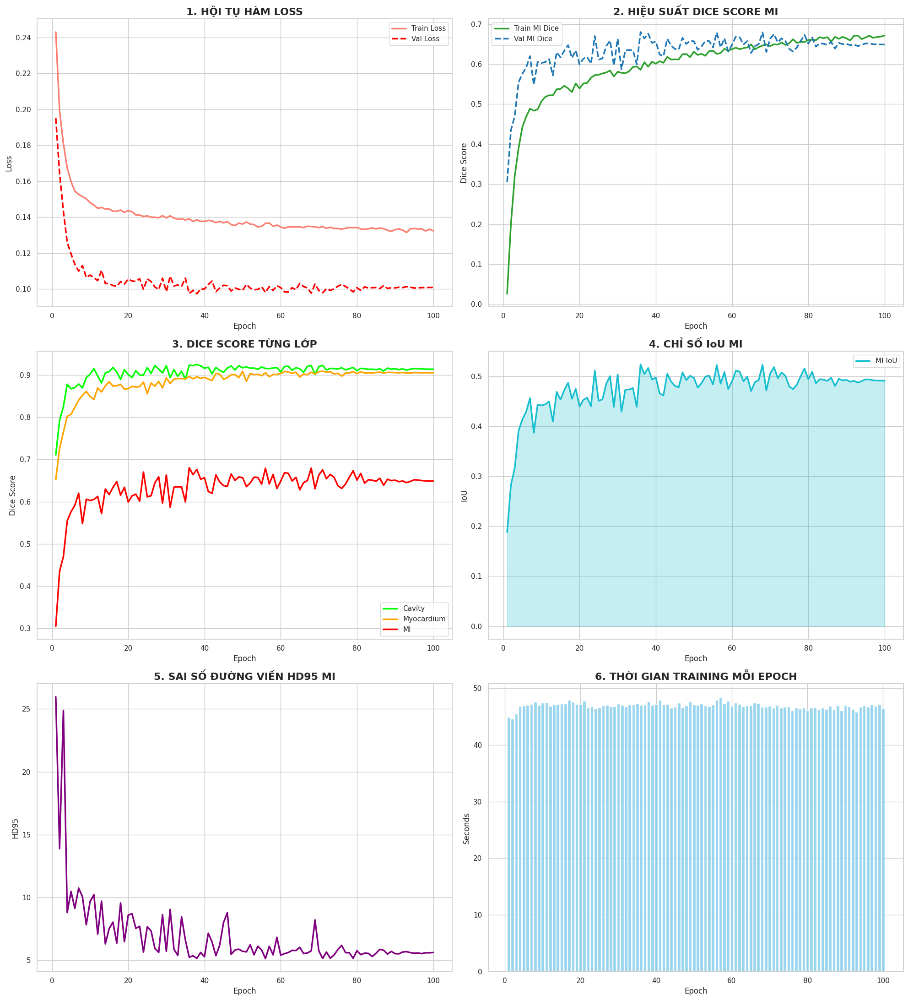


                    BÁO CÁO KẾT QUẢ DYNUNET EMIDEC                    
🏆 BEST EPOCH: 36
  > Train Loss                          :       0.1391
  > Validation Loss                     :       0.0975
  > Validation Cavity Dice              :       0.9230
  > Validation Myocardium Dice          :       0.8964
  > Validation MI Dice                  :       0.6802
  > Validation MI IoU                   :       0.5235
  > Validation MI HD95                  :         5.23
  > Training Time                       :     47.0 sec


In [18]:
# =========================================================
# FULL DASHBOARD REPORT
# DYNUNET EMIDEC MULTI-CLASS + GT PRIOR
# CSV: /kaggle/working/dynunet_emidec_multiclass_gt_prior_log.csv
# =========================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

CSV_PATH = Path("/kaggle/working/dynunet_emidec_multiclass_gt_prior_log.csv")
SAVE_DIR = Path("/kaggle/working/dynunet_emidec_dashboard")

SAVE_DIR.mkdir(exist_ok=True)


def plot_dashboard_dynunet_emidec(log_path):

    if not log_path.exists():
        print(f"❌ Không tìm thấy file log tại: {log_path}")
        return

    df = pd.read_csv(log_path)

    if df.empty:
        print("❌ File CSV đang rỗng, chưa có dữ liệu epoch.")
        return

    print(df.head())
    print(df.columns)

    sns.set_theme(style="whitegrid")

    fig, axes = plt.subplots(3, 2, figsize=(20, 22))
    plt.subplots_adjust(hspace=0.35, wspace=0.20)

    sns.lineplot(ax=axes[0, 0], data=df, x="Epoch", y="Train_Loss", label="Train Loss", color="salmon", linewidth=2.5)
    sns.lineplot(ax=axes[0, 0], data=df, x="Epoch", y="Val_Loss", label="Val Loss", color="red", linewidth=2.5, linestyle="--")
    axes[0, 0].set_title("1. HỘI TỤ HÀM LOSS", fontsize=16, fontweight="bold")
    axes[0, 0].set_xlabel("Epoch")
    axes[0, 0].set_ylabel("Loss")

    sns.lineplot(ax=axes[0, 1], data=df, x="Epoch", y="Train_Dice_MI", label="Train MI Dice", color="#2ca02c", linewidth=2.5)
    sns.lineplot(ax=axes[0, 1], data=df, x="Epoch", y="Val_Dice_MI", label="Val MI Dice", color="#1f77b4", linewidth=2.5, linestyle="--")
    axes[0, 1].set_title("2. HIỆU SUẤT DICE SCORE MI", fontsize=16, fontweight="bold")
    axes[0, 1].set_xlabel("Epoch")
    axes[0, 1].set_ylabel("Dice Score")

    sns.lineplot(ax=axes[1, 0], data=df, x="Epoch", y="Val_Dice_Cavity", label="Cavity", color="lime", linewidth=2.5)
    sns.lineplot(ax=axes[1, 0], data=df, x="Epoch", y="Val_Dice_Myo", label="Myocardium", color="orange", linewidth=2.5)
    sns.lineplot(ax=axes[1, 0], data=df, x="Epoch", y="Val_Dice_MI", label="MI", color="red", linewidth=2.5)
    axes[1, 0].set_title("3. DICE SCORE TỪNG LỚP", fontsize=16, fontweight="bold")
    axes[1, 0].set_xlabel("Epoch")
    axes[1, 0].set_ylabel("Dice Score")

    axes[1, 1].fill_between(
        df["Epoch"].astype(float),
        df["Val_IoU_MI"].astype(float),
        color="#17becf",
        alpha=0.25
    )
    axes[1, 1].plot(
        df["Epoch"],
        df["Val_IoU_MI"],
        color="#17becf",
        linewidth=2.5,
        label="MI IoU"
    )
    axes[1, 1].set_title("4. CHỈ SỐ IoU MI", fontsize=16, fontweight="bold")
    axes[1, 1].set_xlabel("Epoch")
    axes[1, 1].set_ylabel("IoU")
    axes[1, 1].legend()

    sns.lineplot(ax=axes[2, 0], data=df, x="Epoch", y="Val_HD95_MI", color="purple", linewidth=2.5)
    axes[2, 0].set_title("5. SAI SỐ ĐƯỜNG VIỀN HD95 MI", fontsize=16, fontweight="bold")
    axes[2, 0].set_xlabel("Epoch")
    axes[2, 0].set_ylabel("HD95")

    axes[2, 1].bar(df["Epoch"], df["Time_s"], color="skyblue", alpha=0.85)
    axes[2, 1].set_title("6. THỜI GIAN TRAINING MỖI EPOCH", fontsize=16, fontweight="bold")
    axes[2, 1].set_xlabel("Epoch")
    axes[2, 1].set_ylabel("Seconds")

    plt.tight_layout()

    save_path = SAVE_DIR / "dynunet_emidec_dashboard.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")

    print(f"\n✅ Đã lưu dashboard tại: {save_path}")

    plt.show()


def print_report_dynunet_emidec(log_path):

    if not log_path.exists():
        print(f"❌ Không tìm thấy file log tại: {log_path}")
        return

    df = pd.read_csv(log_path)

    if df.empty:
        print("❌ File CSV đang rỗng, chưa có dữ liệu epoch.")
        return

    best_row = df.iloc[df["Val_Dice_MI"].idxmax()]

    print("\n" + "=" * 70)
    print(f"{'BÁO CÁO KẾT QUẢ DYNUNET EMIDEC':^70}")
    print("=" * 70)

    print(f"🏆 BEST EPOCH: {int(best_row['Epoch'])}")

    metrics = [
        ["Train Loss", f"{best_row['Train_Loss']:.4f}"],
        ["Validation Loss", f"{best_row['Val_Loss']:.4f}"],
        ["Validation Cavity Dice", f"{best_row['Val_Dice_Cavity']:.4f}"],
        ["Validation Myocardium Dice", f"{best_row['Val_Dice_Myo']:.4f}"],
        ["Validation MI Dice", f"{best_row['Val_Dice_MI']:.4f}"],
        ["Validation MI IoU", f"{best_row['Val_IoU_MI']:.4f}"],
        ["Validation MI HD95", f"{best_row['Val_HD95_MI']:.2f}"],
        ["Training Time", f"{best_row['Time_s']:.1f} sec"],
    ]

    for label, value in metrics:
        print(f"  > {label:<35} : {value:>12}")

    print("=" * 70)


plot_dashboard_dynunet_emidec(CSV_PATH)
print_report_dynunet_emidec(CSV_PATH)

In [19]:
# =========================================================
# FINAL TEST EVALUATION
# DYNUNET EMIDEC MULTI-CLASS + GT PRIOR
#
# Classes:
# 0 background
# 1 cavity
# 2 myocardium
# 3 MI
# =========================================================

import torch
import pandas as pd
from tqdm.auto import tqdm

from monai.metrics import (
    DiceMetric,
    MeanIoU,
    HausdorffDistanceMetric
)

from monai.data import Dataset, DataLoader
from monai.networks.nets import DynUNet
from monai.transforms import AsDiscrete

print("=" * 80)
print("FINAL TEST - DYNUNET EMIDEC MULTI-CLASS + GT PRIOR")
print("=" * 80)


# =========================================================
# TEST LOADER
# =========================================================

test_loader = DataLoader(
    Dataset(
        test_files,
        transform=val_transforms
    ),
    batch_size=1,
    shuffle=False
)


# =========================================================
# LOAD BEST MODEL
# =========================================================

model = DynUNet(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,

    kernel_size=[
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
    ],

    strides=[
        [1, 1, 1],
        [2, 2, 1],
        [2, 2, 2],
        [2, 2, 2],
        [2, 2, 2],
    ],

    upsample_kernel_size=[
        [2, 2, 1],
        [2, 2, 2],
        [2, 2, 2],
        [2, 2, 2],
    ],

    filters=[32, 64, 128, 256, 320],

    dropout=0.2,
    deep_supervision=False,
).to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_dynunet_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


# =========================================================
# POST PROCESS
# =========================================================

post_pred = AsDiscrete(
    argmax=True,
    to_onehot=4
)

post_label = AsDiscrete(
    to_onehot=4
)


# =========================================================
# METRICS
# include_background=False:
# idx 0 = cavity
# idx 1 = myocardium
# idx 2 = MI
# =========================================================

test_dice_metric = DiceMetric(
    include_background=False,
    reduction="mean_batch"
)

test_iou_metric = MeanIoU(
    include_background=False,
    reduction="mean_batch"
)

test_hd95_metric = HausdorffDistanceMetric(
    include_background=False,
    percentile=95,
    reduction="mean_batch"
)


# =========================================================
# TEST LOOP
# =========================================================

with torch.no_grad():

    for batch in tqdm(
        test_loader,
        desc="Testing DynUNet"
    ):

        inputs = batch["dynunet_input"].to(device)
        labels = batch["label"].to(device)

        outputs = model(inputs)

        if isinstance(outputs, (list, tuple)):
            outputs = outputs[0]

        preds = [post_pred(i) for i in outputs]
        gts = [post_label(i) for i in labels]

        test_dice_metric(y_pred=preds, y=gts)
        test_iou_metric(y_pred=preds, y=gts)
        test_hd95_metric(y_pred=preds, y=gts)


# =========================================================
# AGGREGATE RESULTS
# =========================================================

test_dice_cavity = safe_metric(test_dice_metric, 0)
test_dice_myo = safe_metric(test_dice_metric, 1)
test_dice_mi = safe_metric(test_dice_metric, 2)

test_iou_cavity = safe_metric(test_iou_metric, 0)
test_iou_myo = safe_metric(test_iou_metric, 1)
test_iou_mi = safe_metric(test_iou_metric, 2)

test_hd95_cavity = safe_metric(test_hd95_metric, 0)
test_hd95_myo = safe_metric(test_hd95_metric, 1)
test_hd95_mi = safe_metric(test_hd95_metric, 2)


# =========================================================
# PRINT FINAL REPORT
# =========================================================

print("\n" + "★" * 70)
print(f"{'KẾT QUẢ CHÍNH THỨC TRÊN TẬP TEST':^70}")
print("★" * 70)

print(f"\n🫀 CAVITY:")
print(f"   Dice : {test_dice_cavity * 100:.2f}%")
print(f"   IoU  : {test_iou_cavity * 100:.2f}%")
print(f"   HD95 : {test_hd95_cavity:.4f}")

print(f"\n🫀 MYOCARDIUM:")
print(f"   Dice : {test_dice_myo * 100:.2f}%")
print(f"   IoU  : {test_iou_myo * 100:.2f}%")
print(f"   HD95 : {test_hd95_myo:.4f}")

print(f"\n🩸 MI:")
print(f"   Dice : {test_dice_mi * 100:.2f}%")
print(f"   IoU  : {test_iou_mi * 100:.2f}%")
print(f"   HD95 : {test_hd95_mi:.4f}")

print("★" * 70)


# =========================================================
# SAVE TEST CSV
# =========================================================

test_summary = pd.DataFrame([
    {
        "Model": "DynUNet_GT_Prior",

        "Test_Dice_Cavity": test_dice_cavity,
        "Test_IoU_Cavity": test_iou_cavity,
        "Test_HD95_Cavity": test_hd95_cavity,

        "Test_Dice_Myo": test_dice_myo,
        "Test_IoU_Myo": test_iou_myo,
        "Test_HD95_Myo": test_hd95_myo,

        "Test_Dice_MI": test_dice_mi,
        "Test_IoU_MI": test_iou_mi,
        "Test_HD95_MI": test_hd95_mi,
    }
])

save_test_csv = "/kaggle/working/dynunet_emidec_multiclass_gt_prior_test_results.csv"

test_summary.to_csv(
    save_test_csv,
    index=False
)

print(f"\n✅ Đã lưu test results tại:")
print(save_test_csv)

FINAL TEST - DYNUNET EMIDEC MULTI-CLASS + GT PRIOR


Testing DynUNet:   0%|          | 0/15 [00:00<?, ?it/s]


★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
                   KẾT QUẢ CHÍNH THỨC TRÊN TẬP TEST                   
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★

🫀 CAVITY:
   Dice : 92.01%
   IoU  : 85.24%
   HD95 : 2.0116

🫀 MYOCARDIUM:
   Dice : 86.54%
   IoU  : 76.79%
   HD95 : 2.4922

🩸 MI:
   Dice : 67.19%
   IoU  : 50.92%
   HD95 : 6.1070
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★

✅ Đã lưu test results tại:
/kaggle/working/dynunet_emidec_multiclass_gt_prior_test_results.csv



🌟 TRỰC QUAN HÓA SỰ TIẾN HÓA ATTENTION - DYNUNET + GT PRIOR
[*] Selected case: Case_P081
Tổng số Conv3D layers: 19


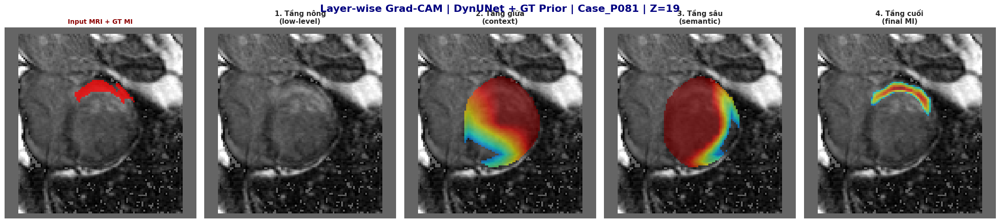

In [20]:
# ==============================================================================
# LAYER-WISE EVOLUTION
# DYNUNET MULTI-CLASS + GT PRIOR
# EMIDEC classes:
# 0 background | 1 cavity | 2 myocardium | 3 MI
# ==============================================================================

print("\n" + "=" * 80)
print("🌟 TRỰC QUAN HÓA SỰ TIẾN HÓA ATTENTION - DYNUNET + GT PRIOR")
print("=" * 80)

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.ndimage import zoom
from monai.networks.nets import DynUNet


# =========================================================
# LOAD MODEL
# =========================================================

model = DynUNet(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,

    kernel_size=[
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
    ],

    strides=[
        [1, 1, 1],
        [2, 2, 1],
        [2, 2, 2],
        [2, 2, 2],
        [2, 2, 2],
    ],

    upsample_kernel_size=[
        [2, 2, 1],
        [2, 2, 2],
        [2, 2, 2],
        [2, 2, 2],
    ],

    filters=[32, 64, 128, 256, 320],
    dropout=0.2,
    deep_supervision=False,
).to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_dynunet_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


# =========================================================
# CUSTOM GRADCAM 3D
# =========================================================

class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.handle = self.target_layer.register_forward_hook(
            self.save_activation
        )

    def save_activation(self, module, input, output):
        self.activations = output.clone()

        if self.activations.requires_grad:
            self.activations.register_hook(self.save_gradient)

        return self.activations

    def save_gradient(self, grad):
        self.gradients = grad.clone()

    def remove_hooks(self):
        self.handle.remove()

    def generate_heatmap(self, input_tensor, class_idx=3):
        self.model.zero_grad(set_to_none=True)
        self.gradients = None
        self.activations = None

        output = self.model(input_tensor)

        if isinstance(output, (list, tuple)):
            output = output[0]

        score = output[:, class_idx].sum()
        score.backward()

        if self.gradients is None or self.activations is None:
            raise RuntimeError("Layer này không lấy được gradient, bỏ qua.")

        weights = torch.mean(
            self.gradients,
            dim=(2, 3, 4),
            keepdim=True
        )

        cam = torch.sum(
            weights * self.activations,
            dim=1
        ).squeeze(0)

        cam = F.relu(cam).detach().cpu().numpy()

        if cam.max() - cam.min() > 0:
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam


# =========================================================
# RANDOM MI CASE FROM TEST
# =========================================================

mi_cases = []

for sample_info in test_files:
    data = val_transforms(sample_info)

    if data["label"].max() == 3:
        mi_cases.append(sample_info)

if len(mi_cases) > 0:
    sample_info = random.choice(mi_cases)
else:
    sample_info = random.choice(test_files)

sample_data = val_transforms(sample_info)
case_name = sample_info["case_name"]

print(f"[*] Selected case: {case_name}")


# =========================================================
# PREPARE INPUT
# =========================================================

inputs = torch.as_tensor(
    sample_data["dynunet_input"]
).unsqueeze(0).float().to(device)

labels = torch.as_tensor(
    sample_data["label"]
).unsqueeze(0).long().to(device)

mri_vol = inputs[0, 0].detach().cpu().numpy()
prior_vol = inputs[0, 1].detach().cpu().numpy()
gt_array = labels[0, 0].detach().cpu().numpy()

z_scores = np.sum(gt_array == 3, axis=(0, 1))

if z_scores.max() > 0:
    z_slice = int(np.argmax(z_scores))
else:
    z_slice = gt_array.shape[2] // 2

mri_slice = mri_vol[:, :, z_slice]
prior_slice = prior_vol[:, :, z_slice]
gt_slice = gt_array[:, :, z_slice]


# =========================================================
# PREDICTION
# =========================================================

with torch.no_grad():
    outputs = model(inputs)

    if isinstance(outputs, (list, tuple)):
        outputs = outputs[0]

    pred = torch.argmax(outputs, dim=1).detach().cpu().numpy()[0]

pred_slice = pred[:, :, z_slice]


# =========================================================
# TARGET LAYERS
# =========================================================

conv_layers = [
    m for m in model.modules()
    if isinstance(m, torch.nn.Conv3d)
]

print(f"Tổng số Conv3D layers: {len(conv_layers)}")

target_layers = {
    "1. Tầng nông\n(low-level)": conv_layers[min(1, len(conv_layers) - 1)],
    "2. Tầng giữa\n(context)": conv_layers[len(conv_layers) // 2],
    "3. Tầng sâu\n(semantic)": conv_layers[-6] if len(conv_layers) >= 6 else conv_layers[-2],
    "4. Tầng cuối\n(final MI)": conv_layers[-1],
}


# =========================================================
# PLOT
# =========================================================

fig, axes = plt.subplots(
    1,
    len(target_layers) + 1,
    figsize=(22, 5)
)

fig.suptitle(
    f"Layer-wise Grad-CAM | DynUNet + GT Prior | {case_name} | Z={z_slice}",
    fontsize=16,
    fontweight="bold",
    color="navy"
)

axes[0].imshow(np.rot90(mri_slice), cmap="gray")

gt_mi = np.ma.masked_where(
    gt_slice != 3,
    gt_slice
)

axes[0].imshow(
    np.rot90(gt_mi),
    cmap="autumn",
    alpha=0.75
)

axes[0].set_title(
    "Input MRI + GT MI",
    fontweight="bold",
    color="darkred",
    fontsize=10
)

axes[0].axis("off")


# =========================================================
# CAM PER LAYER
# =========================================================

for idx, (layer_title, layer_module) in enumerate(target_layers.items()):

    cam_engine = None

    try:
        cam_engine = GradCAM3D(
            model=model,
            target_layer=layer_module
        )

        inputs_grad = inputs.clone().detach().requires_grad_(True)

        heat_small = cam_engine.generate_heatmap(
            inputs_grad,
            class_idx=3
        )

        cam_engine.remove_hooks()

        zoom_factor = (
            gt_array.shape[0] / heat_small.shape[0],
            gt_array.shape[1] / heat_small.shape[1],
            gt_array.shape[2] / heat_small.shape[2],
        )

        heat = zoom(
            heat_small,
            zoom_factor,
            order=1
        )

        if heat.max() > 0:
            heat = heat / heat.max()

        heat_slice = heat[:, :, z_slice]

        # Gọt CAM bằng GT prior tim, không gọt bằng GT MI
        heat_slice = heat_slice * (prior_slice > 0.5)

        if heat_slice.max() > 0:
            heat_slice = heat_slice / heat_slice.max()

        # Nếu vùng ngoài MI sáng hơn MI thì đảo lại
        if (gt_slice == 3).any():
            mi_intensity = heat_slice[gt_slice == 3].mean()

            bg_mask = (prior_slice > 0.5) & (gt_slice != 3)
            bg_intensity = heat_slice[bg_mask].mean() if bg_mask.any() else 0

            if bg_intensity > mi_intensity:
                heat_slice = (1.0 - heat_slice) * (prior_slice > 0.5)

                if heat_slice.max() > 0:
                    heat_slice = heat_slice / heat_slice.max()

        heat_masked = np.ma.masked_where(
            heat_slice < 0.25,
            heat_slice
        )

        ax = axes[idx + 1]

        ax.imshow(np.rot90(mri_slice), cmap="gray")

        ax.imshow(
            np.rot90(heat_masked),
            cmap="jet",
            alpha=0.6,
            vmin=0,
            vmax=1
        )

        ax.set_title(
            layer_title,
            fontweight="bold",
            fontsize=11
        )

        ax.axis("off")

    except Exception as e:
        if cam_engine is not None:
            try:
                cam_engine.remove_hooks()
            except:
                pass

        ax = axes[idx + 1]
        ax.imshow(np.rot90(mri_slice), cmap="gray")
        ax.set_title(
            f"{layer_title}\nLỗi CAM",
            color="red",
            fontweight="bold"
        )
        ax.axis("off")

        print(f"Lỗi ở layer {layer_title}: {e}")


plt.tight_layout()
plt.show()


🔬 TRỰC QUAN HÓA GRAD-CAM & PREDICTION - DYNUNET + GT PRIOR
[*] Selected case: Case_P081
[*] Grad-CAM target layer: Conv3d(32, 4, kernel_size=(1, 1, 1), stride=(1, 1, 1))


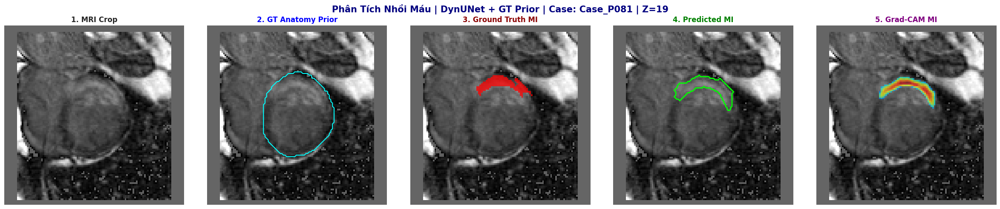

In [25]:
# =========================================================
# VISUALIZE PREDICTION + GRAD-CAM
# DYNUNET MULTI-CLASS + GT PRIOR
# 0 background | 1 cavity | 2 myocardium | 3 MI
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import random
from scipy.ndimage import zoom
from monai.networks.nets import DynUNet

print("\n" + "=" * 80)
print("🔬 TRỰC QUAN HÓA GRAD-CAM & PREDICTION - DYNUNET + GT PRIOR")
print("=" * 80)


# =========================================================
# LOAD MODEL
# =========================================================

model = DynUNet(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,
    kernel_size=[
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
    ],
    strides=[
        [1, 1, 1],
        [2, 2, 1],
        [2, 2, 2],
        [2, 2, 2],
        [2, 2, 2],
    ],
    upsample_kernel_size=[
        [2, 2, 1],
        [2, 2, 2],
        [2, 2, 2],
        [2, 2, 2],
    ],
    filters=[32, 64, 128, 256, 320],
    dropout=0.2,
    deep_supervision=False,
).to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_dynunet_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


# =========================================================
# CUSTOM GRADCAM 3D
# =========================================================

class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.handles = []
        self.handles.append(
            self.target_layer.register_forward_hook(self.save_activation)
        )
        self.handles.append(
            self.target_layer.register_full_backward_hook(self.save_gradient)
        )

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def remove_hooks(self):
        for handle in self.handles:
            handle.remove()

    def generate_heatmap(self, input_tensor, class_idx=3):
        self.model.zero_grad(set_to_none=True)

        output = self.model(input_tensor)

        if isinstance(output, (list, tuple)):
            output = output[0]

        score = output[0, class_idx].sum()
        score.backward()

        if self.gradients is None or self.activations is None:
            raise RuntimeError("Không lấy được gradient ở layer này.")

        weights = torch.mean(
            self.gradients,
            dim=(2, 3, 4),
            keepdim=True
        )

        cam = torch.sum(
            weights * self.activations,
            dim=1
        ).squeeze(0)

        cam = F.relu(cam).detach().cpu().numpy()

        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam


# =========================================================
# RANDOM CASE CÓ MI
# =========================================================

mi_cases = []

for info in test_files:
    data = val_transforms(info)

    if data["label"].max() == 3:
        mi_cases.append(info)

sample_info = random.choice(mi_cases) if len(mi_cases) > 0 else random.choice(test_files)

sample_data = val_transforms(sample_info)
case_name = sample_info["case_name"]

print(f"[*] Selected case: {case_name}")


# =========================================================
# INPUT
# =========================================================

inputs = torch.as_tensor(
    sample_data["dynunet_input"]
).unsqueeze(0).float().to(device)

labels = torch.as_tensor(
    sample_data["label"]
).unsqueeze(0).long().to(device)

mri = inputs[0, 0].detach().cpu().numpy()
prior = inputs[0, 1].detach().cpu().numpy()
gt = labels[0, 0].detach().cpu().numpy()

z_scores = np.sum(gt == 3, axis=(0, 1))

if z_scores.max() > 0:
    z = int(np.argmax(z_scores))
else:
    z = gt.shape[2] // 2

mri_slice = mri[:, :, z]
prior_slice = prior[:, :, z]
gt_slice = gt[:, :, z]


# =========================================================
# PREDICTION
# =========================================================

with torch.no_grad():
    out = model(inputs)

    if isinstance(out, (list, tuple)):
        out = out[0]

    pred = torch.argmax(out, dim=1).detach().cpu().numpy()[0]

pred_slice = pred[:, :, z]


# =========================================================
# GRAD-CAM
# =========================================================

conv_layers = [
    m for m in model.modules()
    if isinstance(m, torch.nn.Conv3d)
]

target_layer = conv_layers[-1]

print(f"[*] Grad-CAM target layer: {target_layer}")

cam_engine = GradCAM3D(
    model=model,
    target_layer=target_layer
)

inputs_grad = inputs.clone().detach().requires_grad_(True)

heat_small = cam_engine.generate_heatmap(
    inputs_grad,
    class_idx=3
)

cam_engine.remove_hooks()

zoom_factor = (
    gt.shape[0] / heat_small.shape[0],
    gt.shape[1] / heat_small.shape[1],
    gt.shape[2] / heat_small.shape[2],
)

heat = zoom(
    heat_small,
    zoom_factor,
    order=1
)

if heat.max() > 0:
    heat = heat / heat.max()

heat_slice = heat[:, :, z]

# Gọt CAM bằng GT prior tim, không dùng GT MI
heat_slice = heat_slice * (prior_slice > 0.5)

if heat_slice.max() > 0:
    heat_slice = heat_slice / heat_slice.max()

# Nếu ngoài MI sáng hơn MI thì đảo màu
if (gt_slice == 3).any():
    mi_intensity = heat_slice[gt_slice == 3].mean()

    bg_mask = (prior_slice > 0.5) & (gt_slice != 3)
    bg_intensity = heat_slice[bg_mask].mean() if bg_mask.any() else 0

    if bg_intensity > mi_intensity:
        heat_slice = (1.0 - heat_slice) * (prior_slice > 0.5)

        if heat_slice.max() > 0:
            heat_slice = heat_slice / heat_slice.max()

heat_masked = np.ma.masked_where(
    heat_slice < 0.25,
    heat_slice
)


# =========================================================
# VISUALIZE
# =========================================================

fig, axes = plt.subplots(1, 5, figsize=(24, 5))

fig.suptitle(
    f"Phân Tích Nhồi Máu | DynUNet + GT Prior | Case: {case_name} | Z={z}",
    fontsize=15,
    fontweight="bold",
    color="navy"
)

axes[0].imshow(np.rot90(mri_slice), cmap="gray")
axes[0].set_title("1. MRI Crop", fontweight="bold")
axes[0].axis("off")

axes[1].imshow(np.rot90(mri_slice), cmap="gray")
axes[1].contour(
    np.rot90(prior_slice),
    colors="cyan",
    levels=[0.5],
    linewidths=1.5
)
axes[1].set_title("2. GT Anatomy Prior", fontweight="bold", color="blue")
axes[1].axis("off")

axes[2].imshow(np.rot90(mri_slice), cmap="gray")
gt_mi = np.ma.masked_where(gt_slice != 3, gt_slice)
axes[2].imshow(np.rot90(gt_mi), cmap="autumn", alpha=0.75)
axes[2].set_title("3. Ground Truth MI", fontweight="bold", color="darkred")
axes[2].axis("off")

axes[3].imshow(np.rot90(mri_slice), cmap="gray")
pred_mi = (pred_slice == 3).astype(np.uint8)

if pred_mi.max() > 0:
    axes[3].contour(
        np.rot90(pred_mi),
        colors="lime",
        levels=[0.5],
        linewidths=2
    )

axes[3].set_title("4. Predicted MI", fontweight="bold", color="green")
axes[3].axis("off")

axes[4].imshow(np.rot90(mri_slice), cmap="gray")
axes[4].imshow(
    np.rot90(heat_masked),
    cmap="jet",
    alpha=0.65,
    vmin=0,
    vmax=1
)
axes[4].set_title("5. Grad-CAM MI", fontweight="bold", color="purple")
axes[4].axis("off")

plt.tight_layout()
plt.show()


🚀 TRỰC QUAN HÓA ATTENTION CHO 3 BỆNH NHÂN - DYNUNET + GT PRIOR
Tổng số Conv3D layers: 19

[*] Đang phân tích bệnh nhân #1: Case_P063


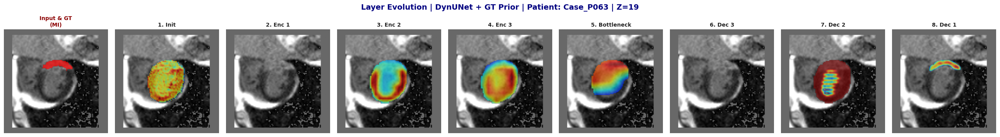


[*] Đang phân tích bệnh nhân #2: Case_P067


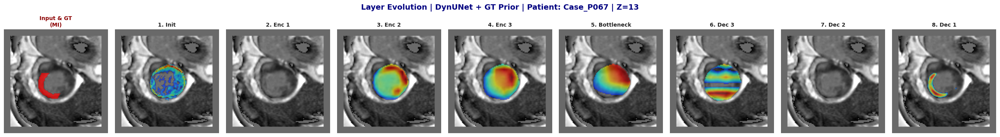


[*] Đang phân tích bệnh nhân #3: Case_P008


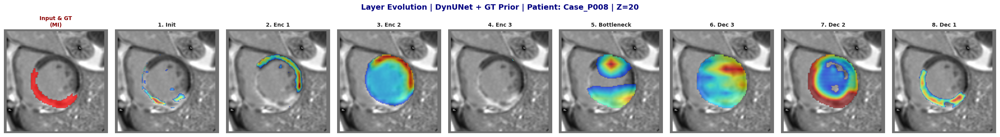

In [22]:
# ==============================================================================
# LAYER-WISE EVOLUTION
# DYNUNET MULTI-CLASS + GT PRIOR
# ==============================================================================

import numpy as np
import random
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from scipy.ndimage import zoom
from monai.networks.nets import DynUNet

print("\n" + "=" * 80)
print("🚀 TRỰC QUAN HÓA ATTENTION CHO 3 BỆNH NHÂN - DYNUNET + GT PRIOR")
print("=" * 80)


class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.handle = self.target_layer.register_forward_hook(self.save_activation)

    def save_activation(self, module, input, output):
        self.activations = output.clone()
        if self.activations.requires_grad:
            self.activations.register_hook(self.save_gradient)
        return self.activations

    def save_gradient(self, grad):
        self.gradients = grad.clone()

    def remove_hooks(self):
        self.handle.remove()

    def generate_heatmap(self, input_tensor, class_idx=3):
        self.model.zero_grad(set_to_none=True)
        self.gradients = None
        self.activations = None

        output = self.model(input_tensor)

        if isinstance(output, (list, tuple)):
            output = output[0]

        score = output[:, class_idx].sum()
        score.backward()

        if self.gradients is None or self.activations is None:
            raise RuntimeError("Layer này không lấy được gradient, bỏ qua.")

        weights = torch.mean(self.gradients, dim=(2, 3, 4), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        cam = F.relu(cam).detach().cpu().numpy()

        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam


def build_dynunet_model():
    return DynUNet(
        spatial_dims=3,
        in_channels=2,
        out_channels=4,

        kernel_size=[
            [3, 3, 3],
            [3, 3, 3],
            [3, 3, 3],
            [3, 3, 3],
            [3, 3, 3],
        ],

        strides=[
            [1, 1, 1],
            [2, 2, 1],
            [2, 2, 2],
            [2, 2, 2],
            [2, 2, 2],
        ],

        upsample_kernel_size=[
            [2, 2, 1],
            [2, 2, 2],
            [2, 2, 2],
            [2, 2, 2],
        ],

        filters=[32, 64, 128, 256, 320],
        dropout=0.2,
        deep_supervision=False,
    )


def run_3_patients_evolution(model, test_files, device, transform):

    model.load_state_dict(
        torch.load(
            "/kaggle/working/best_dynunet_emidec_multiclass_gt_prior.pth",
            map_location=device
        )
    )
    model.eval()

    conv_layers = [
        m for m in model.modules()
        if isinstance(m, torch.nn.Conv3d)
    ]

    print(f"Tổng số Conv3D layers: {len(conv_layers)}")

    step = max(1, len(conv_layers) // 8)

    target_layers = {
        "1. Init": conv_layers[0],
        "2. Enc 1": conv_layers[min(step * 1, len(conv_layers) - 1)],
        "3. Enc 2": conv_layers[min(step * 2, len(conv_layers) - 1)],
        "4. Enc 3": conv_layers[min(step * 3, len(conv_layers) - 1)],
        "5. Bottleneck": conv_layers[min(step * 4, len(conv_layers) - 1)],
        "6. Dec 3": conv_layers[-min(step * 4, len(conv_layers))],
        "7. Dec 2": conv_layers[-min(step * 2, len(conv_layers))],
        "8. Dec 1": conv_layers[-1],
    }

    mi_patients = []

    for info in test_files:
        data = transform(info)
        if data["label"].max() == 3:
            mi_patients.append((info, data))

    if not mi_patients:
        print("[!] Không có bệnh nhân nào có MI trong tập test.")
        return

    selected_patients = random.sample(
        mi_patients,
        min(3, len(mi_patients))
    )

    for p_idx, (info, data) in enumerate(selected_patients):

        print(f"\n[*] Đang phân tích bệnh nhân #{p_idx + 1}: {info['case_name']}")

        inputs = torch.as_tensor(
            data["dynunet_input"]
        ).unsqueeze(0).float().to(device)

        labels = torch.as_tensor(
            data["label"]
        ).unsqueeze(0).long().to(device)

        img_vol = inputs[0, 0].detach().cpu().numpy()
        prior_vol = inputs[0, 1].detach().cpu().numpy()
        gt_array = labels[0, 0].detach().cpu().numpy()

        z_scores = np.sum(gt_array == 3, axis=(0, 1))

        if z_scores.max() > 0:
            z_slice = int(np.argmax(z_scores))
        else:
            z_slice = gt_array.shape[2] // 2

        img_slice = img_vol[:, :, z_slice]
        prior_slice = prior_vol[:, :, z_slice]
        gt_slice = gt_array[:, :, z_slice]

        fig, axes = plt.subplots(
            1,
            len(target_layers) + 1,
            figsize=(26, 3.8)
        )

        fig.suptitle(
            f"Layer Evolution | DynUNet + GT Prior | Patient: {info['case_name']} | Z={z_slice}",
            fontsize=14,
            fontweight="bold",
            color="navy"
        )

        axes[0].imshow(np.rot90(img_slice), cmap="gray")

        gt_mask = np.ma.masked_where(gt_slice != 3, gt_slice)

        axes[0].imshow(
            np.rot90(gt_mask),
            cmap="autumn",
            alpha=0.7
        )

        axes[0].set_title(
            "Input & GT\n(MI)",
            fontweight="bold",
            color="darkred",
            fontsize=10
        )

        axes[0].axis("off")

        for i, (layer_name, layer_module) in enumerate(target_layers.items()):

            ax = axes[i + 1]
            cam_extractor = None

            try:
                cam_extractor = GradCAM3D(
                    model=model,
                    target_layer=layer_module
                )

                img_grad = inputs.clone().detach().requires_grad_(True)

                heat_small = cam_extractor.generate_heatmap(
                    img_grad,
                    class_idx=3
                )

                cam_extractor.remove_hooks()

                zoom_factor = (
                    gt_array.shape[0] / heat_small.shape[0],
                    gt_array.shape[1] / heat_small.shape[1],
                    gt_array.shape[2] / heat_small.shape[2],
                )

                heat = zoom(
                    heat_small,
                    zoom_factor,
                    order=1
                )

                if heat.max() > 0:
                    heat = heat / heat.max()

                heat_slice = heat[:, :, z_slice]

                heat_slice = heat_slice * (prior_slice > 0.5)

                if heat_slice.max() > 0:
                    heat_slice = heat_slice / heat_slice.max()

                if i >= 6 and (gt_slice == 3).any():
                    scar_int = heat_slice[gt_slice == 3].mean()

                    bg_mask = (prior_slice > 0.5) & (gt_slice != 3)
                    bg_int = heat_slice[bg_mask].mean() if bg_mask.any() else 0

                    if bg_int > scar_int:
                        heat_slice = (1.0 - heat_slice) * (prior_slice > 0.5)

                        if heat_slice.max() > 0:
                            heat_slice = heat_slice / heat_slice.max()

                heat_slice_masked = np.ma.masked_where(
                    heat_slice < 0.15,
                    heat_slice
                )

                ax.imshow(np.rot90(img_slice), cmap="gray")
                ax.imshow(
                    np.rot90(heat_slice_masked),
                    cmap="jet",
                    alpha=0.6,
                    vmin=0,
                    vmax=1
                )

                ax.set_title(
                    layer_name,
                    fontsize=10,
                    fontweight="bold"
                )

            except Exception as e:
                if cam_extractor is not None:
                    try:
                        cam_extractor.remove_hooks()
                    except:
                        pass

                ax.imshow(np.rot90(img_slice), cmap="gray")
                ax.set_title(
                    f"{layer_name}\n[Bỏ qua]",
                    color="gray",
                    fontsize=9
                )

                print(f"Lỗi layer {layer_name}: {e}")

            ax.axis("off")

        plt.tight_layout()
        plt.show()


model = build_dynunet_model().to(device)

run_3_patients_evolution(
    model=model,
    test_files=test_files,
    device=device,
    transform=val_transforms
)


🧠 UNCERTAINTY MAP - DYNUNET + GT PRIOR
[*] Đang chạy MC Dropout (T=15) cho 3 bệnh nhân...

[*] Đang phân tích: Case_P036


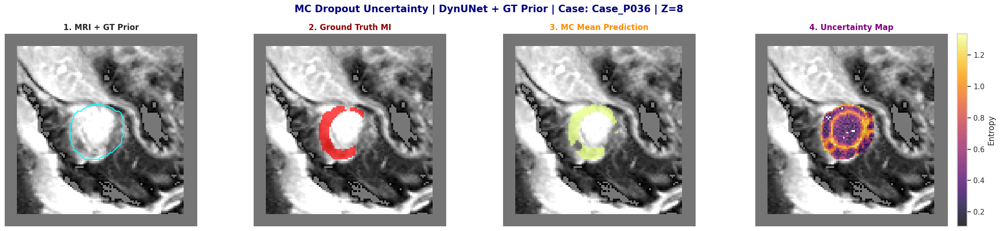


[*] Đang phân tích: Case_P067


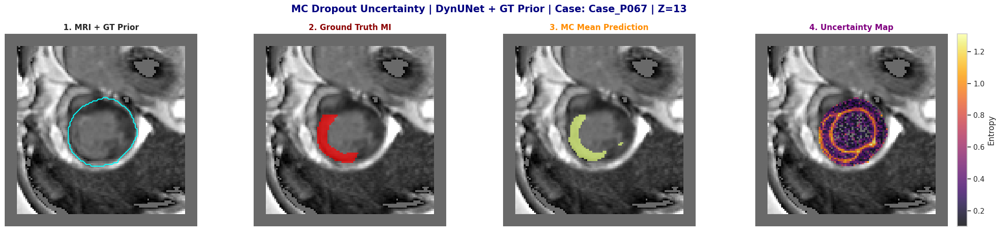


[*] Đang phân tích: Case_P001


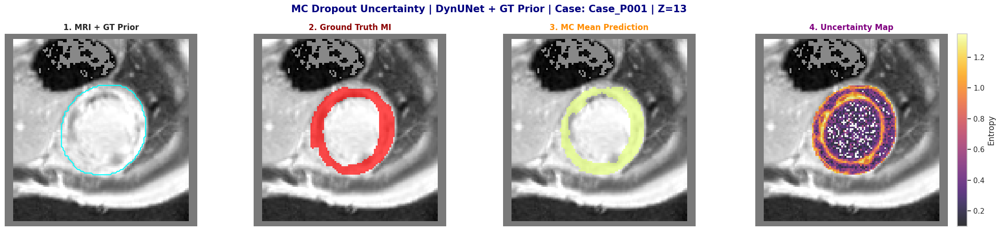

In [23]:
# ==============================================================================
# 🧠 MC DROPOUT UNCERTAINTY MAP
# DYNUNET MULTI-CLASS + GT PRIOR
# ==============================================================================

import numpy as np
import random
import matplotlib.pyplot as plt
import torch
from monai.networks.nets import DynUNet

print("\n" + "=" * 80)
print("🧠 UNCERTAINTY MAP - DYNUNET + GT PRIOR")
print("=" * 80)


model = DynUNet(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,

    kernel_size=[
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
    ],

    strides=[
        [1, 1, 1],
        [2, 2, 1],
        [2, 2, 2],
        [2, 2, 2],
        [2, 2, 2],
    ],

    upsample_kernel_size=[
        [2, 2, 1],
        [2, 2, 2],
        [2, 2, 2],
        [2, 2, 2],
    ],

    filters=[32, 64, 128, 256, 320],
    dropout=0.2,
    deep_supervision=False,
).to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_dynunet_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


def enable_dropout_only(m):
    if isinstance(
        m,
        (
            torch.nn.Dropout,
            torch.nn.Dropout2d,
            torch.nn.Dropout3d
        )
    ):
        m.train()


def compute_uncertainty_mc_dropout(
    model,
    dynunet_input,
    T=15
):
    model.eval()
    model.apply(enable_dropout_only)

    outputs = []

    with torch.no_grad():
        for _ in range(T):

            logits = model(dynunet_input)

            if isinstance(logits, (list, tuple)):
                logits = logits[0]

            probs = torch.softmax(logits, dim=1)
            outputs.append(probs)

    outputs = torch.stack(outputs)

    mean_prob = torch.mean(outputs, dim=0)

    epsilon = 1e-6

    uncertainty_map = -torch.sum(
        mean_prob * torch.log(mean_prob + epsilon),
        dim=1
    )

    mask_tim = dynunet_input[:, 1, ...]

    uncertainty_map = uncertainty_map * mask_tim

    model.eval()

    return mean_prob, uncertainty_map


def visualize_uncertainty_xai(
    model,
    test_files,
    device,
    transform,
    num_samples=3
):

    print(f"[*] Đang chạy MC Dropout (T=15) cho {num_samples} bệnh nhân...")

    mi_patients = []

    for info in test_files:
        data = transform(info)

        if data["label"].max() == 3:
            mi_patients.append((info, data))

    if not mi_patients:
        print("[!] Không có bệnh nhân MI trong tập test.")
        return

    selected_patients = random.sample(
        mi_patients,
        min(num_samples, len(mi_patients))
    )

    for p_idx, (info, data) in enumerate(selected_patients):

        print(f"\n[*] Đang phân tích: {info['case_name']}")

        inputs = torch.as_tensor(
            data["dynunet_input"]
        ).unsqueeze(0).float().to(device)

        labels = torch.as_tensor(
            data["label"]
        ).unsqueeze(0).long().to(device)

        mean_prob, unc_map = compute_uncertainty_mc_dropout(
            model,
            inputs,
            T=15
        )

        pred_mask = torch.argmax(
            mean_prob,
            dim=1
        ).cpu().numpy()[0]

        unc_map_np = unc_map.cpu().numpy()[0]
        gt_array = labels[0, 0].cpu().numpy()

        z_scores = np.sum(gt_array == 3, axis=(0, 1))

        if z_scores.max() > 0:
            z_slice = int(np.argmax(z_scores))
        else:
            z_slice = gt_array.shape[2] // 2

        img_slice = inputs[0, 0, :, :, z_slice].cpu().numpy()
        mask_tim_slice = inputs[0, 1, :, :, z_slice].cpu().numpy()

        gt_slice = gt_array[:, :, z_slice]
        pred_slice = pred_mask[:, :, z_slice]
        unc_slice = unc_map_np[:, :, z_slice]

        unc_slice_masked = np.ma.masked_where(
            unc_slice < 0.10,
            unc_slice
        )

        fig, axes = plt.subplots(1, 4, figsize=(22, 5))

        fig.suptitle(
            f"MC Dropout Uncertainty | DynUNet + GT Prior | Case: {info['case_name']} | Z={z_slice}",
            fontsize=15,
            fontweight="bold",
            color="navy"
        )

        axes[0].imshow(np.rot90(img_slice), cmap="gray")
        axes[0].contour(
            np.rot90(mask_tim_slice),
            colors="cyan",
            levels=[0.5],
            linewidths=1.5
        )
        axes[0].set_title("1. MRI + GT Prior", fontweight="bold")
        axes[0].axis("off")

        axes[1].imshow(np.rot90(img_slice), cmap="gray")
        gt_masked = np.ma.masked_where(gt_slice != 3, gt_slice)
        axes[1].imshow(np.rot90(gt_masked), cmap="autumn", alpha=0.7)
        axes[1].set_title("2. Ground Truth MI", fontweight="bold", color="darkred")
        axes[1].axis("off")

        axes[2].imshow(np.rot90(img_slice), cmap="gray")
        pred_masked = np.ma.masked_where(pred_slice != 3, pred_slice)
        axes[2].imshow(np.rot90(pred_masked), cmap="Wistia", alpha=0.7)
        axes[2].set_title("3. MC Mean Prediction", fontweight="bold", color="darkorange")
        axes[2].axis("off")

        axes[3].imshow(np.rot90(img_slice), cmap="gray")
        im_unc = axes[3].imshow(
            np.rot90(unc_slice_masked),
            cmap="inferno",
            alpha=0.8
        )
        axes[3].set_title("4. Uncertainty Map", fontweight="bold", color="purple")
        axes[3].axis("off")

        plt.colorbar(
            im_unc,
            ax=axes[3],
            fraction=0.046,
            pad=0.04,
            label="Entropy"
        )

        plt.tight_layout()
        plt.show()


visualize_uncertainty_xai(
    model=model,
    test_files=test_files,
    device=device,
    transform=val_transforms,
    num_samples=3
)


🔬 TRỰC QUAN HÓA GRAD-CAM & PREDICTION - DYNUNET + GT PRIOR
[*] Selected case: Case_P091
[*] Grad-CAM target layer: model.output_block.conv.conv


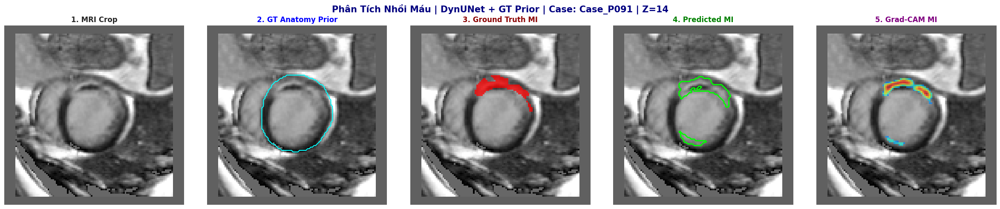

In [24]:
# =========================================================
# VISUALIZE PREDICTION + GRAD-CAM
# DYNUNET MULTI-CLASS + GT PRIOR
# 0 background | 1 cavity | 2 myocardium | 3 MI
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import random
from monai.visualize import GradCAM
from monai.networks.nets import DynUNet

print("\n" + "=" * 80)
print("🔬 TRỰC QUAN HÓA GRAD-CAM & PREDICTION - DYNUNET + GT PRIOR")
print("=" * 80)


# =========================================================
# LOAD MODEL
# =========================================================

model = DynUNet(
    spatial_dims=3,
    in_channels=2,
    out_channels=4,

    kernel_size=[
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
        [3, 3, 3],
    ],

    strides=[
        [1, 1, 1],
        [2, 2, 1],
        [2, 2, 2],
        [2, 2, 2],
        [2, 2, 2],
    ],

    upsample_kernel_size=[
        [2, 2, 1],
        [2, 2, 2],
        [2, 2, 2],
        [2, 2, 2],
    ],

    filters=[32, 64, 128, 256, 320],
    dropout=0.2,
    deep_supervision=False,
).to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/best_dynunet_emidec_multiclass_gt_prior.pth",
        map_location=device
    )
)

model.eval()


# =========================================================
# WRAPPER CHO MONAI GRADCAM
# =========================================================

class GradCAMWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        out = self.model(x)

        if isinstance(out, (list, tuple)):
            out = out[0]

        return out


wrapped_model = GradCAMWrapper(model).to(device)
wrapped_model.eval()


# =========================================================
# FIND RANDOM MI CASE
# =========================================================

mi_cases = []

for info in test_files:
    data = val_transforms(info)

    if data["label"].max() == 3:
        mi_cases.append(info)

sample_info = random.choice(mi_cases) if len(mi_cases) > 0 else random.choice(test_files)

sample_data = val_transforms(sample_info)
case_name = sample_info["case_name"]

print(f"[*] Selected case: {case_name}")


# =========================================================
# PREPARE INPUT
# =========================================================

inputs = torch.as_tensor(
    sample_data["dynunet_input"]
).unsqueeze(0).float().to(device)

labels = torch.as_tensor(
    sample_data["label"]
).unsqueeze(0).long().to(device)

inputs.requires_grad_(True)

img_vol = inputs[0, 0].detach().cpu().numpy()
prior_vol = inputs[0, 1].detach().cpu().numpy()
gt_array = labels[0, 0].detach().cpu().numpy()

z_scores = np.sum(gt_array == 3, axis=(0, 1))

if z_scores.max() > 0:
    z_slice = int(np.argmax(z_scores))
else:
    z_slice = gt_array.shape[2] // 2

img_slice = img_vol[:, :, z_slice]
prior_slice = prior_vol[:, :, z_slice]
gt_slice = gt_array[:, :, z_slice]


# =========================================================
# PREDICTION
# =========================================================

with torch.no_grad():
    outputs = model(inputs)

    if isinstance(outputs, (list, tuple)):
        outputs = outputs[0]

    preds = torch.argmax(outputs, dim=1).detach().cpu().numpy()[0]

pred_slice = preds[:, :, z_slice]


# =========================================================
# GRAD-CAM
# =========================================================

conv_layer_names = [
    name for name, module in wrapped_model.named_modules()
    if isinstance(module, torch.nn.Conv3d)
]

target_layer = conv_layer_names[-1]

print(f"[*] Grad-CAM target layer: {target_layer}")

cam = GradCAM(
    nn_module=wrapped_model,
    target_layers=target_layer
)

heatmap = cam(
    x=inputs,
    class_idx=3
)

heat_slice = heatmap[0, 0, :, :, z_slice].detach().cpu().numpy()

heat_slice = np.maximum(heat_slice, 0)

if heat_slice.max() > 0:
    heat_slice = heat_slice / heat_slice.max()

# Gọt nhiễu bằng GT prior tim, không dùng GT MI
heat_slice = heat_slice * (prior_slice > 0.5)

if heat_slice.max() > 0:
    heat_slice = heat_slice / heat_slice.max()

# Logic đảo màu giống code cũ
if (gt_slice == 3).any():
    mi_intensity = heat_slice[gt_slice == 3].mean()

    bg_mask = (prior_slice > 0.5) & (gt_slice != 3)
    bg_intensity = heat_slice[bg_mask].mean() if bg_mask.any() else 0

    if bg_intensity > mi_intensity:
        heat_slice = (1.0 - heat_slice) * (prior_slice > 0.5)

        if heat_slice.max() > 0:
            heat_slice = heat_slice / heat_slice.max()

heat_slice_masked = np.ma.masked_where(
    heat_slice < 0.25,
    heat_slice
)


# =========================================================
# VISUALIZATION
# =========================================================

fig, axes = plt.subplots(1, 5, figsize=(24, 5))

fig.suptitle(
    f"Phân Tích Nhồi Máu | DynUNet + GT Prior | Case: {case_name} | Z={z_slice}",
    fontsize=15,
    fontweight="bold",
    color="navy"
)

axes[0].imshow(np.rot90(img_slice), cmap="gray")
axes[0].set_title("1. MRI Crop", fontweight="bold")
axes[0].axis("off")

axes[1].imshow(np.rot90(img_slice), cmap="gray")
axes[1].contour(
    np.rot90(prior_slice),
    colors="cyan",
    levels=[0.5],
    linewidths=1.5
)
axes[1].set_title("2. GT Anatomy Prior", fontweight="bold", color="blue")
axes[1].axis("off")

axes[2].imshow(np.rot90(img_slice), cmap="gray")
gt_mi_mask = np.ma.masked_where(gt_slice != 3, gt_slice)
axes[2].imshow(np.rot90(gt_mi_mask), cmap="autumn", alpha=0.75)
axes[2].set_title("3. Ground Truth MI", fontweight="bold", color="darkred")
axes[2].axis("off")

axes[3].imshow(np.rot90(img_slice), cmap="gray")
pred_mi_only = (pred_slice == 3).astype(np.uint8)

if pred_mi_only.max() > 0:
    axes[3].contour(
        np.rot90(pred_mi_only),
        colors="lime",
        levels=[0.5],
        linewidths=2
    )

axes[3].set_title("4. Predicted MI", fontweight="bold", color="green")
axes[3].axis("off")

axes[4].imshow(np.rot90(img_slice), cmap="gray")
axes[4].imshow(
    np.rot90(heat_slice_masked),
    cmap="jet",
    alpha=0.65,
    vmin=0,
    vmax=1
)
axes[4].set_title("5. Grad-CAM MI", fontweight="bold", color="purple")
axes[4].axis("off")

plt.tight_layout()
plt.show()

# ENSEMBLE


🚀 [GIAI ĐOẠN 3 - CÁCH 2] TRÍCH XUẤT ĐẶC TRƯNG & CROSS-VALIDATION TOÀN TẬP
🔍 Áp dụng tiêu chuẩn EMIDEC: Gán nhãn dựa trên ký tự 'N' và 'P'...

📊 Gộp toàn bộ dữ liệu để đánh giá Cross-Validation...


Trích xuất đặc trưng:   0%|          | 0/100 [00:00<?, ?it/s]


🤖 Đang phân loại bằng Siêu Hội Đồng (RF + SVM + MLP)...

★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
🎯 ĐỘ CHÍNH XÁC CROSS-VALIDATION TRÊN TOÀN BỘ 100 BỆNH NHÂN: 97.00%
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★

CHI TIẾT BÁO CÁO LÂM SÀNG:
               precision    recall  f1-score   support

   Normal (0)       0.97      0.94      0.95        33
Infarcted (1)       0.97      0.99      0.98        67

     accuracy                           0.97       100
    macro avg       0.97      0.96      0.97       100
 weighted avg       0.97      0.97      0.97       100



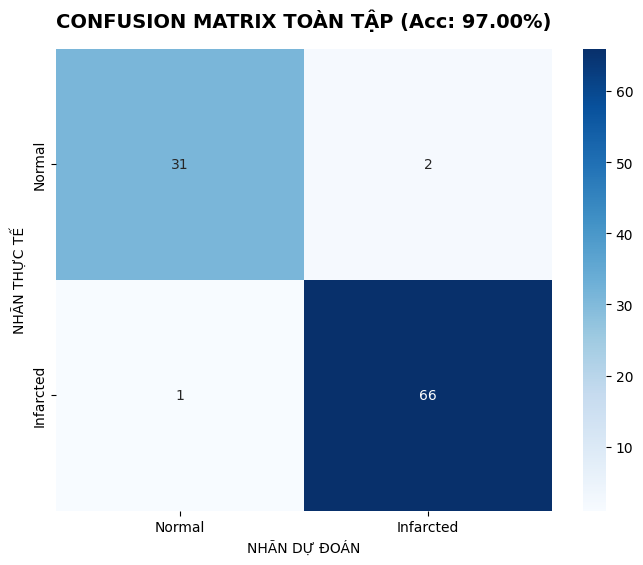

In [20]:
import pandas as pd
import numpy as np
import scipy.ndimage as ndi
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

print("\n" + "=" * 80)
print("🚀 [GIAI ĐOẠN 3 - CÁCH 2] TRÍCH XUẤT ĐẶC TRƯNG & CROSS-VALIDATION TOÀN TẬP")
print("=" * 80)

import os
import glob

import pandas as pd
import numpy as np

# ======================================================================
# 0. GÁN NHÃN LÂM SÀNG DỰA TRÊN TÊN CASE (CHUẨN EMIDEC 2020)
# ======================================================================
print("🔍 Áp dụng tiêu chuẩn EMIDEC: Gán nhãn dựa trên ký tự 'N' và 'P'...")

def get_true_label(case_name, mi_vol=None):
    """
    Dựa trên tài liệu gốc của EMIDEC 2020: 
    - 33 ca Normal chứa ký tự 'N' (VD: Case_N046, Case N014) -> Nhãn 0
    - 67 ca Pathological chứa ký tự 'P' (VD: Case_P051) -> Nhãn 1
    """
    # Viết hoa toàn bộ tên để dễ xử lý (vd: case_n046 -> CASE_N046)
    name_upper = case_name.upper()
    
    # Xóa chữ 'CASE' đi để tránh nhầm lẫn, sau đó tìm 'N' hoặc 'P'
    clean_name = name_upper.replace('CASE', '')
    
    if 'N' in clean_name:
        return 0  # Bệnh nhân Bình thường (Normal)
    elif 'P' in clean_name:
        return 1  # Bệnh nhân Nhồi máu (Pathological/Infarcted)
    else:
        # Fallback cực kỳ an toàn nếu có ca nào bị sai định dạng tên
        return 1 if mi_vol is not None and mi_vol > 0.5 else 0

# ----------------------------------------------------------------------
# 1. HÀM TRÍCH XUẤT ĐẶC TRƯNG (FEATURE EXTRACTION)
# ----------------------------------------------------------------------
def extract_emidec_features_v2(file_list, model, device):
    features = []
    model.load_state_dict(torch.load(best_model_path, map_location=device))
    model.eval()

    for item in tqdm(file_list, desc="Trích xuất đặc trưng"):
        data = val_transforms(item)
        inputs = data["unetpp_input"].unsqueeze(0).to(device)
        
        with torch.no_grad():
            outputs = model(inputs)
            if isinstance(outputs, (list, tuple)): outputs = outputs[0]
            pred_mask = torch.argmax(outputs, dim=1).squeeze().cpu().numpy()

        voxel_vol = (1.5 * 1.5 * 5.0) / 1000.0 
        
        cavity_vol = np.sum(pred_mask == 1) * voxel_vol
        myo_vol = np.sum(pred_mask == 2) * voxel_vol
        mi_vol = np.sum(pred_mask == 3) * voxel_vol
        
        mi_ratio = mi_vol / (myo_vol + 1e-6)
        
        mi_mask = (pred_mask == 3)
        max_mi_thick = np.max(ndi.distance_transform_edt(mi_mask, sampling=(1.5, 1.5, 5.0))) if np.sum(mi_mask) > 0 else 0

        # Lấy nhãn Y KHOA chuẩn
        clinical_label = get_true_label(item['case_name'], mi_vol)

        features.append({
            'Case': item['case_name'],
            'Cavity_Vol': cavity_vol,
            'Myo_Vol': myo_vol,
            'MI_Vol': mi_vol,
            'MI_Ratio': mi_ratio,
            'Max_MI_Thickness': max_mi_thick,
            'Label': clinical_label
        })
        
    return pd.DataFrame(features)

# ----------------------------------------------------------------------
# 2. XỬ LÝ TRÊN TOÀN BỘ DATASET (KHÔNG CHIA TẬP TEST RỜI RẠC NỮA)
# ----------------------------------------------------------------------
print("\n📊 Gộp toàn bộ dữ liệu để đánh giá Cross-Validation...")
all_files = train_files + val_files + test_files # Gộp chung cả 100 ca
df_all = extract_emidec_features_v2(all_files, model, device)

X_all = df_all.drop(['Case', 'Label'], axis=1).values
y_all = df_all['Label'].values

# Chuẩn hóa Z-score toàn tập
scaler = StandardScaler()
X_all_scaled = scaler.fit_transform(X_all)

# ----------------------------------------------------------------------
# 3. HUẤN LUYỆN & ĐÁNH GIÁ BẰNG CROSS_VAL_PREDICT
# ----------------------------------------------------------------------
print("\n🤖 Đang phân loại bằng Siêu Hội Đồng (RF + SVM + MLP)...")

# Khởi tạo thuật toán y như cũ
rf = RandomForestClassifier(n_estimators=250, max_depth=5, class_weight='balanced', random_state=SEED)
svm = SVC(kernel='rbf', C=1.5, probability=True, class_weight='balanced', random_state=SEED)
mlp = MLPClassifier(hidden_layer_sizes=(16, 8), solver='lbfgs', alpha=0.5, max_iter=3000, random_state=SEED)

vclf = VotingClassifier(
    estimators=[('rf', rf), ('svm', svm), ('mlp', mlp)],
    voting='soft', weights=[2, 1, 1]
)

# cross_val_predict sẽ tự động chia 5 fold, train trên 4 fold và dự đoán fold còn lại.
# Kết quả trả về `y_pred_cv` là dự đoán OOF (Out-Of-Fold) cho TOÀN BỘ 100 bệnh nhân.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
y_pred_cv = cross_val_predict(vclf, X_all_scaled, y_all, cv=skf)

# ----------------------------------------------------------------------
# 4. IN BÁO CÁO TOÀN DIỆN
# ----------------------------------------------------------------------
acc = accuracy_score(y_all, y_pred_cv)

print("\n" + "★" * 60)
print(f"🎯 ĐỘ CHÍNH XÁC CROSS-VALIDATION TRÊN TOÀN BỘ {len(y_all)} BỆNH NHÂN: {acc*100:.2f}%")
print("★" * 60)

print("\nCHI TIẾT BÁO CÁO LÂM SÀNG:")
print(classification_report(y_all, y_pred_cv, target_names=["Normal (0)", "Infarcted (1)"]))

# Vẽ Confusion Matrix tổng
cm = confusion_matrix(y_all, y_pred_cv)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Normal", "Infarcted"], yticklabels=["Normal", "Infarcted"])
plt.title(f'CONFUSION MATRIX TOÀN TẬP (Acc: {acc*100:.2f}%)', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('NHÃN THỰC TẾ')
plt.xlabel('NHÃN DỰ ĐOÁN')
plt.show()


Đang tính toán xác suất (Probability) từ Siêu Hội Đồng...

★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
🎯 ĐỘ CHÍNH XÁC TOÀN TẬP: 97.00%
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★

CHI TIẾT BÁO CÁO LÂM SÀNG:
               precision    recall  f1-score   support

   Normal (0)       0.97      0.94      0.95        33
Infarcted (1)       0.97      0.99      0.98        67

     accuracy                           0.97       100
    macro avg       0.97      0.96      0.97       100
 weighted avg       0.97      0.97      0.97       100



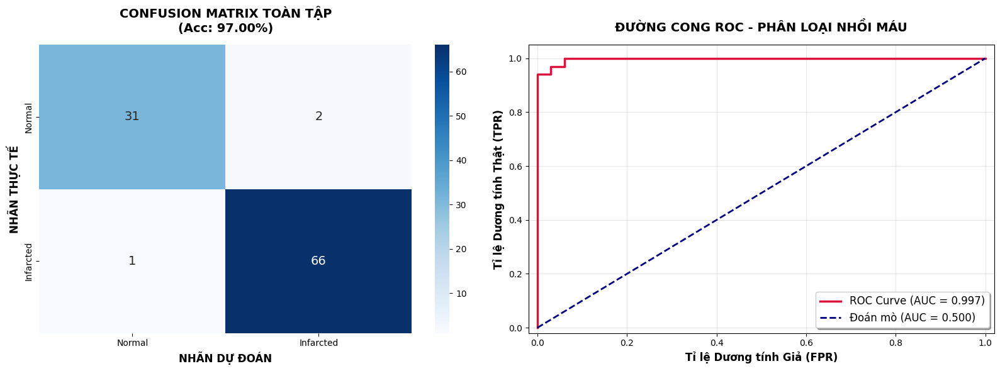

In [21]:
from sklearn.metrics import roc_curve, auc, confusion_matrix, classification_report, accuracy_score
from sklearn.model_selection import cross_val_predict
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ======================================================================
# 5. IN BÁO CÁO TOÀN DIỆN VÀ VẼ BIỂU ĐỒ (CONFUSION MATRIX & ROC NHỊ PHÂN)
# ======================================================================

# 1. TÍNH TOÁN XÁC SUẤT CHỈ 1 LẦN DUY NHẤT (TỐI ƯU TỐC ĐỘ)
print("\nĐang tính toán xác suất (Probability) từ Siêu Hội Đồng...")
y_prob_cv = cross_val_predict(vclf, X_all_scaled, y_all, cv=skf, method='predict_proba')

# Từ xác suất, suy ra nhãn dự đoán (Thằng nào xác suất > 50% thì là lớp 1)
y_pred_cv = np.argmax(y_prob_cv, axis=1)

# 2. TÍNH ĐỘ CHÍNH XÁC
acc = accuracy_score(y_all, y_pred_cv)

print("\n" + "★" * 60)
print(f"🎯 ĐỘ CHÍNH XÁC TOÀN TẬP: {acc*100:.2f}%")
print("★" * 60)

# Khai báo chính xác 2 lớp của EMIDEC
class_names = ["Normal (0)", "Infarcted (1)"] 

print("\nCHI TIẾT BÁO CÁO LÂM SÀNG:")
print(classification_report(y_all, y_pred_cv, target_names=class_names))

# 3. VẼ BIỂU ĐỒ KẾT HỢP (1x2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ---- Biểu đồ 1: CONFUSION MATRIX ----
cm = confusion_matrix(y_all, y_pred_cv)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=["Normal", "Infarcted"], 
            yticklabels=["Normal", "Infarcted"], ax=ax1,
            annot_kws={"size": 14})
ax1.set_title(f'CONFUSION MATRIX TOÀN TẬP\n(Acc: {acc*100:.2f}%)', fontsize=14, fontweight='bold', pad=15)
ax1.set_ylabel('NHÃN THỰC TẾ', fontsize=12, fontweight='bold')
ax1.set_xlabel('NHÃN DỰ ĐOÁN', fontsize=12, fontweight='bold')

# ---- Biểu đồ 2: ROC CURVE NHỊ PHÂN ----
# Lấy cột xác suất của lớp 1 (Infarcted)
y_prob_positive = y_prob_cv[:, 1]

fpr, tpr, _ = roc_curve(y_all, y_prob_positive)
roc_auc = auc(fpr, tpr)

ax2.plot(fpr, tpr, color='crimson', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.3f})')
ax2.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Đoán mò (AUC = 0.500)')

# Trang trí
ax2.set_xlim([-0.02, 1.02])
ax2.set_ylim([-0.02, 1.05])
ax2.set_xlabel('Tỉ lệ Dương tính Giả (FPR)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Tỉ lệ Dương tính Thật (TPR)', fontsize=12, fontweight='bold')
ax2.set_title('ĐƯỜNG CONG ROC - PHÂN LOẠI NHỒI MÁU', fontsize=14, fontweight='bold', pad=15)
ax2.legend(loc="lower right", fontsize=12, frameon=True, shadow=True)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


📊 BẮT ĐẦU TÍNH TOÁN TẦM QUAN TRỌNG CỦA ĐẶC TRƯNG (XAI)
Đang xáo trộn dữ liệu 15 lần để đo lường độ sụt giảm chính xác...


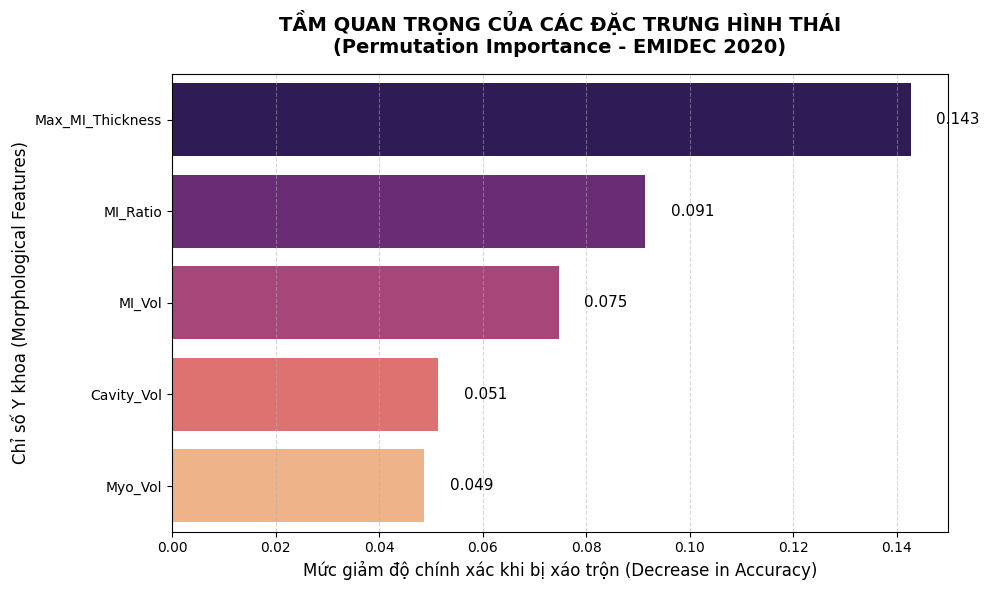

In [23]:
from sklearn.inspection import permutation_importance
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

print("\n" + "="*60)
print("📊 BẮT ĐẦU TÍNH TOÁN TẦM QUAN TRỌNG CỦA ĐẶC TRƯNG (XAI)")
print("="*60)

# 1. Huấn luyện lại mô hình trên toàn bộ dữ liệu để giải thích (Interpretability)
# (Bước K-Fold trước đó chỉ dùng để đánh giá, giờ ta cần 1 mô hình 'chín muồi' nhất)
vclf.fit(X_all_scaled, y_all)

# 2. Lấy tên các đặc trưng từ DataFrame
feature_names = df_all.drop(['Case', 'Label'], axis=1).columns

# 3. Tính toán Permutation Importance
# Thuật toán sẽ thử xáo trộn từng cột dữ liệu. Cột nào bị xáo trộn mà làm 
# độ chính xác (Accuracy) giảm mạnh nhất -> Cột đó quan trọng nhất!
print("Đang xáo trộn dữ liệu 15 lần để đo lường độ sụt giảm chính xác...")
result = permutation_importance(
    vclf, X_all_scaled, y_all, 
    n_repeats=15, random_state=42, n_jobs=-1
)

# 4. Sắp xếp kết quả từ cao xuống thấp
sorted_idx = result.importances_mean.argsort()[::-1]
sorted_features = [feature_names[i] for i in sorted_idx]
sorted_importances = result.importances_mean[sorted_idx]

# 5. Vẽ biểu đồ Barplot
plt.figure(figsize=(10, 6))
sns.barplot(x=sorted_importances, y=sorted_features, palette='magma')

# Trang trí biểu đồ chuẩn báo cáo khoa học
plt.title('TẦM QUAN TRỌNG CỦA CÁC ĐẶC TRƯNG HÌNH THÁI\n(Permutation Importance - EMIDEC 2020)', 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mức giảm độ chính xác khi bị xáo trộn (Decrease in Accuracy)', fontsize=12)
plt.ylabel('Chỉ số Y khoa (Morphological Features)', fontsize=12)

# Thêm giá trị số lên từng cột cho rõ ràng
for index, value in enumerate(sorted_importances):
    plt.text(value + 0.005, index, f'{value:.3f}', va='center', fontsize=11)

plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


🧠 BẮT ĐẦU PHÂN TÍCH SHAP (EXPLAINABLE AI CAO CẤP)
Đang tính toán SHAP values... (Hãy kiên nhẫn một chút nhé)


  0%|          | 0/100 [00:00<?, ?it/s]

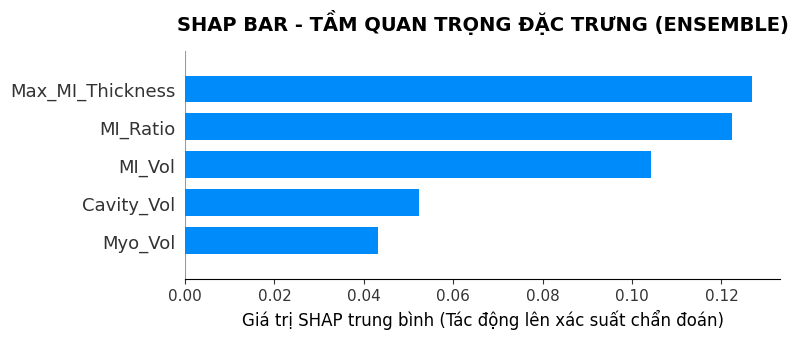

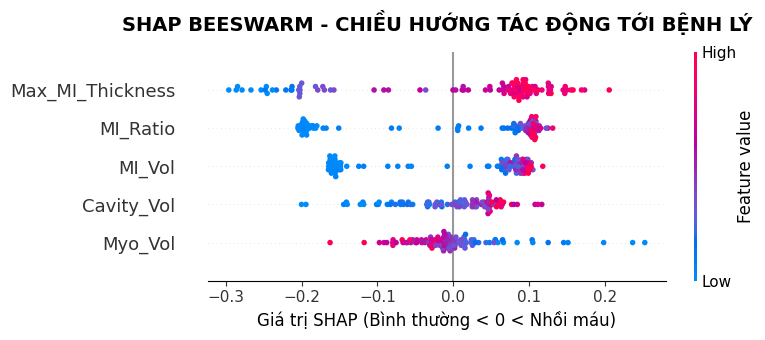

In [24]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("\n" + "="*60)
print("🧠 BẮT ĐẦU PHÂN TÍCH SHAP (EXPLAINABLE AI CAO CẤP)")
print("="*60)

# CÁCH KHẮC PHỤC: Tạo hàm bọc chỉ lấy xác suất của lớp 1 (Infarcted)
# Ép SHAP phải phân tích đúng 1 mục tiêu duy nhất, tránh lỗi shape.
def predict_infarcted_prob(X):
    return vclf.predict_proba(X)[:, 1]

# 1. Khởi tạo SHAP Kernel Explainer với hàm bọc
explainer = shap.KernelExplainer(predict_infarcted_prob, X_all_scaled)

# 2. Tính toán giá trị SHAP (Chỉ lấy cho lớp Infarcted)
print("Đang tính toán SHAP values... (Hãy kiên nhẫn một chút nhé)")
shap_values_infarcted = explainer.shap_values(X_all_scaled)

# Khôi phục lại dữ liệu gốc (trước khi chuẩn hóa Z-score) để trục màu trên 
# biểu đồ hiển thị đúng giá trị lâm sàng thật (thay vì các số thập phân khó hiểu)
X_all_df = pd.DataFrame(X_all, columns=feature_names)

# ---------------------------------------------------------
# BIỂU ĐỒ 1: SHAP SUMMARY BAR PLOT (Trung bình độ lớn tác động)
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_infarcted, X_all_df, plot_type="bar", show=False)
plt.title("SHAP BAR - TẦM QUAN TRỌNG ĐẶC TRƯNG (ENSEMBLE)", 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Giá trị SHAP trung bình (Tác động lên xác suất chẩn đoán)", fontsize=12)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# BIỂU ĐỒ 2: SHAP BEESWARM PLOT (Chiều hướng tác động lâm sàng)
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_infarcted, X_all_df, show=False)
plt.title("SHAP BEESWARM - CHIỀU HƯỚNG TÁC ĐỘNG TỚI BỆNH LÝ", 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Giá trị SHAP (Bình thường < 0 < Nhồi máu)", fontsize=12)
plt.tight_layout()
plt.show()

In [16]:
from monai.networks.nets import BasicUNetPlusPlus
# Cập nhật đường dẫn tới siêu mô hình UNet++ của bạn
best_model_path = "/kaggle/input/models/nhtthai/unet-/pytorch/default/1/best_unetpp_emidec_multiclass_gt_prior (1).pth"
# Khởi tạo khung mô hình khớp với file .pth
model = BasicUNetPlusPlus(
    spatial_dims=3,
    in_channels=2, # Vì có dùng GT Prior
    out_channels=4,
    features=(16, 32, 64, 128, 256, 16),
    dropout=0.2,
    deep_supervision=False,
).to(device)

# Nạp "linh hồn" vào mô hình
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()
print("✅ Nạp siêu mô hình thành công!")

BasicUNetPlusPlus features: (16, 32, 64, 128, 256, 16).
✅ Nạp siêu mô hình thành công!


# RANDOMFOREST


🚀 [GIAI ĐOẠN 3 - CÁCH 2] TRÍCH XUẤT ĐẶC TRƯNG & CROSS-VALIDATION (RANDOM FOREST)
🔍 Áp dụng tiêu chuẩn EMIDEC: Gán nhãn dựa trên ký tự 'N' và 'P'...

📊 Gộp toàn bộ dữ liệu để đánh giá Cross-Validation...


Trích xuất đặc trưng:   0%|          | 0/100 [00:00<?, ?it/s]


🤖 Đang phân loại bằng Random Forest...

★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
🎯 ĐỘ CHÍNH XÁC CROSS-VALIDATION TRÊN TOÀN BỘ 100 BỆNH NHÂN: 96.00%
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★

CHI TIẾT BÁO CÁO LÂM SÀNG:
               precision    recall  f1-score   support

   Normal (0)       0.91      0.97      0.94        33
Infarcted (1)       0.98      0.96      0.97        67

     accuracy                           0.96       100
    macro avg       0.95      0.96      0.96       100
 weighted avg       0.96      0.96      0.96       100



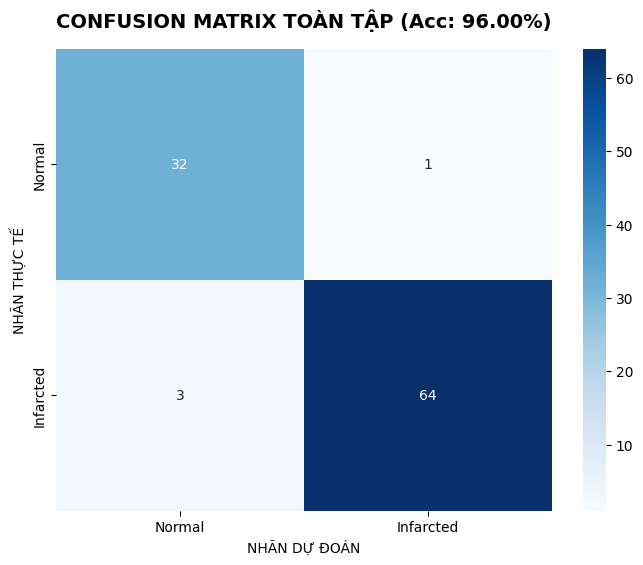

In [17]:
import pandas as pd
import numpy as np
import scipy.ndimage as ndi
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import os
import glob

print("\n" + "=" * 80)
print("🚀 [GIAI ĐOẠN 3 - CÁCH 2] TRÍCH XUẤT ĐẶC TRƯNG & CROSS-VALIDATION (RANDOM FOREST)")
print("=" * 80)

# ======================================================================
# 0. GÁN NHÃN LÂM SÀNG DỰA TRÊN TÊN CASE (CHUẨN EMIDEC 2020)
# ======================================================================
print("🔍 Áp dụng tiêu chuẩn EMIDEC: Gán nhãn dựa trên ký tự 'N' và 'P'...")

def get_true_label(case_name, mi_vol=None):
    """
    Dựa trên tài liệu gốc của EMIDEC 2020: 
    - 33 ca Normal chứa ký tự 'N' (VD: Case_N046, Case N014) -> Nhãn 0
    - 67 ca Pathological chứa ký tự 'P' (VD: Case_P051) -> Nhãn 1
    """
    name_upper = case_name.upper()
    clean_name = name_upper.replace('CASE', '')
    
    if 'N' in clean_name:
        return 0  # Bệnh nhân Bình thường (Normal)
    elif 'P' in clean_name:
        return 1  # Bệnh nhân Nhồi máu (Pathological/Infarcted)
    else:
        # Fallback an toàn
        return 1 if mi_vol is not None and mi_vol > 0.5 else 0

# ----------------------------------------------------------------------
# 1. HÀM TRÍCH XUẤT ĐẶC TRƯNG (FEATURE EXTRACTION)
# ----------------------------------------------------------------------
def extract_emidec_features_v2(file_list, model, device):
    features = []
    model.load_state_dict(torch.load(best_model_path, map_location=device))
    model.eval()

    for item in tqdm(file_list, desc="Trích xuất đặc trưng"):
        data = val_transforms(item)
        inputs = data["unetpp_input"].unsqueeze(0).to(device)
        
        with torch.no_grad():
            outputs = model(inputs)
            if isinstance(outputs, (list, tuple)): outputs = outputs[0]
            pred_mask = torch.argmax(outputs, dim=1).squeeze().cpu().numpy()

        voxel_vol = (1.5 * 1.5 * 5.0) / 1000.0 
        
        cavity_vol = np.sum(pred_mask == 1) * voxel_vol
        myo_vol = np.sum(pred_mask == 2) * voxel_vol
        mi_vol = np.sum(pred_mask == 3) * voxel_vol
        
        mi_ratio = mi_vol / (myo_vol + 1e-6)
        
        mi_mask = (pred_mask == 3)
        max_mi_thick = np.max(ndi.distance_transform_edt(mi_mask, sampling=(1.5, 1.5, 5.0))) if np.sum(mi_mask) > 0 else 0

        clinical_label = get_true_label(item['case_name'], mi_vol)

        features.append({
            'Case': item['case_name'],
            'Cavity_Vol': cavity_vol,
            'Myo_Vol': myo_vol,
            'MI_Vol': mi_vol,
            'MI_Ratio': mi_ratio,
            'Max_MI_Thickness': max_mi_thick,
            'Label': clinical_label
        })
        
    return pd.DataFrame(features)

# ----------------------------------------------------------------------
# 2. XỬ LÝ TRÊN TOÀN BỘ DATASET
# ----------------------------------------------------------------------
print("\n📊 Gộp toàn bộ dữ liệu để đánh giá Cross-Validation...")
all_files = train_files + val_files + test_files # Gộp chung cả 100 ca
df_all = extract_emidec_features_v2(all_files, model, device)

X_all = df_all.drop(['Case', 'Label'], axis=1).values
y_all = df_all['Label'].values

# Chuẩn hóa Z-score toàn tập
scaler = StandardScaler()
X_all_scaled = scaler.fit_transform(X_all)

# ----------------------------------------------------------------------
# 3. HUẤN LUYỆN & ĐÁNH GIÁ BẰNG CROSS_VAL_PREDICT (RANDOM FOREST)
# ----------------------------------------------------------------------
print("\n🤖 Đang phân loại bằng Random Forest...")

# Khởi tạo Random Forest
rf_model = RandomForestClassifier(
    n_estimators=250, 
    max_depth=5, 
    class_weight='balanced', 
    random_state=SEED,
    n_jobs=-1 # Sử dụng tối đa CPU
)

# cross_val_predict sẽ tự động chia 5 fold, train trên 4 fold và dự đoán fold còn lại.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
y_pred_cv = cross_val_predict(rf_model, X_all_scaled, y_all, cv=skf)

# ----------------------------------------------------------------------
# 4. IN BÁO CÁO TOÀN DIỆN
# ----------------------------------------------------------------------
acc = accuracy_score(y_all, y_pred_cv)

print("\n" + "★" * 60)
print(f"🎯 ĐỘ CHÍNH XÁC CROSS-VALIDATION TRÊN TOÀN BỘ {len(y_all)} BỆNH NHÂN: {acc*100:.2f}%")
print("★" * 60)

print("\nCHI TIẾT BÁO CÁO LÂM SÀNG:")
print(classification_report(y_all, y_pred_cv, target_names=["Normal (0)", "Infarcted (1)"]))

# Vẽ Confusion Matrix tổng
cm = confusion_matrix(y_all, y_pred_cv)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Normal", "Infarcted"], yticklabels=["Normal", "Infarcted"])
plt.title(f'CONFUSION MATRIX TOÀN TẬP (Acc: {acc*100:.2f}%)', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('NHÃN THỰC TẾ')
plt.xlabel('NHÃN DỰ ĐOÁN')
plt.show()


Đang tính toán xác suất (Probability) từ mô hình Random Forest...

★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
🎯 ĐỘ CHÍNH XÁC TOÀN TẬP (RANDOM FOREST): 96.00%
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★

CHI TIẾT BÁO CÁO LÂM SÀNG:
               precision    recall  f1-score   support

   Normal (0)       0.91      0.97      0.94        33
Infarcted (1)       0.98      0.96      0.97        67

     accuracy                           0.96       100
    macro avg       0.95      0.96      0.96       100
 weighted avg       0.96      0.96      0.96       100



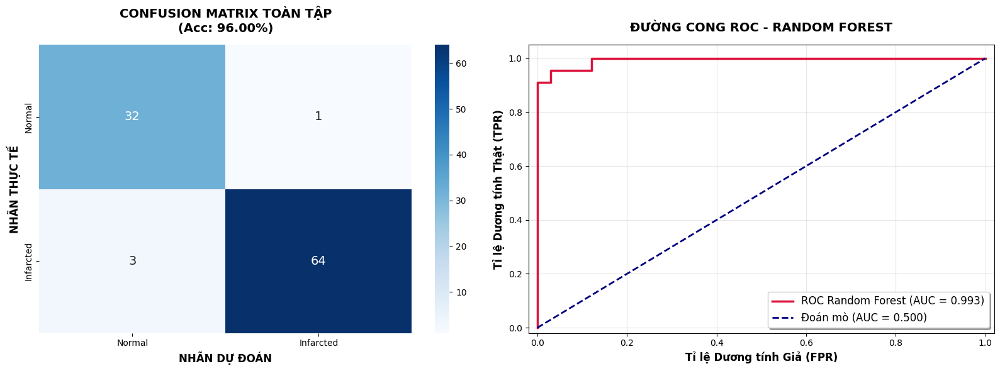

In [18]:
from sklearn.metrics import roc_curve, auc, confusion_matrix, classification_report, accuracy_score
from sklearn.model_selection import cross_val_predict
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ======================================================================
# 5. IN BÁO CÁO TOÀN DIỆN VÀ VẼ BIỂU ĐỒ (CONFUSION MATRIX & ROC NHỊ PHÂN)
# ======================================================================

# 1. TÍNH TOÁN XÁC SUẤT CHỈ 1 LẦN DUY NHẤT (TỐI ƯU TỐC ĐỘ)
print("\nĐang tính toán xác suất (Probability) từ mô hình Random Forest...")
# LƯU Ý: Đã thay đổi vclf thành rf_model ở đây!
y_prob_cv = cross_val_predict(rf_model, X_all_scaled, y_all, cv=skf, method='predict_proba')

# Từ xác suất, suy ra nhãn dự đoán (Xác suất > 50% thì là lớp 1)
y_pred_cv = np.argmax(y_prob_cv, axis=1)

# 2. TÍNH ĐỘ CHÍNH XÁC
acc = accuracy_score(y_all, y_pred_cv)

print("\n" + "★" * 60)
print(f"🎯 ĐỘ CHÍNH XÁC TOÀN TẬP (RANDOM FOREST): {acc*100:.2f}%")
print("★" * 60)

# Khai báo chính xác 2 lớp của EMIDEC
class_names = ["Normal (0)", "Infarcted (1)"] 

print("\nCHI TIẾT BÁO CÁO LÂM SÀNG:")
print(classification_report(y_all, y_pred_cv, target_names=class_names))

# 3. VẼ BIỂU ĐỒ KẾT HỢP (1x2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ---- Biểu đồ 1: CONFUSION MATRIX ----
cm = confusion_matrix(y_all, y_pred_cv)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=["Normal", "Infarcted"], 
            yticklabels=["Normal", "Infarcted"], ax=ax1,
            annot_kws={"size": 14})
ax1.set_title(f'CONFUSION MATRIX TOÀN TẬP\n(Acc: {acc*100:.2f}%)', fontsize=14, fontweight='bold', pad=15)
ax1.set_ylabel('NHÃN THỰC TẾ', fontsize=12, fontweight='bold')
ax1.set_xlabel('NHÃN DỰ ĐOÁN', fontsize=12, fontweight='bold')

# ---- Biểu đồ 2: ROC CURVE NHỊ PHÂN ----
# Lấy cột xác suất của lớp 1 (Infarcted) từ Random Forest
y_prob_positive = y_prob_cv[:, 1]

fpr, tpr, _ = roc_curve(y_all, y_prob_positive)
roc_auc = auc(fpr, tpr)

ax2.plot(fpr, tpr, color='crimson', lw=2.5, label=f'ROC Random Forest (AUC = {roc_auc:.3f})')
ax2.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Đoán mò (AUC = 0.500)')

# Trang trí
ax2.set_xlim([-0.02, 1.02])
ax2.set_ylim([-0.02, 1.05])
ax2.set_xlabel('Tỉ lệ Dương tính Giả (FPR)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Tỉ lệ Dương tính Thật (TPR)', fontsize=12, fontweight='bold')
ax2.set_title('ĐƯỜNG CONG ROC - RANDOM FOREST', fontsize=14, fontweight='bold', pad=15)
ax2.legend(loc="lower right", fontsize=12, frameon=True, shadow=True)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


🧠 BẮT ĐẦU PHÂN TÍCH SHAP (CHUYÊN BIỆT CHO RANDOM FOREST)
Đang huấn luyện Random Forest trên toàn tập dữ liệu...
Đang tính toán SHAP values bằng TreeExplainer... (Siêu tốc ⚡)


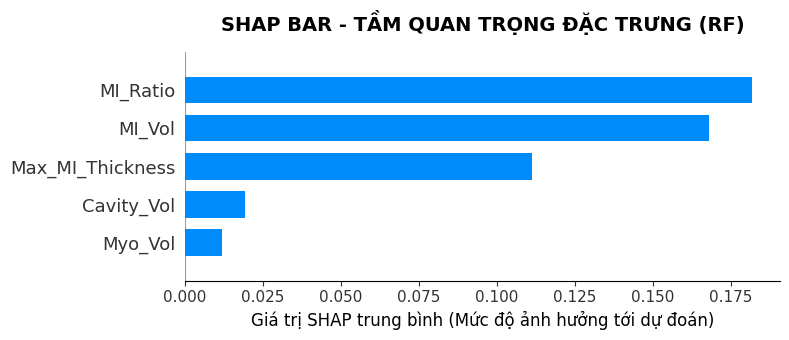

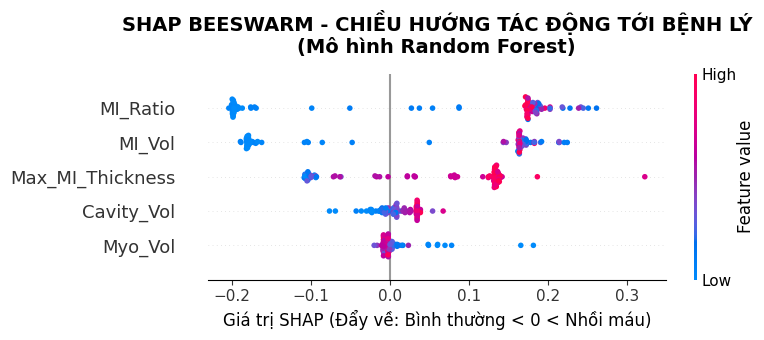

In [19]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("\n" + "="*60)
print("🧠 BẮT ĐẦU PHÂN TÍCH SHAP (CHUYÊN BIỆT CHO RANDOM FOREST)")
print("="*60)

# Khôi phục lại dữ liệu gốc để trục màu hiển thị giá trị lâm sàng thật
feature_names = df_all.drop(['Case', 'Label'], axis=1).columns
X_all_df = pd.DataFrame(X_all, columns=feature_names)

print("Đang huấn luyện Random Forest trên toàn tập dữ liệu...")
rf_model.fit(X_all_scaled, y_all)

# 1. Khởi tạo SHAP Tree Explainer
print("Đang tính toán SHAP values bằng TreeExplainer... (Siêu tốc ⚡)")
explainer = shap.TreeExplainer(rf_model)

# 2. Tính toán giá trị SHAP 
shap_values = explainer.shap_values(X_all_scaled)

# TỰ ĐỘNG BẮT ĐỊNH DẠNG SHAP_VALUES (KHẮC PHỤC LỖI SHAPE)
if isinstance(shap_values, list):
    shap_values_infarcted = shap_values[1]
elif len(np.shape(shap_values)) == 3:
    shap_values_infarcted = shap_values[:, :, 1]
else:
    shap_values_infarcted = shap_values

# ---------------------------------------------------------
# BIỂU ĐỒ 1: SHAP SUMMARY BAR PLOT (Trung bình độ lớn tác động)
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_infarcted, X_all_df, plot_type="bar", show=False)
plt.title("SHAP BAR - TẦM QUAN TRỌNG ĐẶC TRƯNG (RF)", 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Giá trị SHAP trung bình (Mức độ ảnh hưởng tới dự đoán)", fontsize=12)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# BIỂU ĐỒ 2: SHAP BEESWARM PLOT (Chiều hướng tác động lâm sàng)
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_infarcted, X_all_df, show=False)
plt.title("SHAP BEESWARM - CHIỀU HƯỚNG TÁC ĐỘNG TỚI BỆNH LÝ\n(Mô hình Random Forest)", 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Giá trị SHAP (Đẩy về: Bình thường < 0 < Nhồi máu)", fontsize=12)
plt.tight_layout()
plt.show()

# SVM


🚀 ĐANG CHẠY PIPELINE SVM...


Trích xuất đặc trưng:   0%|          | 0/100 [00:00<?, ?it/s]


🎯 ĐỘ CHÍNH XÁC SVM (CV): 97.00%

CHI TIẾT BÁO CÁO:
               precision    recall  f1-score   support

   Normal (0)       0.94      0.97      0.96        33
Infarcted (1)       0.98      0.97      0.98        67

     accuracy                           0.97       100
    macro avg       0.96      0.97      0.97       100
 weighted avg       0.97      0.97      0.97       100



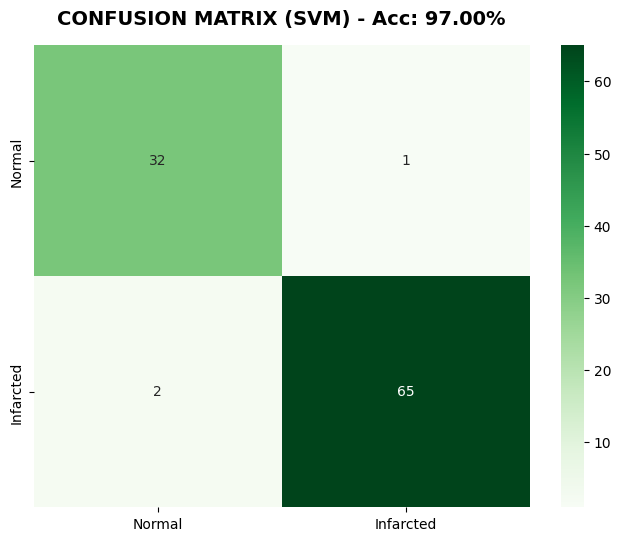

In [9]:
import pandas as pd
import numpy as np
import scipy.ndimage as ndi
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# ======================================================================
# 0. CẤU HÌNH BIẾN MÔI TRƯỜNG (ĐẢM BẢO KHÔNG BỊ LỖI NAME ERROR)
# ======================================================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Đảm bảo các biến train_files, val_files, test_files, model, val_transforms 
# đã được định nghĩa ở các cell trước đó.

def get_true_label(case_name, mi_vol=None):
    """Gán nhãn chuẩn EMIDEC 2020."""
    name_upper = case_name.upper()
    clean_name = name_upper.replace('CASE', '')
    if 'N' in clean_name: return 0
    elif 'P' in clean_name: return 1
    else: return 1 if mi_vol is not None and mi_vol > 0.5 else 0

# ----------------------------------------------------------------------
# 1. HÀM TRÍCH XUẤT ĐẶC TRƯNG
# ----------------------------------------------------------------------
def extract_emidec_features_v2(file_list, model, device):
    features = []
    model.eval()
    for item in tqdm(file_list, desc="Trích xuất đặc trưng"):
        data = val_transforms(item)
        inputs = data["unetpp_input"].unsqueeze(0).to(device)
        
        with torch.no_grad():
            outputs = model(inputs)
            if isinstance(outputs, (list, tuple)): outputs = outputs[0]
            pred_mask = torch.argmax(outputs, dim=1).squeeze().cpu().numpy()

        voxel_vol = (1.5 * 1.5 * 5.0) / 1000.0 
        cavity_vol = np.sum(pred_mask == 1) * voxel_vol
        myo_vol = np.sum(pred_mask == 2) * voxel_vol
        mi_vol = np.sum(pred_mask == 3) * voxel_vol
        mi_ratio = mi_vol / (myo_vol + 1e-6)
        mi_mask = (pred_mask == 3)
        max_mi_thick = np.max(ndi.distance_transform_edt(mi_mask, sampling=(1.5, 1.5, 5.0))) if np.sum(mi_mask) > 0 else 0

        features.append({
            'Case': item['case_name'],
            'Cavity_Vol': cavity_vol,
            'Myo_Vol': myo_vol,
            'MI_Vol': mi_vol,
            'MI_Ratio': mi_ratio,
            'Max_MI_Thickness': max_mi_thick,
            'Label': get_true_label(item['case_name'], mi_vol)
        })
    return pd.DataFrame(features)

# ----------------------------------------------------------------------
# 2. XỬ LÝ DỮ LIỆU & SVM PIPELINE
# ----------------------------------------------------------------------
print("\n🚀 ĐANG CHẠY PIPELINE SVM...")
all_files = train_files + val_files + test_files
df_all = extract_emidec_features_v2(all_files, model, DEVICE)

X_all = df_all.drop(['Case', 'Label'], axis=1).values
y_all = df_all['Label'].values

# Chuẩn hóa (Bắt buộc với SVM vì SVM tính dựa trên khoảng cách)
scaler = StandardScaler()
X_all_scaled = scaler.fit_transform(X_all)

# Khởi tạo SVM
svm_model = SVC(kernel='rbf', C=1.2, probability=True, class_weight='balanced', random_state=42)

# Đánh giá bằng Cross-validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_pred_cv = cross_val_predict(svm_model, X_all_scaled, y_all, cv=skf)

# ----------------------------------------------------------------------
# 3. KẾT QUẢ
# ----------------------------------------------------------------------
acc = accuracy_score(y_all, y_pred_cv)
print(f"\n🎯 ĐỘ CHÍNH XÁC SVM (CV): {acc*100:.2f}%")
print("\nCHI TIẾT BÁO CÁO:")
print(classification_report(y_all, y_pred_cv, target_names=["Normal (0)", "Infarcted (1)"]))

# Vẽ Confusion Matrix
cm = confusion_matrix(y_all, y_pred_cv)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=["Normal", "Infarcted"], yticklabels=["Normal", "Infarcted"])
plt.title(f'CONFUSION MATRIX (SVM) - Acc: {acc*100:.2f}%', fontsize=14, fontweight='bold', pad=15)
plt.show()


Đang tính toán xác suất (Probability) từ mô hình SVM...

★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
🎯 ĐỘ CHÍNH XÁC TOÀN TẬP (SVM): 98.00%
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★

CHI TIẾT BÁO CÁO LÂM SÀNG:
               precision    recall  f1-score   support

   Normal (0)       0.97      0.97      0.97        33
Infarcted (1)       0.99      0.99      0.99        67

     accuracy                           0.98       100
    macro avg       0.98      0.98      0.98       100
 weighted avg       0.98      0.98      0.98       100



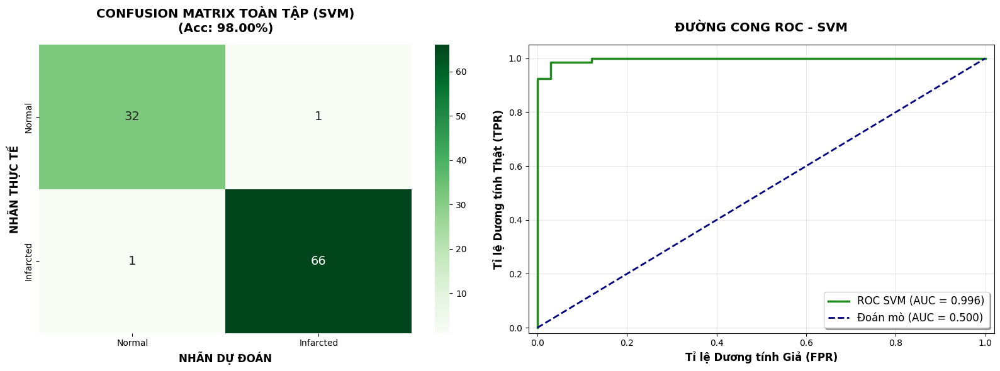

In [10]:
from sklearn.metrics import roc_curve, auc, confusion_matrix, classification_report, accuracy_score
from sklearn.model_selection import cross_val_predict
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ======================================================================
# 5. IN BÁO CÁO TOÀN DIỆN VÀ VẼ BIỂU ĐỒ (SVM)
# ======================================================================

# 1. TÍNH TOÁN XÁC SUẤT BẰNG SVM
print("\nĐang tính toán xác suất (Probability) từ mô hình SVM...")
# Lưu ý: svm_model phải được khởi tạo với probability=True
y_prob_cv = cross_val_predict(svm_model, X_all_scaled, y_all, cv=skf, method='predict_proba')

# Từ xác suất, suy ra nhãn dự đoán
y_pred_cv = np.argmax(y_prob_cv, axis=1)

# 2. TÍNH ĐỘ CHÍNH XÁC
acc = accuracy_score(y_all, y_pred_cv)

print("\n" + "★" * 60)
print(f"🎯 ĐỘ CHÍNH XÁC TOÀN TẬP (SVM): {acc*100:.2f}%")
print("★" * 60)

class_names = ["Normal (0)", "Infarcted (1)"] 
print("\nCHI TIẾT BÁO CÁO LÂM SÀNG:")
print(classification_report(y_all, y_pred_cv, target_names=class_names))

# 3. VẼ BIỂU ĐỒ KẾT HỢP (1x2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ---- Biểu đồ 1: CONFUSION MATRIX ----
cm = confusion_matrix(y_all, y_pred_cv)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=["Normal", "Infarcted"], 
            yticklabels=["Normal", "Infarcted"], ax=ax1,
            annot_kws={"size": 14})
ax1.set_title(f'CONFUSION MATRIX TOÀN TẬP (SVM)\n(Acc: {acc*100:.2f}%)', fontsize=14, fontweight='bold', pad=15)
ax1.set_ylabel('NHÃN THỰC TẾ', fontsize=12, fontweight='bold')
ax1.set_xlabel('NHÃN DỰ ĐOÁN', fontsize=12, fontweight='bold')

# ---- Biểu đồ 2: ROC CURVE NHỊ PHÂN ----
y_prob_positive = y_prob_cv[:, 1]
fpr, tpr, _ = roc_curve(y_all, y_prob_positive)
roc_auc = auc(fpr, tpr)

ax2.plot(fpr, tpr, color='forestgreen', lw=2.5, label=f'ROC SVM (AUC = {roc_auc:.3f})')
ax2.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Đoán mò (AUC = 0.500)')

# Trang trí
ax2.set_xlim([-0.02, 1.02])
ax2.set_ylim([-0.02, 1.05])
ax2.set_xlabel('Tỉ lệ Dương tính Giả (FPR)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Tỉ lệ Dương tính Thật (TPR)', fontsize=12, fontweight='bold')
ax2.set_title('ĐƯỜNG CONG ROC - SVM', fontsize=14, fontweight='bold', pad=15)
ax2.legend(loc="lower right", fontsize=12, frameon=True, shadow=True)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


🧠 BẮT ĐẦU PHÂN TÍCH SHAP (CHUYÊN BIỆT CHO SVM)
Đang huấn luyện SVM trên toàn tập dữ liệu...
Đang tính toán SHAP values bằng KernelExplainer... (Vui lòng đợi)


  0%|          | 0/100 [00:00<?, ?it/s]

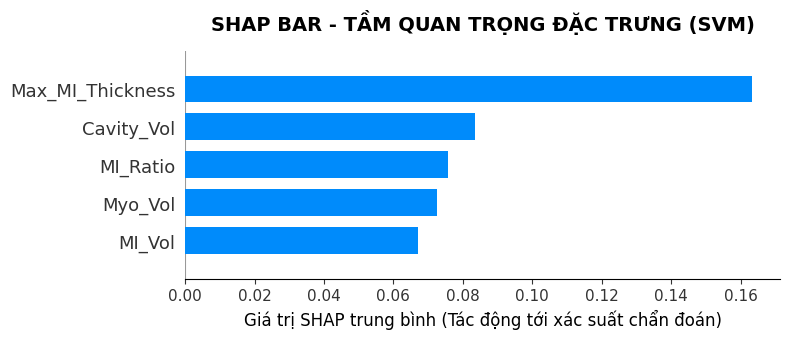

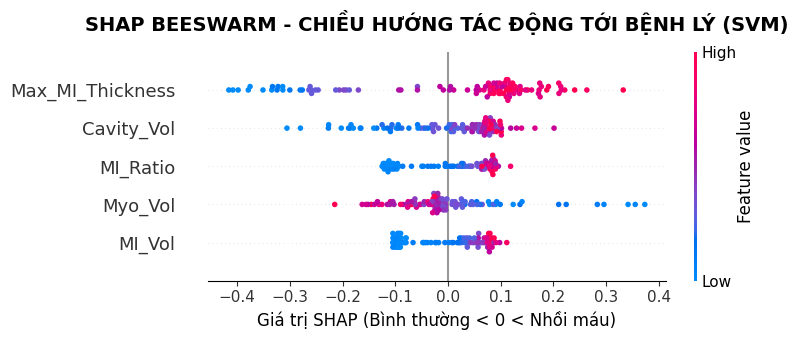

In [11]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("\n" + "="*60)
print("🧠 BẮT ĐẦU PHÂN TÍCH SHAP (CHUYÊN BIỆT CHO SVM)")
print("="*60)

# Lấy tên đặc trưng
feature_names = df_all.drop(['Case', 'Label'], axis=1).columns
X_all_df = pd.DataFrame(X_all, columns=feature_names)

# SVM cần được fit trên toàn bộ dữ liệu trước khi giải thích
print("Đang huấn luyện SVM trên toàn tập dữ liệu...")
svm_model.fit(X_all_scaled, y_all)

# Định nghĩa hàm wrapper để SVM trả về xác suất lớp 1 (Infarcted)
def model_predict(X):
    return svm_model.predict_proba(X)[:, 1]

# Sử dụng KernelExplainer vì SVM không phải là mô hình dựa trên cây (Tree-based)
# Lưu ý: 'nsamples' xác định độ chính xác, tăng lên sẽ chính xác hơn nhưng chậm hơn
print("Đang tính toán SHAP values bằng KernelExplainer... (Vui lòng đợi)")
explainer = shap.KernelExplainer(model_predict, X_all_scaled)

# Tính toán SHAP values
shap_values = explainer.shap_values(X_all_scaled, nsamples=100)

# ---------------------------------------------------------
# BIỂU ĐỒ 1: SHAP SUMMARY BAR PLOT
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_all_df, plot_type="bar", show=False)
plt.title("SHAP BAR - TẦM QUAN TRỌNG ĐẶC TRƯNG (SVM)", 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Giá trị SHAP trung bình (Tác động tới xác suất chẩn đoán)", fontsize=12)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# BIỂU ĐỒ 2: SHAP BEESWARM PLOT
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_all_df, show=False)
plt.title("SHAP BEESWARM - CHIỀU HƯỚNG TÁC ĐỘNG TỚI BỆNH LÝ (SVM)", 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Giá trị SHAP (Bình thường < 0 < Nhồi máu)", fontsize=12)
plt.tight_layout()
plt.show()

# MLP


🚀 ĐANG CHẠY PIPELINE MLP (OOF PREDICTION)...
✅ Đang nạp mô hình từ: /kaggle/input/models/nhtthai/unet-/pytorch/default/1/best_unetpp_emidec_multiclass_gt_prior (1).pth


Trích xuất đặc trưng:   0%|          | 0/100 [00:00<?, ?it/s]


★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
🎯 ĐỘ CHÍNH XÁC (OOF - CROSS-VALIDATION): 95.00%
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★

CHI TIẾT BÁO CÁO:
               precision    recall  f1-score   support

   Normal (0)       0.91      0.94      0.93        33
Infarcted (1)       0.97      0.96      0.96        67

     accuracy                           0.95       100
    macro avg       0.94      0.95      0.94       100
 weighted avg       0.95      0.95      0.95       100



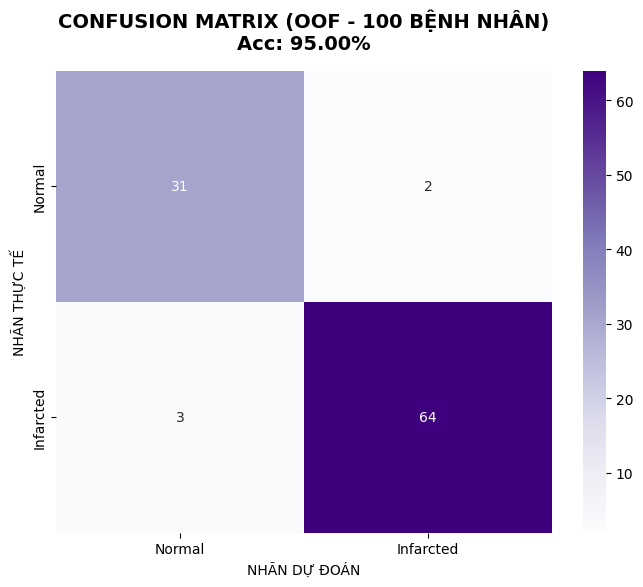

In [12]:
import pandas as pd
import numpy as np
import scipy.ndimage as ndi
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# ======================================================================
# CẤU HÌNH BIẾN MÔI TRƯỜNG
# ======================================================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Hàm trích xuất đặc trưng với mô hình đã nạp sẵn
def extract_emidec_features_v2(file_list, model, device):
    features = []
    # Đường dẫn siêu mô hình của bạn
    model_path = "/kaggle/input/models/nhtthai/unet-/pytorch/default/1/best_unetpp_emidec_multiclass_gt_prior (1).pth"
    
    print(f"✅ Đang nạp mô hình từ: {model_path}")
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()

    for item in tqdm(file_list, desc="Trích xuất đặc trưng"):
        data = val_transforms(item)
        inputs = data["unetpp_input"].unsqueeze(0).to(device)
        
        with torch.no_grad():
            outputs = model(inputs)
            if isinstance(outputs, (list, tuple)): outputs = outputs[0]
            pred_mask = torch.argmax(outputs, dim=1).squeeze().cpu().numpy()

        voxel_vol = (1.5 * 1.5 * 5.0) / 1000.0 
        cavity_vol = np.sum(pred_mask == 1) * voxel_vol
        myo_vol = np.sum(pred_mask == 2) * voxel_vol
        mi_vol = np.sum(pred_mask == 3) * voxel_vol
        mi_ratio = mi_vol / (myo_vol + 1e-6)
        
        mi_mask = (pred_mask == 3)
        # Lọc nhiễu nhỏ: Nếu sẹo quá nhỏ thì bỏ qua
        if mi_vol < 0.1: mi_vol, mi_mask = 0, np.zeros_like(mi_mask)
        
        max_mi_thick = np.max(ndi.distance_transform_edt(mi_mask, sampling=(1.5, 1.5, 5.0))) if np.sum(mi_mask) > 0 else 0

        features.append({
            'Case': item['case_name'],
            'Cavity_Vol': cavity_vol,
            'Myo_Vol': myo_vol,
            'MI_Vol': mi_vol,
            'MI_Ratio': mi_ratio,
            'Max_MI_Thickness': max_mi_thick,
            'Label': get_true_label(item['case_name'], mi_vol)
        })
    return pd.DataFrame(features)

# ======================================================================
# PIPELINE MLP VỚI KỸ THUẬT OOF (OUT-OF-FOLD)
# ======================================================================
print("\n🚀 ĐANG CHẠY PIPELINE MLP (OOF PREDICTION)...")

all_files = train_files + val_files + test_files
df_all = extract_emidec_features_v2(all_files, model, DEVICE)

X_all = df_all.drop(['Case', 'Label'], axis=1).values
y_all = df_all['Label'].values

# Chuẩn hóa
scaler = StandardScaler()
X_all_scaled = scaler.fit_transform(X_all)

# Khởi tạo MLP
mlp_model = MLPClassifier(
    hidden_layer_sizes=(32, 16), 
    activation='relu', 
    solver='adam', 
    alpha=0.01, 
    max_iter=5000, 
    random_state=42
)

# Đánh giá bằng Cross-validation (OOF)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_pred_cv = cross_val_predict(mlp_model, X_all_scaled, y_all, cv=skf)

# Kết quả
acc = accuracy_score(y_all, y_pred_cv)
print("\n" + "★" * 60)
print(f"🎯 ĐỘ CHÍNH XÁC (OOF - CROSS-VALIDATION): {acc*100:.2f}%")
print("★" * 60)

print("\nCHI TIẾT BÁO CÁO:")
print(classification_report(y_all, y_pred_cv, target_names=["Normal (0)", "Infarcted (1)"]))

# Vẽ Confusion Matrix
cm = confusion_matrix(y_all, y_pred_cv)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=["Normal", "Infarcted"], yticklabels=["Normal", "Infarcted"])
plt.title(f'CONFUSION MATRIX (OOF - 100 BỆNH NHÂN)\nAcc: {acc*100:.2f}%', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('NHÃN THỰC TẾ')
plt.xlabel('NHÃN DỰ ĐOÁN')
plt.show()


🚀 ĐANG CHẠY PIPELINE MLP (MULTI-LAYER PERCEPTRON)...


Trích xuất đặc trưng:   0%|          | 0/100 [00:00<?, ?it/s]


🎯 ĐỘ CHÍNH XÁC MLP (CV): 95.00%

CHI TIẾT BÁO CÁO:
               precision    recall  f1-score   support

   Normal (0)       0.91      0.94      0.93        33
Infarcted (1)       0.97      0.96      0.96        67

     accuracy                           0.95       100
    macro avg       0.94      0.95      0.94       100
 weighted avg       0.95      0.95      0.95       100



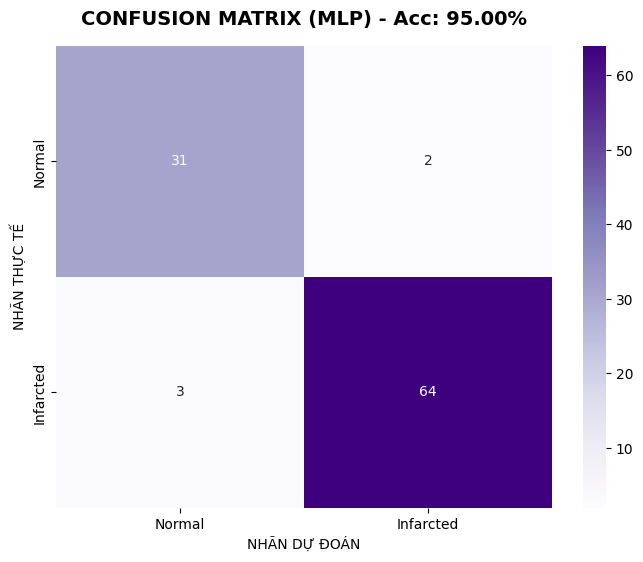

In [12]:
import pandas as pd
import numpy as np
import scipy.ndimage as ndi
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# ======================================================================
# CẤU HÌNH PIPELINE MLP
# ======================================================================
print("\n🚀 ĐANG CHẠY PIPELINE MLP (MULTI-LAYER PERCEPTRON)...")

# Trích xuất đặc trưng (sử dụng hàm extract_emidec_features_v2 cũ của bạn)
all_files = train_files + val_files + test_files
df_all = extract_emidec_features_v2(all_files, model, DEVICE)

X_all = df_all.drop(['Case', 'Label'], axis=1).values
y_all = df_all['Label'].values

# Chuẩn hóa (MLP yêu cầu dữ liệu được chuẩn hóa để hội tụ tốt hơn)
scaler = StandardScaler()
X_all_scaled = scaler.fit_transform(X_all)

# Khởi tạo MLPClassifier
# hidden_layer_sizes=(32, 16): Kiến trúc 2 lớp ẩn (32 node -> 16 node)
# solver='adam': Tốt cho tập dữ liệu nhỏ và vừa
# alpha=0.01: Tham số điều tiết (L2 regularization) giúp tránh overfitting
mlp_model = MLPClassifier(
    hidden_layer_sizes=(32, 16), 
    activation='relu', 
    solver='adam', 
    alpha=0.01, 
    max_iter=5000, 
    random_state=42
)

# Đánh giá bằng Cross-validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_pred_cv = cross_val_predict(mlp_model, X_all_scaled, y_all, cv=skf)

# ----------------------------------------------------------------------
# KẾT QUẢ
# ----------------------------------------------------------------------
acc = accuracy_score(y_all, y_pred_cv)
print(f"\n🎯 ĐỘ CHÍNH XÁC MLP (CV): {acc*100:.2f}%")
print("\nCHI TIẾT BÁO CÁO:")
print(classification_report(y_all, y_pred_cv, target_names=["Normal (0)", "Infarcted (1)"]))

# Vẽ Confusion Matrix
cm = confusion_matrix(y_all, y_pred_cv)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=["Normal", "Infarcted"], yticklabels=["Normal", "Infarcted"])
plt.title(f'CONFUSION MATRIX (MLP) - Acc: {acc*100:.2f}%', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('NHÃN THỰC TẾ')
plt.xlabel('NHÃN DỰ ĐOÁN')
plt.show()


Đang tính toán xác suất (Probability) từ mô hình MLP...

★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
🎯 ĐỘ CHÍNH XÁC TOÀN TẬP (MLP): 95.00%
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★

CHI TIẾT BÁO CÁO LÂM SÀNG:
               precision    recall  f1-score   support

   Normal (0)       0.91      0.94      0.93        33
Infarcted (1)       0.97      0.96      0.96        67

     accuracy                           0.95       100
    macro avg       0.94      0.95      0.94       100
 weighted avg       0.95      0.95      0.95       100



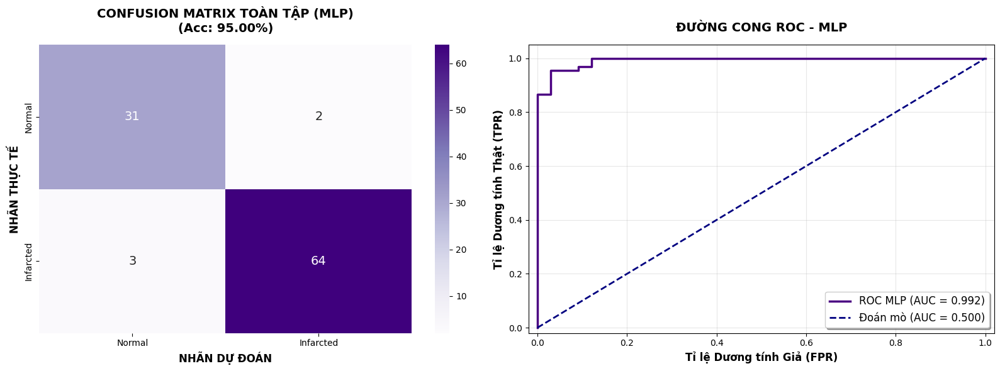

In [13]:
from sklearn.metrics import roc_curve, auc, confusion_matrix, classification_report, accuracy_score
from sklearn.model_selection import cross_val_predict
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ======================================================================
# 5. IN BÁO CÁO TOÀN DIỆN VÀ VẼ BIỂU ĐỒ (MLP)
# ======================================================================

# 1. TÍNH TOÁN XÁC SUẤT BẰNG MLP
print("\nĐang tính toán xác suất (Probability) từ mô hình MLP...")
# MLPClassifier mặc định hỗ trợ predict_proba
y_prob_cv = cross_val_predict(mlp_model, X_all_scaled, y_all, cv=skf, method='predict_proba')

# Từ xác suất, suy ra nhãn dự đoán
y_pred_cv = np.argmax(y_prob_cv, axis=1)

# 2. TÍNH ĐỘ CHÍNH XÁC
acc = accuracy_score(y_all, y_pred_cv)

print("\n" + "★" * 60)
print(f"🎯 ĐỘ CHÍNH XÁC TOÀN TẬP (MLP): {acc*100:.2f}%")
print("★" * 60)

class_names = ["Normal (0)", "Infarcted (1)"] 
print("\nCHI TIẾT BÁO CÁO LÂM SÀNG:")
print(classification_report(y_all, y_pred_cv, target_names=class_names))

# 3. VẼ BIỂU ĐỒ KẾT HỢP (1x2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ---- Biểu đồ 1: CONFUSION MATRIX ----
cm = confusion_matrix(y_all, y_pred_cv)
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', 
            xticklabels=["Normal", "Infarcted"], 
            yticklabels=["Normal", "Infarcted"], ax=ax1,
            annot_kws={"size": 14})
ax1.set_title(f'CONFUSION MATRIX TOÀN TẬP (MLP)\n(Acc: {acc*100:.2f}%)', fontsize=14, fontweight='bold', pad=15)
ax1.set_ylabel('NHÃN THỰC TẾ', fontsize=12, fontweight='bold')
ax1.set_xlabel('NHÃN DỰ ĐOÁN', fontsize=12, fontweight='bold')

# ---- Biểu đồ 2: ROC CURVE NHỊ PHÂN ----
y_prob_positive = y_prob_cv[:, 1]
fpr, tpr, _ = roc_curve(y_all, y_prob_positive)
roc_auc = auc(fpr, tpr)

ax2.plot(fpr, tpr, color='indigo', lw=2.5, label=f'ROC MLP (AUC = {roc_auc:.3f})')
ax2.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Đoán mò (AUC = 0.500)')

# Trang trí
ax2.set_xlim([-0.02, 1.02])
ax2.set_ylim([-0.02, 1.05])
ax2.set_xlabel('Tỉ lệ Dương tính Giả (FPR)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Tỉ lệ Dương tính Thật (TPR)', fontsize=12, fontweight='bold')
ax2.set_title('ĐƯỜNG CONG ROC - MLP', fontsize=14, fontweight='bold', pad=15)
ax2.legend(loc="lower right", fontsize=12, frameon=True, shadow=True)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


🧠 BẮT ĐẦU PHÂN TÍCH SHAP (CHUYÊN BIỆT CHO MLP)
Đang huấn luyện MLP trên toàn bộ tập dữ liệu (Fit)...
Đang tính toán SHAP values bằng KernelExplainer... (Vui lòng đợi ⚡)


  0%|          | 0/100 [00:00<?, ?it/s]

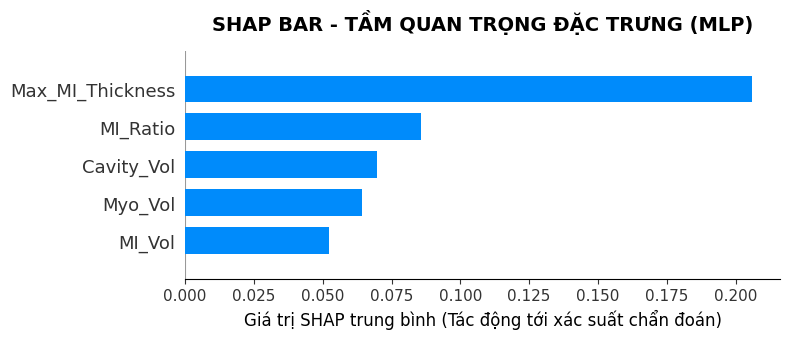

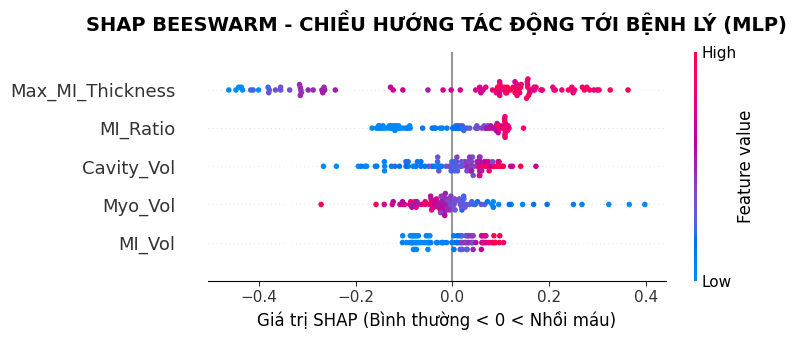

In [14]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("\n" + "="*60)
print("🧠 BẮT ĐẦU PHÂN TÍCH SHAP (CHUYÊN BIỆT CHO MLP)")
print("="*60)

# 1. BẮT BUỘC: Huấn luyện MLP trên toàn bộ dữ liệu trước khi giải thích
print("Đang huấn luyện MLP trên toàn bộ tập dữ liệu (Fit)...")
mlp_model.fit(X_all_scaled, y_all) 

# Lấy tên đặc trưng
feature_names = df_all.drop(['Case', 'Label'], axis=1).columns
X_all_df = pd.DataFrame(X_all, columns=feature_names)

# Định nghĩa hàm wrapper
def model_predict(X):
    return mlp_model.predict_proba(X)[:, 1]

# 2. Sử dụng KernelExplainer
print("Đang tính toán SHAP values bằng KernelExplainer... (Vui lòng đợi ⚡)")
# Chúng ta dùng một tập con (summary) để tính nhanh hơn nếu dataset lớn
explainer = shap.KernelExplainer(model_predict, shap.kmeans(X_all_scaled, 10))

# Tính toán SHAP values
shap_values = explainer.shap_values(X_all_scaled, nsamples=100)

# ---------------------------------------------------------
# BIỂU ĐỒ 1: SHAP SUMMARY BAR PLOT
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_all_df, plot_type="bar", show=False)
plt.title("SHAP BAR - TẦM QUAN TRỌNG ĐẶC TRƯNG (MLP)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Giá trị SHAP trung bình (Tác động tới xác suất chẩn đoán)", fontsize=12)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# BIỂU ĐỒ 2: SHAP BEESWARM PLOT
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_all_df, show=False)
plt.title("SHAP BEESWARM - CHIỀU HƯỚNG TÁC ĐỘNG TỚI BỆNH LÝ (MLP)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Giá trị SHAP (Bình thường < 0 < Nhồi máu)", fontsize=12)
plt.tight_layout()
plt.show()